In [1]:
import multiprocessing

# 1. FORCER LA MÉTHODE SPAWN TOUT DE SUITE (avant tout usage de process)
try:
    multiprocessing.set_start_method('spawn', force=True)
except RuntimeError:
    pass


import pubchempy as pcp
import os 
import pandas as pd
import requests 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from ase.io import write, read
import pyscf
from IPython import display
from xyzrender import load, render, render_gif,orient
from pyscf.tools import cubegen
import time
import re
from pyscf.geomopt.geometric_solver import optimize
from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_3d = True
import py3Dmol
from rdkit.Chem import rdDepictor
from rdkit.Chem import rdDistGeom
import rdkit
print(rdkit.__version__)
from rdkit.Chem import AllChem
from strainedsmiles2xyz import smiles_to_xyz
from typing import Any




Bad key mathtext.sans in file /home/lilianheydel/.config/matplotlib/matplotlibrc, line 5 ('mathtext.sans : Helvetica ')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.11.2/lib/matplotlib/mpl-data/matplotlibrc
or from the matplotlib source distribution


2026.09.1


In [2]:
symb_benett = ['Al', 'Si', 'P', 'S', 'Cl', 'Ar']  # J'ai corrigé le doublon 'Si' en 'S'
benett_dict_basis = {}
benett_dict_ecp = {}

for s in symb_benett:
    benett_dict_basis[s] = pyscf.gto.basis.parse_nwchem.load(f"../../Data/Quantum_Basis/{s}/{s}.aug-cc-pVTZ.nwchem", s, optimize=True)
    with open(f"../../Data/Quantum_Basis/{s}/{s}.ccECP.nwchem", 'r') as f:
        lines = f.readlines()
    if not any('ECP' in line for line in lines[:3]): lines.insert(0, "ECP\n")
    if not any('END' in line for line in lines[-3:]): lines.append("END\n")
    benett_dict_ecp[s] = pyscf.gto.basis.parse_ecp("".join(lines))

symb_wang= ['Ge', 'As', 'Se', 'Br']
wang_dict_basis = {}
wang_dict_ecp = {}

for s in symb_wang:
    wang_dict_basis[s] = pyscf.gto.basis.parse_nwchem.load(f"../../Data/Quantum_Basis/{s}/{s}.aug-cc-pVTZ.nwchem", s, optimize=True)
    with open(f"../../Data/Quantum_Basis/{s}/{s}.ccECP.nwchem", 'r') as f:
        lines = f.readlines()
    if not any('ECP' in line for line in lines[:3]): lines.insert(0, "ECP\n")
    if not any('END' in line for line in lines[-3:]): lines.append("END\n")
    wang_dict_ecp[s] = pyscf.gto.basis.parse_ecp("".join(lines))

# print(benett_dict_basis)
print(wang_dict_basis)
print(wang_dict_ecp)

basis_dict = {**benett_dict_basis, **wang_dict_basis}
ecp_dict = {**benett_dict_ecp, **wang_dict_ecp}
basis_dict.update({
    'H': 'def2-tzvppd',
    'C': 'def2-tzvppd',
    'N': 'def2-tzvppd',
    'O': 'def2-tzvppd',
    'He': 'def2-tzvppd',
    'F': 'def2-tzvppd',
    'Mg': 'def2-tzvppd',
    'Ne': 'def2-tzvppd',
    'B': 'def2-tzvppd',
    'Na': 'def2-tzvppd'
})

print(basis_dict)
# (Ajoutez les autres éléments légers si besoin)

{'Ge': [[0, [46.470485, -0.000229], [20.357328, 0.001574], [8.917936, -0.011345], [3.906681, 0.098972], [1.7114, -0.331545], [0.749713, -0.094809], [0.328427, 0.438933], [0.143874, 0.596777], [0.063027, 0.186251]], [0, [0.487752, 1.0]], [0, [0.093287, 1.0]], [0, [0.037315, 1.0]], [1, [22.641155, 5.2e-05], [10.174686, -0.000675], [4.572392, 0.011276], [2.054783, -0.074628], [0.923397, -0.01207], [0.414964, 0.216919], [0.18648, 0.438735], [0.083802, 0.385126], [0.03766, 0.108074]], [1, [0.106229, 1.0]], [1, [0.045719, 1.0]], [1, [0.018288, 1.0]], [2, [0.398162, 1.0]], [2, [0.145611, 1.0]], [2, [0.058244, 1.0]], [3, [0.357699, 1.0]], [3, [0.14308, 1.0]]], 'As': [[0, [50.230536, -0.000538], [22.441775, 0.00366], [10.026436, -0.023992], [4.479567, 0.158076], [2.001361, -0.419346], [0.894159, -0.100519], [0.399488, 0.45002], [0.178482, 0.605104], [0.079741, 0.190009]], [0, [0.549347, 1.0]], [0, [0.115547, 1.0]], [0, [0.046219, 1.0]], [1, [22.695464, 0.000322], [10.529662, -0.00312], [4.88528

In [3]:
# import molecule list file


def safe_name(s):
    return re.sub(r'[^A-Za-z0-9_.-]', '_', str(s))

file_comp = "mol_list.csv"
with open(file_comp, 'r', encoding='utf-8') as f:
    content = f.read()

elements = [item.strip().strip('"') for item in content.replace('\n', ';').split(';') if item.strip()]

print(elements)
print(len(elements))

def smiles2xyz(smiles):
    mol, info = smiles_to_xyz(
    smiles,                     # SMILES input
    print_level=1,                # log verbosity
    no_chirality_enforced_allowed=True,  # allow fallback if stereochemistry fails
    use_orca_corrections=False,  #  apply ORCA optimization corrections
    n_cores=1                     # number of threads for ORCA
    )
    return mol

def get_sdf(cid):
    for rt in ('3d', '2d'):
        url = f'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/SDF?record_type={rt}'
        # url = f'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/SDF'
        response = requests.get(url)
        if response.status_code == 200:
            return response.text
    raise ValueError(f"aucune structure PubChem pour le CID {cid}")



def download_xyz(txt):
    global flag_to_optimize
    try: 
        flag_to_optimize = False
        # Get PubChem data
        compound = pcp.get_compounds(txt, 'name')[0]
        print(compound)
        # name = compound.iupac_name
        name = txt
        formula = compound.molecular_formula
        weight = compound.molecular_weight
        smiles = compound.smiles
        nom_marche = safe_name(f"{name}")
        print(f"Recherche : {txt!r} -> CID {compound.cid}, formule {compound.molecular_formula}")
        sdf = get_sdf(compound.cid)
        # print(repr(compound.iupac_name)) 
        # print(sdf)
        with open('temp_sdf.txt', 'w') as f:
            f.write(sdf)
        with open('temp_sdf.txt') as f:
            is3D = f.readlines()[1]
            print(is3D[-3:-1])
            if is3D[-3:-1] != "3D":
                zz, lala = smiles_to_xyz(smiles)
                print(zz.GetNumAtoms())  
                print(zz.GetNumBonds())   
                Chem.MolToXYZFile(zz, f"output/xyz/{nom_marche}_{formula}.xyz")
                Chem.MolToXYZFile(zz, f"temp.xyz")
                print(zz)
                print("ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA")
                flag_to_optimize = True
            elif is3D[-3:-1] == "3D":
                with open(f'temp.mol', 'w') as f:
                    f.write(sdf)
                atoms = read(f'temp.mol')
                write('temp.xyz', atoms, format='xyz')
                write(f'output/xyz/{nom_marche}_{formula}.xyz', atoms, format='xyz')
                render_gif(f'output/xyz/{nom_marche}_{formula}.xyz', gif_rot=True, hy=True, transparent=True, output=f"output/gif/{nom_marche}_{formula}.gif")
                print("strucutre 3D")
        print(f"Réussite. Nom: {name}, formule: {formula}, M: {weight}, nom_marche: {nom_marche}")
        return nom_marche, name, formula, smiles
    except Exception as e:
            print(f"{txt} not found : {type(e).__name__} : {e}")
            # return None, None


['Methane', 'Ethane', 'Ethylene', 'Acetylene', 'Cyanogen', 'Propane', 'Propene', 'Ethyl cyanide', 'Propyne', 'Acrylonitrile', 'Cyanoacetylene', '2-Methylpropane', 'Pentane', 'n-Butane', '1-Butene', 'cis-2-Butene', 'trans-2-Butene', '1,3-Butadiene', 'Diacetylene', 'Cyclopropane', 'Isobutylene', '1,2-Butadiene', '1-Butyne', '1-Buten-3-yne', '1-Pentene', '2-Pentene', 'Cyclopentane', 'Cyclopentene', 'Isoprene', '1,3-Cyclopentadiene', '2,2-Dimethylbutane', '2,3-Dimethylbutane', '2-Methylpentane', 'Hexane', '1-Hexene', '2-Methyl-1-Pentene', '2-Methyl-2-Pentene', '3,3-Dimethyl-1-Butene', 'Cis-3-Hexene', '4-Methyl-1-Pentene', 'Cyclohexane', 'Methylcyclopentane', 'Trans-2-Hexene', 'Dimethylbutadiene', 'Cyclohexene', 'Bipropargyl', 'Dimethylbutadiyne', 'Benzene', 'Silane', 'Disilane', 'Germane', 'Phosphine', 'Arsine', 'Stibine', 'Hydrogen selenide', 'Nitrosyl chloride', 'Nitrosyl fluoride', 'Dinitrogen tetroxide', 'Dinitrogen pentoxide', 'Fluorine', 'Chlorine', 'Bromine', 'Hydrogen bromide', 'Hy

In [6]:
from operator import index
Eh = 27.211386245981 # eV
a_0 = 0.5291772105448E-8
Ry = 13.605693122990 # eV

def kernel_mf(file, name, formula):
    try :
        print("PYSCF CONVERGENCE")
        mol = pyscf.M(
        atom = file, 
        basis=basis_dict,
        ecp = ecp_dict,   
        symmetry = False,
        max_memory=8000
        )
        mf = mol.HF()
        mf.max_cycle = int(2e2)
        if flag_to_optimize == True:
                mol_eq = optimize(mf, maxsteps=50)
                mf = mol_eq.HF()
                mol_eq.tofile(f'output/xyz/{name}_{formula}.xyz', format='xyz')
                render_gif(f'output/xyz/{name}_{formula}.xyz', gif_rot=True, hy=True, transparent=True, output=f"output/gif/{name}_{formula}.gif")
        # mf.init_guess = 'sad' 
        mf.diis = True 
        mf.kernel()
        mf.analyze()
        df = pd.DataFrame({"raw": mol.ao_labels()})
        df[["index", "element", "config"]] = df["raw"].str.extract(
        r'^\s*(\d+)\s+([A-Z][a-z]?)\s+(.+?)\s*$'
        )
        # Basis_comp = pd.DataFrame({"Index" : df['index'], "element" : df['element'],"config" : df['config']})
        # Basis_comp.to_csv(f'output/csv/basis_comp/def2/{name}.csv', index=False)
        # cubegen.density(mol, 'temp.cube', mf.make_rdm1(), resolution=0.1, nx=30, nz=30, ny=30)
    except Exception as e:
        print(f"{file} a échoué : {type(e).__name__} : {e}")
    return mf, mol

def orbital_car(mf,mol):
    print("ORBITAL CAR")
    Occs = mf.mo_occ
    C = mf.mo_coeff
    Mo_E = mf.mo_energy
    T = mol.intor_symmetric('int1e_kin')
    Kin_E = []
    for icol, occ in enumerate(Occs):
        # if occ>0.0:
        Kin_E.append(C[:,icol].T @ T @ C[:,icol] * Eh)
        # print(f'Orbital  {icol+1} kinetic energy {Kin_E}')
    # df["config"] = df["config"].str.strip()
    # df["index"] = df["index"].astype(int)
    Car_mol = pd.DataFrame({"no_orb": range(1, len(Occs)+1), "Occs": Occs, "B": Mo_E*Eh, "Kin_E": np.array(Kin_E)}) #, "Atom": np.array(df['element']), "Index": np.array(df['index']), "Configuration": np.array(df['config'])}) 

    return Car_mol

def BEB(df, T_array):
    print("Calcul BEB")
    df_occ = df[df["Occs"] > 0].dropna(subset=["Kin_E"])
    sigma_tot = np.zeros_like(T_array, dtype=float)
    for a, b, c in zip(df_occ["Occs"], abs(df_occ["B"]), abs(df_occ["Kin_E"])):
        t = T_array / b
        mask = t > 1
        u = c / b
        S = 4 * np.pi * a_0**2 * a * (Ry / b)**2
        term = np.zeros_like(t)
        term[mask] = (
            0.5 * np.log(t[mask]) * (1 - 1/t[mask]**2)
            + 1 - 1/t[mask]
            - np.log(t[mask]) / (t[mask] + 1)
        )
        sigma_tot += S / (t + u + 1) * term
        print(f"{sigma_tot} pour OCC = {a}")
    return sigma_tot
    


In [5]:
def plot_sigma(u, T, name, nom_marche, formula):
    # img = mpimg.imread("struct.png")
    ax = plt.gca()
    # inset = ax.inset_axes([0.55, 0.45, 0.4, 0.4])  # [x, y, largeur, hauteur] en fraction de l'axe
    # inset.imshow(img, interpolation="lanczos")
    # inset.axis("off")
    ax.plot(T,u, c= "k")
    ax.axvline(70, linestyle = "--", alpha = .7, label = "70 eV")
    ax.set_xscale("log")
    ax.set_title(f"{name}".title() + " " +f"{formula}")
    ax.set_ylabel(r"$\sigma_{TICS}~[\text{cm}^{2}]$")
    ax.set_xlabel(r"T [eV]")
    ax.set_ylim(ymin=0)
    ax.set_xlim(1e1,1e5)
    plt.legend()
    plt.savefig(f"output/pdf/{nom_marche}_{formula}.pdf", dpi=600, bbox_inches="tight")
    plt.savefig(f"output/svg/{nom_marche}_{formula}.svg", dpi=600, bbox_inches="tight")
    plt.show()

In [14]:
pwd()

'/mnt/c/Users/lilian.heydel/Documents/Codes/BDSEI'

Compound(297)
Recherche : 'Methane' -> CID 297, formule CH4
3D
strucutre 3D
Réussite. Nom: Methane, formule: CH4, M: 16.043, nom_marche: Methane
PYSCF CONVERGENCE
converged SCF energy = -40.2142972926737
**** MO energy ****
MO #1   energy= -11.2075193190919  occ= 2
MO #2   energy= -0.941115379884909 occ= 2
MO #3   energy= -0.543991249460179 occ= 2
MO #4   energy= -0.543970309629205 occ= 2
MO #5   energy= -0.543964748054213 occ= 2
MO #6   energy= 0.0765757091500028 occ= 0
MO #7   energy= 0.168490635001447  occ= 0
MO #8   energy= 0.168492474315338  occ= 0
MO #9   energy= 0.168493381507499  occ= 0
MO #10  energy= 0.197368487406041  occ= 0
MO #11  energy= 0.197369991850481  occ= 0
MO #12  energy= 0.19737103820442   occ= 0
MO #13  energy= 0.237531872996009  occ= 0
MO #14  energy= 0.2375358213081    occ= 0
MO #15  energy= 0.293537762328778  occ= 0
MO #16  energy= 0.352689541600553  occ= 0
MO #17  energy= 0.372626944718917  occ= 0
MO #18  energy= 0.372627197125384  occ= 0
MO #19  energy= 0.37

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


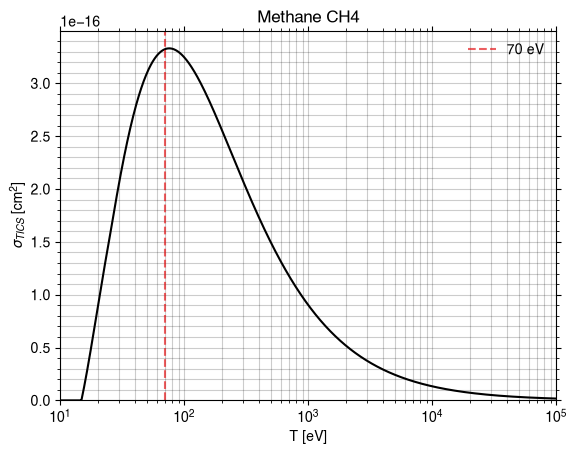

Compound(6324)
Recherche : 'Ethane' -> CID 6324, formule C2H6
3D
strucutre 3D
Réussite. Nom: Ethane, formule: C2H6, M: 30.07, nom_marche: Ethane
PYSCF CONVERGENCE
converged SCF energy = -79.2615282985009
**** MO energy ****
MO #1   energy= -11.2099692508146  occ= 2
MO #2   energy= -11.2093237093644  occ= 2
MO #3   energy= -1.02078471255222  occ= 2
MO #4   energy= -0.836323021738679 occ= 2
MO #5   energy= -0.599121850683095 occ= 2
MO #6   energy= -0.599105669129102 occ= 2
MO #7   energy= -0.508988795017947 occ= 2
MO #8   energy= -0.484809242534771 occ= 2
MO #9   energy= -0.484798417158416 occ= 2
MO #10  energy= 0.0780774968529424 occ= 0
MO #11  energy= 0.0963867225982603 occ= 0
MO #12  energy= 0.145541035281945  occ= 0
MO #13  energy= 0.145542392256904  occ= 0
MO #14  energy= 0.169994141724717  occ= 0
MO #15  energy= 0.169995030732463  occ= 0
MO #16  energy= 0.190369343942272  occ= 0
MO #17  energy= 0.211243027622765  occ= 0
MO #18  energy= 0.211245348120592  occ= 0
MO #19  energy= 0.23

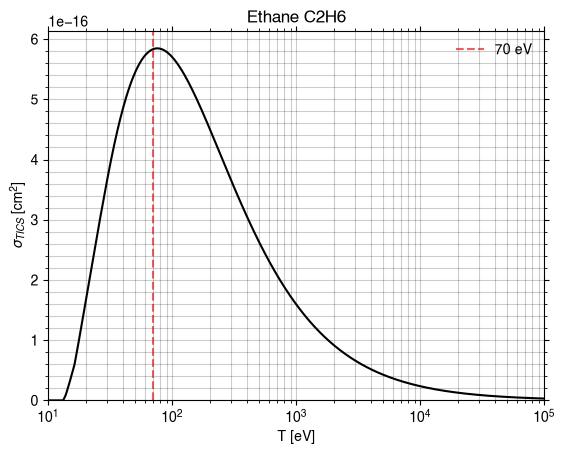

Compound(6325)
Recherche : 'Ethylene' -> CID 6325, formule C2H4
3D
strucutre 3D
Réussite. Nom: Ethylene, formule: C2H4, M: 28.05, nom_marche: Ethylene
PYSCF CONVERGENCE
converged SCF energy = -78.0661115887788
**** MO energy ****
MO #1   energy= -11.230621076484   occ= 2
MO #2   energy= -11.2289185519483  occ= 2
MO #3   energy= -1.03343300394992  occ= 2
MO #4   energy= -0.790250551081336 occ= 2
MO #5   energy= -0.645677809647285 occ= 2
MO #6   energy= -0.583872642427636 occ= 2
MO #7   energy= -0.509021422758433 occ= 2
MO #8   energy= -0.376676764230247 occ= 2
MO #9   energy= 0.0812830168680802 occ= 0
MO #10  energy= 0.090594561141691  occ= 0
MO #11  energy= 0.130705586840732  occ= 0
MO #12  energy= 0.136512335264042  occ= 0
MO #13  energy= 0.170866627474577  occ= 0
MO #14  energy= 0.181663915657171  occ= 0
MO #15  energy= 0.204762154873112  occ= 0
MO #16  energy= 0.23074890392505   occ= 0
MO #17  energy= 0.237854103506509  occ= 0
MO #18  energy= 0.24044260097321   occ= 0
MO #19  energy

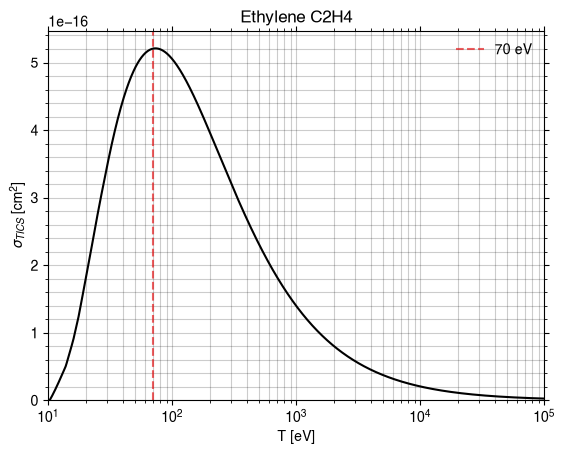

Compound(6326)
Recherche : 'Acetylene' -> CID 6326, formule C2H2
3D
strucutre 3D
Réussite. Nom: Acetylene, formule: C2H2, M: 26.04, nom_marche: Acetylene
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -76.8521780007621
**** MO energy ****
MO #1   energy= -11.2419764567706  occ= 2
MO #2   energy= -11.2380946427443  occ= 2
MO #3   energy= -1.03046635701493  occ= 2
MO #4   energy= -0.765653449896817 occ= 2
MO #5   energy= -0.680194068129993 occ= 2
MO #6   energy= -0.411385729090371 occ= 2
MO #7   energy= -0.411385729021917 occ= 2
MO #8   energy= 0.0723833102735757 occ= 0
MO #9   energy= 0.0909703694471465 occ= 0
MO #10  energy= 0.143771761707363  occ= 0
MO #11  energy= 0.143771765071405  occ= 0
MO #12  energy= 0.153578365818677  occ= 0
MO #13  energy= 0.217706794043473  occ= 0
MO #14  energy= 0.226980700711646  occ= 0
MO #15  energy= 0.226980709771211  occ= 0
MO #16  energy= 0.280791007625368  occ=

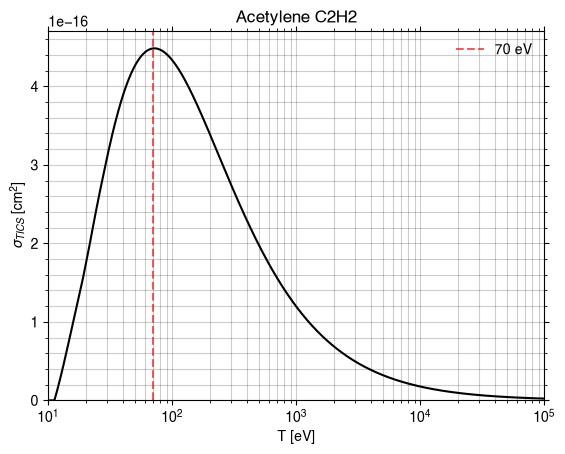

Compound(9999)
Recherche : 'Cyanogen' -> CID 9999, formule C2N2
3D
strucutre 3D
Réussite. Nom: Cyanogen, formule: C2N2, M: 52.03, nom_marche: Cyanogen
PYSCF CONVERGENCE
converged SCF energy = -184.654211820264
**** MO energy ****
MO #1   energy= -15.6572372875654  occ= 2
MO #2   energy= -15.6572302609845  occ= 2
MO #3   energy= -11.3544492682672  occ= 2
MO #4   energy= -11.3532581612994  occ= 2
MO #5   energy= -1.30050710548567  occ= 2
MO #6   energy= -1.2741231193907   occ= 2
MO #7   energy= -0.986544525781447 occ= 2
MO #8   energy= -0.640773907743514 occ= 2
MO #9   energy= -0.625120385311069 occ= 2
MO #10  energy= -0.601202517613044 occ= 2
MO #11  energy= -0.601202517613002 occ= 2
MO #12  energy= -0.495546914347819 occ= 2
MO #13  energy= -0.495546914347813 occ= 2
MO #14  energy= 0.0500385112184971 occ= 0
MO #15  energy= 0.0500385112185179 occ= 0
MO #16  energy= 0.0570036318686959 occ= 0
MO #17  energy= 0.102375289038726  occ= 0
MO #18  energy= 0.168739042413115  occ= 0
MO #19  energy

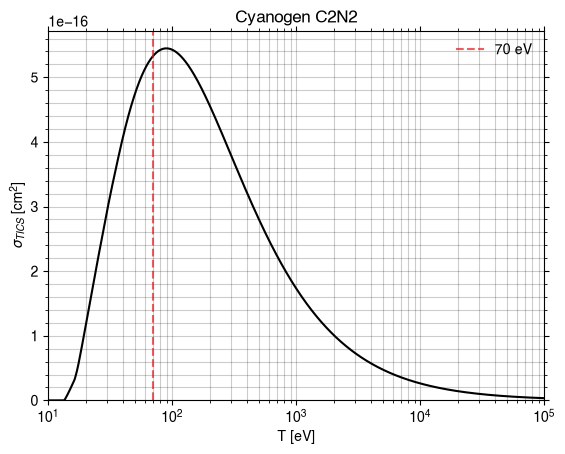

Compound(6334)
Recherche : 'Propane' -> CID 6334, formule C3H8
3D
strucutre 3D
Réussite. Nom: Propane, formule: C3H8, M: 44.1, nom_marche: Propane
PYSCF CONVERGENCE
converged SCF energy = -118.310439854332
**** MO energy ****
MO #1   energy= -11.2145465439324  occ= 2
MO #2   energy= -11.2076924145516  occ= 2
MO #3   energy= -11.2076510617524  occ= 2
MO #4   energy= -1.05486991741189  occ= 2
MO #5   energy= -0.923308724887232 occ= 2
MO #6   energy= -0.796542349417823 occ= 2
MO #7   energy= -0.626043413594033 occ= 2
MO #8   energy= -0.596921837825878 occ= 2
MO #9   energy= -0.550498340750185 occ= 2
MO #10  energy= -0.530393883092932 occ= 2
MO #11  energy= -0.4757997028223   occ= 2
MO #12  energy= -0.47089363200885  occ= 2
MO #13  energy= -0.468310036584293 occ= 2
MO #14  energy= 0.0786848038923312 occ= 0
MO #15  energy= 0.0947013554489804 occ= 0
MO #16  energy= 0.0966593003872048 occ= 0
MO #17  energy= 0.131849380390461  occ= 0
MO #18  energy= 0.153101307578052  occ= 0
MO #19  energy= 0.

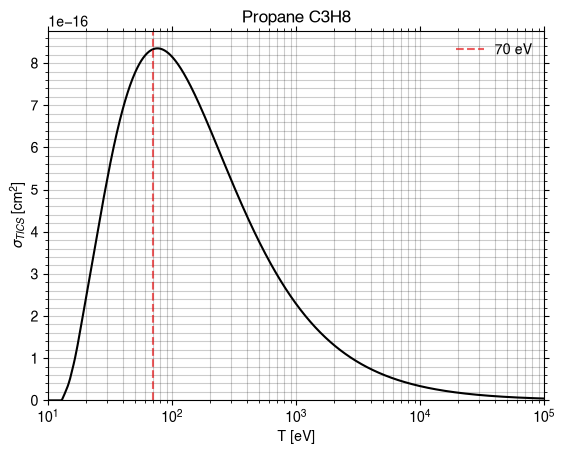

Compound(8252)
Recherche : 'Propene' -> CID 8252, formule C3H6
3D
strucutre 3D
Réussite. Nom: Propene, formule: C3H6, M: 42.08, nom_marche: Propene
PYSCF CONVERGENCE
converged SCF energy = -117.119413782498
**** MO energy ****
MO #1   energy= -11.233054605141   occ= 2
MO #2   energy= -11.2206776194905  occ= 2
MO #3   energy= -11.2166337114952  occ= 2
MO #4   energy= -1.06423257720654  occ= 2
MO #5   energy= -0.931131270128475 occ= 2
MO #6   energy= -0.756667965819599 occ= 2
MO #7   energy= -0.637507325603195 occ= 2
MO #8   energy= -0.583498133168077 occ= 2
MO #9   energy= -0.570470319618417 occ= 2
MO #10  energy= -0.518747880718015 occ= 2
MO #11  energy= -0.493952162931496 occ= 2
MO #12  energy= -0.357259928014585 occ= 2
MO #13  energy= 0.0784602903171132 occ= 0
MO #14  energy= 0.0925615727627961 occ= 0
MO #15  energy= 0.0964656576417529 occ= 0
MO #16  energy= 0.142813275672368  occ= 0
MO #17  energy= 0.15426199928218   occ= 0
MO #18  energy= 0.159846192639667  occ= 0
MO #19  energy= 0

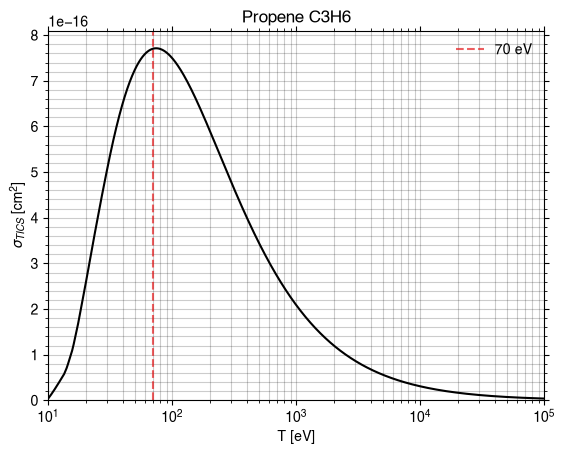

Compound(7854)
Recherche : 'Ethyl cyanide' -> CID 7854, formule C3H5N
3D
strucutre 3D
Réussite. Nom: Ethyl cyanide, formule: C3H5N, M: 55.08, nom_marche: Ethyl_cyanide
PYSCF CONVERGENCE
converged SCF energy = -171.025756643214
**** MO energy ****
MO #1   energy= -15.5701714363476  occ= 2
MO #2   energy= -11.286429623993   occ= 2
MO #3   energy= -11.2748215170773  occ= 2
MO #4   energy= -11.2478917606202  occ= 2
MO #5   energy= -1.21616736192826  occ= 2
MO #6   energy= -1.08579724342589  occ= 2
MO #7   energy= -0.908180982500141 occ= 2
MO #8   energy= -0.70792455105682  occ= 2
MO #9   energy= -0.659672590986908 occ= 2
MO #10  energy= -0.591356217015484 occ= 2
MO #11  energy= -0.56239778290127  occ= 2
MO #12  energy= -0.5398709791441   occ= 2
MO #13  energy= -0.539289669890489 occ= 2
MO #14  energy= -0.456965739681676 occ= 2
MO #15  energy= -0.456795628038237 occ= 2
MO #16  energy= 0.0607892244542665 occ= 0
MO #17  energy= 0.0824896080657541 occ= 0
MO #18  energy= 0.098202355472036  occ=

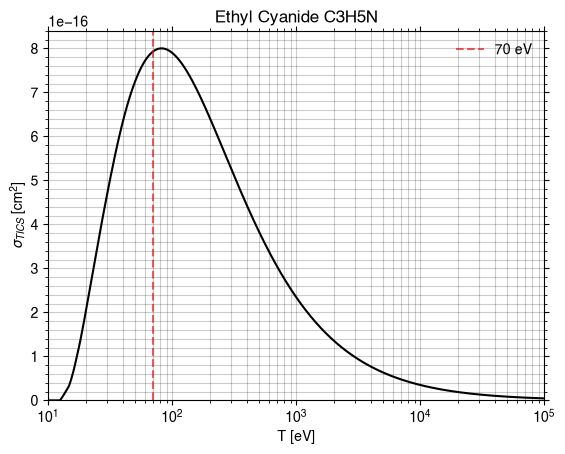

Compound(6335)
Recherche : 'Propyne' -> CID 6335, formule C3H4
3D
strucutre 3D
Réussite. Nom: Propyne, formule: C3H4, M: 40.06, nom_marche: Propyne
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -115.912123471014
**** MO energy ****
MO #1   energy= -11.2509177996229  occ= 2
MO #2   energy= -11.2341839026938  occ= 2
MO #3   energy= -11.217835077738   occ= 2
MO #4   energy= -1.05667942513734  occ= 2
MO #5   energy= -0.957670289294192 occ= 2
MO #6   energy= -0.717117254204005 occ= 2
MO #7   energy= -0.622196586678527 occ= 2
MO #8   energy= -0.591043218335328 occ= 2
MO #9   energy= -0.591031101395894 occ= 2
MO #10  energy= -0.385548102745718 occ= 2
MO #11  energy= -0.38554586890493  occ= 2
MO #12  energy= 0.0685043546063341 occ= 0
MO #13  energy= 0.0918341049777659 occ= 0
MO #14  energy= 0.118639174353302  occ= 0
MO #15  energy= 0.150686346517241  occ= 0
MO #16  energy= 0.150692758125278  occ= 0
MO 

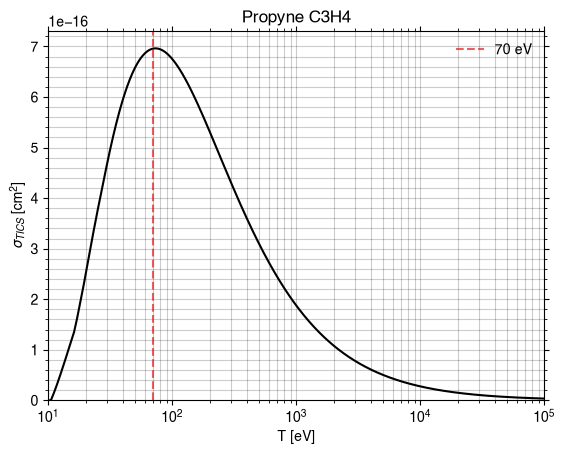

Compound(7855)
Recherche : 'Acrylonitrile' -> CID 7855, formule C3H3N
3D
strucutre 3D
Réussite. Nom: Acrylonitrile, formule: C3H3N, M: 53.06, nom_marche: Acrylonitrile
PYSCF CONVERGENCE
converged SCF energy = -169.830731562776
**** MO energy ****
MO #1   energy= -15.5784922856122  occ= 2
MO #2   energy= -11.2918158989427  occ= 2
MO #3   energy= -11.283796088444   occ= 2
MO #4   energy= -11.2814672530888  occ= 2
MO #5   energy= -1.22374529951772  occ= 2
MO #6   energy= -1.10198757846278  occ= 2
MO #7   energy= -0.887632912796334 occ= 2
MO #8   energy= -0.732728346538224 occ= 2
MO #9   energy= -0.660609076837034 occ= 2
MO #10  energy= -0.587040502655788 occ= 2
MO #11  energy= -0.556070338680278 occ= 2
MO #12  energy= -0.521404585960887 occ= 2
MO #13  energy= -0.470237157589835 occ= 2
MO #14  energy= -0.397567425327701 occ= 2
MO #15  energy= 0.0606476025474907 occ= 0
MO #16  energy= 0.0709489689224944 occ= 0
MO #17  energy= 0.0808908904555367 occ= 0
MO #18  energy= 0.0957436508781173 occ=

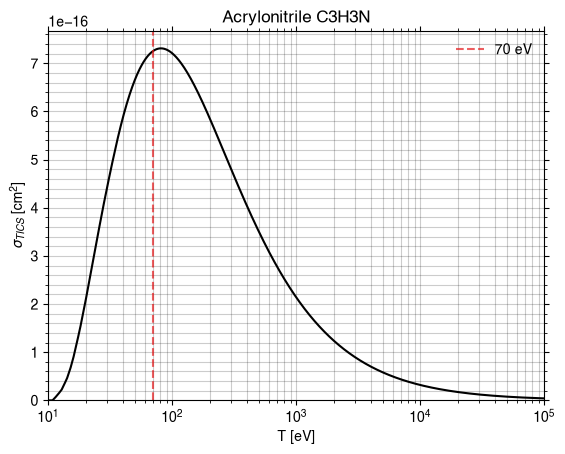

Compound(14055)
Recherche : 'Cyanoacetylene' -> CID 14055, formule C3HN
3D
strucutre 3D
Réussite. Nom: Cyanoacetylene, formule: C3HN, M: 51.05, nom_marche: Cyanoacetylene
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -168.610738488113
**** MO energy ****
MO #1   energy= -15.6073208927986  occ= 2
MO #2   energy= -11.3125077449369  occ= 2
MO #3   energy= -11.3017097592932  occ= 2
MO #4   energy= -11.2973122698218  occ= 2
MO #5   energy= -1.24664979328258  occ= 2
MO #6   energy= -1.09762218953783  occ= 2
MO #7   energy= -0.908639176727434 occ= 2
MO #8   energy= -0.756812215876757 occ= 2
MO #9   energy= -0.590292190444977 occ= 2
MO #10  energy= -0.548130761353718 occ= 2
MO #11  energy= -0.548130759271735 occ= 2
MO #12  energy= -0.429076644696099 occ= 2
MO #13  energy= -0.429076638697089 occ= 2
MO #14  energy= 0.0558945356343275 occ= 0
MO #15  energy= 0.0765339443393647 occ= 0
MO #16  energy= 0.0765

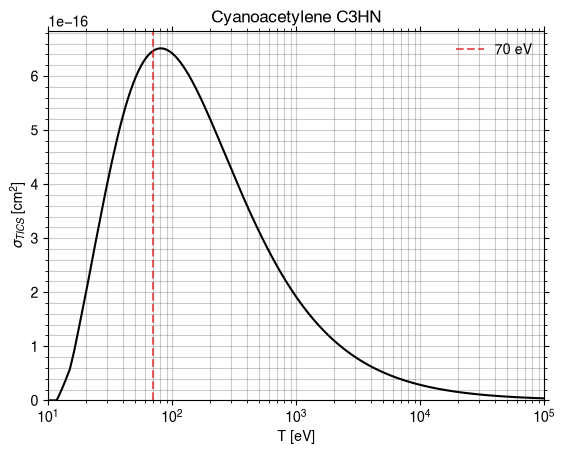

Compound(6360)
Recherche : '2-Methylpropane' -> CID 6360, formule C4H10
3D
strucutre 3D
Réussite. Nom: 2-Methylpropane, formule: C4H10, M: 58.12, nom_marche: 2-Methylpropane
PYSCF CONVERGENCE
converged SCF energy = -157.359793550121
**** MO energy ****
MO #1   energy= -11.221504508853   occ= 2
MO #2   energy= -11.2070845922256  occ= 2
MO #3   energy= -11.2070752847761  occ= 2
MO #4   energy= -11.2070406033347  occ= 2
MO #5   energy= -1.08029004850668  occ= 2
MO #6   energy= -0.924521591159103 occ= 2
MO #7   energy= -0.924504334344692 occ= 2
MO #8   energy= -0.76451331757152  occ= 2
MO #9   energy= -0.630016904043199 occ= 2
MO #10  energy= -0.588641124228879 occ= 2
MO #11  energy= -0.588630931559788 occ= 2
MO #12  energy= -0.532863763270554 occ= 2
MO #13  energy= -0.532854327169861 occ= 2
MO #14  energy= -0.507280160353201 occ= 2
MO #15  energy= -0.461014803033281 occ= 2
MO #16  energy= -0.459812004522193 occ= 2
MO #17  energy= -0.459786490193091 occ= 2
MO #18  energy= 0.075899954802225

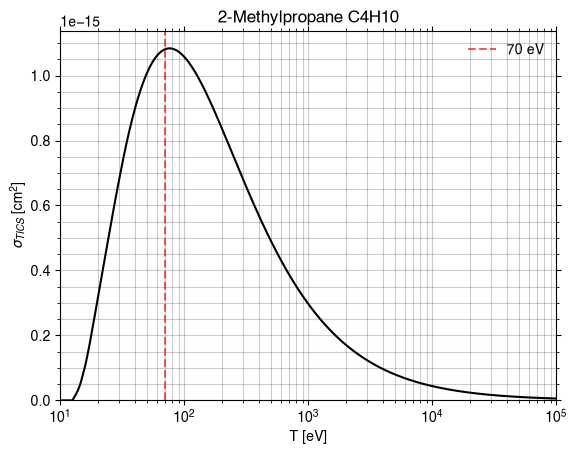

Compound(8003)
Recherche : 'Pentane' -> CID 8003, formule C5H12
3D
strucutre 3D
Réussite. Nom: Pentane, formule: C5H12, M: 72.15, nom_marche: Pentane
PYSCF CONVERGENCE
converged SCF energy = -196.407339924893
**** MO energy ****
MO #1   energy= -11.2120914330955  occ= 2
MO #2   energy= -11.2119607431948  occ= 2
MO #3   energy= -11.2106037194012  occ= 2
MO #4   energy= -11.2065726899435  occ= 2
MO #5   energy= -11.2065528551373  occ= 2
MO #6   energy= -1.07989171601954  occ= 2
MO #7   energy= -1.01447584644788  occ= 2
MO #8   energy= -0.915704137089598 occ= 2
MO #9   energy= -0.814499833490132 occ= 2
MO #10  energy= -0.784066867627853 occ= 2
MO #11  energy= -0.647472986179586 occ= 2
MO #12  energy= -0.597401807599852 occ= 2
MO #13  energy= -0.59325038182804  occ= 2
MO #14  energy= -0.553028350975822 occ= 2
MO #15  energy= -0.543815882569115 occ= 2
MO #16  energy= -0.525123179602357 occ= 2
MO #17  energy= -0.493462894119711 occ= 2
MO #18  energy= -0.475410325286872 occ= 2
MO #19  energy=

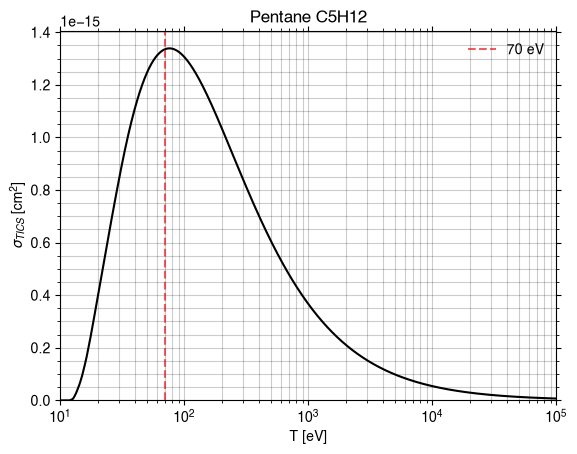

Compound(7843)
Recherche : 'n-Butane' -> CID 7843, formule C4H10
3D
strucutre 3D
Réussite. Nom: n-Butane, formule: C4H10, M: 58.12, nom_marche: n-Butane
PYSCF CONVERGENCE
converged SCF energy = -157.35891536591
**** MO energy ****
MO #1   energy= -11.2129351396282  occ= 2
MO #2   energy= -11.2123183456255  occ= 2
MO #3   energy= -11.2069292629154  occ= 2
MO #4   energy= -11.2069208934758  occ= 2
MO #5   energy= -1.07110050500526  occ= 2
MO #6   energy= -0.979955643239101 occ= 2
MO #7   energy= -0.855608389765479 occ= 2
MO #8   energy= -0.786022099097522 occ= 2
MO #9   energy= -0.639739714720456 occ= 2
MO #10  energy= -0.585395562983945 occ= 2
MO #11  energy= -0.572310676457983 occ= 2
MO #12  energy= -0.567671904758201 occ= 2
MO #13  energy= -0.513223839956115 occ= 2
MO #14  energy= -0.493321484212543 occ= 2
MO #15  energy= -0.469844429921889 occ= 2
MO #16  energy= -0.463409674882755 occ= 2
MO #17  energy= -0.451212854775058 occ= 2
MO #18  energy= 0.0795644395575263 occ= 0
MO #19  energ

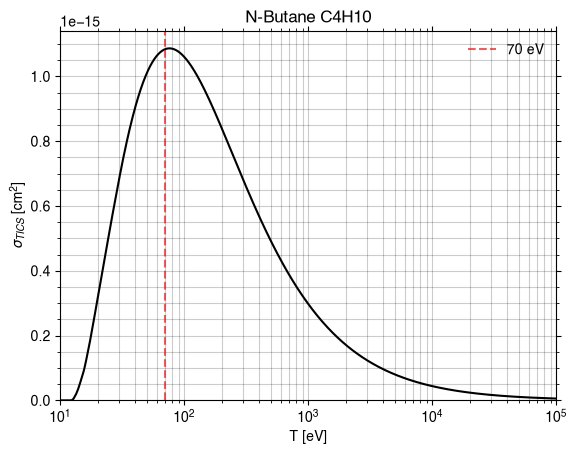

Compound(7844)
Recherche : '1-Butene' -> CID 7844, formule C4H8
3D
strucutre 3D
Réussite. Nom: 1-Butene, formule: C4H8, M: 56.11, nom_marche: 1-Butene
PYSCF CONVERGENCE
converged SCF energy = -156.165884561295
**** MO energy ****
MO #1   energy= -11.229706725248   occ= 2
MO #2   energy= -11.2235685851911  occ= 2
MO #3   energy= -11.2168119503942  occ= 2
MO #4   energy= -11.2141166073557  occ= 2
MO #5   energy= -1.08050758174349  occ= 2
MO #6   energy= -0.98563174355597  occ= 2
MO #7   energy= -0.855973673573462 occ= 2
MO #8   energy= -0.750390850520294 occ= 2
MO #9   energy= -0.64711711257522  occ= 2
MO #10  energy= -0.607504406459341 occ= 2
MO #11  energy= -0.570957509611455 occ= 2
MO #12  energy= -0.545834546461956 occ= 2
MO #13  energy= -0.519607801783302 occ= 2
MO #14  energy= -0.482046840467765 occ= 2
MO #15  energy= -0.473202672714677 occ= 2
MO #16  energy= -0.356257412727643 occ= 2
MO #17  energy= 0.0764195832139398 occ= 0
MO #18  energy= 0.091542522657667  occ= 0
MO #19  energy

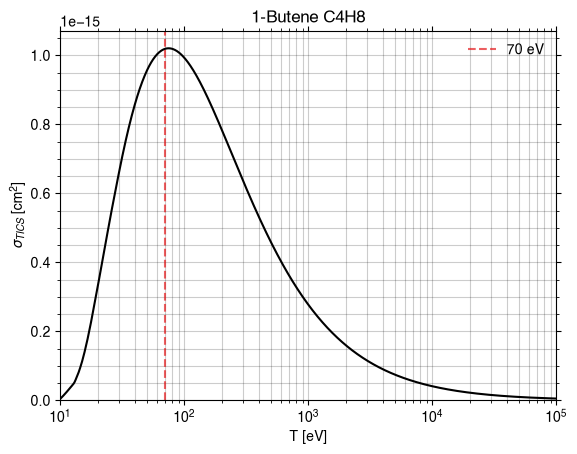

Compound(5287573)
Recherche : 'cis-2-Butene' -> CID 5287573, formule C4H8
3D
strucutre 3D
Réussite. Nom: cis-2-Butene, formule: C4H8, M: 56.11, nom_marche: cis-2-Butene
PYSCF CONVERGENCE
converged SCF energy = -156.166415012759
**** MO energy ****
MO #1   energy= -11.2207410055755  occ= 2
MO #2   energy= -11.2190949357287  occ= 2
MO #3   energy= -11.2152098237917  occ= 2
MO #4   energy= -11.2151968893336  occ= 2
MO #5   energy= -1.07868500770452  occ= 2
MO #6   energy= -0.97555820967672  occ= 2
MO #7   energy= -0.889236685677655 occ= 2
MO #8   energy= -0.719608481823684 occ= 2
MO #9   energy= -0.65216673658772  occ= 2
MO #10  energy= -0.57805351761242  occ= 2
MO #11  energy= -0.571809082375272 occ= 2
MO #12  energy= -0.554572903875284 occ= 2
MO #13  energy= -0.525444843358788 occ= 2
MO #14  energy= -0.504803588518098 occ= 2
MO #15  energy= -0.477572555169385 occ= 2
MO #16  energy= -0.338911840248826 occ= 2
MO #17  energy= 0.0757906334308932 occ= 0
MO #18  energy= 0.0907114156914113 occ

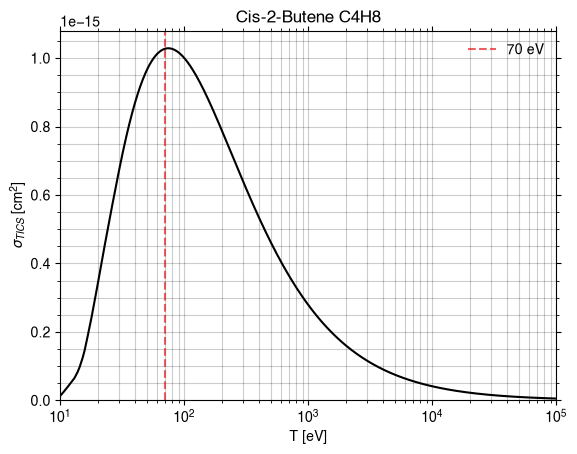

Compound(62695)
Recherche : 'trans-2-Butene' -> CID 62695, formule C4H8
3D
strucutre 3D
Réussite. Nom: trans-2-Butene, formule: C4H8, M: 56.11, nom_marche: trans-2-Butene
PYSCF CONVERGENCE
converged SCF energy = -156.171339003418
**** MO energy ****
MO #1   energy= -11.2217150854611  occ= 2
MO #2   energy= -11.2200665947421  occ= 2
MO #3   energy= -11.2152210957663  occ= 2
MO #4   energy= -11.2152027868812  occ= 2
MO #5   energy= -1.07620773453956  occ= 2
MO #6   energy= -0.983713824314322 occ= 2
MO #7   energy= -0.873361928363224 occ= 2
MO #8   energy= -0.744693001793951 occ= 2
MO #9   energy= -0.607052768517433 occ= 2
MO #10  energy= -0.602107517307093 occ= 2
MO #11  energy= -0.573142275458397 occ= 2
MO #12  energy= -0.556175870812743 occ= 2
MO #13  energy= -0.521358382424973 occ= 2
MO #14  energy= -0.502979845879169 occ= 2
MO #15  energy= -0.483201782400898 occ= 2
MO #16  energy= -0.339290283960093 occ= 2
MO #17  energy= 0.0781290566883945 occ= 0
MO #18  energy= 0.0871999637607955 o

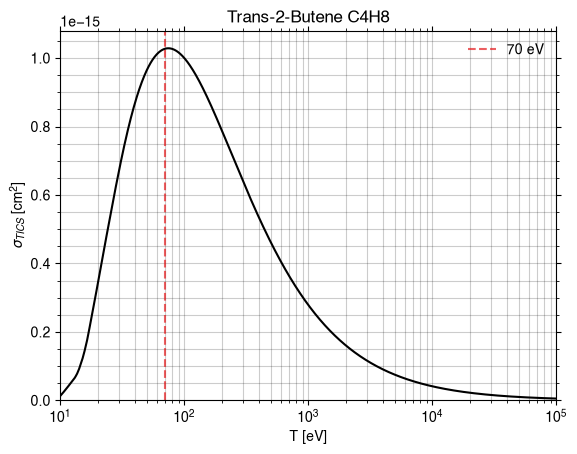

Compound(7845)
Recherche : '1,3-Butadiene' -> CID 7845, formule C4H6
3D
strucutre 3D
Réussite. Nom: 1,3-Butadiene, formule: C4H6, M: 54.09, nom_marche: 1_3-Butadiene
PYSCF CONVERGENCE
converged SCF energy = -154.982078050209
**** MO energy ****
MO #1   energy= -11.2376472689818  occ= 2
MO #2   energy= -11.2367586626596  occ= 2
MO #3   energy= -11.2284833540689  occ= 2
MO #4   energy= -11.2284677027697  occ= 2
MO #5   energy= -1.09481379605524  occ= 2
MO #6   energy= -1.00024962411518  occ= 2
MO #7   energy= -0.826848859802013 occ= 2
MO #8   energy= -0.755141947229514 occ= 2
MO #9   energy= -0.64331651658248  occ= 2
MO #10  energy= -0.638999947214055 occ= 2
MO #11  energy= -0.554374267402023 occ= 2
MO #12  energy= -0.545687035726199 occ= 2
MO #13  energy= -0.497775275762532 occ= 2
MO #14  energy= -0.446675034294095 occ= 2
MO #15  energy= -0.322754087319865 occ= 2
MO #16  energy= 0.0774042068338873 occ= 0
MO #17  energy= 0.0834746564303429 occ= 0
MO #18  energy= 0.0912405211539668 occ= 0

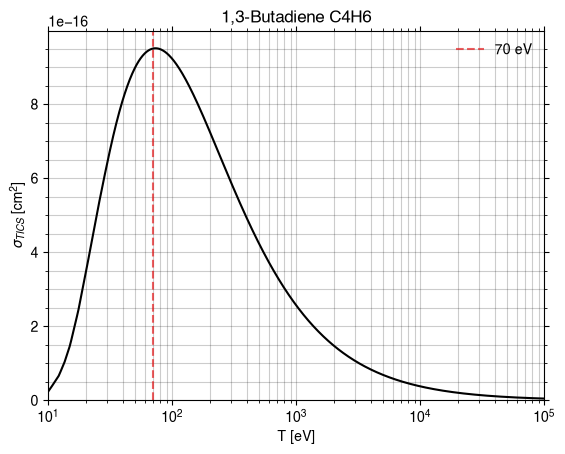

Compound(9997)
Recherche : 'Diacetylene' -> CID 9997, formule C4H2
3D
strucutre 3D
Réussite. Nom: Diacetylene, formule: C4H2, M: 50.06, nom_marche: Diacetylene
PYSCF CONVERGENCE

WARN: 3 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -152.557287679746
**** MO energy ****
MO #1   energy= -11.2652599172791  occ= 2
MO #2   energy= -11.264116888502   occ= 2
MO #3   energy= -11.2562310074101  occ= 2
MO #4   energy= -11.2561636772772  occ= 2
MO #5   energy= -1.09285199822919  occ= 2
MO #6   energy= -1.02334767584448  occ= 2
MO #7   energy= -0.849585734508668 occ= 2
MO #8   energy= -0.732224313440003 occ= 2
MO #9   energy= -0.705209557266262 occ= 2
MO #10  energy= -0.493802717384198 occ= 2
MO #11  energy= -0.493802715761275 occ= 2
MO #12  energy= -0.372601987373164 occ= 2
MO #13  energy= -0.372601983760159 occ= 2
MO #14  energy= 0.0666443776205717 occ= 0
MO #15  energy= 0.081133067722353  occ= 0
MO #16  energy= 0.100651242794322

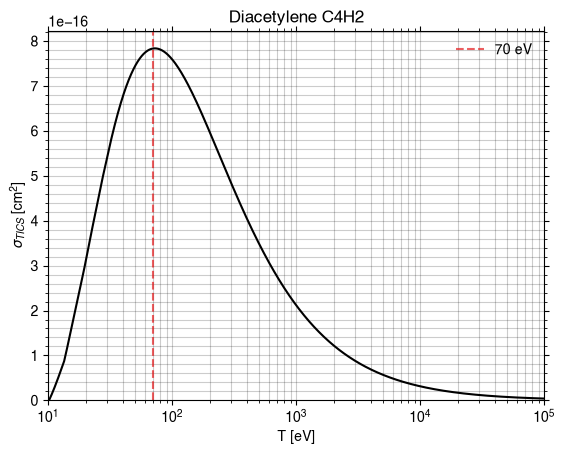

Compound(6351)
Recherche : 'Cyclopropane' -> CID 6351, formule C3H6
3D
strucutre 3D
Réussite. Nom: Cyclopropane, formule: C3H6, M: 42.08, nom_marche: Cyclopropane
PYSCF CONVERGENCE
converged SCF energy = -117.104442927334
**** MO energy ****
MO #1   energy= -11.2214827567961  occ= 2
MO #2   energy= -11.220445840455   occ= 2
MO #3   energy= -11.2204401298758  occ= 2
MO #4   energy= -1.13276905356131  occ= 2
MO #5   energy= -0.816530727899286 occ= 2
MO #6   energy= -0.816519201144197 occ= 2
MO #7   energy= -0.668613192273945 occ= 2
MO #8   energy= -0.626782838932741 occ= 2
MO #9   energy= -0.511624827798992 occ= 2
MO #10  energy= -0.511614177719357 occ= 2
MO #11  energy= -0.419587182369083 occ= 2
MO #12  energy= -0.419525247518771 occ= 2
MO #13  energy= 0.0838903186098944 occ= 0
MO #14  energy= 0.0915745850315108 occ= 0
MO #15  energy= 0.0915770460636924 occ= 0
MO #16  energy= 0.121494869730697  occ= 0
MO #17  energy= 0.167134142229903  occ= 0
MO #18  energy= 0.169300019040849  occ= 0
MO

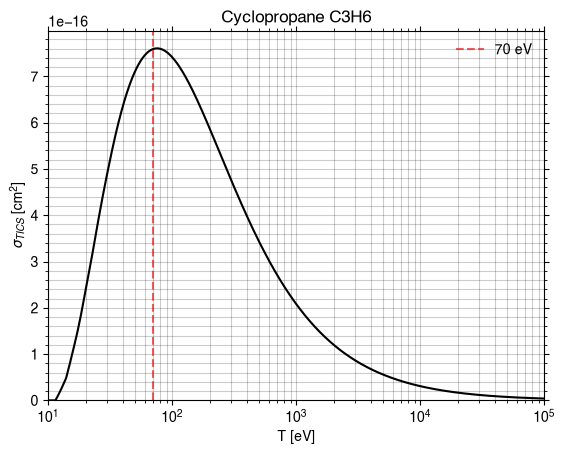

Compound(8255)
Recherche : 'Isobutylene' -> CID 8255, formule C4H8
3D
strucutre 3D
Réussite. Nom: Isobutylene, formule: C4H8, M: 56.11, nom_marche: Isobutylene
PYSCF CONVERGENCE
converged SCF energy = -156.172411827206
**** MO energy ****
MO #1   energy= -11.2379045093263  occ= 2
MO #2   energy= -11.2190295198813  occ= 2
MO #3   energy= -11.2190003116947  occ= 2
MO #4   energy= -11.2079371336318  occ= 2
MO #5   energy= -1.08855559431921  occ= 2
MO #6   energy= -0.941354274889518 occ= 2
MO #7   energy= -0.924159152618695 occ= 2
MO #8   energy= -0.717424006788811 occ= 2
MO #9   energy= -0.617117997763962 occ= 2
MO #10  energy= -0.608845459645325 occ= 2
MO #11  energy= -0.593938919557258 occ= 2
MO #12  energy= -0.541076672334724 occ= 2
MO #13  energy= -0.518320231263221 occ= 2
MO #14  energy= -0.510594409906528 occ= 2
MO #15  energy= -0.48141633005465  occ= 2
MO #16  energy= -0.344794232628686 occ= 2
MO #17  energy= 0.0708198550918498 occ= 0
MO #18  energy= 0.0936716418141242 occ= 0
MO #1

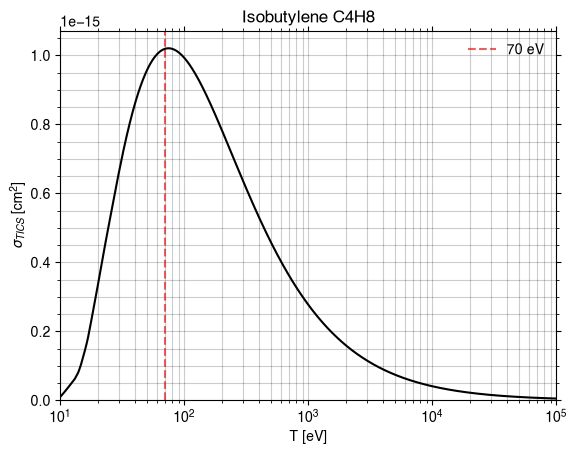

Compound(11535)
Recherche : '1,2-Butadiene' -> CID 11535, formule C4H6
3D
strucutre 3D
Réussite. Nom: 1,2-Butadiene, formule: C4H6, M: 54.09, nom_marche: 1_2-Butadiene
PYSCF CONVERGENCE
converged SCF energy = -154.846407928386
**** MO energy ****
MO #1   energy= -11.3516573212307  occ= 2
MO #2   energy= -11.2375271007978  occ= 2
MO #3   energy= -11.2018119366129  occ= 2
MO #4   energy= -11.1922897220181  occ= 2
MO #5   energy= -1.10953961297436  occ= 2
MO #6   energy= -1.01161060328047  occ= 2
MO #7   energy= -0.903339991220935 occ= 2
MO #8   energy= -0.698204039161393 occ= 2
MO #9   energy= -0.644706795898056 occ= 2
MO #10  energy= -0.598938441403284 occ= 2
MO #11  energy= -0.581538086559376 occ= 2
MO #12  energy= -0.556463444409394 occ= 2
MO #13  energy= -0.525757668462841 occ= 2
MO #14  energy= -0.480006033964077 occ= 2
MO #15  energy= -0.247283925173249 occ= 2
MO #16  energy= 0.0382353568266147 occ= 0
MO #17  energy= 0.0712212723702997 occ= 0
MO #18  energy= 0.0911889501851254 occ=

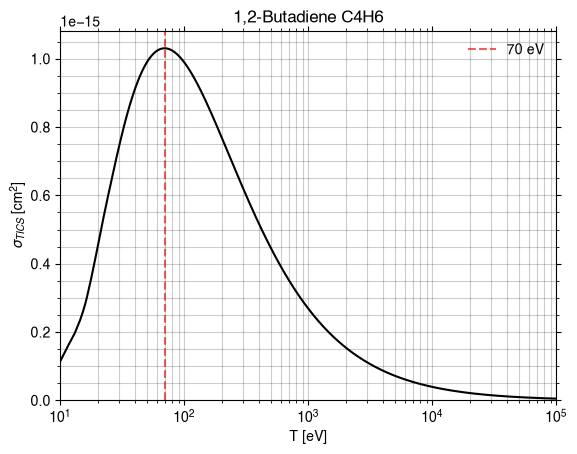

Compound(7846)
Recherche : '1-Butyne' -> CID 7846, formule C4H6
3D
strucutre 3D
Réussite. Nom: 1-Butyne, formule: C4H6, M: 54.09, nom_marche: 1-Butyne
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -154.960536939125
**** MO energy ****
MO #1   energy= -11.252720195037   occ= 2
MO #2   energy= -11.2306730482107  occ= 2
MO #3   energy= -11.2241856716542  occ= 2
MO #4   energy= -11.2170353421056  occ= 2
MO #5   energy= -1.08091551353936  occ= 2
MO #6   energy= -0.994528212292035 occ= 2
MO #7   energy= -0.870791908376003 occ= 2
MO #8   energy= -0.715801145655174 occ= 2
MO #9   energy= -0.6428145831793   occ= 2
MO #10  energy= -0.629442417585607 occ= 2
MO #11  energy= -0.551724250350659 occ= 2
MO #12  energy= -0.522314934260357 occ= 2
MO #13  energy= -0.511566182296307 occ= 2
MO #14  energy= -0.384204593148168 occ= 2
MO #15  energy= -0.384060620590536 occ= 2
MO #16  energy= 0.0701688129519696 occ= 0


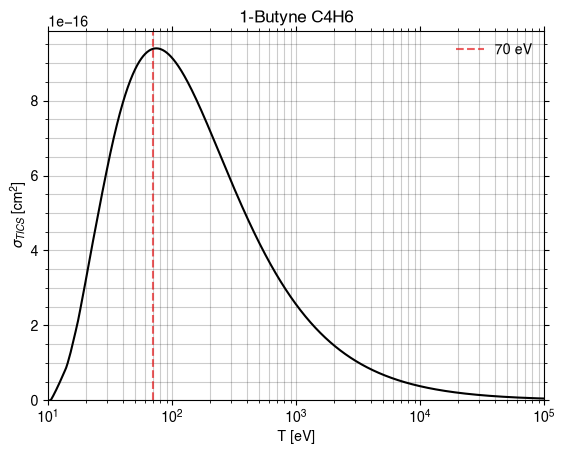

Compound(12720)
Recherche : '1-Buten-3-yne' -> CID 12720, formule C4H4
3D
strucutre 3D
Réussite. Nom: 1-Buten-3-yne, formule: C4H4, M: 52.07, nom_marche: 1-Buten-3-yne
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -153.769049526893
**** MO energy ****
MO #1   energy= -11.2611462000976  occ= 2
MO #2   energy= -11.2475475781369  occ= 2
MO #3   energy= -11.238024026378   occ= 2
MO #4   energy= -11.2286629087452  occ= 2
MO #5   energy= -1.09426632910945  occ= 2
MO #6   energy= -1.00549763076198  occ= 2
MO #7   energy= -0.841806659380431 occ= 2
MO #8   energy= -0.722971243017675 occ= 2
MO #9   energy= -0.676277691498012 occ= 2
MO #10  energy= -0.622159383447688 occ= 2
MO #11  energy= -0.543539709196317 occ= 2
MO #12  energy= -0.467415037855591 occ= 2
MO #13  energy= -0.398018250909125 occ= 2
MO #14  energy= -0.345255744893084 occ= 2
MO #15  energy= 0.0702703769660705 occ= 0
MO #16  energy= 0.0858009

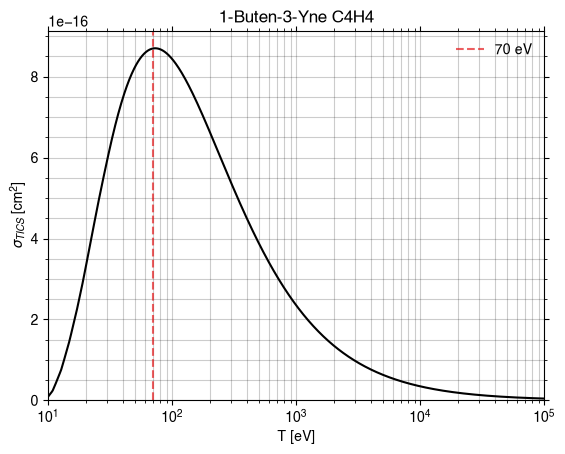

Compound(8004)
Recherche : '1-Pentene' -> CID 8004, formule C5H10
3D
strucutre 3D
Réussite. Nom: 1-Pentene, formule: C5H10, M: 70.13, nom_marche: 1-Pentene
PYSCF CONVERGENCE
converged SCF energy = -195.216375276123
**** MO energy ****
MO #1   energy= -11.2297215047509  occ= 2
MO #2   energy= -11.2222244082469  occ= 2
MO #3   energy= -11.219005030283   occ= 2
MO #4   energy= -11.2159351441731  occ= 2
MO #5   energy= -11.2110675241656  occ= 2
MO #6   energy= -1.08825343520545  occ= 2
MO #7   energy= -1.02124374739851  occ= 2
MO #8   energy= -0.920557085786925 occ= 2
MO #9   energy= -0.808566920407049 occ= 2
MO #10  energy= -0.756041621813029 occ= 2
MO #11  energy= -0.64872112480634  occ= 2
MO #12  energy= -0.617480042716274 occ= 2
MO #13  energy= -0.587754184740347 occ= 2
MO #14  energy= -0.568141533139524 occ= 2
MO #15  energy= -0.536784542240827 occ= 2
MO #16  energy= -0.51083711871955  occ= 2
MO #17  energy= -0.483721654024638 occ= 2
MO #18  energy= -0.474160246739209 occ= 2
MO #19  e

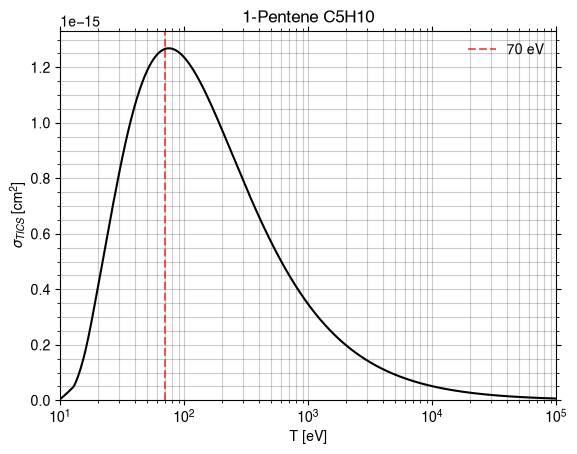

Compound(12585)
Recherche : '2-Pentene' -> CID 12585, formule C5H10
3D
strucutre 3D
Réussite. Nom: 2-Pentene, formule: C5H10, M: 70.13, nom_marche: 2-Pentene
PYSCF CONVERGENCE
converged SCF energy = -195.217748547617
**** MO energy ****
MO #1   energy= -11.221512921586   occ= 2
MO #2   energy= -11.2186730970447  occ= 2
MO #3   energy= -11.2172729520242  occ= 2
MO #4   energy= -11.2154990114405  occ= 2
MO #5   energy= -11.2100003718235  occ= 2
MO #6   energy= -1.08547538376796  occ= 2
MO #7   energy= -1.01743738467128  occ= 2
MO #8   energy= -0.921222129870838 occ= 2
MO #9   energy= -0.829361344095666 occ= 2
MO #10  energy= -0.742076470527188 occ= 2
MO #11  energy= -0.622681265061949 occ= 2
MO #12  energy= -0.619047913500572 occ= 2
MO #13  energy= -0.567348463658027 occ= 2
MO #14  energy= -0.559656178368716 occ= 2
MO #15  energy= -0.549456029054761 occ= 2
MO #16  energy= -0.517808888406138 occ= 2
MO #17  energy= -0.505688239519861 occ= 2
MO #18  energy= -0.475789117255138 occ= 2
MO #19 

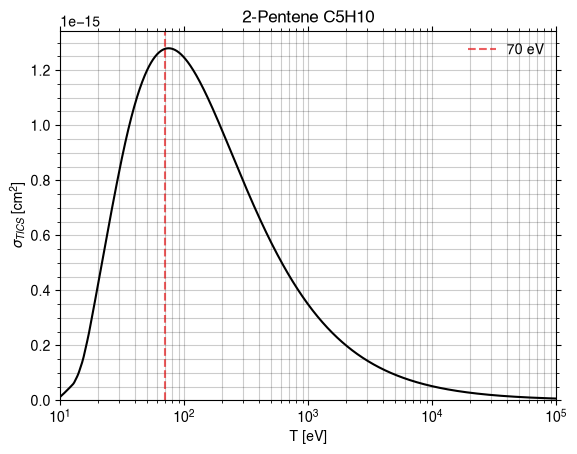

Compound(9253)
Recherche : 'Cyclopentane' -> CID 9253, formule C5H10
3D
strucutre 3D
Réussite. Nom: Cyclopentane, formule: C5H10, M: 70.13, nom_marche: Cyclopentane
PYSCF CONVERGENCE
converged SCF energy = -195.233044548082
**** MO energy ****
MO #1   energy= -11.2083852575526  occ= 2
MO #2   energy= -11.2078424173009  occ= 2
MO #3   energy= -11.2074794092701  occ= 2
MO #4   energy= -11.2071183338476  occ= 2
MO #5   energy= -11.2065307233198  occ= 2
MO #6   energy= -1.12157272705211  occ= 2
MO #7   energy= -0.958622204411665 occ= 2
MO #8   energy= -0.958587925248347 occ= 2
MO #9   energy= -0.7736561871259   occ= 2
MO #10  energy= -0.762611679594346 occ= 2
MO #11  energy= -0.653045852371857 occ= 2
MO #12  energy= -0.645788652785294 occ= 2
MO #13  energy= -0.571671137325564 occ= 2
MO #14  energy= -0.570145816452737 occ= 2
MO #15  energy= -0.472708098452073 occ= 2
MO #16  energy= -0.471979018708557 occ= 2
MO #17  energy= -0.467304325873999 occ= 2
MO #18  energy= -0.461516387639292 occ= 2


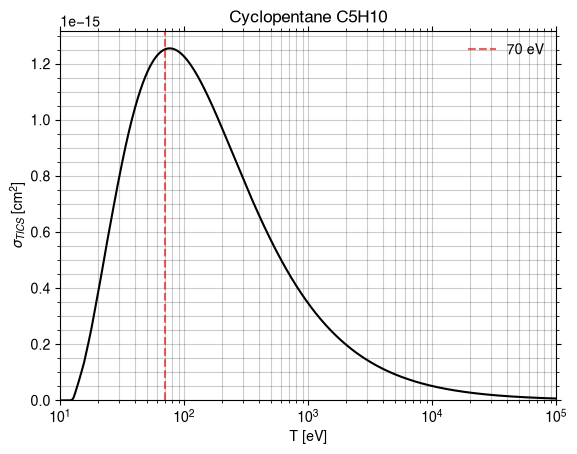

Compound(8882)
Recherche : 'Cyclopentene' -> CID 8882, formule C5H8
3D
strucutre 3D
Réussite. Nom: Cyclopentene, formule: C5H8, M: 68.12, nom_marche: Cyclopentene
PYSCF CONVERGENCE
converged SCF energy = -194.047800582256
**** MO energy ****
MO #1   energy= -11.2165943714911  occ= 2
MO #2   energy= -11.215946191932   occ= 2
MO #3   energy= -11.2157400239301  occ= 2
MO #4   energy= -11.2146026248706  occ= 2
MO #5   energy= -11.213727651967   occ= 2
MO #6   energy= -1.13476736507713  occ= 2
MO #7   energy= -0.961808323464932 occ= 2
MO #8   energy= -0.958818519408283 occ= 2
MO #9   energy= -0.781208259207691 occ= 2
MO #10  energy= -0.722212283092482 occ= 2
MO #11  energy= -0.673635141730038 occ= 2
MO #12  energy= -0.639365396878642 occ= 2
MO #13  energy= -0.555516640273783 occ= 2
MO #14  energy= -0.527553093299382 occ= 2
MO #15  energy= -0.49091344875689  occ= 2
MO #16  energy= -0.488841682022854 occ= 2
MO #17  energy= -0.480597496512815 occ= 2
MO #18  energy= -0.475203464590898 occ= 2
MO

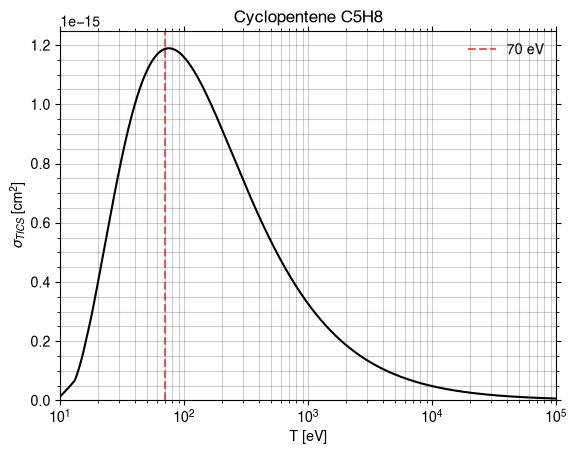

Compound(6557)
Recherche : 'Isoprene' -> CID 6557, formule C5H8
3D
strucutre 3D
Réussite. Nom: Isoprene, formule: C5H8, M: 68.12, nom_marche: Isoprene
PYSCF CONVERGENCE
converged SCF energy = -194.033229418083
**** MO energy ****
MO #1   energy= -11.2434208849934  occ= 2
MO #2   energy= -11.2356186768395  occ= 2
MO #3   energy= -11.2264908326864  occ= 2
MO #4   energy= -11.2223348534523  occ= 2
MO #5   energy= -11.2220890695627  occ= 2
MO #6   energy= -1.10939406635537  occ= 2
MO #7   energy= -1.00892830049606  occ= 2
MO #8   energy= -0.936856820045907 occ= 2
MO #9   energy= -0.821153762267301 occ= 2
MO #10  energy= -0.716195631377548 occ= 2
MO #11  energy= -0.650149219090001 occ= 2
MO #12  energy= -0.629188460701844 occ= 2
MO #13  energy= -0.576282257897948 occ= 2
MO #14  energy= -0.558315602803208 occ= 2
MO #15  energy= -0.542110239605146 occ= 2
MO #16  energy= -0.517742559316571 occ= 2
MO #17  energy= -0.484390029711399 occ= 2
MO #18  energy= -0.425187625968537 occ= 2
MO #19  energy

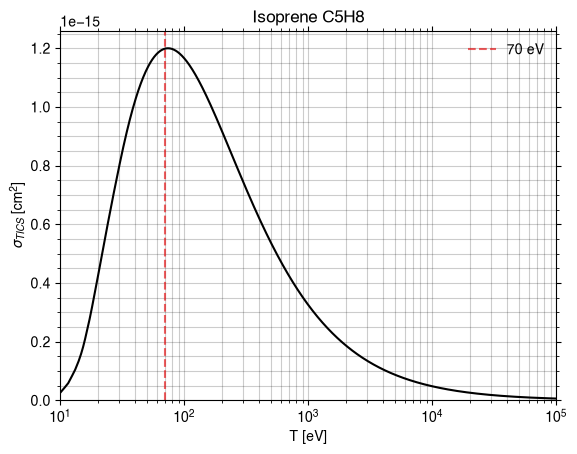

Compound(7612)
Recherche : '1,3-Cyclopentadiene' -> CID 7612, formule C5H6
3D
strucutre 3D
Réussite. Nom: 1,3-Cyclopentadiene, formule: C5H6, M: 66.1, nom_marche: 1_3-Cyclopentadiene
PYSCF CONVERGENCE
converged SCF energy = -192.863626095525
**** MO energy ****
MO #1   energy= -11.2287780414039  occ= 2
MO #2   energy= -11.2224126974096  occ= 2
MO #3   energy= -11.2223612132306  occ= 2
MO #4   energy= -11.2202639785277  occ= 2
MO #5   energy= -11.219455682384   occ= 2
MO #6   energy= -1.15548361194252  occ= 2
MO #7   energy= -0.962932967150516 occ= 2
MO #8   energy= -0.957929796735978 occ= 2
MO #9   energy= -0.757291424037739 occ= 2
MO #10  energy= -0.723382308117202 occ= 2
MO #11  energy= -0.697037436569182 occ= 2
MO #12  energy= -0.59967735502758  occ= 2
MO #13  energy= -0.557531703766983 occ= 2
MO #14  energy= -0.527869245880555 occ= 2
MO #15  energy= -0.507870567863735 occ= 2
MO #16  energy= -0.50187066173713  occ= 2
MO #17  energy= -0.418762076338151 occ= 2
MO #18  energy= -0.30571

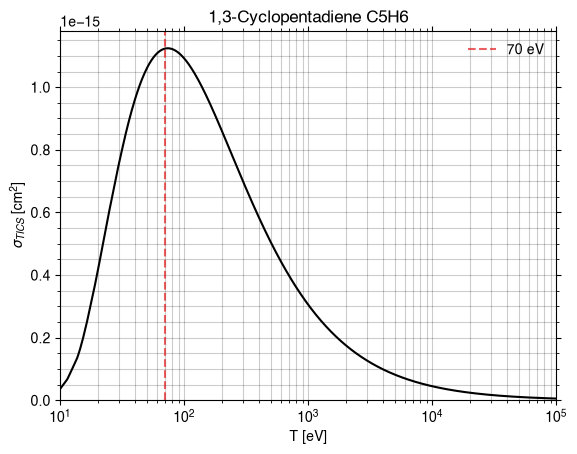

Compound(6403)
Recherche : '2,2-Dimethylbutane' -> CID 6403, formule C6H14
3D
strucutre 3D
Réussite. Nom: 2,2-Dimethylbutane, formule: C6H14, M: 86.18, nom_marche: 2_2-Dimethylbutane
PYSCF CONVERGENCE
converged SCF energy = -235.451626820937
**** MO energy ****
MO #1   energy= -11.2299983691415  occ= 2
MO #2   energy= -11.2136106670275  occ= 2
MO #3   energy= -11.2076514451091  occ= 2
MO #4   energy= -11.207613791191   occ= 2
MO #5   energy= -11.2066622530743  occ= 2
MO #6   energy= -11.2051469711156  occ= 2
MO #7   energy= -1.10476376085762  occ= 2
MO #8   energy= -0.996575208054669 occ= 2
MO #9   energy= -0.925670350647277 occ= 2
MO #10  energy= -0.924028259974502 occ= 2
MO #11  energy= -0.847473107665589 occ= 2
MO #12  energy= -0.72222371588694  occ= 2
MO #13  energy= -0.623325784817131 occ= 2
MO #14  energy= -0.620746511745063 occ= 2
MO #15  energy= -0.595067481943154 occ= 2
MO #16  energy= -0.581340404454467 occ= 2
MO #17  energy= -0.548381467094327 occ= 2
MO #18  energy= -0.52699

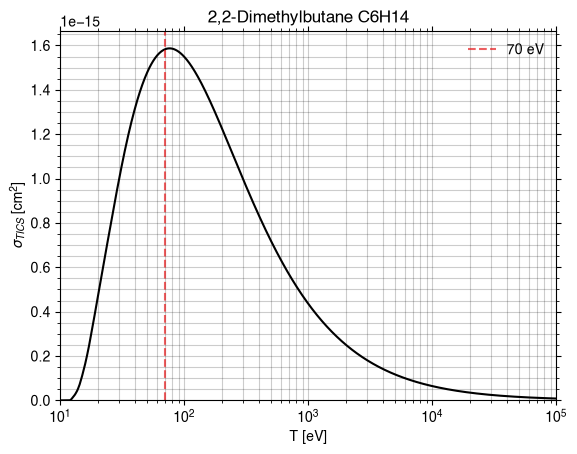

Compound(6589)
Recherche : '2,3-Dimethylbutane' -> CID 6589, formule C6H14
3D
strucutre 3D
Réussite. Nom: 2,3-Dimethylbutane, formule: C6H14, M: 86.18, nom_marche: 2_3-Dimethylbutane
PYSCF CONVERGENCE
converged SCF energy = -235.451345893523
**** MO energy ****
MO #1   energy= -11.2209110291752  occ= 2
MO #2   energy= -11.2203479489121  occ= 2
MO #3   energy= -11.2063499079551  occ= 2
MO #4   energy= -11.2063474602005  occ= 2
MO #5   energy= -11.206152441016   occ= 2
MO #6   energy= -11.206134473109   occ= 2
MO #7   energy= -1.09888272515134  occ= 2
MO #8   energy= -1.00923654533263  occ= 2
MO #9   energy= -0.92923550925874  occ= 2
MO #10  energy= -0.917404869150962 occ= 2
MO #11  energy= -0.832743112365264 occ= 2
MO #12  energy= -0.732516619350999 occ= 2
MO #13  energy= -0.640951864105027 occ= 2
MO #14  energy= -0.604962221083096 occ= 2
MO #15  energy= -0.603686248964246 occ= 2
MO #16  energy= -0.56092050237541  occ= 2
MO #17  energy= -0.551160492137145 occ= 2
MO #18  energy= -0.53761

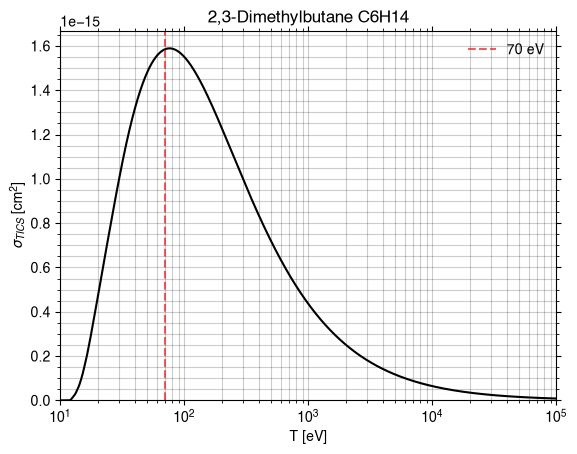

Compound(7892)
Recherche : '2-Methylpentane' -> CID 7892, formule C6H14
3D
strucutre 3D
Réussite. Nom: 2-Methylpentane, formule: C6H14, M: 86.18, nom_marche: 2-Methylpentane
PYSCF CONVERGENCE
converged SCF energy = -235.453132043746
**** MO energy ****
MO #1   energy= -11.2199128724392  occ= 2
MO #2   energy= -11.2121360699655  occ= 2
MO #3   energy= -11.2110664168451  occ= 2
MO #4   energy= -11.2068854513334  occ= 2
MO #5   energy= -11.206834021148   occ= 2
MO #6   energy= -11.2050400559767  occ= 2
MO #7   energy= -1.09309844404571  occ= 2
MO #8   energy= -1.02786874200099  occ= 2
MO #9   energy= -0.923301402954378 occ= 2
MO #10  energy= -0.915068414515249 occ= 2
MO #11  energy= -0.808384635937234 occ= 2
MO #12  energy= -0.758881552806525 occ= 2
MO #13  energy= -0.643049921700982 occ= 2
MO #14  energy= -0.60653643269946  occ= 2
MO #15  energy= -0.600961208138106 occ= 2
MO #16  energy= -0.572625990010958 occ= 2
MO #17  energy= -0.54784929691402  occ= 2
MO #18  energy= -0.53222909950578

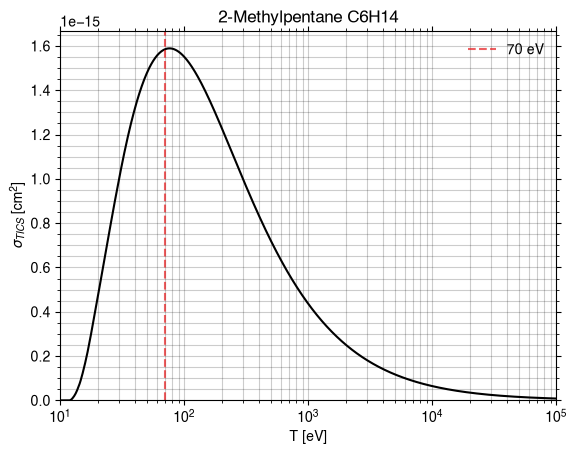

Compound(8058)
Recherche : 'Hexane' -> CID 8058, formule C6H14
3D
strucutre 3D
Réussite. Nom: Hexane, formule: C6H14, M: 86.18, nom_marche: Hexane
PYSCF CONVERGENCE
converged SCF energy = -235.455766459331
**** MO energy ****
MO #1   energy= -11.2117109041407  occ= 2
MO #2   energy= -11.2116769475244  occ= 2
MO #3   energy= -11.210352799096   occ= 2
MO #4   energy= -11.2097550920892  occ= 2
MO #5   energy= -11.2062789007546  occ= 2
MO #6   energy= -11.2062686518689  occ= 2
MO #7   energy= -1.0851401298949   occ= 2
MO #8   energy= -1.03637391684486  occ= 2
MO #9   energy= -0.959138863733514 occ= 2
MO #10  energy= -0.866200605278124 occ= 2
MO #11  energy= -0.793158748296541 occ= 2
MO #12  energy= -0.784152566654148 occ= 2
MO #13  energy= -0.652165217860926 occ= 2
MO #14  energy= -0.610551194852064 occ= 2
MO #15  energy= -0.592590132792957 occ= 2
MO #16  energy= -0.577711388805147 occ= 2
MO #17  energy= -0.552699692944271 occ= 2
MO #18  energy= -0.524446238504869 occ= 2
MO #19  energy= -0

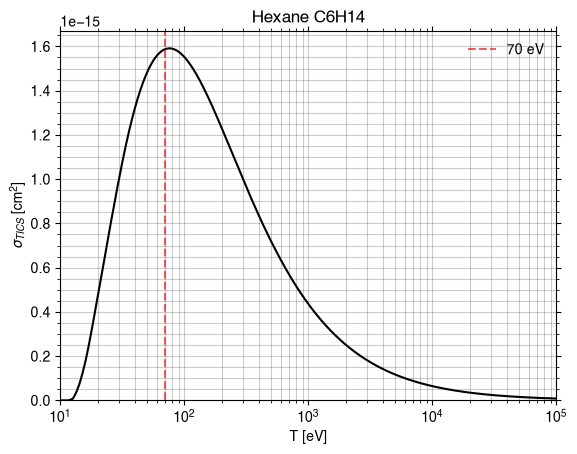

Compound(11597)
Recherche : '1-Hexene' -> CID 11597, formule C6H12
3D
strucutre 3D
Réussite. Nom: 1-Hexene, formule: C6H12, M: 84.16, nom_marche: 1-Hexene
PYSCF CONVERGENCE
converged SCF energy = -234.26488293006
**** MO energy ****
MO #1   energy= -11.2293012166889  occ= 2
MO #2   energy= -11.221383215262   occ= 2
MO #3   energy= -11.217127593736   occ= 2
MO #4   energy= -11.2157884093722  occ= 2
MO #5   energy= -11.2155065503894  occ= 2
MO #6   energy= -11.2093159009103  occ= 2
MO #7   energy= -1.09260752822467  occ= 2
MO #8   energy= -1.04239062268583  occ= 2
MO #9   energy= -0.965234883440239 occ= 2
MO #10  energy= -0.865416450211896 occ= 2
MO #11  energy= -0.792673497010618 occ= 2
MO #12  energy= -0.754047594947568 occ= 2
MO #13  energy= -0.653393657817421 occ= 2
MO #14  energy= -0.622758031515829 occ= 2
MO #15  energy= -0.59463445381893  occ= 2
MO #16  energy= -0.584052528533448 occ= 2
MO #17  energy= -0.551914364921599 occ= 2
MO #18  energy= -0.534722582919015 occ= 2
MO #19  ene

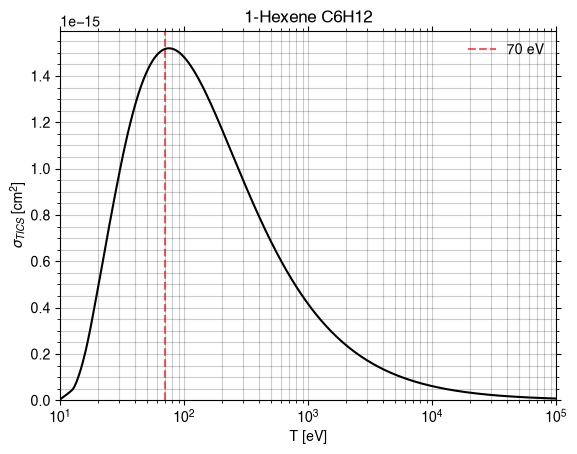

Compound(12986)
Recherche : '2-Methyl-1-Pentene' -> CID 12986, formule C6H12
3D
strucutre 3D
Réussite. Nom: 2-Methyl-1-Pentene, formule: C6H12, M: 84.16, nom_marche: 2-Methyl-1-Pentene
PYSCF CONVERGENCE
converged SCF energy = -234.267364608347
**** MO energy ****
MO #1   energy= -11.2349371351543  occ= 2
MO #2   energy= -11.2210367188314  occ= 2
MO #3   energy= -11.2186114714089  occ= 2
MO #4   energy= -11.2178604061956  occ= 2
MO #5   energy= -11.2110884374206  occ= 2
MO #6   energy= -11.2068636376107  occ= 2
MO #7   energy= -1.10123375603548  occ= 2
MO #8   energy= -1.03431308674246  occ= 2
MO #9   energy= -0.933181341203428 occ= 2
MO #10  energy= -0.91793973684224  occ= 2
MO #11  energy= -0.808359304686064 occ= 2
MO #12  energy= -0.716560827099848 occ= 2
MO #13  energy= -0.64000163522283  occ= 2
MO #14  energy= -0.623972872040239 occ= 2
MO #15  energy= -0.589892259442986 occ= 2
MO #16  energy= -0.58065052680998  occ= 2
MO #17  energy= -0.562438309309359 occ= 2
MO #18  energy= -0.529

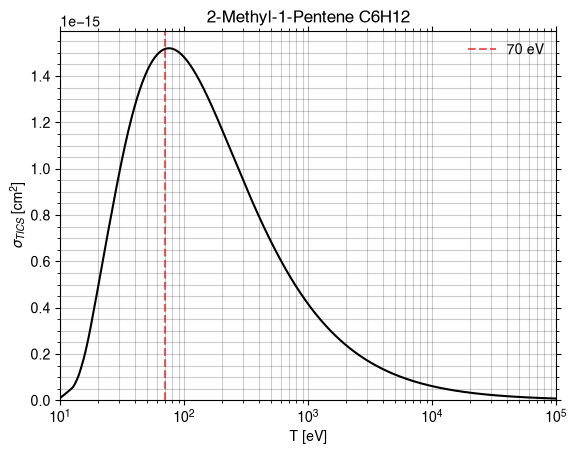

Compound(12243)
Recherche : '2-Methyl-2-Pentene' -> CID 12243, formule C6H12
3D
strucutre 3D
Réussite. Nom: 2-Methyl-2-Pentene, formule: C6H12, M: 84.16, nom_marche: 2-Methyl-2-Pentene
PYSCF CONVERGENCE
converged SCF energy = -234.266313672897
**** MO energy ****
MO #1   energy= -11.2283937716833  occ= 2
MO #2   energy= -11.2178430942021  occ= 2
MO #3   energy= -11.2165567213671  occ= 2
MO #4   energy= -11.213084880737   occ= 2
MO #5   energy= -11.2106489103151  occ= 2
MO #6   energy= -11.209751382908   occ= 2
MO #7   energy= -1.09760747222107  occ= 2
MO #8   energy= -1.02910317753032  occ= 2
MO #9   energy= -0.935339373562422 occ= 2
MO #10  energy= -0.918611705518485 occ= 2
MO #11  energy= -0.824704724095771 occ= 2
MO #12  energy= -0.699417494798872 occ= 2
MO #13  energy= -0.639657904763087 occ= 2
MO #14  energy= -0.609485896318842 occ= 2
MO #15  energy= -0.590253072449412 occ= 2
MO #16  energy= -0.567288770076175 occ= 2
MO #17  energy= -0.550023840598918 occ= 2
MO #18  energy= -0.536

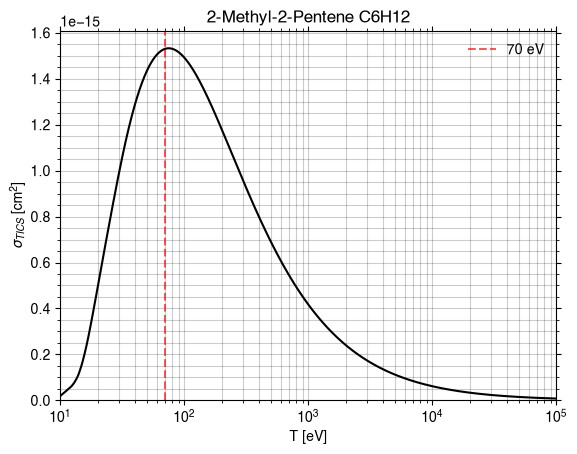

Compound(11210)
Recherche : '3,3-Dimethyl-1-Butene' -> CID 11210, formule C6H12
3D
strucutre 3D
Réussite. Nom: 3,3-Dimethyl-1-Butene, formule: C6H12, M: 84.16, nom_marche: 3_3-Dimethyl-1-Butene
PYSCF CONVERGENCE
converged SCF energy = -234.262730709084
**** MO energy ****
MO #1   energy= -11.2409588926084  occ= 2
MO #2   energy= -11.2300353671037  occ= 2
MO #3   energy= -11.2167534326225  occ= 2
MO #4   energy= -11.2127800115152  occ= 2
MO #5   energy= -11.2127354518382  occ= 2
MO #6   energy= -11.2121650346337  occ= 2
MO #7   energy= -1.1124433585339   occ= 2
MO #8   energy= -1.00600886235418  occ= 2
MO #9   energy= -0.929952780975787 occ= 2
MO #10  energy= -0.929304895487207 occ= 2
MO #11  energy= -0.816189485947344 occ= 2
MO #12  energy= -0.716387024489372 occ= 2
MO #13  energy= -0.64106748561511  occ= 2
MO #14  energy= -0.618053534125642 occ= 2
MO #15  energy= -0.596932429294384 occ= 2
MO #16  energy= -0.578843413173178 occ= 2
MO #17  energy= -0.540831421573651 occ= 2
MO #18  energ

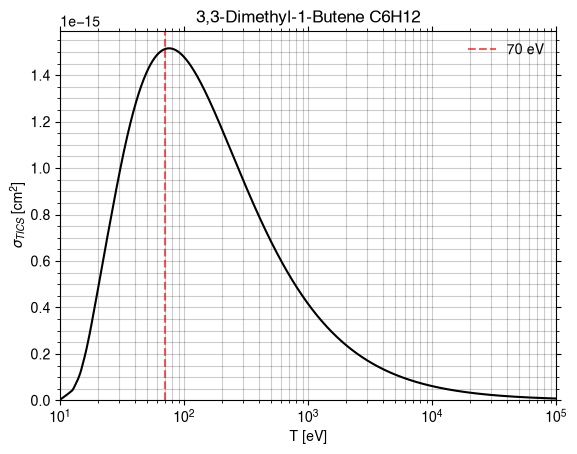

Compound(643783)
Recherche : 'Cis-3-Hexene' -> CID 643783, formule C6H12
3D
strucutre 3D
Réussite. Nom: Cis-3-Hexene, formule: C6H12, M: 84.16, nom_marche: Cis-3-Hexene
PYSCF CONVERGENCE
converged SCF energy = -234.261459827591
**** MO energy ****
MO #1   energy= -11.2197018229848  occ= 2
MO #2   energy= -11.2196643129283  occ= 2
MO #3   energy= -11.2182464219126  occ= 2
MO #4   energy= -11.2166328095324  occ= 2
MO #5   energy= -11.2117370366494  occ= 2
MO #6   energy= -11.2117335984718  occ= 2
MO #7   energy= -1.09547148751131  occ= 2
MO #8   energy= -1.03456333486242  occ= 2
MO #9   energy= -0.965809956622927 occ= 2
MO #10  energy= -0.869577938101408 occ= 2
MO #11  energy= -0.823262019877447 occ= 2
MO #12  energy= -0.71714049485028  occ= 2
MO #13  energy= -0.665771523734957 occ= 2
MO #14  energy= -0.606894723723587 occ= 2
MO #15  energy= -0.590134388135539 occ= 2
MO #16  energy= -0.569778664508994 occ= 2
MO #17  energy= -0.559504478600749 occ= 2
MO #18  energy= -0.521866480603    occ

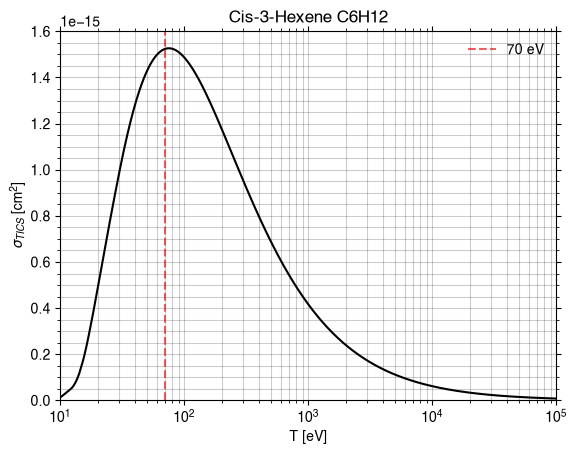

Compound(12724)
Recherche : '4-Methyl-1-Pentene' -> CID 12724, formule C6H12
3D
strucutre 3D
Réussite. Nom: 4-Methyl-1-Pentene, formule: C6H12, M: 84.16, nom_marche: 4-Methyl-1-Pentene
PYSCF CONVERGENCE
converged SCF energy = -234.263170680393
**** MO energy ****
MO #1   energy= -11.2301232849787  occ= 2
MO #2   energy= -11.2262390150762  occ= 2
MO #3   energy= -11.2214924269179  occ= 2
MO #4   energy= -11.2162043982648  occ= 2
MO #5   energy= -11.2107589010317  occ= 2
MO #6   energy= -11.2046650772548  occ= 2
MO #7   energy= -1.09989021039951  occ= 2
MO #8   energy= -1.03364651435687  occ= 2
MO #9   energy= -0.924140110788386 occ= 2
MO #10  energy= -0.921558050301883 occ= 2
MO #11  energy= -0.778500430222326 occ= 2
MO #12  energy= -0.752302742054344 occ= 2
MO #13  energy= -0.637279244802087 occ= 2
MO #14  energy= -0.627269783864948 occ= 2
MO #15  energy= -0.595938079094714 occ= 2
MO #16  energy= -0.58108378354678  occ= 2
MO #17  energy= -0.552744150233208 occ= 2
MO #18  energy= -0.533

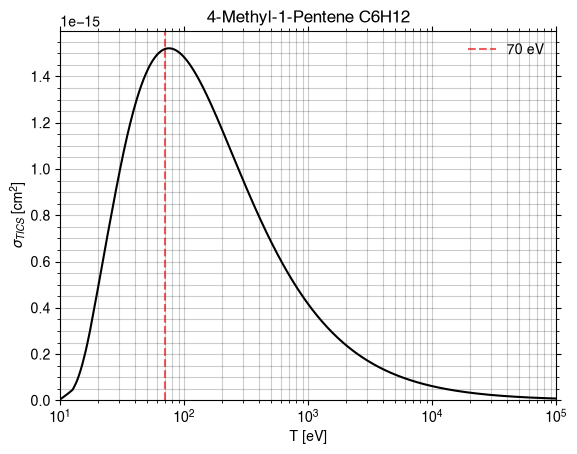

Compound(8078)
Recherche : 'Cyclohexane' -> CID 8078, formule C6H12
3D
strucutre 3D
Réussite. Nom: Cyclohexane, formule: C6H12, M: 84.16, nom_marche: Cyclohexane
PYSCF CONVERGENCE
converged SCF energy = -234.29197565943
**** MO energy ****
MO #1   energy= -11.2102918281517  occ= 2
MO #2   energy= -11.2100040192729  occ= 2
MO #3   energy= -11.2099969788491  occ= 2
MO #4   energy= -11.2093789745182  occ= 2
MO #5   energy= -11.2093714302608  occ= 2
MO #6   energy= -11.209053245387   occ= 2
MO #7   energy= -1.11142935399742  occ= 2
MO #8   energy= -0.999099967920321 occ= 2
MO #9   energy= -0.999059834701221 occ= 2
MO #10  energy= -0.824793903739784 occ= 2
MO #11  energy= -0.824776914843089 occ= 2
MO #12  energy= -0.744664833760499 occ= 2
MO #13  energy= -0.645009548235517 occ= 2
MO #14  energy= -0.605569669900157 occ= 2
MO #15  energy= -0.595242085004875 occ= 2
MO #16  energy= -0.595234535107028 occ= 2
MO #17  energy= -0.520516364896884 occ= 2
MO #18  energy= -0.520473720234273 occ= 2
MO #

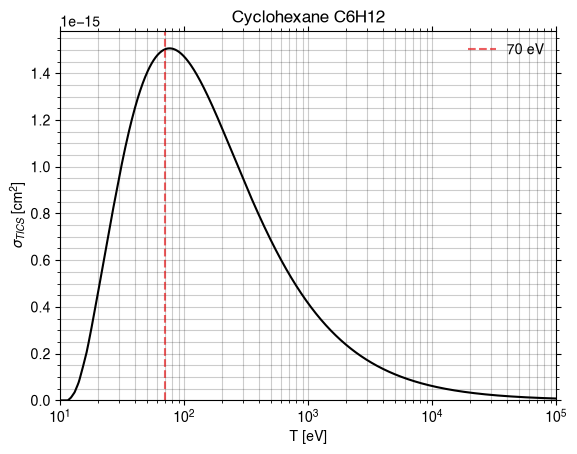

Compound(7296)
Recherche : 'Methylcyclopentane' -> CID 7296, formule C6H12
3D
strucutre 3D
Réussite. Nom: Methylcyclopentane, formule: C6H12, M: 84.16, nom_marche: Methylcyclopentane
PYSCF CONVERGENCE
converged SCF energy = -234.282682716012
**** MO energy ****
MO #1   energy= -11.214458862028   occ= 2
MO #2   energy= -11.2068970304925  occ= 2
MO #3   energy= -11.2066384484987  occ= 2
MO #4   energy= -11.2062218245637  occ= 2
MO #5   energy= -11.2059096980332  occ= 2
MO #6   energy= -11.2057340458614  occ= 2
MO #7   energy= -1.12804660260848  occ= 2
MO #8   energy= -1.0041323925366   occ= 2
MO #9   energy= -0.958970110369609 occ= 2
MO #10  energy= -0.885511677480096 occ= 2
MO #11  energy= -0.764671289336319 occ= 2
MO #12  energy= -0.75933449999228  occ= 2
MO #13  energy= -0.654853178821075 occ= 2
MO #14  energy= -0.624740580798829 occ= 2
MO #15  energy= -0.588098323015666 occ= 2
MO #16  energy= -0.577110018845141 occ= 2
MO #17  energy= -0.551726290396801 occ= 2
MO #18  energy= -0.51881

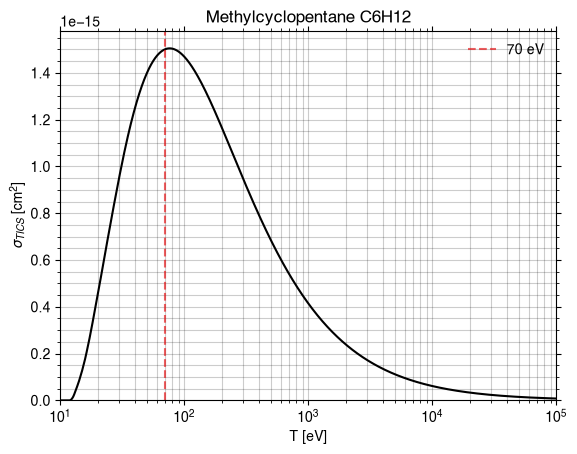

Compound(639661)
Recherche : 'Trans-2-Hexene' -> CID 639661, formule C6H12
3D
strucutre 3D
Réussite. Nom: Trans-2-Hexene, formule: C6H12, M: 84.16, nom_marche: Trans-2-Hexene
PYSCF CONVERGENCE
converged SCF energy = -234.268299642524
**** MO energy ****
MO #1   energy= -11.2207714531048  occ= 2
MO #2   energy= -11.2178148627565  occ= 2
MO #3   energy= -11.2171027673349  occ= 2
MO #4   energy= -11.21517551782    occ= 2
MO #5   energy= -11.2148009435929  occ= 2
MO #6   energy= -11.2082968143149  occ= 2
MO #7   energy= -1.08993159199471  occ= 2
MO #8   energy= -1.04021896111758  occ= 2
MO #9   energy= -0.961777146455944 occ= 2
MO #10  energy= -0.878564421446271 occ= 2
MO #11  energy= -0.797699069320274 occ= 2
MO #12  energy= -0.745827965900066 occ= 2
MO #13  energy= -0.635183707973515 occ= 2
MO #14  energy= -0.617317507761992 occ= 2
MO #15  energy= -0.586583107715612 occ= 2
MO #16  energy= -0.568385308362762 occ= 2
MO #17  energy= -0.560025193166194 occ= 2
MO #18  energy= -0.5309058007791

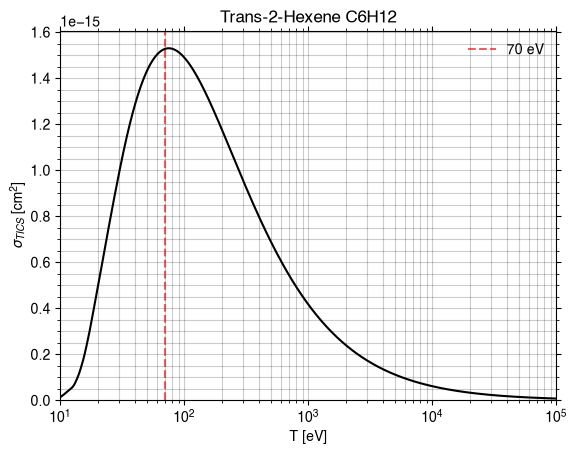

Dimethylbutadiene not found : IndexError : list index out of range
Dimethylbutadiene a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(8079)
Recherche : 'Cyclohexene' -> CID 8079, formule C6H10
3D
strucutre 3D
Réussite. Nom: Cyclohexene, formule: C6H10, M: 82.14, nom_marche: Cyclohexene
PYSCF CONVERGENCE
converged SCF energy = -233.103885921118
**** MO energy ****
MO #1   energy= -11.2188200046624  occ= 2
MO #2   energy= -11.2183707595821  occ= 2
MO #3   energy= -11.2180735129867  occ= 2
MO #4   energy= -11.2168620576731  occ= 2
MO #5   energy= -11.215307345996   occ= 2
MO #6   energy= -11.2146880742812  occ= 2
MO #7   energy= -1.11672364600895  occ= 2
MO #8   energy= -1.00303617799586  occ= 2
MO #9   energy= -1.00123288429924  occ= 2
MO #10  energy= -0.843390173448366 occ= 2
MO #11  energy= -0.814796995586811 occ= 2
MO #12  energy= -0.694558595797652 occ= 2
MO #13  energy= -0.664708413865444 occ= 2
MO #14  energy= -0.614609690307734 occ= 2
MO #15  energy= -0.5

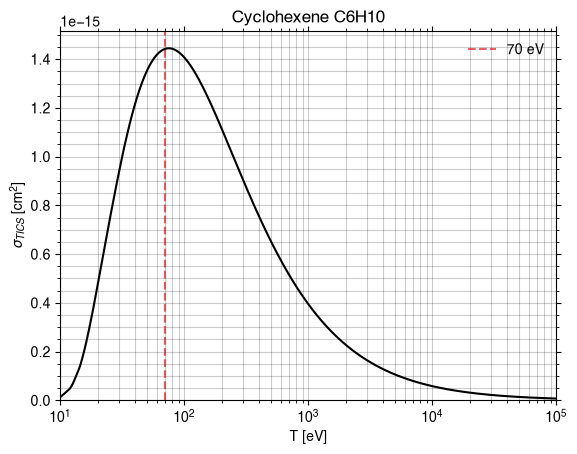

Compound(69402)
Recherche : 'Bipropargyl' -> CID 69402, formule C6H6
3D
strucutre 3D
Réussite. Nom: Bipropargyl, formule: C6H6, M: 78.11, nom_marche: Bipropargyl
PYSCF CONVERGENCE

WARN: 2 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -230.658751226741
**** MO energy ****
MO #1   energy= -11.2659279747645  occ= 2
MO #2   energy= -11.2653235521893  occ= 2
MO #3   energy= -11.2389895517011  occ= 2
MO #4   energy= -11.2389807333893  occ= 2
MO #5   energy= -11.2262478156918  occ= 2
MO #6   energy= -11.2262394118626  occ= 2
MO #7   energy= -1.11011674644975  occ= 2
MO #8   energy= -1.04135546591572  occ= 2
MO #9   energy= -0.99204168047995  occ= 2
MO #10  energy= -0.899535459536462 occ= 2
MO #11  energy= -0.728517368838755 occ= 2
MO #12  energy= -0.721315228472197 occ= 2
MO #13  energy= -0.663508413599212 occ= 2
MO #14  energy= -0.651542213452548 occ= 2
MO #15  energy= -0.599463209480692 occ= 2
MO #16  energy= -0.562052570987

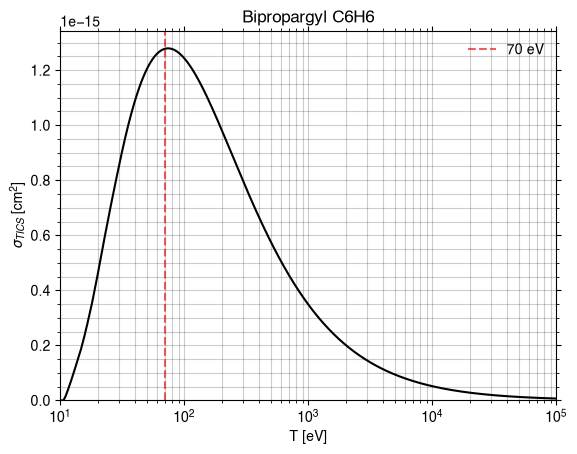

Compound(137727)
Recherche : 'Dimethylbutadiyne' -> CID 137727, formule C6H6
3D
strucutre 3D
Réussite. Nom: Dimethylbutadiyne, formule: C6H6, M: 78.11, nom_marche: Dimethylbutadiyne
PYSCF CONVERGENCE

WARN: 3 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -230.678381500667
**** MO energy ****
MO #1   energy= -11.252969047635   occ= 2
MO #2   energy= -11.2529668760193  occ= 2
MO #3   energy= -11.2405575734825  occ= 2
MO #4   energy= -11.2404607341173  occ= 2
MO #5   energy= -11.2343664437116  occ= 2
MO #6   energy= -11.2332508095354  occ= 2
MO #7   energy= -1.08636882887853  occ= 2
MO #8   energy= -1.05295848723063  occ= 2
MO #9   energy= -0.992133428754698 occ= 2
MO #10  energy= -0.943109169566227 occ= 2
MO #11  energy= -0.793874737376481 occ= 2
MO #12  energy= -0.638088664062539 occ= 2
MO #13  energy= -0.62608284640653  occ= 2
MO #14  energy= -0.595317671134677 occ= 2
MO #15  energy= -0.59528566158341  occ= 2
MO #16  ene

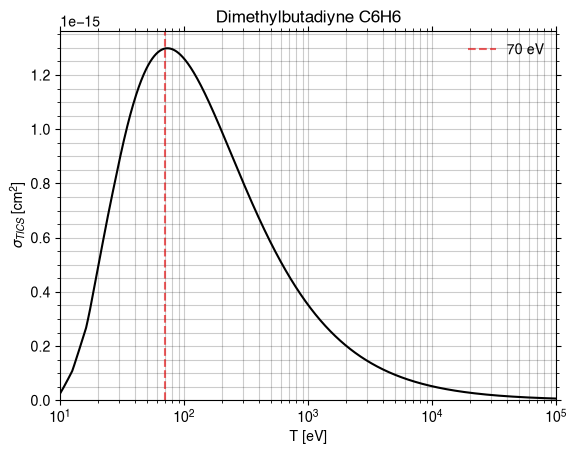

Compound(241)
Recherche : 'Benzene' -> CID 241, formule C6H6
3D
strucutre 3D
Réussite. Nom: Benzene, formule: C6H6, M: 78.11, nom_marche: Benzene
PYSCF CONVERGENCE

WARN: 2 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -230.786253319574
**** MO energy ****
MO #1   energy= -11.2359358452905  occ= 2
MO #2   energy= -11.2353666894136  occ= 2
MO #3   energy= -11.2353611710361  occ= 2
MO #4   energy= -11.2341313831815  occ= 2
MO #5   energy= -11.2341253235775  occ= 2
MO #6   energy= -11.233522353948   occ= 2
MO #7   energy= -1.14908963757251  occ= 2
MO #8   energy= -1.01348878567808  occ= 2
MO #9   energy= -1.01346264881332  occ= 2
MO #10  energy= -0.822750529861111 occ= 2
MO #11  energy= -0.822721755967194 occ= 2
MO #12  energy= -0.707965736842155 occ= 2
MO #13  energy= -0.642170139568104 occ= 2
MO #14  energy= -0.618816744565716 occ= 2
MO #15  energy= -0.586887320045199 occ= 2
MO #16  energy= -0.586871376442206 occ= 2
MO #1

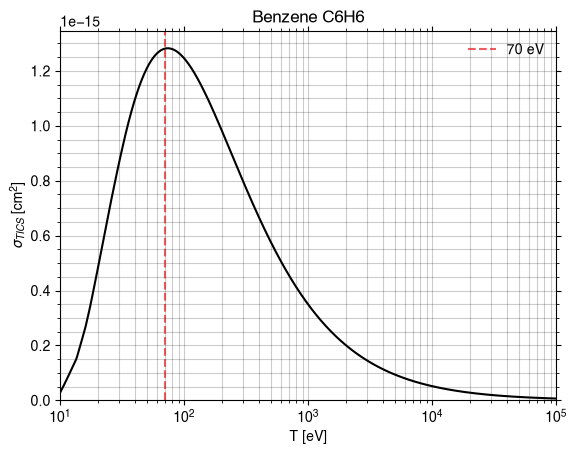

Compound(23953)
Recherche : 'Silane' -> CID 23953, formule H4Si
3D
strucutre 3D
Réussite. Nom: Silane, formule: H4Si, M: 32.117, nom_marche: Silane
PYSCF CONVERGENCE
converged SCF energy = -6.08242215402854
**** MO energy ****
MO #1   energy= -0.732259968656982 occ= 2
MO #2   energy= -0.485659430887658 occ= 2
MO #3   energy= -0.485649460920551 occ= 2
MO #4   energy= -0.485640244333624 occ= 2
MO #5   energy= 0.0566569841811188 occ= 0
MO #6   energy= 0.0566574009487465 occ= 0
MO #7   energy= 0.0566574304446448 occ= 0
MO #8   energy= 0.0831483328254483 occ= 0
MO #9   energy= 0.130046502598147  occ= 0
MO #10  energy= 0.130049593769045  occ= 0
MO #11  energy= 0.130051774234422  occ= 0
MO #12  energy= 0.145475191487864  occ= 0
MO #13  energy= 0.145477804288221  occ= 0
MO #14  energy= 0.223397281814344  occ= 0
MO #15  energy= 0.223400511804566  occ= 0
MO #16  energy= 0.223402736731907  occ= 0
MO #17  energy= 0.256210441070622  occ= 0
MO #18  energy= 0.272625924239901  occ= 0
MO #19  energy= 0

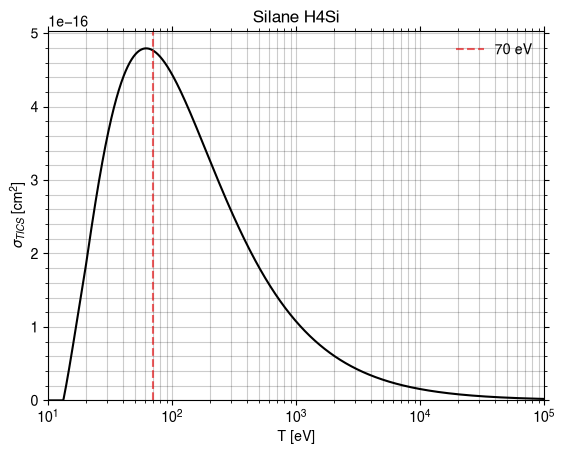

Compound(74123)
Recherche : 'Disilane' -> CID 74123, formule H6Si2
3D
strucutre 3D
Réussite. Nom: Disilane, formule: H6Si2, M: 62.22, nom_marche: Disilane
PYSCF CONVERGENCE
converged SCF energy = -11.0125569575651
**** MO energy ****
MO #1   energy= -0.765758560193246 occ= 2
MO #2   energy= -0.678125713830323 occ= 2
MO #3   energy= -0.502547601977056 occ= 2
MO #4   energy= -0.502540223848529 occ= 2
MO #5   energy= -0.47242489757295  occ= 2
MO #6   energy= -0.472417265419797 occ= 2
MO #7   energy= -0.406083386513165 occ= 2
MO #8   energy= 0.0430569124862072 occ= 0
MO #9   energy= 0.0567272680151758 occ= 0
MO #10  energy= 0.0567276699525244 occ= 0
MO #11  energy= 0.0634542103936863 occ= 0
MO #12  energy= 0.0711544740216177 occ= 0
MO #13  energy= 0.0711545729193802 occ= 0
MO #14  energy= 0.0786332725409622 occ= 0
MO #15  energy= 0.117180328683784  occ= 0
MO #16  energy= 0.117181547474881  occ= 0
MO #17  energy= 0.123398060620773  occ= 0
MO #18  energy= 0.123401353874278  occ= 0
MO #19  en

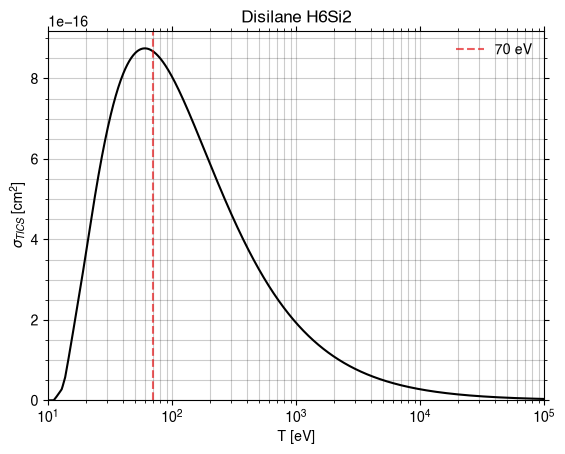

Compound(23984)
Recherche : 'Germane' -> CID 23984, formule GeH4


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [GeH4]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
5
4
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Germane, formule: GeH4, M: 76.66, nom_marche: Germane
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Ge  -0.003606  -0.011905  -0.029381    0.000000  0.000000  0.000000
   H   1.237456  -0.388788  -0.867605    0.000000  0.000000  0.000000
   H  -0.480722   1.430890  -0.330640    0.000000  0.000000  0.000000
   H  -1.182328  -0.985890  -0.232422    0.000000  0.000000  0.000000
   H   0.429200  -0.044307   1.460048    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -6.01660664269633
--------------- RHF_Scanner gradients ------

Step    0 : Gradient = 9.318e-03/1.016e-02 (rms/max) Energy = -6.0166066427
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.60000e-01 1.60000e-01 1.60000e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Ge  -0.000202  -0.002846  -0.005630    0.003404  0.009059  0.023751
   H   1.187658  -0.377676  -0.867138   -0.049798  0.011112  0.000467
   H  -0.462594   1.401218  -0.343530    0.018128 -0.029672 -0.012890
   H  -1.142778  -0.970195  -0.238389    0.039550  0.015695 -0.005967
   H   0.417916  -0.050502   1.454688   -0.011284 -0.006195 -0.005360
converged SCF energy = -6.01794356825066
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Ge    -0.0001657057    -0.0010189634    -0.0025986562
1 H    -0.0012964202     0.0006622846     0.0020366403
2 H     0.0001688762    -0.0017661604     0.0008923125
3 H     0.0011810769     0.0018682467     0.0005893732
4 H     0.0001121729     0.0002545924    -0.0009196697
----------------------------------------------
cycle 2: E = -6.01794356825  dE = -0.00133693  norm(grad) =

Step    1 : Displace = 3.654e-02/5.102e-02 (rms/max) Trust = 1.000e-01 (=) Grad = 2.199e-03/2.796e-03 (rms/max) E (change) = -6.0179435683 (-1.337e-03) Quality = 0.934
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.60000e-01 1.60000e-01 1.89911e-01


... (3 outputs left out)

Step    3 : Displace = 1.717e-03/2.139e-03 (rms/max) Trust = 2.000e-01 (+) Grad = 4.007e-05/5.729e-05 (rms/max) E (change) = -6.0180093548 (-1.564e-06) Quality = 1.097
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.60000e-01 1.60120e-01 1.96509e-01



Geometry optimization cycle 5
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Ge   0.000003   0.000024   0.000051   -0.000027 -0.000016 -0.000088
   H   1.184830  -0.378336  -0.876213   -0.000153  0.000067 -0.000245
   H  -0.458665   1.408385  -0.347682    0.000349  0.000156  0.000113
   H  -1.140455  -0.978192  -0.239212    0.000196 -0.000287  0.000186
   H   0.414287  -0.051882   1.463057   -0.000366  0.000079  0.000034
converged SCF energy = -6.01800941087673
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Ge     0.0000014511     0.0000075103     0.0000194642
1 H     0.0000040041    -0.0000038151    -0.0000032782
2 H    -0.0000053919     0.0000009852    -0.0000069036
3 H    -0.0000042612    -0.0000011171    -0.0000065295
4 H     0.0000041980    -0.0000035633    -0.0000027529
----------------------------------------------
cycle 5: E = -6.01800941088  dE = -5.60281e-08  norm(grad) 

Step    4 : Displace = 3.323e-04/3.977e-04 (rms/max) Trust = 2.828e-01 (+) Grad = 1.146e-05/2.091e-05 (rms/max) E (change) = -6.0180094109 (-5.603e-08) Quality = 1.159
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.60000e-01 1.60120e-01 1.96509e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 27.107 seconds
  frame 120/120xyz/Germane_GeH4.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Germane_

converged SCF energy = -6.0180094108791
**** MO energy ****
MO #1   energy= -0.746125789119395 occ= 2
MO #2   energy= -0.472478966794632 occ= 2
MO #3   energy= -0.472457973740206 occ= 2
MO #4   energy= -0.472453207847245 occ= 2
MO #5   energy= 0.0414799795271093 occ= 0
MO #6   energy= 0.0414800201157176 occ= 0
MO #7   energy= 0.0414800897286254 occ= 0
MO #8   energy= 0.0664243132130555 occ= 0
MO #9   energy= 0.12551457017267   occ= 0
MO #10  energy= 0.125515912945947  occ= 0
MO #11  energy= 0.125523820328258  occ= 0
MO #12  energy= 0.147063135533165  occ= 0
MO #13  energy= 0.147066616419685  occ= 0
MO #14  energy= 0.174603842402341  occ= 0
MO #15  energy= 0.174606189878876  occ= 0
MO #16  energy= 0.174606910192566  occ= 0
MO #17  energy= 0.231598086144815  occ= 0
MO #18  energy= 0.26629967465707   occ= 0
MO #19  energy= 0.266301227966701  occ= 0
MO #20  energy= 0.26630883994667   occ= 0
MO #21  energy= 0.31463002808274   occ= 0
MO #22  energy= 0.314636369377954  occ= 0
MO #23  energy= 

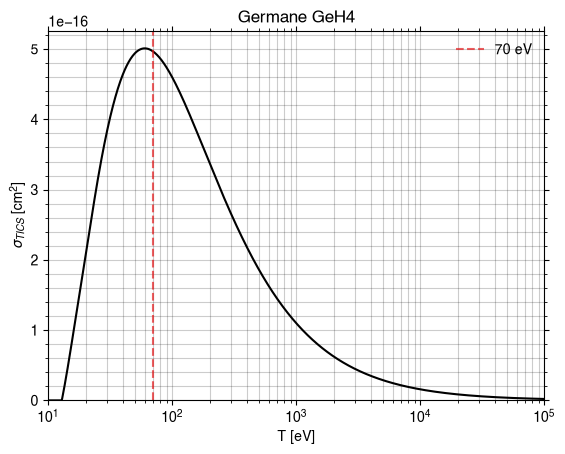

Compound(24404)
Recherche : 'Phosphine' -> CID 24404, formule H3P


Loading output/xyz/Phosphine_H3P.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Phosphine_H3P.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Phosphine_H3P.gifGIF written to output/gif/Phosphine_H3P.gif

strucutre 3D
Réussite. Nom: Phosphine, formule: H3P, M: 33.998, nom_marche: Phosphine
PYSCF CONVERGENCE
converged SCF energy = -8.11331595031855
**** MO energy ****
MO #1   energy= -0.859066499511553 occ= 2
MO #2   energy= -0.524320550507412 occ= 2
MO #3   energy= -0.524313328177595 occ= 2
MO #4   energy= -0.384712675743942 occ= 2
MO #5   energy= 0.0717228534818941 occ= 0
MO #6   energy= 0.0717230803296649 occ= 0
MO #7   energy= 0.0776568444952347 occ= 0
MO #8   energy= 0.0876040472083581 occ= 0
MO #9   energy= 0.131778020122183  occ= 0
MO #10  energy= 0.13178012335786   occ= 0
MO #11  energy= 0.205496466308706  occ= 0
MO #12  energy= 0.205497340617573  occ= 0
MO #13  energy= 0.207056128177175  occ= 0
MO #14  energy= 0.27156592391031   occ= 0
MO #15  energy= 0.271569095332326  occ= 0
MO #16  energy= 0.307047322556942  occ= 0
MO #17  energy= 0.314680553299221  occ= 0
MO #18  energy= 0.314681525803225  occ= 0
MO #19  energy= 0.328169379229873  occ= 0
MO #20  energy= 0.335335058525522  oc

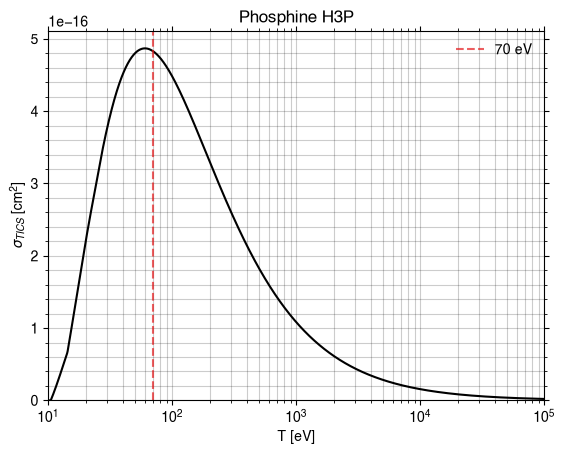

Compound(23969)
Recherche : 'Arsine' -> CID 23969, formule AsH3


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [AsH3]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
4
3
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Arsine, formule: AsH3, M: 77.946, nom_marche: Arsine
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  As  -0.012443   0.019151   0.378301    0.000000  0.000000  0.000000
   H  -0.074577   1.492739  -0.130584    0.000000  0.000000  0.000000
   H  -1.211179  -0.841389  -0.126374    0.000000  0.000000  0.000000
   H   1.298199  -0.670501  -0.121343    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -7.77302341014569
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 As    -0.00342

Step    0 : Gradient = 3.352e-02/3.441e-02 (rms/max) Energy = -7.7730234101
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.60000e-01 1.60000e-01 1.60000e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  As  -0.010765   0.016512   0.495379    0.001678 -0.002639  0.117078
   H  -0.071210   1.394196  -0.171314    0.003367 -0.098543 -0.040730
   H  -1.136205  -0.784360  -0.165413    0.074974  0.057029 -0.039039
   H   1.218180  -0.626348  -0.158652   -0.080019  0.044153 -0.037309
converged SCF energy = -7.79341478246057
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 As    -0.0024147369     0.0032686980    -0.0140207681
1 H     0.0002908522     0.0183820015     0.0058175047
2 H    -0.0128277060    -0.0122243775     0.0047681176
3 H     0.0149515907    -0.0094263220     0.0034351458
----------------------------------------------
cycle 2: E = -7.79341478246  dE = -0.0203914  norm(grad) = 0.0352966


Step    1 : Displace = 1.063e-01/1.171e-01 (rms/max) Trust = 1.000e-01 (=) Grad = 1.765e-02/1.928e-02 (rms/max) E (change) = -7.7934147825 (-2.039e-02) Quality = 0.862
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.58704e-01 1.60000e-01 2.61510e-01


... (5 outputs left out)

Step    4 : Displace = 3.257e-03/4.492e-03 (rms/max) Trust = 2.828e-01 (+) Grad = 8.901e-05/1.042e-04 (rms/max) E (change) = -7.8009552075 (-6.831e-06) Quality = 0.904
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.62757e-01 1.66302e-01 2.10659e-01



Geometry optimization cycle 6
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  As  -0.003136   0.004437   0.598025    0.000080 -0.000205 -0.000001
   H  -0.075300   1.267362  -0.209182   -0.000209  0.000030 -0.000044
   H  -1.059673  -0.702027  -0.199688   -0.000343  0.000226  0.000009
   H   1.138109  -0.569773  -0.189154    0.000472 -0.000050  0.000037
converged SCF energy = -7.8009552859042
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 As    -0.0000073184    -0.0000046155    -0.0000009005
1 H    -0.0000017394    -0.0000006809    -0.0000008220
2 H     0.0000045391     0.0000064146     0.0000037818
3 H     0.0000045188    -0.0000011182    -0.0000020593
----------------------------------------------
cycle 6: E = -7.8009552859  dE = -7.8358e-08  norm(grad) = 1.34833e-05


Step    5 : Displace = 3.490e-04/4.822e-04 (rms/max) Trust = 3.000e-01 (+) Grad = 6.742e-06/8.721e-06 (rms/max) E (change) = -7.8009552859 (-7.836e-08) Quality = 0.971
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.62757e-01 1.66302e-01 2.10659e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 21.136 seconds
  frame 120/120xyz/Arsine_AsH3.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Arsine_As

converged SCF energy = -7.800955285917
**** MO energy ****
MO #1   energy= -0.849555556305375 occ= 2
MO #2   energy= -0.502412789828135 occ= 2
MO #3   energy= -0.502407215898277 occ= 2
MO #4   energy= -0.376072921375522 occ= 2
MO #5   energy= 0.0683885344842748 occ= 0
MO #6   energy= 0.0917046278303895 occ= 0
MO #7   energy= 0.0917051715112253 occ= 0
MO #8   energy= 0.106564568571582  occ= 0
MO #9   energy= 0.122178876203512  occ= 0
MO #10  energy= 0.122180227482559  occ= 0
MO #11  energy= 0.174921031463354  occ= 0
MO #12  energy= 0.174921539162247  occ= 0
MO #13  energy= 0.177606665782612  occ= 0
MO #14  energy= 0.266646392752455  occ= 0
MO #15  energy= 0.266649491940828  occ= 0
MO #16  energy= 0.269314070250547  occ= 0
MO #17  energy= 0.305935417561458  occ= 0
MO #18  energy= 0.305936812163879  occ= 0
MO #19  energy= 0.326922827184575  occ= 0
MO #20  energy= 0.326925653611803  occ= 0
MO #21  energy= 0.334059143465159  occ= 0
MO #22  energy= 0.335849348896759  occ= 0
MO #23  energy= 0

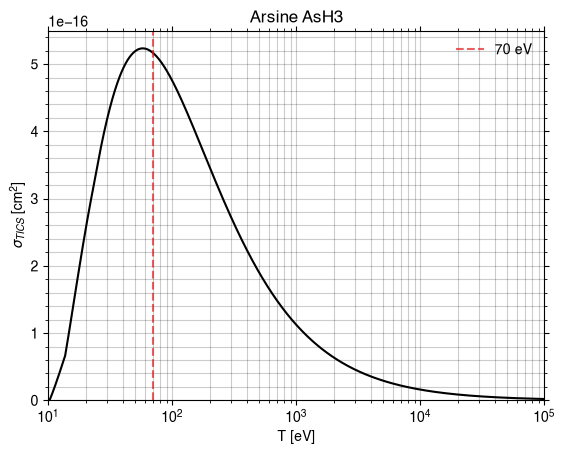

Compound(9359)
Recherche : 'Stibine' -> CID 9359, formule H3Sb


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [SbH3]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
4
3
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Stibine, formule: H3Sb, M: 124.784, nom_marche: Stibine
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Sb  -0.014856   0.013414   0.451877    0.000000  0.000000  0.000000
   H  -0.604770   1.567528  -0.154900    0.000000 -0.000000  0.000000
   H  -1.008814  -1.319196  -0.150394    0.000000  0.000000  0.000000
   H   1.628440  -0.261746  -0.146584    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -388.468671781998
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Sb    -1.63

Step    0 : Gradient = 4.690e+01/5.528e+01 (rms/max) Energy = -388.4686717820
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.60000e-01 1.60000e-01 1.60000e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Sb  -0.012243   0.010913   0.329285    0.002613 -0.002501 -0.122592
   H  -0.574677   1.484755  -0.113435    0.030093 -0.082773  0.041465
   H  -0.960082  -1.249152  -0.109546    0.048732  0.070044  0.040848
   H   1.547002  -0.246516  -0.106305   -0.081438  0.015230  0.040279
converged SCF energy = -426.000662375433
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Sb    -1.5866657544     1.7771786139    49.7681172905
1 H   -17.1201214296    45.1504120526   -16.6981695856
2 H   -28.9719356149   -38.9161366920   -16.6318106414
3 H    47.6787227988    -8.0114539745   -16.4381370635
----------------------------------------------
cycle 2: E = -426.000662375  dE = -37.532  norm(grad) = 101.642


Step    1 : Displace = 1.024e-01/1.226e-01 (rms/max) Trust = 1.000e-01 (=) Grad = 5.082e+01/5.129e+01 (rms/max) E (change) = -426.0006623754 (-3.753e+01) Quality = 1.070
Eigenvalues below 1.0000e-05 (-3.2914e+01) - returning guess
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.60000e-01 1.60000e-01 1.60000e-01


... (65 outputs left out)

Step   34 : Displace = 5.871e-05/7.721e-05 (rms/max) Trust = 1.000e-04 (-) Grad = 9.641e-04/1.447e-03 (rms/max) E (change) = -1264.3028404811 (-1.179e-05) Quality = 0.996
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.63694e+02 1.80336e+02 8.12086e+02



Geometry optimization cycle 36
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Sb   0.007144   0.008978  -0.000011    0.000001 -0.000002 -0.000001
   H  -0.122005   0.228909  -0.000339    0.000034  0.000015  0.000005
   H  -0.135609  -0.170430   0.000207   -0.000028  0.000023 -0.000009
   H   0.250470  -0.067457   0.000142   -0.000007 -0.000036  0.000005
converged SCF energy = -1264.30284048615
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Sb    -0.0001762678    -0.0000509013    -0.0002061695
1 H     0.0000813398    -0.0002733442     0.0000740422
2 H     0.0000372393     0.0002781818     0.0000585290
3 H     0.0000576886     0.0000460638     0.0000735983
----------------------------------------------
cycle 36: E = -1264.30284049  dE = -5.09431e-09  norm(grad) = 0.000506011


Step   35 : Displace = 2.920e-06/3.860e-06 (rms/max) Trust = 1.414e-04 (+) Grad = 2.530e-04/2.946e-04 (rms/max) E (change) = -1264.3028404861 (-5.094e-09) Quality = 0.740
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.63694e+02 1.80336e+02 8.12086e+02
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 56.069 seconds
  frame 120/120xyz/Stibine_H3Sb.xyzStated charge +0, but the bond orders give -6; formal

converged SCF energy = -1264.30284048767
**** MO energy ****
MO #1   energy= -81.5428010999712  occ= 2
MO #2   energy= -50.3846286363917  occ= 2
MO #3   energy= -48.7600404725805  occ= 2
MO #4   energy= -24.5655083589812  occ= 2
MO #5   energy= -19.4839125758778  occ= 2
MO #6   energy= -17.4852121981798  occ= 2
MO #7   energy= -13.8965731007889  occ= 2
MO #8   energy= -13.6605786550369  occ= 2
MO #9   energy= -13.596434173681   occ= 2
MO #10  energy= -8.52966442893163  occ= 2
MO #11  energy= -8.23639817980042  occ= 2
MO #12  energy= -7.52152169128504  occ= 2
MO #13  energy= -5.60101676061901  occ= 2
MO #14  energy= -3.46193346851903  occ= 2
MO #15  energy= -3.00154459681341  occ= 2
MO #16  energy= -2.82901350331846  occ= 2
MO #17  energy= -2.71852836290089  occ= 2
MO #18  energy= -2.69575314042326  occ= 2
MO #19  energy= -2.34780419743263  occ= 2
MO #20  energy= -2.00757946100307  occ= 2
MO #21  energy= -1.80667622923484  occ= 2
MO #22  energy= -1.48034218351129  occ= 2
MO #23  energy=

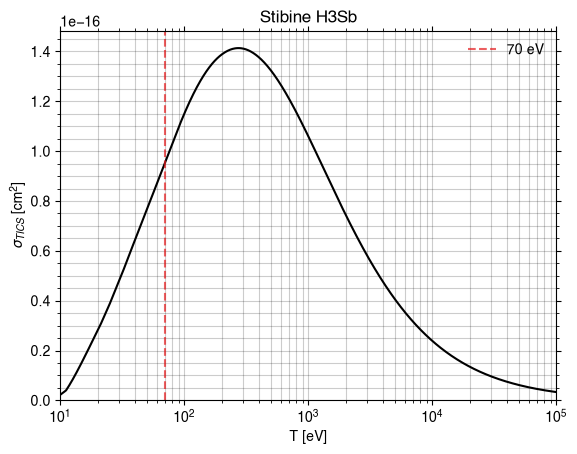

Compound(533)
Recherche : 'Hydrogen selenide' -> CID 533, formule H2Se


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [SeH2]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
3
2
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Hydrogen selenide, formule: H2Se, M: 80.99, nom_marche: Hydrogen_selenide
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Se  -0.002963   0.579226   0.000000    0.000000  0.000000  0.000000
   H  -1.261644  -0.290678   0.000000    0.000000  0.000000  0.000000
   H   1.264607  -0.288548   0.000000    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -10.3155325171317
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Se    -0.0015534907     0.0069334590    -0.0000000000
1 H    -0

Step    0 : Gradient = 3.216e-02/3.987e-02 (rms/max) Energy = -10.3155325171
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.53679e-01 1.56080e-01 1.60000e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Se  -0.001922   0.623438   0.000000    0.001041  0.044212  0.000000
   H  -1.145236  -0.313121  -0.000000    0.116408 -0.022443 -0.000000
   H   1.147158  -0.310317   0.000000   -0.117449 -0.021769  0.000000
converged SCF energy = -10.3275577199668
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Se    -0.0008475537     0.0040161382    -0.0000000000
1 H    -0.0178335915    -0.0016897414     0.0000000000
2 H     0.0186811451    -0.0023263969     0.0000000000
----------------------------------------------
cycle 2: E = -10.32755772  dE = -0.0120252  norm(grad) = 0.0263085


Step    1 : Displace = 1.005e-01/1.194e-01 (rms/max) Trust = 1.000e-01 (=) Grad = 1.519e-02/1.883e-02 (rms/max) E (change) = -10.3275577200 (-1.203e-02) Quality = 0.980
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.54395e-01 1.55462e-01 1.77508e-01


... (5 outputs left out)

Step    4 : Displace = 1.433e-03/1.977e-03 (rms/max) Trust = 2.828e-01 (+) Grad = 1.517e-04/2.076e-04 (rms/max) E (change) = -10.3306537528 (-4.128e-06) Quality = 0.882
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.54624e-01 1.73152e-01 2.46076e-01



Geometry optimization cycle 6
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Se  -0.001100   0.662344   0.000000   -0.000142  0.000482  0.000000
   H  -1.049610  -0.332842  -0.000000    0.000607 -0.000193  0.000000
   H   1.050711  -0.329502  -0.000000   -0.000465 -0.000289 -0.000000
converged SCF energy = -10.3306538983304
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Se    -0.0000361066    -0.0000033803    -0.0000000000
1 H     0.0000316897     0.0000186543    -0.0000000000
2 H     0.0000044169    -0.0000152740     0.0000000000
----------------------------------------------
cycle 6: E = -10.3306538983  dE = -1.45544e-07  norm(grad) = 5.40383e-05


Step    5 : Displace = 5.651e-04/6.281e-04 (rms/max) Trust = 3.000e-01 (+) Grad = 3.120e-05/3.677e-05 (rms/max) E (change) = -10.3306538983 (-1.455e-07) Quality = 0.880
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.54624e-01 1.73152e-01 2.46076e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 15.976 seconds
  frame 120/120xyz/Hydrogen_selenide_H2Se.xyzBuilt graph: 3 atoms, 2 bondsLoading output/x

converged SCF energy = -10.3306538983424
**** MO energy ****
MO #1   energy= -0.947831399299673 occ= 2
MO #2   energy= -0.561997147990348 occ= 2
MO #3   energy= -0.477333449309953 occ= 2
MO #4   energy= -0.359424951006327 occ= 2
MO #5   energy= 0.0601087172857826 occ= 0
MO #6   energy= 0.0660870566432268 occ= 0
MO #7   energy= 0.071965270533792  occ= 0
MO #8   energy= 0.0729331141694705 occ= 0
MO #9   energy= 0.120917010819414  occ= 0
MO #10  energy= 0.183492138722275  occ= 0
MO #11  energy= 0.204052450228256  occ= 0
MO #12  energy= 0.214627547471723  occ= 0
MO #13  energy= 0.218419355173606  occ= 0
MO #14  energy= 0.227898840068725  occ= 0
MO #15  energy= 0.290256112568866  occ= 0
MO #16  energy= 0.30906082390401   occ= 0
MO #17  energy= 0.323327580221252  occ= 0
MO #18  energy= 0.329914315648502  occ= 0
MO #19  energy= 0.343290078323853  occ= 0
MO #20  energy= 0.348243282752802  occ= 0
MO #21  energy= 0.35953829845375   occ= 0
MO #22  energy= 0.360264171942506  occ= 0
MO #23  energy=

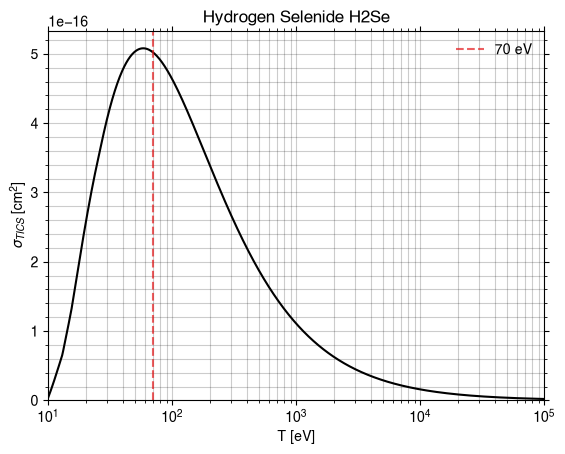

Compound(17601)
Recherche : 'Nitrosyl chloride' -> CID 17601, formule ClNO


Loading output/xyz/Nitrosyl_chloride_ClNO.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Nitrosyl_chloride_ClNO.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Nitrosyl_chloride_ClNO.gifGIF written to output/gif/Nitrosyl_chloride_ClNO.gif

strucutre 3D
Réussite. Nom: Nitrosyl chloride, formule: ClNO, M: 65.46, nom_marche: Nitrosyl_chloride
PYSCF CONVERGENCE
converged SCF energy = -143.967497121121
**** MO energy ****
MO #1   energy= -20.6916081307034  occ= 2
MO #2   energy= -15.8097221978354  occ= 2
MO #3   energy= -1.55619346611325  occ= 2
MO #4   energy= -1.19577132175962  occ= 2
MO #5   energy= -0.942197679304257 occ= 2
MO #6   energy= -0.72726734689887  occ= 2
MO #7   energy= -0.713263407895613 occ= 2
MO #8   energy= -0.651468734803956 occ= 2
MO #9   energy= -0.49341198984232  occ= 2
MO #10  energy= -0.490125749603969 occ= 2
MO #11  energy= -0.46668603732154  occ= 2
MO #12  energy= 0.0320751071702645 occ= 0
MO #13  energy= 0.0839741184544878 occ= 0
MO #14  energy= 0.0989199882974423 occ= 0
MO #15  energy= 0.112290778880779  occ= 0
MO #16  energy= 0.125126889290691  occ= 0
MO #17  energy= 0.131682408357119  occ= 0
MO #18  energy= 0.160129553840507  occ= 0
MO #19  energy= 0.160517510360986  occ= 0
MO #20  energy= 0.201

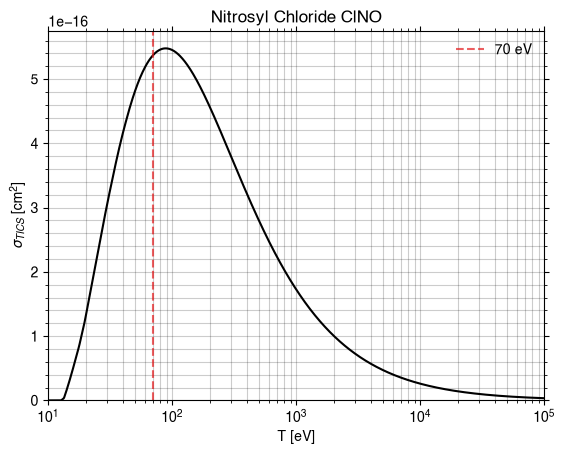

Compound(123261)
Recherche : 'Nitrosyl fluoride' -> CID 123261, formule FNO


Loading output/xyz/Nitrosyl_fluoride_FNO.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Nitrosyl_fluoride_FNO.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Nitrosyl_fluoride_FNO.gifGIF written to output/gif/Nitrosyl_fluoride_FNO.gif

strucutre 3D
Réussite. Nom: Nitrosyl fluoride, formule: FNO, M: 49.005, nom_marche: Nitrosyl_fluoride
PYSCF CONVERGENCE
converged SCF energy = -228.701839784355
**** MO energy ****
MO #1   energy= -26.3695196581168  occ= 2
MO #2   energy= -20.7068849146719  occ= 2
MO #3   energy= -15.8587929789162  occ= 2
MO #4   energy= -1.70785794282637  occ= 2
MO #5   energy= -1.52580814667831  occ= 2
MO #6   energy= -1.01145827639979  occ= 2
MO #7   energy= -0.794419146459591 occ= 2
MO #8   energy= -0.784899184672619 occ= 2
MO #9   energy= -0.756084252262127 occ= 2
MO #10  energy= -0.642260189253729 occ= 2
MO #11  energy= -0.599921675650947 occ= 2
MO #12  energy= -0.53073501431572  occ= 2
MO #13  energy= 0.0356182734535082 occ= 0
MO #14  energy= 0.0951018316562138 occ= 0
MO #15  energy= 0.101178295383616  occ= 0
MO #16  energy= 0.122196548296423  occ= 0
MO #17  energy= 0.122213791202302  occ= 0
MO #18  energy= 0.167978113548351  occ= 0
MO #19  energy= 0.170163607387684  occ= 0
MO #20  energy= 0.174

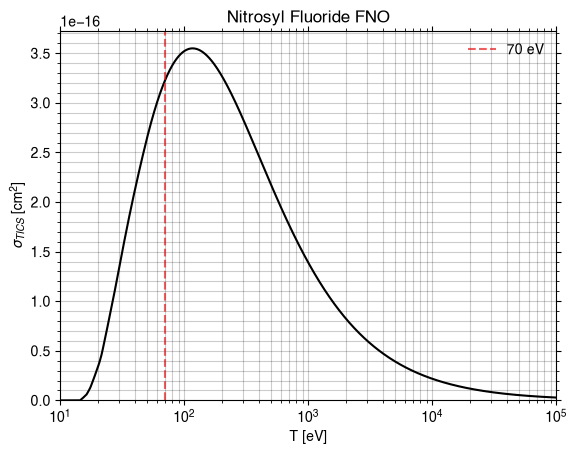

Compound(25352)
Recherche : 'Dinitrogen tetroxide' -> CID 25352, formule N2O4


Loading output/xyz/Dinitrogen_tetroxide_N2O4.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Dinitrogen_tetroxide_N2O4.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Dinitrogen_tetroxide_N2O4.gifGIF written to output/gif/Dinitrogen_tetroxide_N2O4.gif

strucutre 3D
Réussite. Nom: Dinitrogen tetroxide, formule: N2O4, M: 92.011, nom_marche: Dinitrogen_tetroxide
PYSCF CONVERGENCE
converged SCF energy = -408.183486753897
**** MO energy ****
MO #1   energy= -20.6918278856681  occ= 2
MO #2   energy= -20.6918193999112  occ= 2
MO #3   energy= -20.6917656865718  occ= 2
MO #4   energy= -20.6917595709648  occ= 2
MO #5   energy= -15.9573697896164  occ= 2
MO #6   energy= -15.9570060705193  occ= 2
MO #7   energy= -1.7095190573406   occ= 2
MO #8   energy= -1.6316474843646   occ= 2
MO #9   energy= -1.48553217310628  occ= 2
MO #10  energy= -1.45269252294265  occ= 2
MO #11  energy= -1.16388368666453  occ= 2
MO #12  energy= -0.91104559141651  occ= 2
MO #13  energy= -0.867438456397891 occ= 2
MO #14  energy= -0.8270490904943   occ= 2
MO #15  energy= -0.814591074794823 occ= 2
MO #16  energy= -0.772274502043406 occ= 2
MO #17  energy= -0.732336571019851 occ= 2
MO #18  energy= -0.660912766583962 occ= 2
MO #19  energy= -0.597837667133534 occ= 2
MO #20  energy

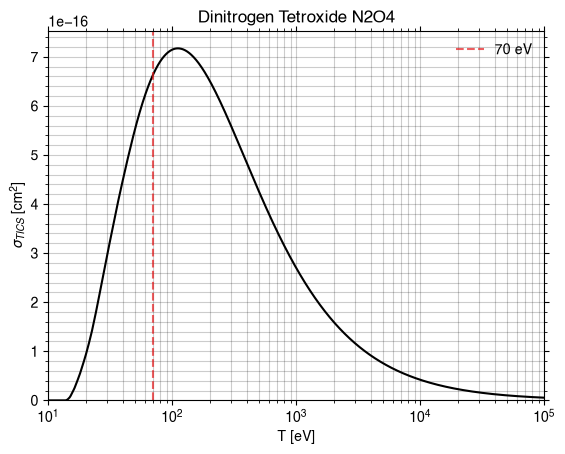

Loading output/xyz/Dinitrogen_pentoxide_N2O5.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Dinitrogen_pentoxide_N2O5.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

Compound(66242)
Recherche : 'Dinitrogen pentoxide' -> CID 66242, formule N2O5
3D


  frame 120/120
Wrote output/gif/Dinitrogen_pentoxide_N2O5.gifGIF written to output/gif/Dinitrogen_pentoxide_N2O5.gif

strucutre 3D
Réussite. Nom: Dinitrogen pentoxide, formule: N2O5, M: 108.01, nom_marche: Dinitrogen_pentoxide
PYSCF CONVERGENCE
converged SCF energy = -483.011414360803
**** MO energy ****
MO #1   energy= -20.7796687585374  occ= 2
MO #2   energy= -20.6830815763746  occ= 2
MO #3   energy= -20.6830699642922  occ= 2
MO #4   energy= -20.6806566401505  occ= 2
MO #5   energy= -20.6805967987187  occ= 2
MO #6   energy= -15.981900552454   occ= 2
MO #7   energy= -15.9818749238367  occ= 2
MO #8   energy= -1.72517770543909  occ= 2
MO #9   energy= -1.66716327524493  occ= 2
MO #10  energy= -1.4865354299356   occ= 2
MO #11  energy= -1.47848049077332  occ= 2
MO #12  energy= -1.46870707486981  occ= 2
MO #13  energy= -1.08382578142702  occ= 2
MO #14  energy= -0.927326727300006 occ= 2
MO #15  energy= -0.854061290086717 occ= 2
MO #16  energy= -0.846475813687849 occ= 2
MO #17  energy= -0.829503762937993 occ= 2
MO #18  energy= -0.786158962169805 occ= 2
MO #19  energy= -0.775327230682929 occ= 2
MO #20  energy

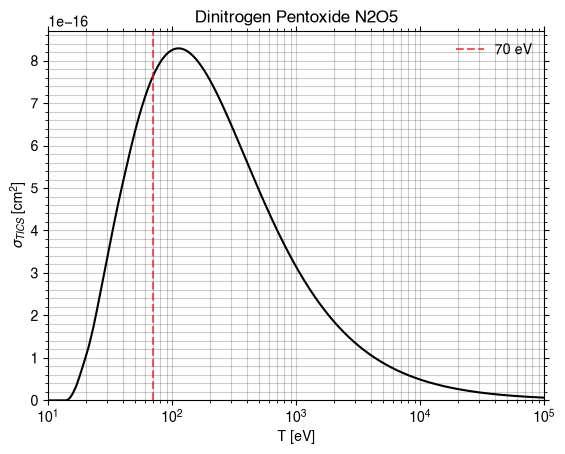

Compound(24524)
Recherche : 'Fluorine' -> CID 24524, formule F2


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: FF
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
2
1
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Fluorine, formule: F2, M: 37.99680632, nom_marche: Fluorine
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   F   0.667596   0.000000   0.000000    0.000000  0.000000  0.000000
   F  -0.667596   0.000000   0.000000    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -198.770952380162
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 F     0.0078430315    -0.0000000000    -0.0000000000
1 F    -0.0078430315     0.0000000000     0.0000000000
-------------------------------------------

Step    0 : Gradient = 7.843e-03/7.843e-03 (rms/max) Energy = -198.7709523802
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 5.82960e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   F   0.664036   0.000000   0.000000   -0.003560  0.000000  0.000000
   F  -0.664036  -0.000000  -0.000000    0.003560 -0.000000 -0.000000
converged SCF energy = -198.771007138982
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 F     0.0002425536     0.0000000000    -0.0000000000
1 F    -0.0002425536    -0.0000000000     0.0000000000
----------------------------------------------
cycle 2: E = -198.771007139  dE = -5.47588e-05  norm(grad) = 0.000343023


Step    1 : Displace = 3.560e-03/3.560e-03 (rms/max) Trust = 1.000e-01 (=) Grad = 2.426e-04/2.426e-04 (rms/max) E (change) = -198.7710071390 (-5.476e-05) Quality = 1.038
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 5.64932e-01



Geometry optimization cycle 3
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   F   0.663923  -0.000000   0.000000   -0.000114 -0.000000  0.000000
   F  -0.663923   0.000000  -0.000000    0.000114  0.000000 -0.000000
converged SCF energy = -198.771007189937
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 F    -0.0000061469    -0.0000000000     0.0000000000
1 F     0.0000061469     0.0000000000    -0.0000000000
----------------------------------------------
cycle 3: E = -198.77100719  dE = -5.09551e-08  norm(grad) = 8.69305e-06


Step    2 : Displace = 1.136e-04/1.136e-04 (rms/max) Trust = 1.414e-01 (+) Grad = 6.147e-06/6.147e-06 (rms/max) E (change) = -198.7710071899 (-5.096e-08) Quality = 0.979
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 5.64932e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 6.287 seconds
  frame 120/120xyz/Fluorine_F2.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Fluorine

converged SCF energy = -198.771007189939
**** MO energy ****
MO #1   energy= -26.4222830875392  occ= 2
MO #2   energy= -26.421988105469   occ= 2
MO #3   energy= -1.81309949979369  occ= 2
MO #4   energy= -1.47352141637002  occ= 2
MO #5   energy= -0.831433814997879 occ= 2
MO #6   energy= -0.83143381499783  occ= 2
MO #7   energy= -0.785361165658493 occ= 2
MO #8   energy= -0.649217353596873 occ= 2
MO #9   energy= -0.649217353596866 occ= 2
MO #10  energy= 0.0854556019588983 occ= 0
MO #11  energy= 0.151082575056806  occ= 0
MO #12  energy= 0.151164475065506  occ= 0
MO #13  energy= 0.151164475065556  occ= 0
MO #14  energy= 0.1835675495973    occ= 0
MO #15  energy= 0.194074298614513  occ= 0
MO #16  energy= 0.194074298614597  occ= 0
MO #17  energy= 0.214260607319359  occ= 0
MO #18  energy= 0.409503919099869  occ= 0
MO #19  energy= 0.541839840600329  occ= 0
MO #20  energy= 0.541839840600363  occ= 0
MO #21  energy= 0.662620379283918  occ= 0
MO #22  energy= 0.666196704917036  occ= 0
MO #23  energy=

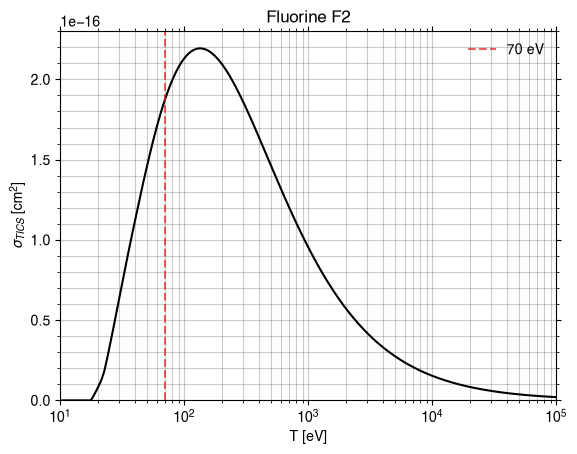

Compound(24526)
Recherche : 'Chlorine' -> CID 24526, formule Cl2


Loading output/xyz/Chlorine_Cl2.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Chlorine_Cl2.xyzBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Chlorine_Cl2.gifGIF written to output/gif/Chlorine_Cl2.gif

strucutre 3D
Réussite. Nom: Chlorine, formule: Cl2, M: 70.9, nom_marche: Chlorine
PYSCF CONVERGENCE
converged SCF energy = -29.4226427498994
**** MO energy ****
MO #1   energy= -1.21949113657861  occ= 2
MO #2   energy= -1.02475354412661  occ= 2
MO #3   energy= -0.595468178427294 occ= 2
MO #4   energy= -0.566293548525947 occ= 2
MO #5   energy= -0.566293548525945 occ= 2
MO #6   energy= -0.445668569855301 occ= 2
MO #7   energy= -0.445668569855299 occ= 2
MO #8   energy= 0.0202926517554045 occ= 0
MO #9   energy= 0.13639970460775   occ= 0
MO #10  energy= 0.138543633848858  occ= 0
MO #11  energy= 0.13854363384886   occ= 0
MO #12  energy= 0.150648966503371  occ= 0
MO #13  energy= 0.170606701331077  occ= 0
MO #14  energy= 0.170606701331088  occ= 0
MO #15  energy= 0.237916322205684  occ= 0
MO #16  energy= 0.299545748220184  occ= 0
MO #17  energy= 0.299545748220184  occ= 0
MO #18  energy= 0.336008517331111  occ= 0
MO #19  energy= 0.336008517331113  occ= 0
MO #20  energy= 0.397823677378436  occ= 0

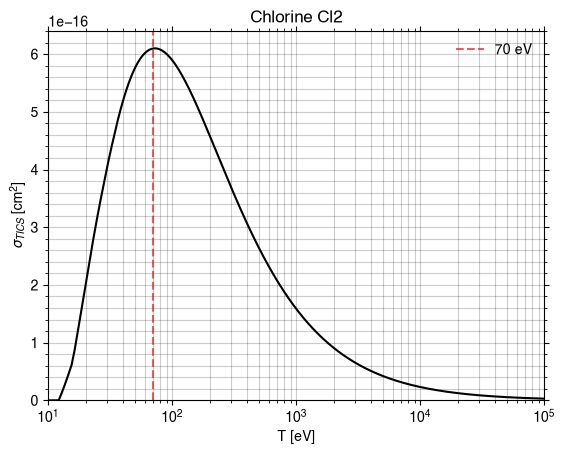

Compound(24408)
Recherche : 'Bromine' -> CID 24408, formule Br2


Loading output/xyz/Bromine_Br2.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Bromine_Br2.xyzBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Bromine_Br2.gifGIF written to output/gif/Bromine_Br2.gif

strucutre 3D
Réussite. Nom: Bromine, formule: Br2, M: 159.81, nom_marche: Bromine
PYSCF CONVERGENCE
converged SCF energy = -26.2762325359378
**** MO energy ****
MO #1   energy= -1.1259144954892   occ= 2
MO #2   energy= -0.976779692806949 occ= 2
MO #3   energy= -0.536512706433379 occ= 2
MO #4   energy= -0.505166184784992 occ= 2
MO #5   energy= -0.505166184784991 occ= 2
MO #6   energy= -0.407270567616099 occ= 2
MO #7   energy= -0.407270567616094 occ= 2
MO #8   energy= -0.00966313524669427 occ= 0
MO #9   energy= 0.0795641488160586 occ= 0
MO #10  energy= 0.0837265074502842 occ= 0
MO #11  energy= 0.0837265074502895 occ= 0
MO #12  energy= 0.092652159997648  occ= 0
MO #13  energy= 0.106188310851131  occ= 0
MO #14  energy= 0.106188310851131  occ= 0
MO #15  energy= 0.132745589547482  occ= 0
MO #16  energy= 0.223562648052811  occ= 0
MO #17  energy= 0.223562648052812  occ= 0
MO #18  energy= 0.245692664128087  occ= 0
MO #19  energy= 0.261401543647851  occ= 0
MO #20  energy= 0.261401543647852  occ=

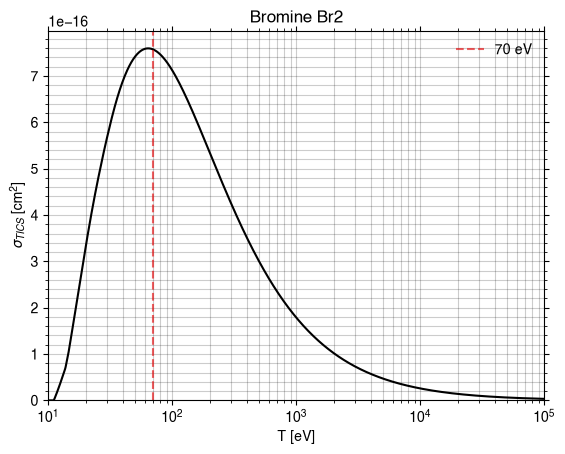

Compound(260)
Recherche : 'Hydrogen bromide' -> CID 260, formule BrH


Loading output/xyz/Hydrogen_bromide_BrH.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Hydrogen_bromide_BrH.xyzBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Hydrogen_bromide_BrH.gifGIF written to output/gif/Hydrogen_bromide_BrH.gif

strucutre 3D
Réussite. Nom: Hydrogen bromide, formule: BrH, M: 80.91, nom_marche: Hydrogen_bromide
PYSCF CONVERGENCE
converged SCF energy = -13.7290143529942
**** MO energy ****
MO #1   energy= -1.05303981073104  occ= 2
MO #2   energy= -0.577958792914241 occ= 2
MO #3   energy= -0.434428425516752 occ= 2
MO #4   energy= -0.434428425516749 occ= 2
MO #5   energy= 0.0702894566654686 occ= 0
MO #6   energy= 0.0785137191449217 occ= 0
MO #7   energy= 0.0871135906357308 occ= 0
MO #8   energy= 0.0871135906357353 occ= 0
MO #9   energy= 0.152135201842036  occ= 0
MO #10  energy= 0.222533503751864  occ= 0
MO #11  energy= 0.222533503751865  occ= 0
MO #12  energy= 0.260855506405354  occ= 0
MO #13  energy= 0.260855506405356  occ= 0
MO #14  energy= 0.310452320509339  occ= 0
MO #15  energy= 0.349165323905381  occ= 0
MO #16  energy= 0.356686770867951  occ= 0
MO #17  energy= 0.356686770867962  occ= 0
MO #18  energy= 0.389142779612548  occ= 0
MO #19  energy= 0.389142779612576  occ= 0
MO #20  energy= 0.393361

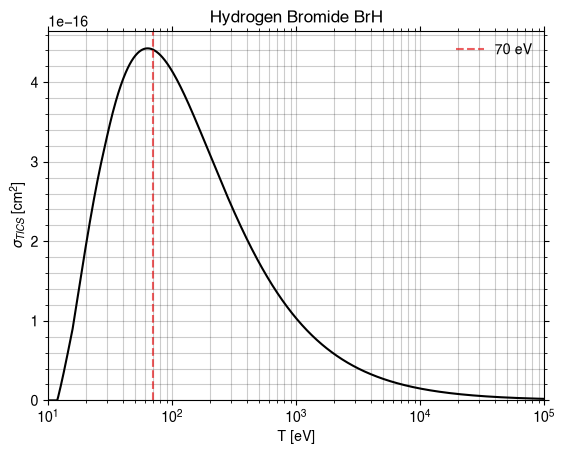

Compound(24841)
Recherche : 'Hydrogen iodide' -> CID 24841, formule HI


Loading output/xyz/Hydrogen_iodide_HI.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Hydrogen_iodide_HI.xyzBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Hydrogen_iodide_HI.gifGIF written to output/gif/Hydrogen_iodide_HI.gifWarning: Basis not found for atom 0 I


strucutre 3D
Réussite. Nom: Hydrogen iodide, formule: HI, M: 127.9124, nom_marche: Hydrogen_iodide
PYSCF CONVERGENCE
temp.xyz a échoué : RuntimeError : Failed to assign mo_occ. Nocc (27) > Nmo (17)
ORBITAL CAR
Hydrogen iodide a échoué : TypeError : 'NoneType' object is not iterable
Compound(6327)
Recherche : 'Chloromethane' -> CID 6327, formule CH3Cl


Loading output/xyz/Chloromethane_CH3Cl.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Chloromethane_CH3Cl.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Chloromethane_CH3Cl.gifGIF written to output/gif/Chloromethane_CH3Cl.gif

strucutre 3D
Réussite. Nom: Chloromethane, formule: CH3Cl, M: 50.49, nom_marche: Chloromethane
PYSCF CONVERGENCE
converged SCF energy = -54.3610863365979
**** MO energy ****
MO #1   energy= -11.2902006649914  occ= 2
MO #2   energy= -1.13672949116851  occ= 2
MO #3   energy= -0.913958233526749 occ= 2
MO #4   energy= -0.61584037929586  occ= 2
MO #5   energy= -0.615827451609004 occ= 2
MO #6   energy= -0.551041544358181 occ= 2
MO #7   energy= -0.43472114988429  occ= 2
MO #8   energy= -0.434720536530894 occ= 2
MO #9   energy= 0.0733057125170333 occ= 0
MO #10  energy= 0.111512181097956  occ= 0
MO #11  energy= 0.126881676705044  occ= 0
MO #12  energy= 0.12688242356681   occ= 0
MO #13  energy= 0.175818799240367  occ= 0
MO #14  energy= 0.17610651655219   occ= 0
MO #15  energy= 0.17610707595757   occ= 0
MO #16  energy= 0.20497987608781   occ= 0
MO #17  energy= 0.204983848624116  occ= 0
MO #18  energy= 0.240478916258624  occ= 0
MO #19  energy= 0.278762776382569  occ= 0
MO #20  energy= 0.2990817307

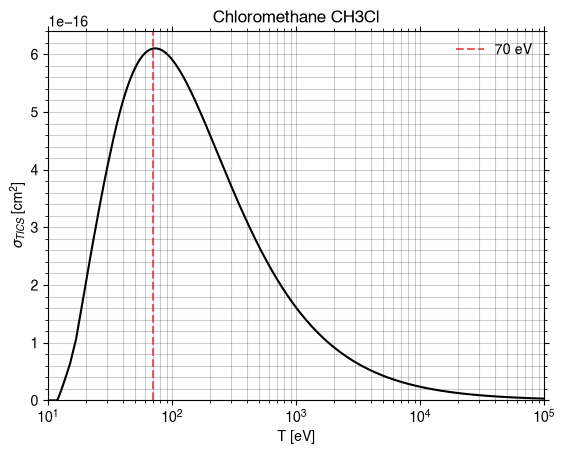

Compound(6344)
Recherche : 'Dichloromethane' -> CID 6344, formule CH2Cl2


Loading output/xyz/Dichloromethane_CH2Cl2.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Dichloromethane_CH2Cl2.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Dichloromethane_CH2Cl2.gifGIF written to output/gif/Dichloromethane_CH2Cl2.gif

strucutre 3D
Réussite. Nom: Dichloromethane, formule: CH2Cl2, M: 84.93, nom_marche: Dichloromethane
PYSCF CONVERGENCE
converged SCF energy = -68.5033435172893
**** MO energy ****
MO #1   energy= -11.3666759514729  occ= 2
MO #2   energy= -1.19850033596868  occ= 2
MO #3   energy= -1.10319959666369  occ= 2
MO #4   energy= -0.897227328185625 occ= 2
MO #5   energy= -0.671690186688014 occ= 2
MO #6   energy= -0.620674469464529 occ= 2
MO #7   energy= -0.586084761109724 occ= 2
MO #8   energy= -0.472813080864545 occ= 2
MO #9   energy= -0.472711039512622 occ= 2
MO #10  energy= -0.445847705476492 occ= 2
MO #11  energy= -0.445396045511931 occ= 2
MO #12  energy= 0.0729189583355243 occ= 0
MO #13  energy= 0.0983404740329562 occ= 0
MO #14  energy= 0.105813057228657  occ= 0
MO #15  energy= 0.109372060504487  occ= 0
MO #16  energy= 0.134872524013056  occ= 0
MO #17  energy= 0.150388432949011  occ= 0
MO #18  energy= 0.15223648640757   occ= 0
MO #19  energy= 0.175397752469559  occ= 0
MO #20  energy= 0.17899

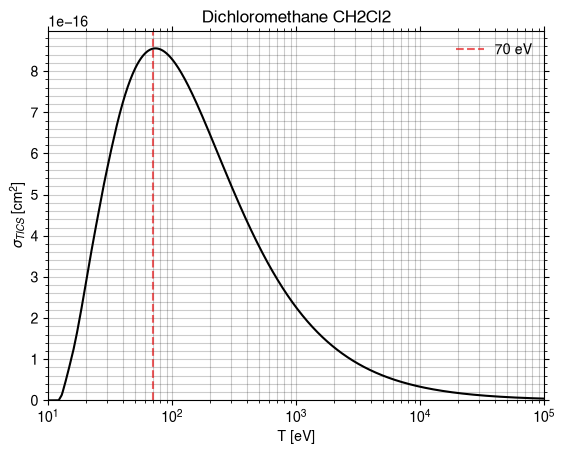

Compound(6212)
Recherche : 'Chloroform' -> CID 6212, formule CHCl3


Loading output/xyz/Chloroform_CHCl3.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Chloroform_CHCl3.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Chloroform_CHCl3.gifGIF written to output/gif/Chloroform_CHCl3.gif

strucutre 3D
Réussite. Nom: Chloroform, formule: CHCl3, M: 119.37, nom_marche: Chloroform
PYSCF CONVERGENCE
converged SCF energy = -82.6387217845504
**** MO energy ****
MO #1   energy= -11.4371821244533  occ= 2
MO #2   energy= -1.24534927150258  occ= 2
MO #3   energy= -1.12122669255642  occ= 2
MO #4   energy= -1.12119429650402  occ= 2
MO #5   energy= -0.87652926236559  occ= 2
MO #6   energy= -0.681400786255324 occ= 2
MO #7   energy= -0.626320727182276 occ= 2
MO #8   energy= -0.626303093726274 occ= 2
MO #9   energy= -0.503967012086582 occ= 2
MO #10  energy= -0.503954166787831 occ= 2
MO #11  energy= -0.467483820410126 occ= 2
MO #12  energy= -0.46746779918319  occ= 2
MO #13  energy= -0.466486884022515 occ= 2
MO #14  energy= -0.450672334530462 occ= 2
MO #15  energy= 0.075525539164812  occ= 0
MO #16  energy= 0.0837372284893502 occ= 0
MO #17  energy= 0.102285792861277  occ= 0
MO #18  energy= 0.102287029775506  occ= 0
MO #19  energy= 0.118964635439527  occ= 0
MO #20  energy= 0.133316532830844

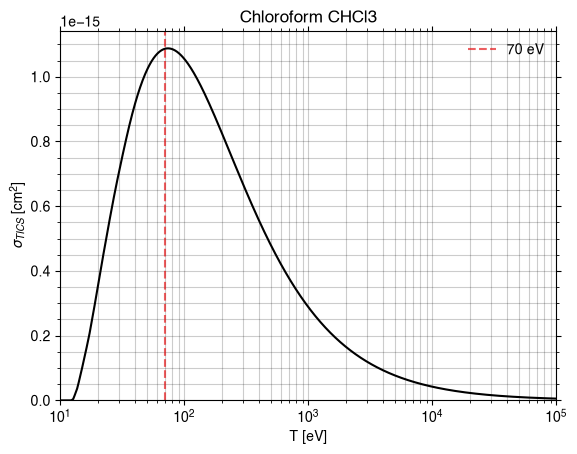

Compound(5943)
Recherche : 'Carbon tetrachloride' -> CID 5943, formule CCl4


Loading output/xyz/Carbon_tetrachloride_CCl4.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Carbon_tetrachloride_CCl4.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Carbon_tetrachloride_CCl4.gifGIF written to output/gif/Carbon_tetrachloride_CCl4.gif

strucutre 3D
Réussite. Nom: Carbon tetrachloride, formule: CCl4, M: 153.8, nom_marche: Carbon_tetrachloride
PYSCF CONVERGENCE
converged SCF energy = -96.7644268447823
**** MO energy ****
MO #1   energy= -11.5028459232183  occ= 2
MO #2   energy= -1.28038330717999  occ= 2
MO #3   energy= -1.13342270634025  occ= 2
MO #4   energy= -1.13329856919698  occ= 2
MO #5   energy= -1.13322994169177  occ= 2
MO #6   energy= -0.837208034808288 occ= 2
MO #7   energy= -0.655848246467187 occ= 2
MO #8   energy= -0.655772871397536 occ= 2
MO #9   energy= -0.655739601309704 occ= 2
MO #10  energy= -0.530296698731725 occ= 2
MO #11  energy= -0.530219247571558 occ= 2
MO #12  energy= -0.488857282642309 occ= 2
MO #13  energy= -0.488777122024103 occ= 2
MO #14  energy= -0.488728145723199 occ= 2
MO #15  energy= -0.461082568995835 occ= 2
MO #16  energy= -0.461035936353301 occ= 2
MO #17  energy= -0.461023008759493 occ= 2
MO #18  energy= 0.0649507075480464 occ= 0
MO #19  energy= 0.0950348981266469 occ= 0
MO #20  energy=

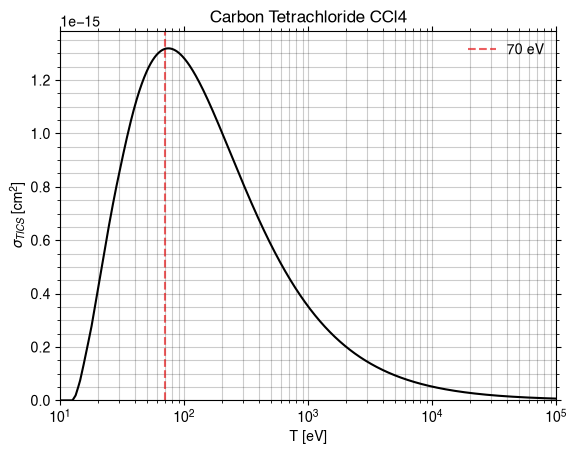

Compound(11638)
Recherche : 'Fluoromethane' -> CID 11638, formule CH3F


Loading output/xyz/Fluoromethane_CH3F.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Fluoromethane_CH3F.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Fluoromethane_CH3F.gifGIF written to output/gif/Fluoromethane_CH3F.gif

strucutre 3D
Réussite. Nom: Fluoromethane, formule: CH3F, M: 34.033, nom_marche: Fluoromethane
PYSCF CONVERGENCE
converged SCF energy = -139.103337858771
**** MO energy ****
MO #1   energy= -26.2783008560188  occ= 2
MO #2   energy= -11.3029621810164  occ= 2
MO #3   energy= -1.59782805568227  occ= 2
MO #4   energy= -0.953320699379272 occ= 2
MO #5   energy= -0.703100715083346 occ= 2
MO #6   energy= -0.703091131793028 occ= 2
MO #7   energy= -0.682329864246462 occ= 2
MO #8   energy= -0.526741210025333 occ= 2
MO #9   energy= -0.526721015459862 occ= 2
MO #10  energy= 0.0729999635817435 occ= 0
MO #11  energy= 0.122993992421125  occ= 0
MO #12  energy= 0.132553633083404  occ= 0
MO #13  energy= 0.132555795997667  occ= 0
MO #14  energy= 0.169427596846737  occ= 0
MO #15  energy= 0.179348961309755  occ= 0
MO #16  energy= 0.179350795412844  occ= 0
MO #17  energy= 0.214666043169728  occ= 0
MO #18  energy= 0.214668775168253  occ= 0
MO #19  energy= 0.27691389264411   occ= 0
MO #20  energy= 0.3317859956

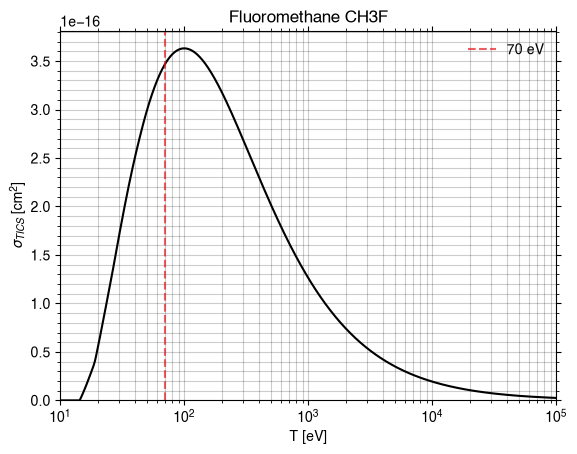

Compound(6345)
Recherche : 'Difluoromethane' -> CID 6345, formule CH2F2


Loading output/xyz/Difluoromethane_CH2F2.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Difluoromethane_CH2F2.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Difluoromethane_CH2F2.gifGIF written to output/gif/Difluoromethane_CH2F2.gif

strucutre 3D
Réussite. Nom: Difluoromethane, formule: CH2F2, M: 52.023, nom_marche: Difluoromethane
PYSCF CONVERGENCE
converged SCF energy = -238.009570232379
**** MO energy ****
MO #1   energy= -26.3107624003581  occ= 2
MO #2   energy= -26.3107450089707  occ= 2
MO #3   energy= -11.4062820669096  occ= 2
MO #4   energy= -1.66281607502266  occ= 2
MO #5   energy= -1.59995002968769  occ= 2
MO #6   energy= -0.971074878162682 occ= 2
MO #7   energy= -0.778110189081388 occ= 2
MO #8   energy= -0.773932698754692 occ= 2
MO #9   energy= -0.755126782770559 occ= 2
MO #10  energy= -0.66699409804141  occ= 2
MO #11  energy= -0.632084317573649 occ= 2
MO #12  energy= -0.625784592516376 occ= 2
MO #13  energy= -0.535922681061287 occ= 2
MO #14  energy= 0.0697631619530661 occ= 0
MO #15  energy= 0.108548013138006  occ= 0
MO #16  energy= 0.11371255730404   occ= 0
MO #17  energy= 0.115408173482821  occ= 0
MO #18  energy= 0.161307352605444  occ= 0
MO #19  energy= 0.163272985502875  occ= 0
MO #20  energy= 0.16524

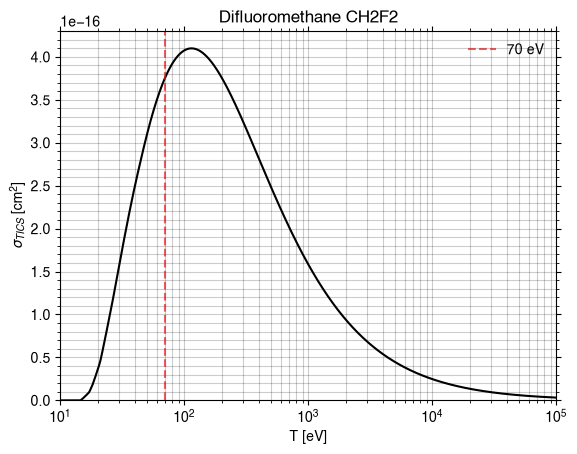

Compound(6373)
Recherche : 'Fluoroform' -> CID 6373, formule CHF3


Loading output/xyz/Fluoroform_CHF3.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Fluoroform_CHF3.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Fluoroform_CHF3.gifGIF written to output/gif/Fluoroform_CHF3.gif

strucutre 3D
Réussite. Nom: Fluoroform, formule: CHF3, M: 70.014, nom_marche: Fluoroform
PYSCF CONVERGENCE
converged SCF energy = -336.92360865895
**** MO energy ****
MO #1   energy= -26.3436361323981  occ= 2
MO #2   energy= -26.3436342299193  occ= 2
MO #3   energy= -26.3436061957061  occ= 2
MO #4   energy= -11.514371429713   occ= 2
MO #5   energy= -1.72654750502716  occ= 2
MO #6   energy= -1.63565836007805  occ= 2
MO #7   energy= -1.63565515802937  occ= 2
MO #8   energy= -0.990877399084127 occ= 2
MO #9   energy= -0.843871592235866 occ= 2
MO #10  energy= -0.820917237307994 occ= 2
MO #11  energy= -0.820916423405924 occ= 2
MO #12  energy= -0.71151685778955  occ= 2
MO #13  energy= -0.711516846765837 occ= 2
MO #14  energy= -0.669020205655302 occ= 2
MO #15  energy= -0.669019624329734 occ= 2
MO #16  energy= -0.654729072814722 occ= 2
MO #17  energy= -0.604352767178714 occ= 2
MO #18  energy= 0.0673235098369567 occ= 0
MO #19  energy= 0.100979733153291  occ= 0
MO #20  energy= 0.103465662115541  

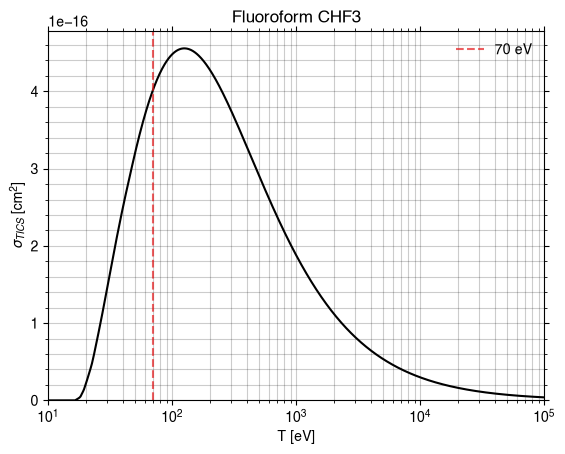

Compound(6393)
Recherche : 'Tetrafluoromethane' -> CID 6393, formule CF4


Loading output/xyz/Tetrafluoromethane_CF4.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Tetrafluoromethane_CF4.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Tetrafluoromethane_CF4.gifGIF written to output/gif/Tetrafluoromethane_CF4.gif

strucutre 3D
Réussite. Nom: Tetrafluoromethane, formule: CF4, M: 88.004, nom_marche: Tetrafluoromethane
PYSCF CONVERGENCE
converged SCF energy = -435.832956229745
**** MO energy ****
MO #1   energy= -26.3773744928877  occ= 2
MO #2   energy= -26.3773656283513  occ= 2
MO #3   energy= -26.3773552455508  occ= 2
MO #4   energy= -26.3773205872138  occ= 2
MO #5   energy= -11.6204758887461  occ= 2
MO #6   energy= -1.78785986363517  occ= 2
MO #7   energy= -1.67262691271412  occ= 2
MO #8   energy= -1.67260180167511  occ= 2
MO #9   energy= -1.67258209566017  occ= 2
MO #10  energy= -1.00878925089329  occ= 2
MO #11  energy= -0.879869132444394 occ= 2
MO #12  energy= -0.879865045523977 occ= 2
MO #13  energy= -0.87986377231764  occ= 2
MO #14  energy= -0.760901975489016 occ= 2
MO #15  energy= -0.760899287688641 occ= 2
MO #16  energy= -0.710347824036597 occ= 2
MO #17  energy= -0.71033874916408  occ= 2
MO #18  energy= -0.710332080519924 occ= 2
MO #19  energy= -0.687438376022321 occ= 2
MO #20  energy= -0.

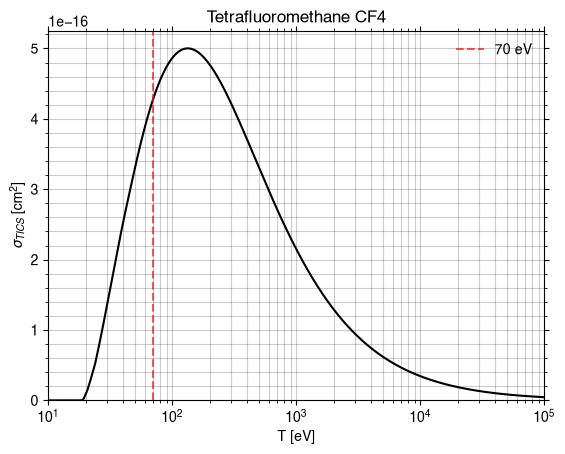

Compound(6323)
Recherche : 'Bromomethane' -> CID 6323, formule CH3Br


Loading output/xyz/Bromomethane_CH3Br.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Bromomethane_CH3Br.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Bromomethane_CH3Br.gifGIF written to output/gif/Bromomethane_CH3Br.gif

strucutre 3D
Réussite. Nom: Bromomethane, formule: CH3Br, M: 94.94, nom_marche: Bromomethane
PYSCF CONVERGENCE
converged SCF energy = -52.774556699022
**** MO energy ****
MO #1   energy= -11.2912023205956  occ= 2
MO #2   energy= -1.0756748261296   occ= 2
MO #3   energy= -0.906169574065213 occ= 2
MO #4   energy= -0.610452710064168 occ= 2
MO #5   energy= -0.610433881493869 occ= 2
MO #6   energy= -0.507769113446574 occ= 2
MO #7   energy= -0.401605482638054 occ= 2
MO #8   energy= -0.401603724880047 occ= 2
MO #9   energy= 0.0660266551353035 occ= 0
MO #10  energy= 0.0748113795436699 occ= 0
MO #11  energy= 0.0874231088254219 occ= 0
MO #12  energy= 0.0874238384547372 occ= 0
MO #13  energy= 0.14169841583017   occ= 0
MO #14  energy= 0.164804434851944  occ= 0
MO #15  energy= 0.164806870143148  occ= 0
MO #16  energy= 0.185039804986704  occ= 0
MO #17  energy= 0.198063038232405  occ= 0
MO #18  energy= 0.198064799287033  occ= 0
MO #19  energy= 0.261158412984572  occ= 0
MO #20  energy= 0.2660012245196

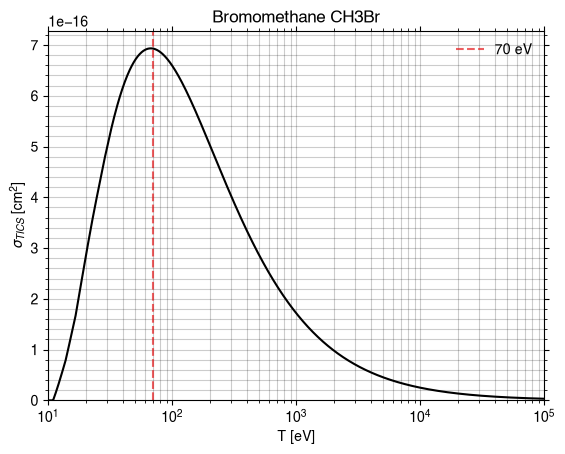

Compound(6328)
Recherche : 'Iodomethane' -> CID 6328, formule CH3I


Loading output/xyz/Iodomethane_CH3I.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Iodomethane_CH3I.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Iodomethane_CH3I.gifGIF written to output/gif/Iodomethane_CH3I.gifWarning: Basis not found for atom 0 I


strucutre 3D
Réussite. Nom: Iodomethane, formule: CH3I, M: 141.939, nom_marche: Iodomethane
PYSCF CONVERGENCE
converged SCF energy = -370.465380329697
**** MO energy ****
MO #1   energy= -17.025743534592   occ= 2
MO #2   energy= -8.4201132777451   occ= 2
MO #3   energy= -7.62455914424374  occ= 2
MO #4   energy= -6.008259619747    occ= 2
MO #5   energy= -5.99592761690598  occ= 2
MO #6   energy= -2.99947650463648  occ= 2
MO #7   energy= -2.27613394033446  occ= 2
MO #8   energy= -2.26361122372345  occ= 2
MO #9   energy= -1.21496514292456  occ= 2
MO #10  energy= -1.21208723163796  occ= 2
MO #11  energy= -0.195790480492967 occ= 2
MO #12  energy= 0.434853437811636  occ= 2
MO #13  energy= 0.530466944367395  occ= 2
MO #14  energy= 0.531915443840872  occ= 2
MO #15  energy= 0.845614411759248  occ= 2
MO #16  energy= 0.860131174394111  occ= 2
MO #17  energy= 0.976230599280676  occ= 2
MO #18  energy= 1.00301515668358   occ= 2
MO #19  energy= 1.17512029448163   occ= 2
MO #20  energy= 1.4911164258407

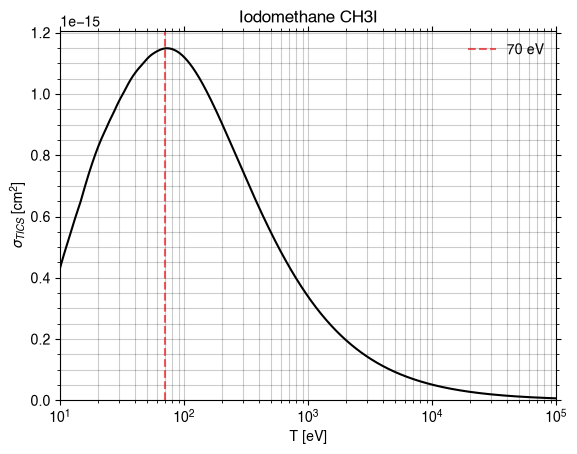

Compound(6338)
Recherche : 'Vinyl chloride' -> CID 6338, formule C2H3Cl


Loading output/xyz/Vinyl_chloride_C2H3Cl.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Vinyl_chloride_C2H3Cl.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Vinyl_chloride_C2H3Cl.gifGIF written to output/gif/Vinyl_chloride_C2H3Cl.gif

strucutre 3D
Réussite. Nom: Vinyl chloride, formule: C2H3Cl, M: 62.5, nom_marche: Vinyl_chloride
PYSCF CONVERGENCE
converged SCF energy = -92.2155247057514
**** MO energy ****
MO #1   energy= -11.3016839673174  occ= 2
MO #2   energy= -11.2473977588579  occ= 2
MO #3   energy= -1.16814203264033  occ= 2
MO #4   energy= -1.01435443954255  occ= 2
MO #5   energy= -0.794267297292137 occ= 2
MO #6   energy= -0.663010499108157 occ= 2
MO #7   energy= -0.616428314843745 occ= 2
MO #8   energy= -0.533241941855948 occ= 2
MO #9   energy= -0.514494052428666 occ= 2
MO #10  energy= -0.454234222858979 occ= 2
MO #11  energy= -0.369228825750788 occ= 2
MO #12  energy= 0.0747762050375966 occ= 0
MO #13  energy= 0.0930810135712632 occ= 0
MO #14  energy= 0.111308123333995  occ= 0
MO #15  energy= 0.11538301512674   occ= 0
MO #16  energy= 0.13299506717523   occ= 0
MO #17  energy= 0.143056823115336  occ= 0
MO #18  energy= 0.159962073274083  occ= 0
MO #19  energy= 0.174006426727522  occ= 0
MO #20  energy= 0.20917133

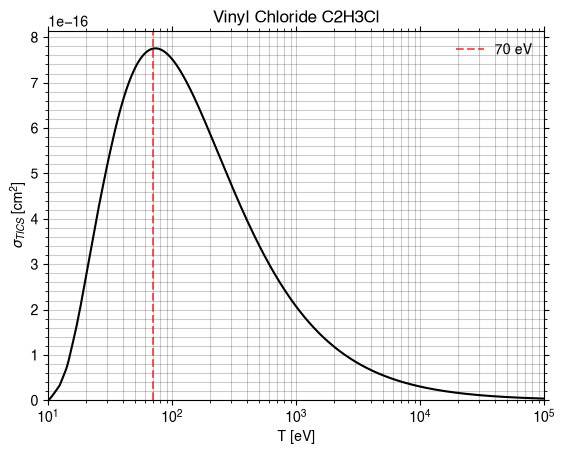

Compound(6575)
Recherche : 'Trichloroethylene' -> CID 6575, formule C2HCl3


Loading output/xyz/Trichloroethylene_C2HCl3.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Trichloroethylene_C2HCl3.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Trichloroethylene_C2HCl3.gifGIF written to output/gif/Trichloroethylene_C2HCl3.gif

strucutre 3D
Réussite. Nom: Trichloroethylene, formule: C2HCl3, M: 131.38, nom_marche: Trichloroethylene
PYSCF CONVERGENCE
converged SCF energy = -120.496606135453
**** MO energy ****
MO #1   energy= -11.3810111873945  occ= 2
MO #2   energy= -11.328293951018   occ= 2
MO #3   energy= -1.24019396359293  occ= 2
MO #4   energy= -1.16817473784294  occ= 2
MO #5   energy= -1.12840023459723  occ= 2
MO #6   energy= -0.995670889719793 occ= 2
MO #7   energy= -0.77771247940548  occ= 2
MO #8   energy= -0.683474161042348 occ= 2
MO #9   energy= -0.646580161707959 occ= 2
MO #10  energy= -0.588574919856711 occ= 2
MO #11  energy= -0.565765182436394 occ= 2
MO #12  energy= -0.510155903364293 occ= 2
MO #13  energy= -0.499585657062664 occ= 2
MO #14  energy= -0.485710008040831 occ= 2
MO #15  energy= -0.482080847039777 occ= 2
MO #16  energy= -0.458190602415876 occ= 2
MO #17  energy= -0.367672628334766 occ= 2
MO #18  energy= 0.0732355373196944 occ= 0
MO #19  energy= 0.0911701728725261 occ= 0
MO #20  energy= 0.

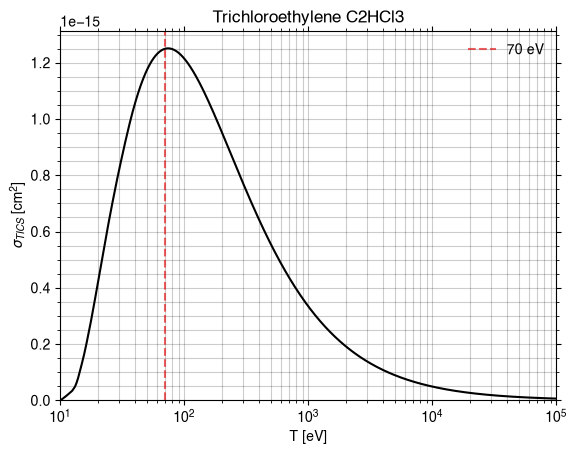

Compound(31373)
Recherche : 'Tetrachloroethylene' -> CID 31373, formule C2Cl4


Loading output/xyz/Tetrachloroethylene_C2Cl4.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Tetrachloroethylene_C2Cl4.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Tetrachloroethylene_C2Cl4.gifGIF written to output/gif/Tetrachloroethylene_C2Cl4.gif

strucutre 3D
Réussite. Nom: Tetrachloroethylene, formule: C2Cl4, M: 165.8, nom_marche: Tetrachloroethylene
PYSCF CONVERGENCE
converged SCF energy = -134.631201278884
**** MO energy ****
MO #1   energy= -11.3954124701633  occ= 2
MO #2   energy= -11.3938172520004  occ= 2
MO #3   energy= -1.26229397981984  occ= 2
MO #4   energy= -1.19408063578869  occ= 2
MO #5   energy= -1.14548075709717  occ= 2
MO #6   energy= -1.12133223165531  occ= 2
MO #7   energy= -0.991491855307959 occ= 2
MO #8   energy= -0.752475571912054 occ= 2
MO #9   energy= -0.676995283080131 occ= 2
MO #10  energy= -0.663921754677039 occ= 2
MO #11  energy= -0.613693607190218 occ= 2
MO #12  energy= -0.573961227541155 occ= 2
MO #13  energy= -0.531896476921072 occ= 2
MO #14  energy= -0.512296020494177 occ= 2
MO #15  energy= -0.502259623680728 occ= 2
MO #16  energy= -0.498879481387933 occ= 2
MO #17  energy= -0.490671013654099 occ= 2
MO #18  energy= -0.484757127248431 occ= 2
MO #19  energy= -0.452390678587751 occ= 2
MO #20  energy= 

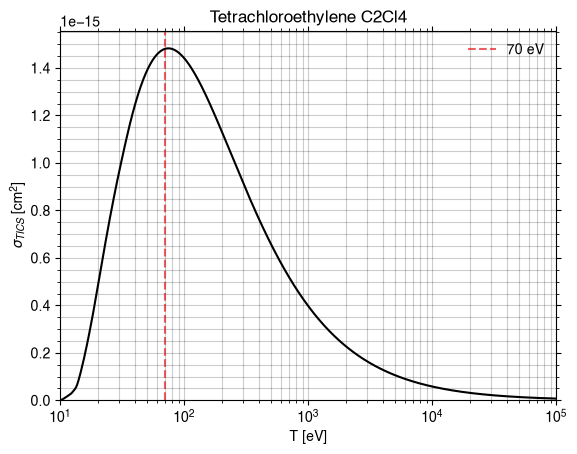

Compound(10037)
Recherche : 'Propadiene' -> CID 10037, formule C3H4


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: C=C=C
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
7
6
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Propadiene, formule: C3H4, M: 40.06, nom_marche: Propadiene
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   1.303295   0.005600   0.006188    0.000000  0.000000  0.000000
   C  -0.000154  -0.001017   0.000387    0.000000  0.000000  0.000000
   C  -1.302588  -0.000096  -0.009480    0.000000  0.000000  0.000000
   H   1.775313  -0.806888   0.530508    0.000000  0.000000  0.000000
   H   1.784804   0.802369  -0.500717    0.000000  0.000000  0.000000
   H  -1.774352  -0.515534  -0.818085    0.000000  0.000000  0.000000
   H  -1.786318   0.515566   0.791200    0.000000  0.00000

Step    0 : Gradient = 2.122e-02/3.679e-02 (rms/max) Energy = -115.9060225821
Hessian Eigenvalues: 2.30000e-02 2.82323e-02 2.83311e-02 ... 3.85203e-01 6.62362e-01 6.65113e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   1.294414  -0.026573   0.036560   -0.008881 -0.032173  0.030372
   C  -0.000803  -0.019442  -0.002284   -0.000649 -0.018425 -0.002671
   C  -1.295976  -0.009367  -0.042665    0.006612 -0.009271 -0.033185
   H   1.908251  -0.759391   0.522509    0.132938  0.047497 -0.007999
   H   1.788965   0.780551  -0.467879    0.004161 -0.021818  0.032838
   H  -1.898562  -0.476944  -0.796703   -0.124210  0.038590  0.021382
   H  -1.796288   0.511166   0.750463   -0.009970 -0.004400 -0.040737
converged SCF energy = -115.908517285456
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C     0.0055579249    -0.0102537419     0.0063385177
1 C    -0.0002243458     0.0135844303     0.0024684450
2 C    -0.0060804346    -0.0058743324    -0.0091462161
3 H     0.0052351001     0.0023441906    -0.0016134039
4 H    -0.0052826694  

Step    1 : Displace = 7.958e-02/1.414e-01 (rms/max) Trust = 1.000e-01 (=) Grad = 9.548e-03/1.381e-02 (rms/max) E (change) = -115.9085172855 (-2.495e-03) Quality = 0.575
Hessian Eigenvalues: 2.30000e-02 2.82315e-02 2.83363e-02 ... 3.81526e-01 6.49688e-01 6.64078e-01


... (5 outputs left out)

Step    4 : Displace = 6.419e-04/1.114e-03 (rms/max) Trust = 2.000e-01 (+) Grad = 1.029e-04/2.064e-04 (rms/max) E (change) = -115.9102263727 (-1.148e-06) Quality = 1.324
Hessian Eigenvalues: 2.30013e-02 2.82899e-02 2.91388e-02 ... 4.27310e-01 6.63937e-01 7.09884e-01



Geometry optimization cycle 6
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   1.292016  -0.000211   0.009864    0.000009  0.000258 -0.000295
   C   0.000026  -0.000363  -0.000058    0.000030  0.001458  0.000108
   C  -1.291969   0.000103  -0.009933    0.000044 -0.000065  0.000241
   H   1.840237  -0.775569   0.510974   -0.000926 -0.000280 -0.000214
   H   1.847681   0.775309  -0.482770    0.001085 -0.000370 -0.000144
   H  -1.838464  -0.496510  -0.789451    0.000420 -0.000455  0.000224
   H  -1.849528   0.497241   0.761374   -0.000663 -0.000547  0.000079
converged SCF energy = -115.910226739674
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C    -0.0000228446     0.0000114051    -0.0000018976
1 C     0.0000121658    -0.0000329603     0.0000201820
2 C     0.0000539181     0.0000008238    -0.0000170921
3 H    -0.0000120333     0.0000276726    -0.0000148925
4 H     0.0000008701  

Step    5 : Displace = 9.141e-04/1.462e-03 (rms/max) Trust = 2.828e-01 (+) Grad = 3.409e-05/5.657e-05 (rms/max) E (change) = -115.9102267397 (-3.670e-07) Quality = 1.134
Hessian Eigenvalues: 2.30013e-02 2.82899e-02 2.91388e-02 ... 4.27310e-01 6.63937e-01 7.09884e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 155.158 seconds
  frame 120/120xyz/Propadiene_C3H4.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Pr

converged SCF energy = -115.910226739705
**** MO energy ****
MO #1   energy= -11.2565376127713  occ= 2
MO #2   energy= -11.2304544378265  occ= 2
MO #3   energy= -11.2303402498444  occ= 2
MO #4   energy= -1.07975502347968  occ= 2
MO #5   energy= -0.963305080225645 occ= 2
MO #6   energy= -0.716817951866943 occ= 2
MO #7   energy= -0.632191444254083 occ= 2
MO #8   energy= -0.612746460587895 occ= 2
MO #9   energy= -0.612720851826655 occ= 2
MO #10  energy= -0.380642510711364 occ= 2
MO #11  energy= -0.380640923433781 occ= 2
MO #12  energy= 0.0690338664538058 occ= 0
MO #13  energy= 0.0933281801066407 occ= 0
MO #14  energy= 0.121658790992965  occ= 0
MO #15  energy= 0.135758810410281  occ= 0
MO #16  energy= 0.135760756129226  occ= 0
MO #17  energy= 0.170580211743455  occ= 0
MO #18  energy= 0.170583459494252  occ= 0
MO #19  energy= 0.181732829930228  occ= 0
MO #20  energy= 0.219442367507934  occ= 0
MO #21  energy= 0.233461953579219  occ= 0
MO #22  energy= 0.233774545593254  occ= 0
MO #23  energy=

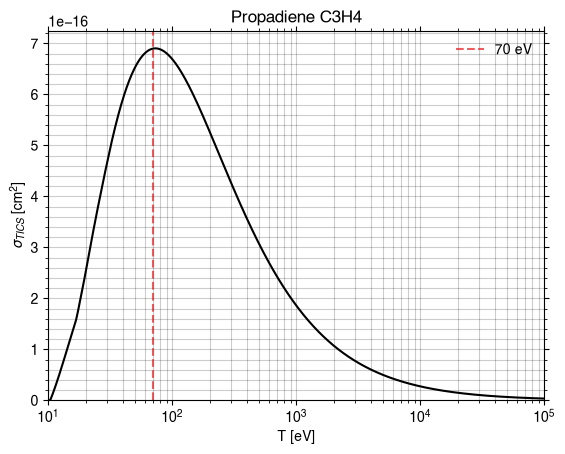

Compound(12309)
Recherche : '1-Pentyne' -> CID 12309, formule C5H8


Loading output/xyz/1-Pentyne_C5H8.xyzBuilt graph: 13 atoms, 12 bondsLoading output/xyz/1-Pentyne_C5H8.xyzBuilt graph: 13 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/1-Pentyne_C5H8.gifGIF written to output/gif/1-Pentyne_C5H8.gif

strucutre 3D
Réussite. Nom: 1-Pentyne, formule: C5H8, M: 68.12, nom_marche: 1-Pentyne
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -194.009511009493
**** MO energy ****
MO #1   energy= -11.2502909309111  occ= 2
MO #2   energy= -11.2296215798582  occ= 2
MO #3   energy= -11.2283915908588  occ= 2
MO #4   energy= -11.2176010048246  occ= 2
MO #5   energy= -11.2156155729914  occ= 2
MO #6   energy= -1.09244799535539  occ= 2
MO #7   energy= -1.01800059724962  occ= 2
MO #8   energy= -0.940065451051918 occ= 2
MO #9   energy= -0.819237805163528 occ= 2
MO #10  energy= -0.715693616479598 occ= 2
MO #11  energy= -0.647157998783    occ= 2
MO #12  energy= -0.638783030721665 occ= 2
MO #13  energy= -0.580823467236699 occ= 2
MO #14  energy= -0.558964196167838 occ= 2
MO #15  energy= -0.509892974647285 occ= 2
MO #16  energy= -0.496150862069692 occ= 2
MO #17  energy= -0.483785363386475 occ= 2
MO #18  energy= -0.3830

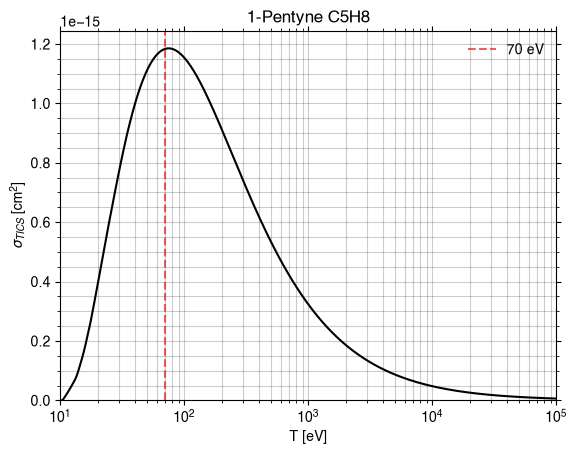

Compound(12310)
Recherche : '2-Pentyne' -> CID 12310, formule C5H8


Loading output/xyz/2-Pentyne_C5H8.xyzBuilt graph: 13 atoms, 12 bondsLoading output/xyz/2-Pentyne_C5H8.xyzBuilt graph: 13 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/2-Pentyne_C5H8.gifGIF written to output/gif/2-Pentyne_C5H8.gif

strucutre 3D
Réussite. Nom: 2-Pentyne, formule: C5H8, M: 68.12, nom_marche: 2-Pentyne
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -194.018415288745
**** MO energy ****
MO #1   energy= -11.2440698946061  occ= 2
MO #2   energy= -11.2413938404447  occ= 2
MO #3   energy= -11.2178320803511  occ= 2
MO #4   energy= -11.2142908844061  occ= 2
MO #5   energy= -11.2094939383752  occ= 2
MO #6   energy= -1.07625563804203  occ= 2
MO #7   energy= -1.02691077821646  occ= 2
MO #8   energy= -0.941415300256129 occ= 2
MO #9   energy= -0.855849062998399 occ= 2
MO #10  energy= -0.659743765288074 occ= 2
MO #11  energy= -0.622465281936839 occ= 2
MO #12  energy= -0.61012657198058  occ= 2
MO #13  energy= -0.582384642192298 occ= 2
MO #14  energy= -0.58059707903744  occ= 2
MO #15  energy= -0.541322795581539 occ= 2
MO #16  energy= -0.51479423329545  occ= 2
MO #17  energy= -0.503830380711093 occ= 2
MO #18  energy= -0.3620

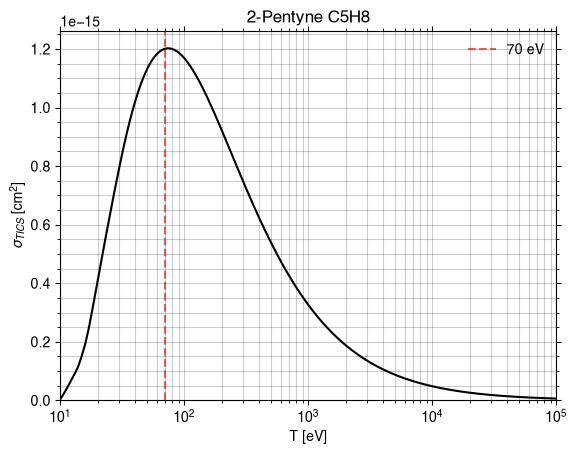

Compound(9088)
Recherche : 'Spiro[2.2]pentane' -> CID 9088, formule C5H8


Loading output/xyz/Spiro_2.2_pentane_C5H8.xyzBuilt graph: 13 atoms, 14 bondsLoading output/xyz/Spiro_2.2_pentane_C5H8.xyzBuilt graph: 13 atoms, 14 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Spiro_2.2_pentane_C5H8.gifGIF written to output/gif/Spiro_2.2_pentane_C5H8.gif

strucutre 3D
Réussite. Nom: Spiro[2.2]pentane, formule: C5H8, M: 68.12, nom_marche: Spiro_2.2_pentane
PYSCF CONVERGENCE
converged SCF energy = -193.988300366217
**** MO energy ****
MO #1   energy= -11.227828253848   occ= 2
MO #2   energy= -11.2209240797129  occ= 2
MO #3   energy= -11.2208040442619  occ= 2
MO #4   energy= -11.2203201108433  occ= 2
MO #5   energy= -11.2203092629796  occ= 2
MO #6   energy= -1.17986282089077  occ= 2
MO #7   energy= -1.06194912827911  occ= 2
MO #8   energy= -0.826560434236527 occ= 2
MO #9   energy= -0.826524465689835 occ= 2
MO #10  energy= -0.738505716925442 occ= 2
MO #11  energy= -0.654945532824314 occ= 2
MO #12  energy= -0.639699578667854 occ= 2
MO #13  energy= -0.639674454845595 occ= 2
MO #14  energy= -0.523731170094279 occ= 2
MO #15  energy= -0.506335565691828 occ= 2
MO #16  energy= -0.482488634599538 occ= 2
MO #17  energy= -0.417721608342483 occ= 2
MO #18  energy= -0.417617140726228 occ= 2
MO #19  energy= -0.382811424202778 occ= 2
MO #20  energy= 0.076

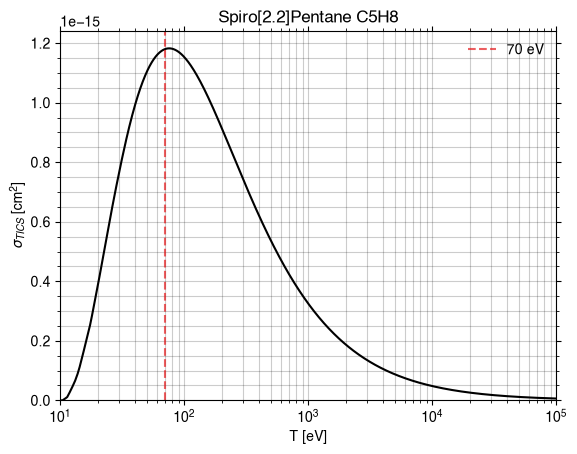

Compound(9250)
Recherche : 'Cyclobutane' -> CID 9250, formule C4H8


Loading output/xyz/Cyclobutane_C4H8.xyzBuilt graph: 12 atoms, 12 bondsLoading output/xyz/Cyclobutane_C4H8.xyzBuilt graph: 12 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyclobutane_C4H8.gifGIF written to output/gif/Cyclobutane_C4H8.gif

strucutre 3D
Réussite. Nom: Cyclobutane, formule: C4H8, M: 56.11, nom_marche: Cyclobutane
PYSCF CONVERGENCE
converged SCF energy = -156.150449147688
**** MO energy ****
MO #1   energy= -11.2151857299993  occ= 2
MO #2   energy= -11.2146168893779  occ= 2
MO #3   energy= -11.2146122906109  occ= 2
MO #4   energy= -11.2140462678028  occ= 2
MO #5   energy= -1.12692674291262  occ= 2
MO #6   energy= -0.888767652297029 occ= 2
MO #7   energy= -0.888757494540938 occ= 2
MO #8   energy= -0.749301821916355 occ= 2
MO #9   energy= -0.645333714462621 occ= 2
MO #10  energy= -0.640474368921326 occ= 2
MO #11  energy= -0.536569577752525 occ= 2
MO #12  energy= -0.536553314216527 occ= 2
MO #13  energy= -0.480837749335802 occ= 2
MO #14  energy= -0.459257873577461 occ= 2
MO #15  energy= -0.429458908865678 occ= 2
MO #16  energy= -0.42943625723715  occ= 2
MO #17  energy= 0.0809301487554363 occ= 0
MO #18  energy= 0.0920145801293161 occ= 0
MO #19  energy= 0.092014896221861  occ= 0
MO #20  energy= 0.092110776058849

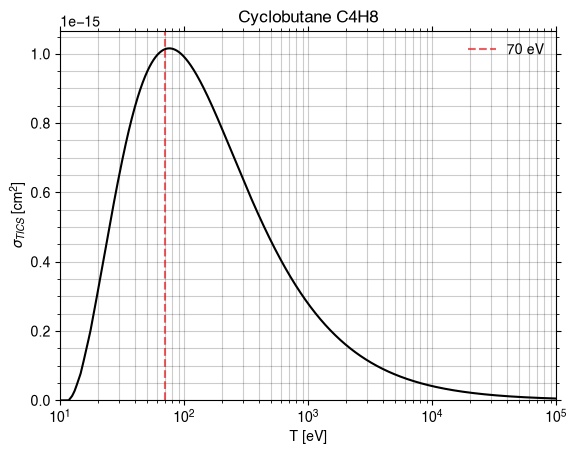

Compound(69972)
Recherche : 'Cyclobutene' -> CID 69972, formule C4H6


Loading output/xyz/Cyclobutene_C4H6.xyzBuilt graph: 10 atoms, 10 bondsLoading output/xyz/Cyclobutene_C4H6.xyzBuilt graph: 10 atoms, 10 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyclobutene_C4H6.gifGIF written to output/gif/Cyclobutene_C4H6.gif

strucutre 3D
Réussite. Nom: Cyclobutene, formule: C4H6, M: 54.09, nom_marche: Cyclobutene
PYSCF CONVERGENCE
converged SCF energy = -154.957109697471
**** MO energy ****
MO #1   energy= -11.2274541816281  occ= 2
MO #2   energy= -11.2258500168325  occ= 2
MO #3   energy= -11.2233669161077  occ= 2
MO #4   energy= -11.2227929616859  occ= 2
MO #5   energy= -1.14880937243823  occ= 2
MO #6   energy= -0.898320276748021 occ= 2
MO #7   energy= -0.874344750494892 occ= 2
MO #8   energy= -0.705603510849656 occ= 2
MO #9   energy= -0.674845350465397 occ= 2
MO #10  energy= -0.624467288148455 occ= 2
MO #11  energy= -0.533018170762201 occ= 2
MO #12  energy= -0.501362907816439 occ= 2
MO #13  energy= -0.46770864350499  occ= 2
MO #14  energy= -0.455635371875636 occ= 2
MO #15  energy= -0.349150953010223 occ= 2
MO #16  energy= 0.0788556168394745 occ= 0
MO #17  energy= 0.0855075646417275 occ= 0
MO #18  energy= 0.0956575024694837 occ= 0
MO #19  energy= 0.11778427630314   occ= 0
MO #20  energy= 0.1417255059889  

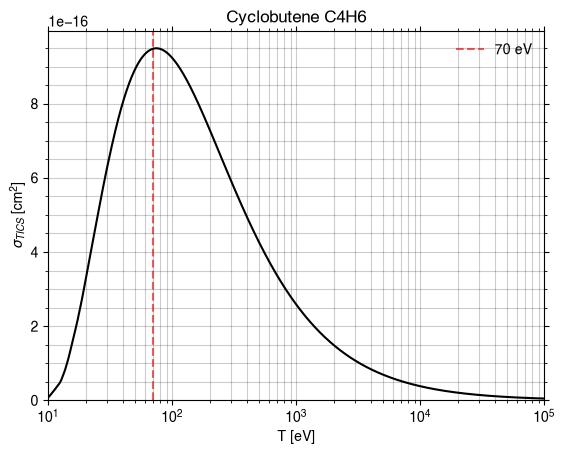

Compound(1140)
Recherche : 'Toluene' -> CID 1140, formule C7H8


Loading output/xyz/Toluene_C7H8.xyzBuilt graph: 15 atoms, 15 bondsLoading output/xyz/Toluene_C7H8.xyzBuilt graph: 15 atoms, 15 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Toluene_C7H8.gifGIF written to output/gif/Toluene_C7H8.gif

strucutre 3D
Réussite. Nom: Toluene, formule: C7H8, M: 92.14, nom_marche: Toluene
PYSCF CONVERGENCE

WARN: 2 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -269.836125396074
**** MO energy ****
MO #1   energy= -11.2377667542341  occ= 2
MO #2   energy= -11.2327219333024  occ= 2
MO #3   energy= -11.232594613738   occ= 2
MO #4   energy= -11.2275007163525  occ= 2
MO #5   energy= -11.2272249312732  occ= 2
MO #6   energy= -11.2271199128072  occ= 2
MO #7   energy= -11.2206200598137  occ= 2
MO #8   energy= -1.15181901074331  occ= 2
MO #9   energy= -1.04464089250944  occ= 2
MO #10  energy= -1.01085229530251  occ= 2
MO #11  energy= -0.929725004808333 occ= 2
MO #12  energy= -0.824411772300827 occ= 2
MO #13  energy= -0.794998322010535 occ= 2
MO #14  energy= -0.690718693447714 occ= 2
MO #15  energy= -0.63280488524245  occ= 2
MO #16  energy= -0.631128653979192 occ= 2
MO #17  energy= -0.584555026757563 occ= 2
MO #18  energy= -0.57961611

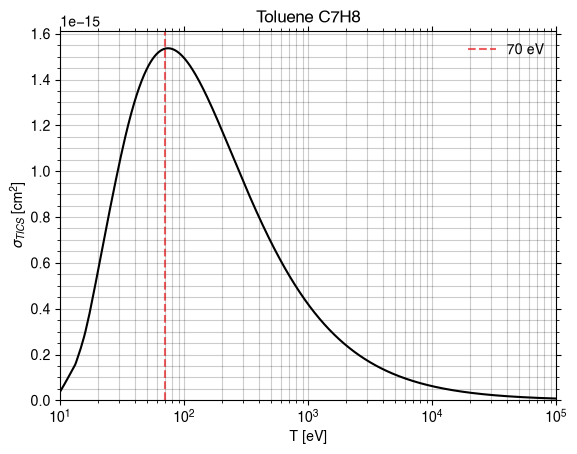

Compound(11000)
Recherche : 'Cycloheptatriene' -> CID 11000, formule C7H8


Loading output/xyz/Cycloheptatriene_C7H8.xyzBuilt graph: 15 atoms, 15 bondsLoading output/xyz/Cycloheptatriene_C7H8.xyzBuilt graph: 15 atoms, 15 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cycloheptatriene_C7H8.gifGIF written to output/gif/Cycloheptatriene_C7H8.gif

strucutre 3D
Réussite. Nom: Cycloheptatriene, formule: C7H8, M: 92.14, nom_marche: Cycloheptatriene
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -269.773682222104
**** MO energy ****
MO #1   energy= -11.2384280421335  occ= 2
MO #2   energy= -11.2369686423219  occ= 2
MO #3   energy= -11.2368017422878  occ= 2
MO #4   energy= -11.227750277288   occ= 2
MO #5   energy= -11.2264202945053  occ= 2
MO #6   energy= -11.2258293121083  occ= 2
MO #7   energy= -11.225491264049   occ= 2
MO #8   energy= -1.12782716440426  occ= 2
MO #9   energy= -1.04440264202759  occ= 2
MO #10  energy= -1.04386896285574  occ= 2
MO #11  energy= -0.913108500689859 occ= 2
MO #12  energy= -0.867239426049011 occ= 2
MO #13  energy= -0.726300567478479 occ= 2
MO #14  energy= -0.699672581731097 occ= 2
MO #15  energy= -0.692204148531131 occ= 2
MO #16  energy= -0.610563366655598 occ= 2
MO #17  energy= -0.601880822794157 occ= 2
MO #18  e

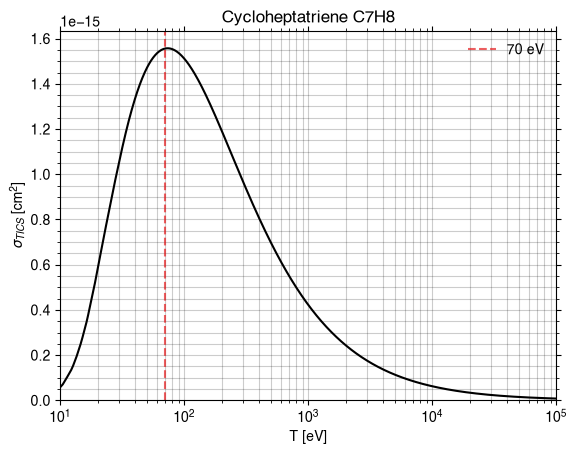

Compound(7501)
Recherche : 'Styrene' -> CID 7501, formule C8H8


Loading output/xyz/Styrene_C8H8.xyzBuilt graph: 16 atoms, 16 bondsLoading output/xyz/Styrene_C8H8.xyzBuilt graph: 16 atoms, 16 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Styrene_C8H8.gifGIF written to output/gif/Styrene_C8H8.gif

strucutre 3D
Réussite. Nom: Styrene, formule: C8H8, M: 104.15, nom_marche: Styrene
PYSCF CONVERGENCE

WARN: 2 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -307.694249694703
**** MO energy ****
MO #1   energy= -11.2424020882665  occ= 2
MO #2   energy= -11.2391818208164  occ= 2
MO #3   energy= -11.2370933117883  occ= 2
MO #4   energy= -11.2363540789169  occ= 2
MO #5   energy= -11.2354999769577  occ= 2
MO #6   energy= -11.234203893531   occ= 2
MO #7   energy= -11.2338113437013  occ= 2
MO #8   energy= -11.228886733068   occ= 2
MO #9   energy= -1.16025229809716  occ= 2
MO #10  energy= -1.07074296393066  occ= 2
MO #11  energy= -1.01672295529038  occ= 2
MO #12  energy= -0.986757681636682 occ= 2
MO #13  energy= -0.850638387204177 occ= 2
MO #14  energy= -0.82771825694903  occ= 2
MO #15  energy= -0.76579337883701  occ= 2
MO #16  energy= -0.698810938225034 occ= 2
MO #17  energy= -0.652757139462567 occ= 2
MO #18  energy= -0.6337097

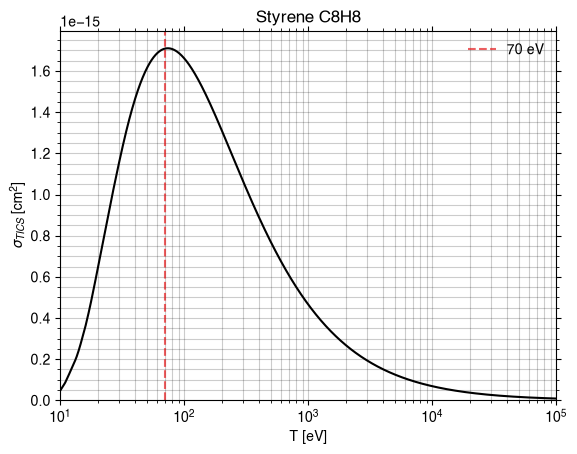

Loading output/xyz/o-Xylene_C8H10.xyz

Compound(7237)
Recherche : 'o-Xylene' -> CID 7237, formule C8H10
3D


  frame 120/120 atoms, 18 bondsLoading output/xyz/o-Xylene_C8H10.xyzBuilt graph: 18 atoms, 18 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/o-Xylene_C8H10.gifGIF written to output/gif/o-Xylene_C8H10.gif

strucutre 3D
Réussite. Nom: o-Xylene, formule: C8H10, M: 106.16, nom_marche: o-Xylene
PYSCF CONVERGENCE

WARN: 3 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -308.885000941543
**** MO energy ****
MO #1   energy= -11.2322658063276  occ= 2
MO #2   energy= -11.2310611462479  occ= 2
MO #3   energy= -11.2263142849204  occ= 2
MO #4   energy= -11.2257494230556  occ= 2
MO #5   energy= -11.2249964922532  occ= 2
MO #6   energy= -11.2243494991203  occ= 2
MO #7   energy= -11.2199787525834  occ= 2
MO #8   energy= -11.2199745257722  occ= 2
MO #9   energy= -1.15541159563664  occ= 2
MO #10  energy= -1.04932028066612  occ= 2
MO #11  energy= -1.03296882414508  occ= 2
MO #12  energy= -0.946423684444181 occ= 2
MO #13  energy= -0.912152852501706 occ= 2
MO #14  energy= -0.812971374147175 occ= 2
MO #15  energy= -0.780056229385931 occ= 2
MO #16  energy= -0.675439233606095 occ= 2
MO #17  energy= -0.644896074262737 occ= 2
MO #18  energy= -0.6213

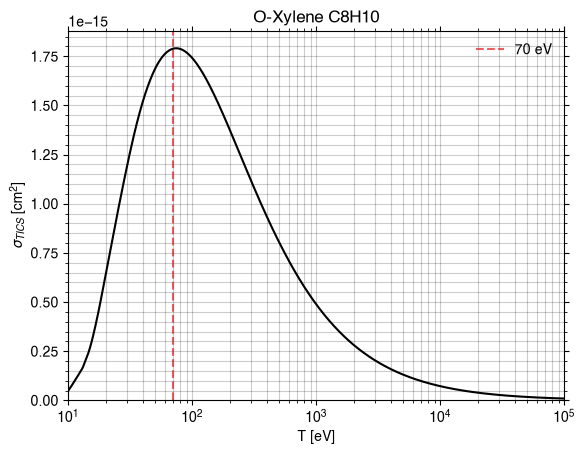

Loading output/xyz/m-Xylene_C8H10.xyzBuilt graph: 18 atoms, 18 bondsLoading output/xyz/m-Xylene_C8H10.xyz

Compound(7929)
Recherche : 'm-Xylene' -> CID 7929, formule C8H10
3D


  frame 120/120 atoms, 18 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/m-Xylene_C8H10.gifGIF written to output/gif/m-Xylene_C8H10.gif

strucutre 3D
Réussite. Nom: m-Xylene, formule: C8H10, M: 106.16, nom_marche: m-Xylene
PYSCF CONVERGENCE

WARN: 2 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -308.886205679428
**** MO energy ****
MO #1   energy= -11.2357612553433  occ= 2
MO #2   energy= -11.2357141248321  occ= 2
MO #3   energy= -11.2304422712005  occ= 2
MO #4   energy= -11.2202992539376  occ= 2
MO #5   energy= -11.2202186933391  occ= 2
MO #6   energy= -11.2199261039613  occ= 2
MO #7   energy= -11.2188565966307  occ= 2
MO #8   energy= -11.2188467895312  occ= 2
MO #9   energy= -1.15364696795985  occ= 2
MO #10  energy= -1.05708952228831  occ= 2
MO #11  energy= -1.02665534274225  occ= 2
MO #12  energy= -0.937039532761221 occ= 2
MO #13  energy= -0.921873546790729 occ= 2
MO #14  energy= -0.811878949007436 occ= 2
MO #15  energy= -0.776098656993589 occ= 2
MO #16  energy= -0.679716162394239 occ= 2
MO #17  energy= -0.642816627146598 occ= 2
MO #18  energy= -0.6172

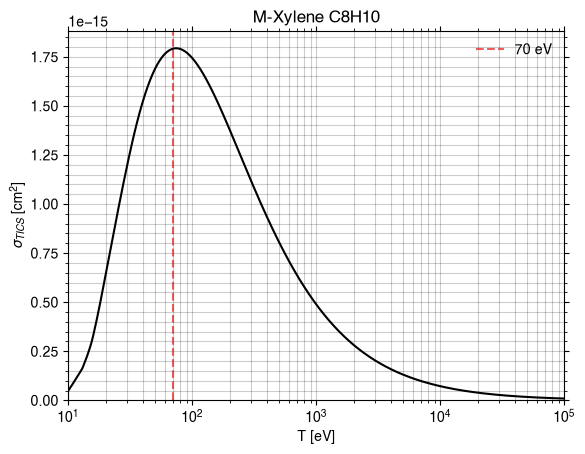

Compound(7809)
Recherche : 'p-Xylene' -> CID 7809, formule C8H10


Loading output/xyz/p-Xylene_C8H10.xyzBuilt graph: 18 atoms, 18 bondsLoading output/xyz/p-Xylene_C8H10.xyzBuilt graph: 18 atoms, 18 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/p-Xylene_C8H10.gifGIF written to output/gif/p-Xylene_C8H10.gif

strucutre 3D
Réussite. Nom: p-Xylene, formule: C8H10, M: 106.16, nom_marche: p-Xylene
PYSCF CONVERGENCE

WARN: 2 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -308.885336579606
**** MO energy ****
MO #1   energy= -11.2309426801669  occ= 2
MO #2   energy= -11.230937888      occ= 2
MO #3   energy= -11.2260425501373  occ= 2
MO #4   energy= -11.2258661740007  occ= 2
MO #5   energy= -11.2248053817423  occ= 2
MO #6   energy= -11.2246909160476  occ= 2
MO #7   energy= -11.217222127964   occ= 2
MO #8   energy= -11.2172029698538  occ= 2
MO #9   energy= -1.15335535247904  occ= 2
MO #10  energy= -1.06233026769436  occ= 2
MO #11  energy= -1.00856755460581  occ= 2
MO #12  energy= -0.971263147729406 occ= 2
MO #13  energy= -0.887462869277424 occ= 2
MO #14  energy= -0.826057467316627 occ= 2
MO #15  energy= -0.778903245372849 occ= 2
MO #16  energy= -0.664240238756741 occ= 2
MO #17  energy= -0.643307236792346 occ= 2
MO #18  energy= -0.6266

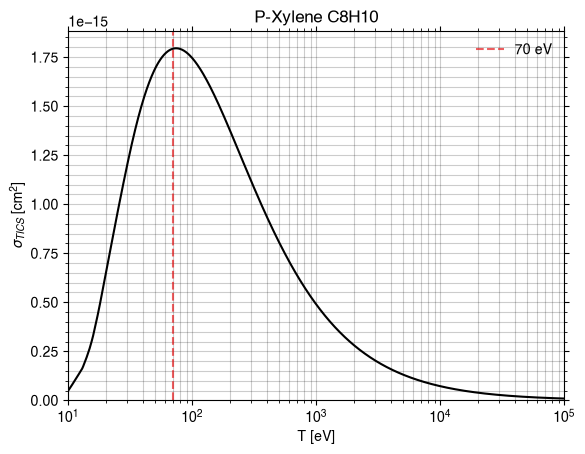

Loading output/xyz/Naphthalene_C10H8.xyzBuilt graph: 18 atoms, 19 bondsLoading output/xyz/Naphthalene_C10H8.xyzBuilt graph: 18 atoms, 19 bonds

Compound(931)
Recherche : 'Naphthalene' -> CID 931, formule C10H8
3D


  frame 120/120ion GIF (120 frames, axis=y)
Wrote output/gif/Naphthalene_C10H8.gifGIF written to output/gif/Naphthalene_C10H8.gif

strucutre 3D
Réussite. Nom: Naphthalene, formule: C10H8, M: 128.17, nom_marche: Naphthalene
PYSCF CONVERGENCE

WARN: 5 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -383.482379316958
**** MO energy ****
MO #1   energy= -11.241312550523   occ= 2
MO #2   energy= -11.2402904626465  occ= 2
MO #3   energy= -11.2377608033021  occ= 2
MO #4   energy= -11.2376797335021  occ= 2
MO #5   energy= -11.2376029323432  occ= 2
MO #6   energy= -11.2374252474228  occ= 2
MO #7   energy= -11.2360176269676  occ= 2
MO #8   energy= -11.2359893226877  occ= 2
MO #9   energy= -11.2349128222649  occ= 2
MO #10  energy= -11.2348921959576  occ= 2
MO #11  energy= -1.18071592704137  occ= 2
MO #12  energy= -1.10928389412788  occ= 2
MO #13  energy= -1.05117630312568  occ= 2
MO #14  energy= -1.01444370223598  occ= 2
MO #15  energy= -0.973872890451865 occ= 2
MO #16  energy= -0.860184346111204 occ= 2
MO #17  energy= -0.83371106859247  occ= 2
MO #18  energy= -

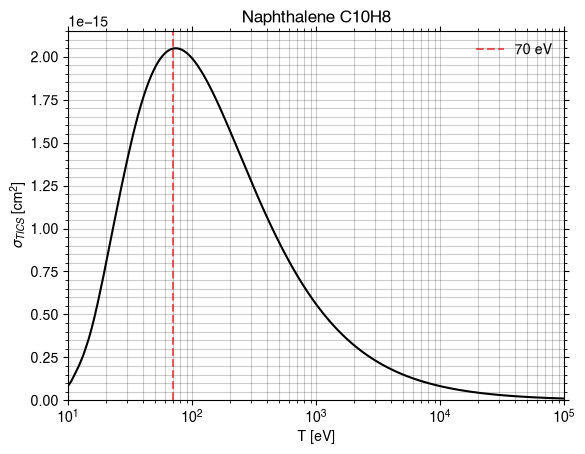

Loading output/xyz/Propan-2-ol_C3H8O.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/Propan-2-ol_C3H8O.xyzBuilt graph: 12 atoms, 11 bonds

Compound(3776)
Recherche : 'Propan-2-ol' -> CID 3776, formule C3H8O
3D


  frame 120/120ion GIF (120 frames, axis=y)
Wrote output/gif/Propan-2-ol_C3H8O.gifGIF written to output/gif/Propan-2-ol_C3H8O.gif

strucutre 3D
Réussite. Nom: Propan-2-ol, formule: C3H8O, M: 60.1, nom_marche: Propan-2-ol
PYSCF CONVERGENCE
converged SCF energy = -193.201099518077
**** MO energy ****
MO #1   energy= -20.5499181024083  occ= 2
MO #2   energy= -11.2785694086706  occ= 2
MO #3   energy= -11.215330360713   occ= 2
MO #4   energy= -11.2153118036561  occ= 2
MO #5   energy= -1.35501559845112  occ= 2
MO #6   energy= -1.0409749112675   occ= 2
MO #7   energy= -0.939236216367132 occ= 2
MO #8   energy= -0.813554959472068 occ= 2
MO #9   energy= -0.66057463695474  occ= 2
MO #10  energy= -0.642876435970228 occ= 2
MO #11  energy= -0.600988566698781 occ= 2
MO #12  energy= -0.574630602935002 occ= 2
MO #13  energy= -0.544944093734216 occ= 2
MO #14  energy= -0.516103149169728 occ= 2
MO #15  energy= -0.507700653670384 occ= 2
MO #16  energy= -0.470558810498034 occ= 2
MO #17  energy= -0.435894317614029 occ= 2
MO #18  energy= 0.0694170234865652 occ= 0
MO #19  energy= 0.091713242958026  occ= 0
MO #20  energy= 0.094611778696479

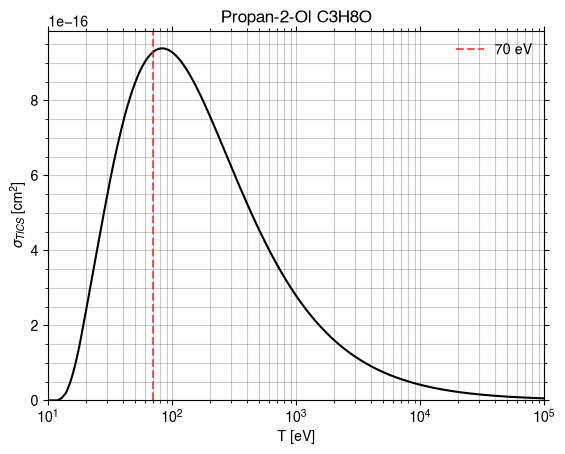

Compound(1031)
Recherche : '1-Propanol' -> CID 1031, formule C3H8O


Loading output/xyz/1-Propanol_C3H8O.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/1-Propanol_C3H8O.xyzBuilt graph: 12 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/1-Propanol_C3H8O.gifGIF written to output/gif/1-Propanol_C3H8O.gif

strucutre 3D
Réussite. Nom: 1-Propanol, formule: C3H8O, M: 60.1, nom_marche: 1-Propanol
PYSCF CONVERGENCE
converged SCF energy = -193.196283184685
**** MO energy ****
MO #1   energy= -20.5505855647063  occ= 2
MO #2   energy= -11.2708791014808  occ= 2
MO #3   energy= -11.220765448775   occ= 2
MO #4   energy= -11.2168439434658  occ= 2
MO #5   energy= -1.35313963956775  occ= 2
MO #6   energy= -1.05407104133834  occ= 2
MO #7   energy= -0.914163247101129 occ= 2
MO #8   energy= -0.815706801705034 occ= 2
MO #9   energy= -0.68852100654621  occ= 2
MO #10  energy= -0.633528652469241 occ= 2
MO #11  energy= -0.600002431411375 occ= 2
MO #12  energy= -0.586808909276395 occ= 2
MO #13  energy= -0.546725178950219 occ= 2
MO #14  energy= -0.502244439513612 occ= 2
MO #15  energy= -0.496427630683616 occ= 2
MO #16  energy= -0.471440438424118 occ= 2
MO #17  energy= -0.434332191086707 occ= 2
MO #18  energy= 0.0698277584034433 occ= 0
MO #19  energy= 0.0806559903712963 occ= 0
MO #20  energy= 0.0917368407254378 

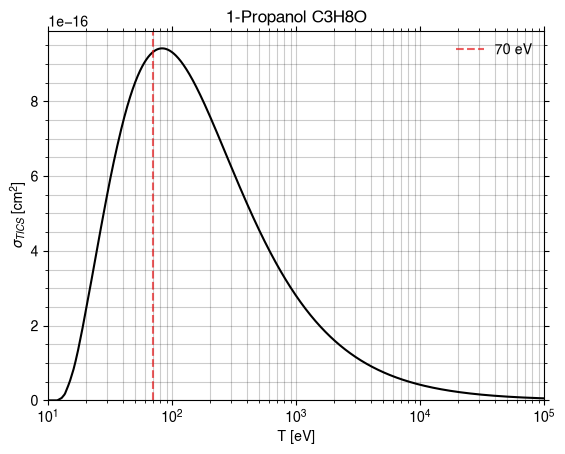

Loading output/xyz/Allyl_alcohol_C3H6O.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Allyl_alcohol_C3H6O.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

Compound(7858)
Recherche : 'Allyl alcohol' -> CID 7858, formule C3H6O
3D


  frame 120/120
Wrote output/gif/Allyl_alcohol_C3H6O.gifGIF written to output/gif/Allyl_alcohol_C3H6O.gif

strucutre 3D
Réussite. Nom: Allyl alcohol, formule: C3H6O, M: 58.08, nom_marche: Allyl_alcohol
PYSCF CONVERGENCE
converged SCF energy = -192.004330617527
**** MO energy ****
MO #1   energy= -20.5574161407293  occ= 2
MO #2   energy= -11.2814853352949  occ= 2
MO #3   energy= -11.2374690817678  occ= 2
MO #4   energy= -11.2319657435337  occ= 2
MO #5   energy= -1.36023183215466  occ= 2
MO #6   energy= -1.06377132442358  occ= 2
MO #7   energy= -0.921275165297232 occ= 2
MO #8   energy= -0.775405687390879 occ= 2
MO #9   energy= -0.700496541295283 occ= 2
MO #10  energy= -0.628754095657492 occ= 2
MO #11  energy= -0.615318307279687 occ= 2
MO #12  energy= -0.606506331840357 occ= 2
MO #13  energy= -0.531627771751946 occ= 2
MO #14  energy= -0.492997548795703 occ= 2
MO #15  energy= -0.454462846960158 occ= 2
MO #16  energy= -0.374631920515604 occ= 2
MO #17  energy= 0.0695054284653758 occ= 0
MO #18  energy= 0.0860023244790502 occ= 0
MO #19  energy= 0.0920356724776385 occ= 0
MO #20  energy= 0.1002016703

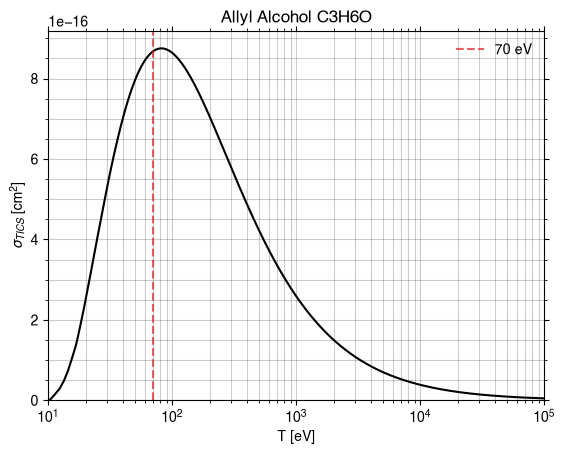

Loading output/xyz/Propargyl_alcohol_C3H4O.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Propargyl_alcohol_C3H4O.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

Compound(7859)
Recherche : 'Propargyl alcohol' -> CID 7859, formule C3H4O
3D


  frame 120/120
Wrote output/gif/Propargyl_alcohol_C3H4O.gifGIF written to output/gif/Propargyl_alcohol_C3H4O.gif

strucutre 3D
Réussite. Nom: Propargyl alcohol, formule: C3H4O, M: 56.06, nom_marche: Propargyl_alcohol
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -190.792543848668
**** MO energy ****
MO #1   energy= -20.57017430616    occ= 2
MO #2   energy= -11.3115639582398  occ= 2
MO #3   energy= -11.2397548507387  occ= 2
MO #4   energy= -11.2332534523458  occ= 2
MO #5   energy= -1.37252785739189  occ= 2
MO #6   energy= -1.05309839872073  occ= 2
MO #7   energy= -0.948567633467224 occ= 2
MO #8   energy= -0.744024555122909 occ= 2
MO #9   energy= -0.702831741594856 occ= 2
MO #10  energy= -0.666246252598359 occ= 2
MO #11  energy= -0.626618853891706 occ= 2
MO #12  energy= -0.537536917915414 occ= 2
MO #13  energy= -0.482053612674825 occ= 2
MO #14  energy= -0.403550027520497 occ= 2
MO #15  energy= -0.396815352727624 occ= 2
MO #16  energy= 0.0625126676903349 occ= 0
MO #17  energy= 0.0857032654560473 occ= 0
MO #18

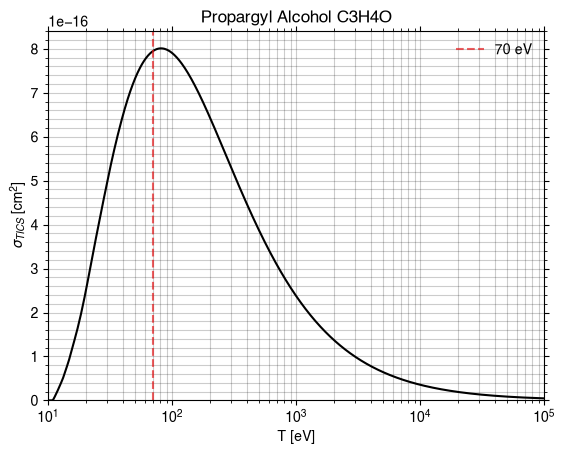

Compound(6560)
Recherche : 'Isobutanol' -> CID 6560, formule C4H10O


Loading output/xyz/Isobutanol_C4H10O.xyzBuilt graph: 15 atoms, 14 bondsLoading output/xyz/Isobutanol_C4H10O.xyzBuilt graph: 15 atoms, 14 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Isobutanol_C4H10O.gifGIF written to output/gif/Isobutanol_C4H10O.gif

strucutre 3D
Réussite. Nom: Isobutanol, formule: C4H10O, M: 74.12, nom_marche: Isobutanol
PYSCF CONVERGENCE
converged SCF energy = -232.245987507017
**** MO energy ****
MO #1   energy= -20.5527377331761  occ= 2
MO #2   energy= -11.2697331028782  occ= 2
MO #3   energy= -11.2238731754134  occ= 2
MO #4   energy= -11.2126758236747  occ= 2
MO #5   energy= -11.2035720759524  occ= 2
MO #6   energy= -1.35427656916031  occ= 2
MO #7   energy= -1.07558341050703  occ= 2
MO #8   energy= -0.924894106549377 occ= 2
MO #9   energy= -0.910474223385083 occ= 2
MO #10  energy= -0.769976173436024 occ= 2
MO #11  energy= -0.687587300444818 occ= 2
MO #12  energy= -0.650608289032256 occ= 2
MO #13  energy= -0.607644067019585 occ= 2
MO #14  energy= -0.585627866504378 occ= 2
MO #15  energy= -0.542780931241937 occ= 2
MO #16  energy= -0.53289456927537  occ= 2
MO #17  energy= -0.526799301050396 occ= 2
MO #18  energy= -0.473262428359002 occ= 2
MO #19  energy= -0.471535768295488 occ= 2
MO #20  energy= -0.45800854265115

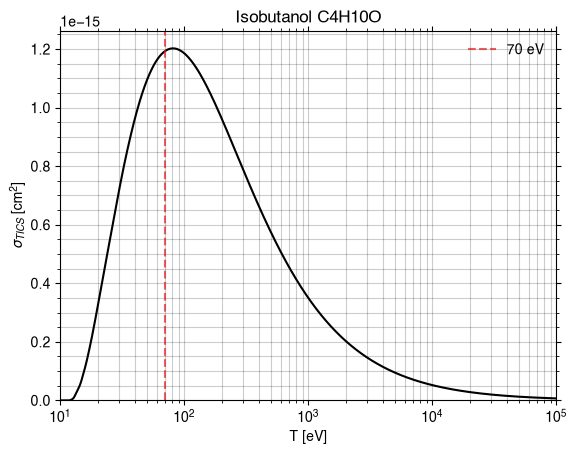

Loading output/xyz/1-Butanol_C4H10O.xyz

Compound(263)
Recherche : '1-Butanol' -> CID 263, formule C4H10O
3D


  frame 120/120 atoms, 14 bondsLoading output/xyz/1-Butanol_C4H10O.xyzBuilt graph: 15 atoms, 14 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/1-Butanol_C4H10O.gifGIF written to output/gif/1-Butanol_C4H10O.gif

strucutre 3D
Réussite. Nom: 1-Butanol, formule: C4H10O, M: 74.12, nom_marche: 1-Butanol
PYSCF CONVERGENCE
converged SCF energy = -232.244659312138
**** MO energy ****
MO #1   energy= -20.549822569855   occ= 2
MO #2   energy= -11.2699452247751  occ= 2
MO #3   energy= -11.2213808987236  occ= 2
MO #4   energy= -11.2184966417956  occ= 2
MO #5   energy= -11.2136090557083  occ= 2
MO #6   energy= -1.35241871437033  occ= 2
MO #7   energy= -1.07403948095011  occ= 2
MO #8   energy= -0.972890488625968 occ= 2
MO #9   energy= -0.857650672879547 occ= 2
MO #10  energy= -0.80154741327992  occ= 2
MO #11  energy= -0.688158914762404 occ= 2
MO #12  energy= -0.638877124089561 occ= 2
MO #13  energy= -0.613722827335163 occ= 2
MO #14  energy= -0.599943197187154 occ= 2
MO #15  energy= -0.551631738717212 occ= 2
MO #16  energy= -0.540541796956354 occ= 2
MO #17  energy= -0.516702014475563 occ= 2
MO #18  energy= -0.483397290372806 occ= 2
MO #19  energy= -0.477543441727525 occ= 2
MO #20  energy= -0.467241977746528 

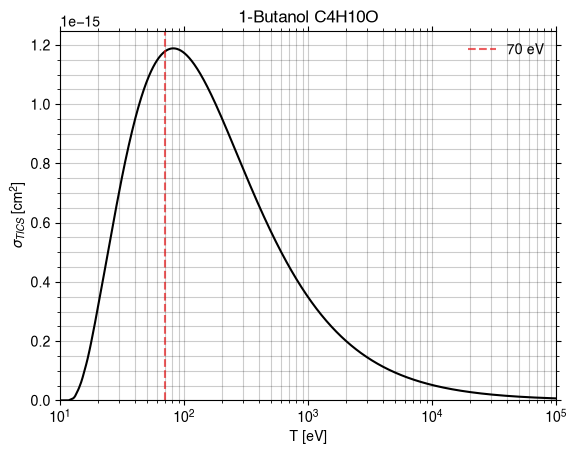

Loading output/xyz/2-Butanol_C4H10O.xyzBuilt graph: 15 atoms, 14 bondsLoading output/xyz/2-Butanol_C4H10O.xyz

Compound(6568)
Recherche : '2-Butanol' -> CID 6568, formule C4H10O
3D


  frame 120/120 atoms, 14 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/2-Butanol_C4H10O.gifGIF written to output/gif/2-Butanol_C4H10O.gif

strucutre 3D
Réussite. Nom: 2-Butanol, formule: C4H10O, M: 74.12, nom_marche: 2-Butanol
PYSCF CONVERGENCE
converged SCF energy = -232.249508467608
**** MO energy ****
MO #1   energy= -20.550988405803   occ= 2
MO #2   energy= -11.2758773770351  occ= 2
MO #3   energy= -11.2164170766398  occ= 2
MO #4   energy= -11.2142539712982  occ= 2
MO #5   energy= -11.2034118543926  occ= 2
MO #6   energy= -1.3554645190347   occ= 2
MO #7   energy= -1.0578276293153   occ= 2
MO #8   energy= -0.982323365863412 occ= 2
MO #9   energy= -0.863101582214092 occ= 2
MO #10  energy= -0.786048199793211 occ= 2
MO #11  energy= -0.697388980292164 occ= 2
MO #12  energy= -0.62446822133867  occ= 2
MO #13  energy= -0.598114687579659 occ= 2
MO #14  energy= -0.582984312574067 occ= 2
MO #15  energy= -0.562158709601302 occ= 2
MO #16  energy= -0.536651309104329 occ= 2
MO #17  energy= -0.509905746191269 occ= 2
MO #18  energy= -0.494781527516472 occ= 2
MO #19  energy= -0.479434069416685 occ= 2
MO #20  energy= -0.453769710259857 

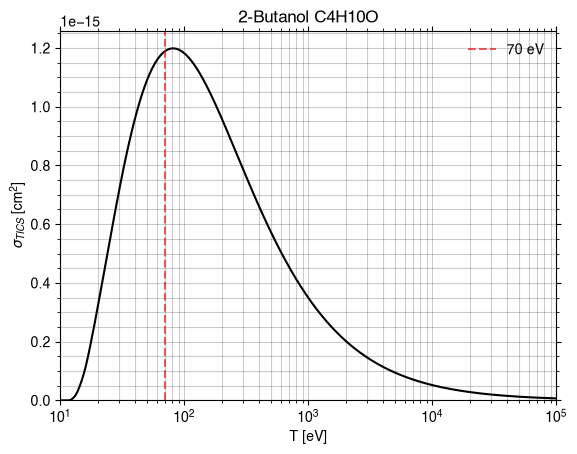

Compound(6386)
Recherche : 'tert-Butanol' -> CID 6386, formule C4H10O
3D


  frame 120/120xyz/tert-Butanol_C4H10O.xyzBuilt graph: 15 atoms, 14 bondsLoading output/xyz/tert-Butanol_C4H10O.xyzBuilt graph: 15 atoms, 14 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/tert-Butanol_C4H10O.gifGIF written to output/gif/tert-Butanol_C4H10O.gif

strucutre 3D
Réussite. Nom: tert-Butanol, formule: C4H10O, M: 74.12, nom_marche: tert-Butanol
PYSCF CONVERGENCE
converged SCF energy = -232.252792299863
**** MO energy ****
MO #1   energy= -20.5484194801487  occ= 2
MO #2   energy= -11.2844983543307  occ= 2
MO #3   energy= -11.2143915396291  occ= 2
MO #4   energy= -11.2132695340679  occ= 2
MO #5   energy= -11.212020978223   occ= 2
MO #6   energy= -1.35584019675443  occ= 2
MO #7   energy= -1.06254749008804  occ= 2
MO #8   energy= -0.939162036970259 occ= 2
MO #9   energy= -0.937562888630959 occ= 2
MO #10  energy= -0.772309306722775 occ= 2
MO #11  energy= -0.667936257825126 occ= 2
MO #12  energy= -0.62559034102479  occ= 2
MO #13  energy= -0.618823412539543 occ= 2
MO #14  energy= -0.571140709465431 occ= 2
MO #15  energy= -0.5577082814395   occ= 2
MO #16  energy= -0.535076201865571 occ= 2
MO #17  energy= -0.511799304329483 occ= 2
MO #18  energy= -0.510100781736472 occ= 2
MO #19  energy= -0.503537617503841 occ= 2
MO #20  energy= -0.4610434442

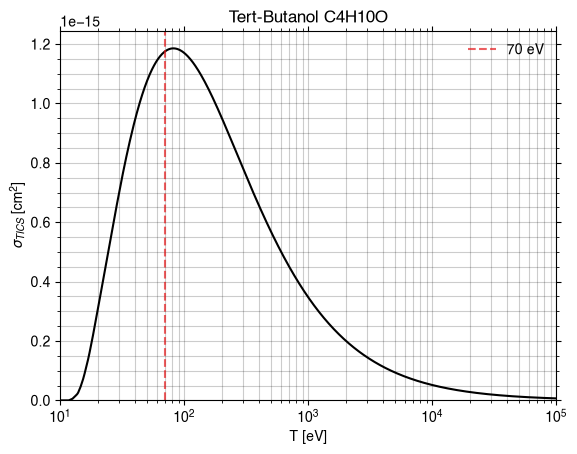

Compound(650)
Recherche : 'Diacetyl' -> CID 650, formule C4H6O2


Loading output/xyz/Diacetyl_C4H6O2.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/Diacetyl_C4H6O2.xyzBuilt graph: 12 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Diacetyl_C4H6O2.gifGIF written to output/gif/Diacetyl_C4H6O2.gif

strucutre 3D
Réussite. Nom: Diacetyl, formule: C4H6O2, M: 86.09, nom_marche: Diacetyl
PYSCF CONVERGENCE
converged SCF energy = -304.793218306167
**** MO energy ****
MO #1   energy= -20.5719526274569  occ= 2
MO #2   energy= -20.571940332465   occ= 2
MO #3   energy= -11.3491263949829  occ= 2
MO #4   energy= -11.3484849798365  occ= 2
MO #5   energy= -11.2559904067105  occ= 2
MO #6   energy= -11.2559732483053  occ= 2
MO #7   energy= -1.41693220051219  occ= 2
MO #8   energy= -1.37984022934342  occ= 2
MO #9   energy= -1.07244108868555  occ= 2
MO #10  energy= -1.01209677671234  occ= 2
MO #11  energy= -0.88483700032879  occ= 2
MO #12  energy= -0.724805360511688 occ= 2
MO #13  energy= -0.694957569768892 occ= 2
MO #14  energy= -0.663460227319342 occ= 2
MO #15  energy= -0.648906416304125 occ= 2
MO #16  energy= -0.608417204796321 occ= 2
MO #17  energy= -0.606523933499622 occ= 2
MO #18  energy= -0.580564516792297 occ= 2
MO #19  energy= -0.578033326413558 occ= 2
MO #20  energy= -0.537699614487902 oc

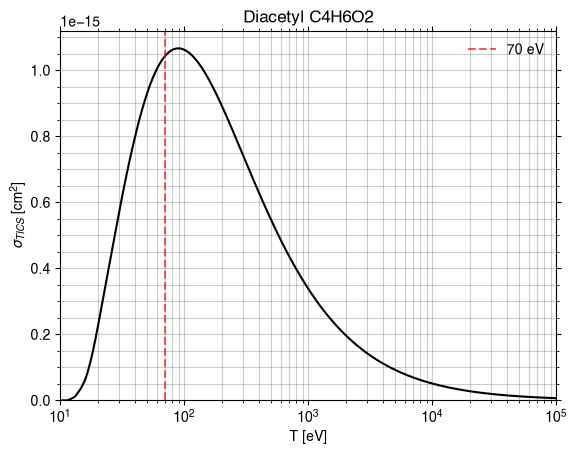

Compound(6569)
Recherche : 'Methyl ethyl ketone' -> CID 6569, formule C4H8O


Loading output/xyz/Methyl_ethyl_ketone_C4H8O.xyzBuilt graph: 13 atoms, 12 bondsLoading output/xyz/Methyl_ethyl_ketone_C4H8O.xyzBuilt graph: 13 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methyl_ethyl_ketone_C4H8O.gifGIF written to output/gif/Methyl_ethyl_ketone_C4H8O.gif

strucutre 3D
Réussite. Nom: Methyl ethyl ketone, formule: C4H8O, M: 72.11, nom_marche: Methyl_ethyl_ketone
PYSCF CONVERGENCE
converged SCF energy = -231.087990765184
**** MO energy ****
MO #1   energy= -20.5425701366552  occ= 2
MO #2   energy= -11.3302606893883  occ= 2
MO #3   energy= -11.2399298882203  occ= 2
MO #4   energy= -11.2337226134189  occ= 2
MO #5   energy= -11.2160435737762  occ= 2
MO #6   energy= -1.37316614642617  occ= 2
MO #7   energy= -1.06559498238323  occ= 2
MO #8   energy= -1.0021337190585   occ= 2
MO #9   energy= -0.874638782054703 occ= 2
MO #10  energy= -0.731404355692799 occ= 2
MO #11  energy= -0.65342937800495  occ= 2
MO #12  energy= -0.644678616862467 occ= 2
MO #13  energy= -0.619626174743679 occ= 2
MO #14  energy= -0.587525421773265 occ= 2
MO #15  energy= -0.564908793186259 occ= 2
MO #16  energy= -0.515743839074628 occ= 2
MO #17  energy= -0.510647576355106 occ= 2
MO #18  energy= -0.50589281069643  occ= 2
MO #19  energy= -0.482384929011374 occ= 2
MO #20  energy= 

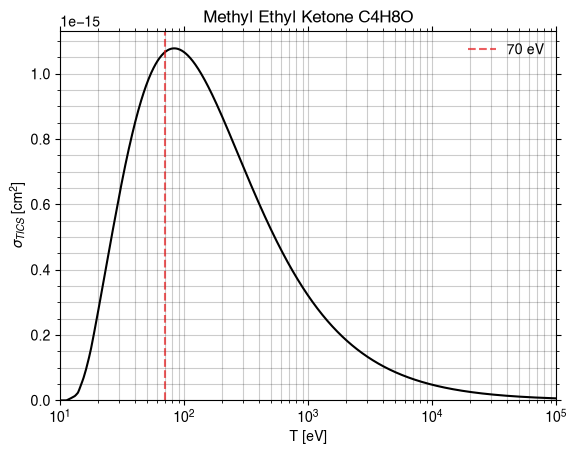

Compound(14496)
Recherche : 'Cyclobutanone' -> CID 14496, formule C4H6O


Loading output/xyz/Cyclobutanone_C4H6O.xyzBuilt graph: 11 atoms, 11 bondsLoading output/xyz/Cyclobutanone_C4H6O.xyzBuilt graph: 11 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyclobutanone_C4H6O.gifGIF written to output/gif/Cyclobutanone_C4H6O.gif

strucutre 3D
Réussite. Nom: Cyclobutanone, formule: C4H6O, M: 70.09, nom_marche: Cyclobutanone
PYSCF CONVERGENCE
converged SCF energy = -229.883617697127
**** MO energy ****
MO #1   energy= -20.5535662775424  occ= 2
MO #2   energy= -11.3364532051074  occ= 2
MO #3   energy= -11.2436271105868  occ= 2
MO #4   energy= -11.2431939776898  occ= 2
MO #5   energy= -11.2428262625912  occ= 2
MO #6   energy= -1.3846102034508   occ= 2
MO #7   energy= -1.14009543920493  occ= 2
MO #8   energy= -0.934269192130536 occ= 2
MO #9   energy= -0.865251813874718 occ= 2
MO #10  energy= -0.729513814932645 occ= 2
MO #11  energy= -0.669037945991442 occ= 2
MO #12  energy= -0.663691502653455 occ= 2
MO #13  energy= -0.614567318969062 occ= 2
MO #14  energy= -0.571150336282777 occ= 2
MO #15  energy= -0.540759761927127 occ= 2
MO #16  energy= -0.503920824695787 occ= 2
MO #17  energy= -0.485897033257126 occ= 2
MO #18  energy= -0.481514277740533 occ= 2
MO #19  energy= -0.400875776253134 occ= 2
MO #20  energy= 0.0680842102

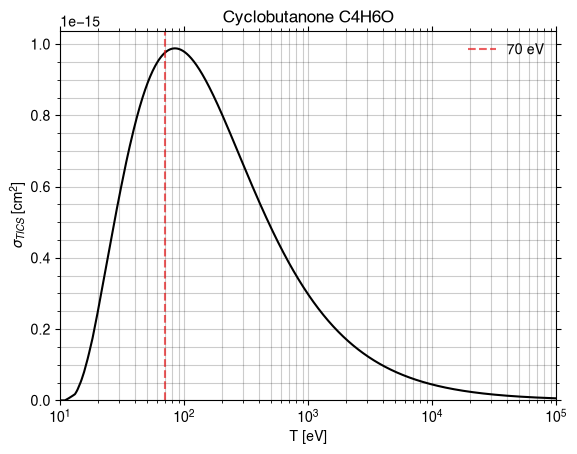

Compound(8452)
Recherche : 'Cyclopentanone' -> CID 8452, formule C5H8O


Loading output/xyz/Cyclopentanone_C5H8O.xyzBuilt graph: 14 atoms, 14 bondsLoading output/xyz/Cyclopentanone_C5H8O.xyzBuilt graph: 14 atoms, 14 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyclopentanone_C5H8O.gifGIF written to output/gif/Cyclopentanone_C5H8O.gif

strucutre 3D
Réussite. Nom: Cyclopentanone, formule: C5H8O, M: 84.12, nom_marche: Cyclopentanone
PYSCF CONVERGENCE
converged SCF energy = -268.964073232417
**** MO energy ****
MO #1   energy= -20.5372672549263  occ= 2
MO #2   energy= -11.3235264993683  occ= 2
MO #3   energy= -11.2346391605767  occ= 2
MO #4   energy= -11.2346285864096  occ= 2
MO #5   energy= -11.2333920798373  occ= 2
MO #6   energy= -11.2327853320001  occ= 2
MO #7   energy= -1.37099169687719  occ= 2
MO #8   energy= -1.14081544181496  occ= 2
MO #9   energy= -0.998340996813916 occ= 2
MO #10  energy= -0.939091966230283 occ= 2
MO #11  energy= -0.807419065188309 occ= 2
MO #12  energy= -0.736756484894403 occ= 2
MO #13  energy= -0.677878367459244 occ= 2
MO #14  energy= -0.661341437122714 occ= 2
MO #15  energy= -0.603697631234839 occ= 2
MO #16  energy= -0.595920324510707 occ= 2
MO #17  energy= -0.566669281591171 occ= 2
MO #18  energy= -0.546114848134831 occ= 2
MO #19  energy= -0.505263052494463 occ= 2
MO #20  energy= -0.4937212

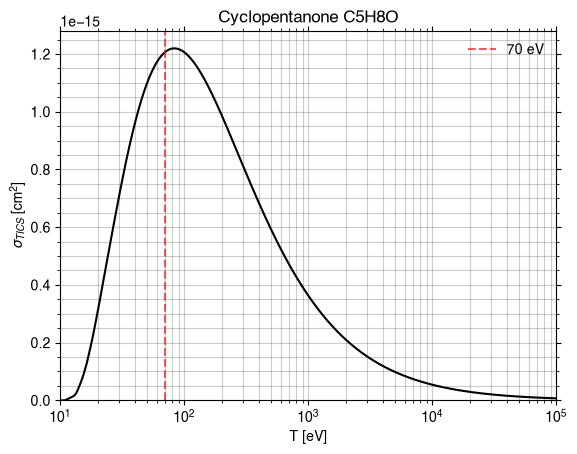

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Tetrahydrofuran_C4H8O.xyzBuilt graph: 13 atoms, 13 bondsLoading output/xyz/Tetrahydrofuran_C4H8O.xyzBuilt graph: 13 atoms, 13 bondsRendering rotation GIF (120 frames, axis=y)

Compound(8028)
Recherche : 'Tetrahydrofuran' -> CID 8028, formule C4H8O
3D


  frame 120/120
Wrote output/gif/Tetrahydrofuran_C4H8O.gifGIF written to output/gif/Tetrahydrofuran_C4H8O.gif

strucutre 3D
Réussite. Nom: Tetrahydrofuran, formule: C4H8O, M: 72.11, nom_marche: Tetrahydrofuran
PYSCF CONVERGENCE
converged SCF energy = -231.066818569916
**** MO energy ****
MO #1   energy= -20.5432854474888  occ= 2
MO #2   energy= -11.2664979050073  occ= 2
MO #3   energy= -11.2664740844322  occ= 2
MO #4   energy= -11.2228538675411  occ= 2
MO #5   energy= -11.2221799742674  occ= 2
MO #6   energy= -1.36289028769439  occ= 2
MO #7   energy= -1.06767541023848  occ= 2
MO #8   energy= -0.99084367502758  occ= 2
MO #9   energy= -0.810524294667434 occ= 2
MO #10  energy= -0.80621171586081  occ= 2
MO #11  energy= -0.684344793604602 occ= 2
MO #12  energy= -0.674172379630383 occ= 2
MO #13  energy= -0.591778850727677 occ= 2
MO #14  energy= -0.590140572552292 occ= 2
MO #15  energy= -0.557705999169187 occ= 2
MO #16  energy= -0.506291681611578 occ= 2
MO #17  energy= -0.493615494776611 occ= 2
MO #18  energy= -0.473515923221468 occ= 2
MO #19  energy= -0.468349461825162 occ= 2
MO #20  energy= -0.40790

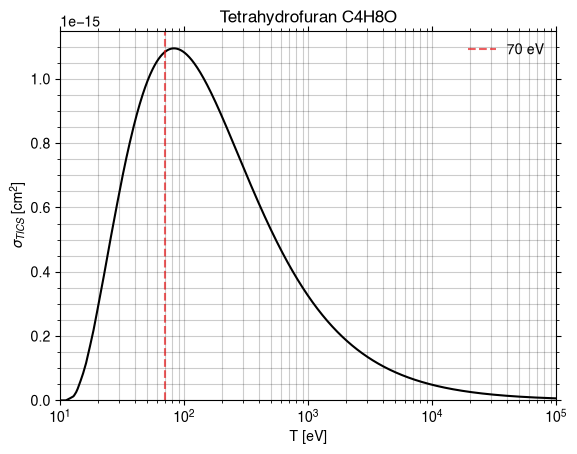

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(31275)
Recherche : '1,4-Dioxane' -> CID 31275, formule C4H8O2


Loading output/xyz/1_4-Dioxane_C4H8O2.xyzBuilt graph: 14 atoms, 14 bondsLoading output/xyz/1_4-Dioxane_C4H8O2.xyzBuilt graph: 14 atoms, 14 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/1_4-Dioxane_C4H8O2.gifGIF written to output/gif/1_4-Dioxane_C4H8O2.gif

strucutre 3D
Réussite. Nom: 1,4-Dioxane, formule: C4H8O2, M: 88.11, nom_marche: 1_4-Dioxane
PYSCF CONVERGENCE
converged SCF energy = -305.948820315247
**** MO energy ****
MO #1   energy= -20.5571909908714  occ= 2
MO #2   energy= -20.5571877112444  occ= 2
MO #3   energy= -11.277301489288   occ= 2
MO #4   energy= -11.2772801590588  occ= 2
MO #5   energy= -11.2766488023216  occ= 2
MO #6   energy= -11.2766347933245  occ= 2
MO #7   energy= -1.39272976022114  occ= 2
MO #8   energy= -1.34990128035097  occ= 2
MO #9   energy= -1.04555851180062  occ= 2
MO #10  energy= -0.949624993428763 occ= 2
MO #11  energy= -0.887964304952273 occ= 2
MO #12  energy= -0.799654208184279 occ= 2
MO #13  energy= -0.695554780968568 occ= 2
MO #14  energy= -0.649733331724051 occ= 2
MO #15  energy= -0.647351098930766 occ= 2
MO #16  energy= -0.63539064325043  occ= 2
MO #17  energy= -0.635029714413492 occ= 2
MO #18  energy= -0.554495531106728 occ= 2
MO #19  energy= -0.549223438951516 occ= 2
MO #20  energy= -0.517269888855

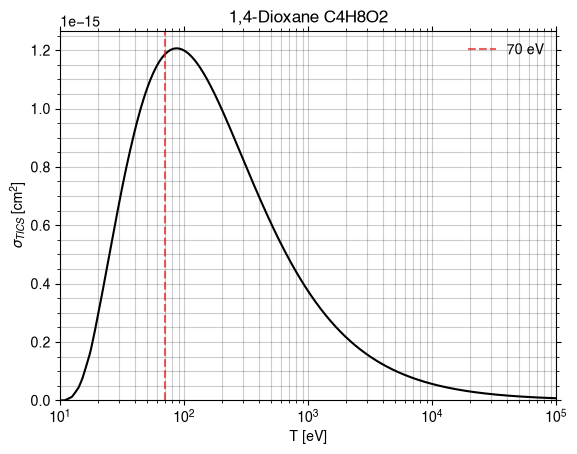

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(1030)
Recherche : 'Propylene glycol' -> CID 1030, formule C3H8O2


Loading output/xyz/Propylene_glycol_C3H8O2.xyzBuilt graph: 13 atoms, 12 bondsLoading output/xyz/Propylene_glycol_C3H8O2.xyzBuilt graph: 13 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Propylene_glycol_C3H8O2.gifGIF written to output/gif/Propylene_glycol_C3H8O2.gif

strucutre 3D
Réussite. Nom: Propylene glycol, formule: C3H8O2, M: 76.09, nom_marche: Propylene_glycol
PYSCF CONVERGENCE
converged SCF energy = -268.089182478143
**** MO energy ****
MO #1   energy= -20.5642593347859  occ= 2
MO #2   energy= -20.54547588073    occ= 2
MO #3   energy= -11.2839272448487  occ= 2
MO #4   energy= -11.2741010978949  occ= 2
MO #5   energy= -11.2246254025855  occ= 2
MO #6   energy= -1.3747621280938   occ= 2
MO #7   energy= -1.34091512549226  occ= 2
MO #8   energy= -1.0411962686482   occ= 2
MO #9   energy= -0.925882783750716 occ= 2
MO #10  energy= -0.816176377724805 occ= 2
MO #11  energy= -0.720689000953008 occ= 2
MO #12  energy= -0.661142285985768 occ= 2
MO #13  energy= -0.640844762596569 occ= 2
MO #14  energy= -0.612979525932371 occ= 2
MO #15  energy= -0.581771340408665 occ= 2
MO #16  energy= -0.558389194835129 occ= 2
MO #17  energy= -0.547374129777211 occ= 2
MO #18  energy= -0.512525875077163 occ= 2
MO #19  energy= -0.485274933529126 occ= 2
MO #20  energy= -0.45

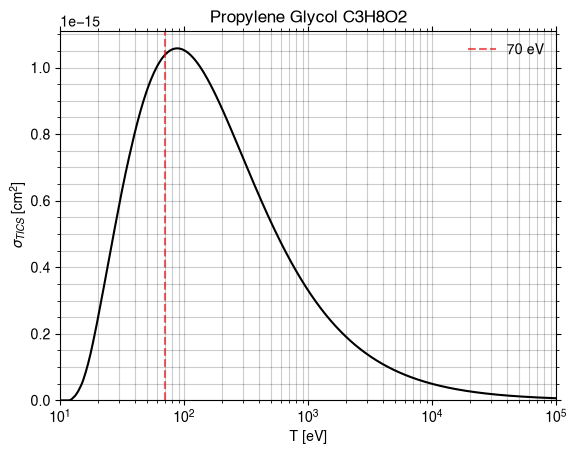

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Glycerol_C3H8O3.xyzBuilt graph: 14 atoms, 13 bondsLoading output/xyz/Glycerol_C3H8O3.xyzBuilt graph: 14 atoms, 13 bondsRendering rotation GIF (120 frames, axis=y)

Compound(753)
Recherche : 'Glycerol' -> CID 753, formule C3H8O3
3D


  frame 120/120
Wrote output/gif/Glycerol_C3H8O3.gifGIF written to output/gif/Glycerol_C3H8O3.gif

strucutre 3D
Réussite. Nom: Glycerol, formule: C3H8O3, M: 92.09, nom_marche: Glycerol
PYSCF CONVERGENCE
converged SCF energy = -342.96865793513
**** MO energy ****
MO #1   energy= -20.5640851072384  occ= 2
MO #2   energy= -20.5635713482094  occ= 2
MO #3   energy= -20.5544004863734  occ= 2
MO #4   energy= -11.2883954637432  occ= 2
MO #5   energy= -11.2875840680661  occ= 2
MO #6   energy= -11.2836482451153  occ= 2
MO #7   energy= -1.38342077466505  occ= 2
MO #8   energy= -1.3609321548039   occ= 2
MO #9   energy= -1.34366389154643  occ= 2
MO #10  energy= -1.03642522701487  occ= 2
MO #11  energy= -0.916950104163824 occ= 2
MO #12  energy= -0.832585876716561 occ= 2
MO #13  energy= -0.718148628746114 occ= 2
MO #14  energy= -0.694235430313523 occ= 2
MO #15  energy= -0.672422610297316 occ= 2
MO #16  energy= -0.655786552368814 occ= 2
MO #17  energy= -0.631655725596865 occ= 2
MO #18  energy= -0.604252775275501 occ= 2
MO #19  energy= -0.567419498989631 occ= 2
MO #20  energy= -0.552333641509848 occ

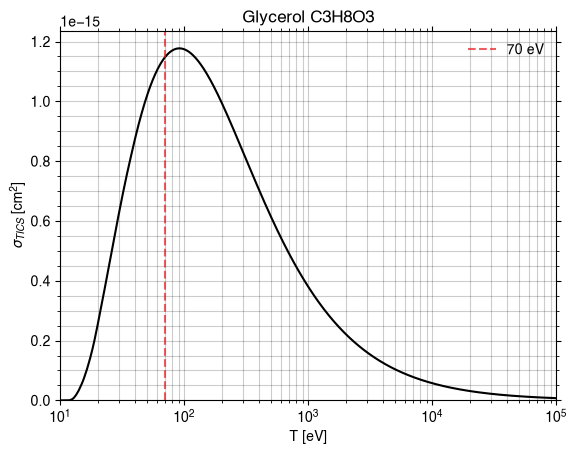

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Ethyl_acetate_C4H8O2.xyzBuilt graph: 14 atoms, 13 bondsLoading output/xyz/Ethyl_acetate_C4H8O2.xyzBuilt graph: 14 atoms, 13 bondsRendering rotation GIF (120 frames, axis=y)

Compound(8857)
Recherche : 'Ethyl acetate' -> CID 8857, formule C4H8O2
3D


  frame 120/120
Wrote output/gif/Ethyl_acetate_C4H8O2.gifGIF written to output/gif/Ethyl_acetate_C4H8O2.gif

strucutre 3D
Réussite. Nom: Ethyl acetate, formule: C4H8O2, M: 88.11, nom_marche: Ethyl_acetate
PYSCF CONVERGENCE
converged SCF energy = -305.99743842421
**** MO energy ****
MO #1   energy= -20.604203735515   occ= 2
MO #2   energy= -20.5452593332602  occ= 2
MO #3   energy= -11.3837505685745  occ= 2
MO #4   energy= -11.2881727563676  occ= 2
MO #5   energy= -11.2387378410823  occ= 2
MO #6   energy= -11.2252887384148  occ= 2
MO #7   energy= -1.451335914292    occ= 2
MO #8   energy= -1.35490398995041  occ= 2
MO #9   energy= -1.05535830124655  occ= 2
MO #10  energy= -1.00037726300851  occ= 2
MO #11  energy= -0.863311216333404 occ= 2
MO #12  energy= -0.781216086741644 occ= 2
MO #13  energy= -0.688378133225228 occ= 2
MO #14  energy= -0.686092654798115 occ= 2
MO #15  energy= -0.66352505518298  occ= 2
MO #16  energy= -0.611819991222063 occ= 2
MO #17  energy= -0.576388529264576 occ= 2
MO #18  energy= -0.567828251056415 occ= 2
MO #19  energy= -0.551771448334696 occ= 2
MO #20  energy= -0.539886260

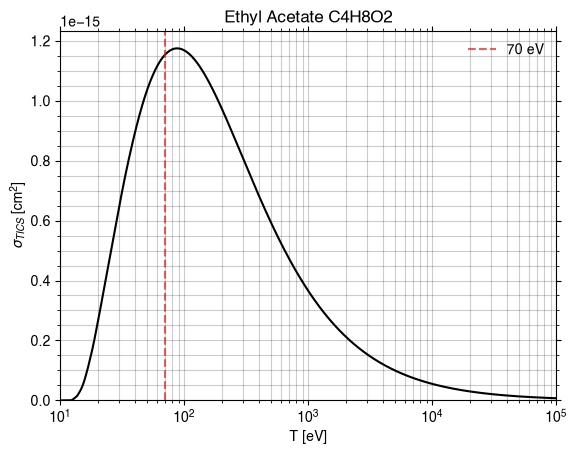

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(11124)
Recherche : 'Methyl propionate' -> CID 11124, formule C4H8O2


Loading output/xyz/Methyl_propionate_C4H8O2.xyzBuilt graph: 14 atoms, 13 bondsLoading output/xyz/Methyl_propionate_C4H8O2.xyzBuilt graph: 14 atoms, 13 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methyl_propionate_C4H8O2.gifGIF written to output/gif/Methyl_propionate_C4H8O2.gif

strucutre 3D
Réussite. Nom: Methyl propionate, formule: C4H8O2, M: 88.11, nom_marche: Methyl_propionate
PYSCF CONVERGENCE
converged SCF energy = -305.99239375265
**** MO energy ****
MO #1   energy= -20.6046351433526  occ= 2
MO #2   energy= -20.5473731142104  occ= 2
MO #3   energy= -11.3824895267625  occ= 2
MO #4   energy= -11.2858752412067  occ= 2
MO #5   energy= -11.2432466205523  occ= 2
MO #6   energy= -11.2181082275712  occ= 2
MO #7   energy= -1.44987676629275  occ= 2
MO #8   energy= -1.35503420756161  occ= 2
MO #9   energy= -1.06519893309498  occ= 2
MO #10  energy= -0.971859324608008 occ= 2
MO #11  energy= -0.87425525143605  occ= 2
MO #12  energy= -0.766926778173548 occ= 2
MO #13  energy= -0.696764374059154 occ= 2
MO #14  energy= -0.678403018561651 occ= 2
MO #15  energy= -0.670479150395729 occ= 2
MO #16  energy= -0.624038967150639 occ= 2
MO #17  energy= -0.601209827329743 occ= 2
MO #18  energy= -0.539880088302503 occ= 2
MO #19  energy= -0.532983435385545 occ= 2
MO #20  energy= -0.5

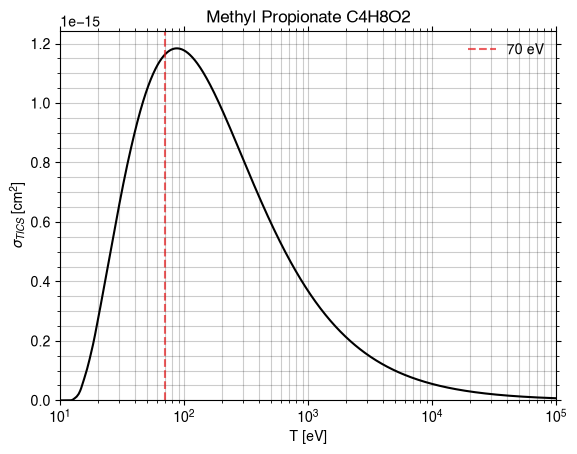

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(7904)
Recherche : 'Vinyl acetate' -> CID 7904, formule C4H6O2


Loading output/xyz/Vinyl_acetate_C4H6O2.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/Vinyl_acetate_C4H6O2.xyzBuilt graph: 12 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Vinyl_acetate_C4H6O2.gifGIF written to output/gif/Vinyl_acetate_C4H6O2.gif

strucutre 3D
Réussite. Nom: Vinyl acetate, formule: C4H6O2, M: 86.09, nom_marche: Vinyl_acetate
PYSCF CONVERGENCE
converged SCF energy = -304.797296800931
**** MO energy ****
MO #1   energy= -20.6270458911412  occ= 2
MO #2   energy= -20.557712946249   occ= 2
MO #3   energy= -11.3976902823463  occ= 2
MO #4   energy= -11.3048235756503  occ= 2
MO #5   energy= -11.2456737524245  occ= 2
MO #6   energy= -11.2367245746504  occ= 2
MO #7   energy= -1.47430490104199  occ= 2
MO #8   energy= -1.37153022395322  occ= 2
MO #9   energy= -1.0643795464322   occ= 2
MO #10  energy= -1.00901565837047  occ= 2
MO #11  energy= -0.855141344090605 occ= 2
MO #12  energy= -0.773998000477476 occ= 2
MO #13  energy= -0.703609840904331 occ= 2
MO #14  energy= -0.683476156307903 occ= 2
MO #15  energy= -0.675109469385159 occ= 2
MO #16  energy= -0.617899261396264 occ= 2
MO #17  energy= -0.594505696217045 occ= 2
MO #18  energy= -0.577062371584097 occ= 2
MO #19  energy= -0.55769727536706  occ= 2
MO #20  energy= -0.53049727

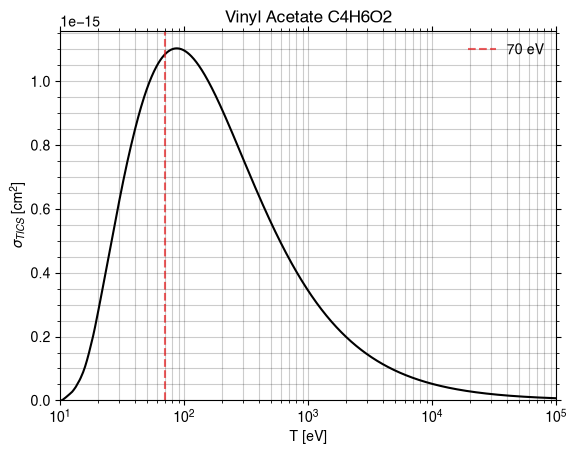

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(674)
Recherche : 'Dimethylamine' -> CID 674, formule C2H7N


Loading output/xyz/Dimethylamine_C2H7N.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Dimethylamine_C2H7N.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Dimethylamine_C2H7N.gifGIF written to output/gif/Dimethylamine_C2H7N.gif

strucutre 3D
Réussite. Nom: Dimethylamine, formule: C2H7N, M: 45.08, nom_marche: Dimethylamine
PYSCF CONVERGENCE
converged SCF energy = -134.296484005637
**** MO energy ****
MO #1   energy= -15.5404105715121  occ= 2
MO #2   energy= -11.2384945345301  occ= 2
MO #3   energy= -11.2384684260669  occ= 2
MO #4   energy= -1.19697776442164  occ= 2
MO #5   energy= -0.943088806980349 occ= 2
MO #6   energy= -0.851476305531449 occ= 2
MO #7   energy= -0.658411399569857 occ= 2
MO #8   energy= -0.613535591749532 occ= 2
MO #9   energy= -0.587445818997105 occ= 2
MO #10  energy= -0.540864610099305 occ= 2
MO #11  energy= -0.512425571648945 occ= 2
MO #12  energy= -0.501146371598672 occ= 2
MO #13  energy= -0.368327779338003 occ= 2
MO #14  energy= 0.0756381662747568 occ= 0
MO #15  energy= 0.093886743140508  occ= 0
MO #16  energy= 0.113703613873359  occ= 0
MO #17  energy= 0.141717072462872  occ= 0
MO #18  energy= 0.152883478917709  occ= 0
MO #19  energy= 0.166088245365097  occ= 0
MO #20  energy= 0.1805801188

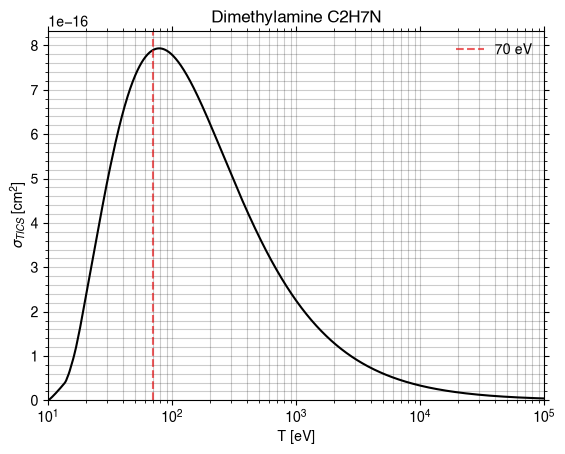

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(1146)
Recherche : 'Trimethylamine' -> CID 1146, formule C3H9N


Loading output/xyz/Trimethylamine_C3H9N.xyzBuilt graph: 13 atoms, 12 bondsLoading output/xyz/Trimethylamine_C3H9N.xyzBuilt graph: 13 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Trimethylamine_C3H9N.gifGIF written to output/gif/Trimethylamine_C3H9N.gif

strucutre 3D
Réussite. Nom: Trimethylamine, formule: C3H9N, M: 59.11, nom_marche: Trimethylamine
PYSCF CONVERGENCE
converged SCF energy = -173.338237397468
**** MO energy ****
MO #1   energy= -15.5474184532623  occ= 2
MO #2   energy= -11.2391017287307  occ= 2
MO #3   energy= -11.2390942247247  occ= 2
MO #4   energy= -11.2390720564166  occ= 2
MO #5   energy= -1.21801207132115  occ= 2
MO #6   energy= -0.946154350333504 occ= 2
MO #7   energy= -0.946143497305244 occ= 2
MO #8   energy= -0.807500067465824 occ= 2
MO #9   energy= -0.641670318119934 occ= 2
MO #10  energy= -0.623889903315192 occ= 2
MO #11  energy= -0.623873599907489 occ= 2
MO #12  energy= -0.544582692990189 occ= 2
MO #13  energy= -0.544562899054307 occ= 2
MO #14  energy= -0.512532056711932 occ= 2
MO #15  energy= -0.498156919919688 occ= 2
MO #16  energy= -0.498138671936715 occ= 2
MO #17  energy= -0.357048901123427 occ= 2
MO #18  energy= 0.0737367973654882 occ= 0
MO #19  energy= 0.0943711155787519 occ= 0
MO #20  energy= 0.09437191

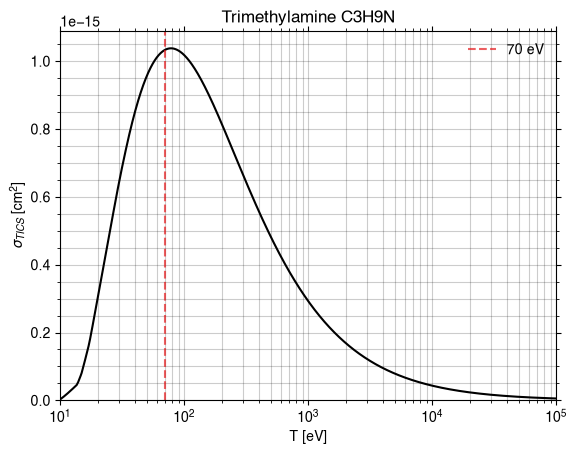

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Propylamine_C3H9N.xyzBuilt graph: 13 atoms, 12 bondsLoading output/xyz/Propylamine_C3H9N.xyzBuilt graph: 13 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

Compound(7852)
Recherche : 'Propylamine' -> CID 7852, formule C3H9N
3D


  frame 120/120
Wrote output/gif/Propylamine_C3H9N.gifGIF written to output/gif/Propylamine_C3H9N.gif

strucutre 3D
Réussite. Nom: Propylamine, formule: C3H9N, M: 59.11, nom_marche: Propylamine
PYSCF CONVERGENCE
converged SCF energy = -173.355839288925
**** MO energy ****
MO #1   energy= -15.5338142213935  occ= 2
MO #2   energy= -11.2428860695456  occ= 2
MO #3   energy= -11.2164746560739  occ= 2
MO #4   energy= -11.211621963772   occ= 2
MO #5   energy= -1.17740417493177  occ= 2
MO #6   energy= -1.03604744522159  occ= 2
MO #7   energy= -0.893706822715473 occ= 2
MO #8   energy= -0.80528130057359  occ= 2
MO #9   energy= -0.675776625009277 occ= 2
MO #10  energy= -0.605803833636878 occ= 2
MO #11  energy= -0.602086457334366 occ= 2
MO #12  energy= -0.565236182870812 occ= 2
MO #13  energy= -0.518403059871184 occ= 2
MO #14  energy= -0.516021658669836 occ= 2
MO #15  energy= -0.489845915762667 occ= 2
MO #16  energy= -0.474460333518098 occ= 2
MO #17  energy= -0.379874365028229 occ= 2
MO #18  energy= 0.0760990952574417 occ= 0
MO #19  energy= 0.0858853242461137 occ= 0
MO #20  energy= 0.09669820596514

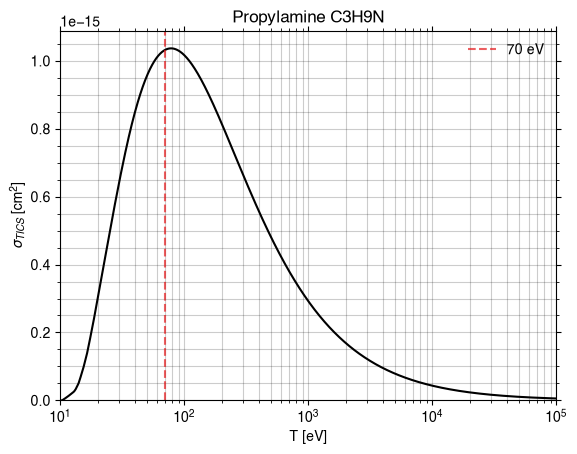

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6363)
Recherche : 'Isopropylamine' -> CID 6363, formule C3H9N


Loading output/xyz/Isopropylamine_C3H9N.xyzBuilt graph: 13 atoms, 12 bondsLoading output/xyz/Isopropylamine_C3H9N.xyzBuilt graph: 13 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Isopropylamine_C3H9N.gifGIF written to output/gif/Isopropylamine_C3H9N.gif

strucutre 3D
Réussite. Nom: Isopropylamine, formule: C3H9N, M: 59.11, nom_marche: Isopropylamine
PYSCF CONVERGENCE
converged SCF energy = -173.359449690549
**** MO energy ****
MO #1   energy= -15.5337463880337  occ= 2
MO #2   energy= -11.2510228200645  occ= 2
MO #3   energy= -11.2107482036069  occ= 2
MO #4   energy= -11.2096610628472  occ= 2
MO #5   energy= -1.1835113359293   occ= 2
MO #6   energy= -1.00977227629462  occ= 2
MO #7   energy= -0.930669312155665 occ= 2
MO #8   energy= -0.789545758560507 occ= 2
MO #9   energy= -0.665897078782017 occ= 2
MO #10  energy= -0.609602658921103 occ= 2
MO #11  energy= -0.594500383961103 occ= 2
MO #12  energy= -0.559166852113773 occ= 2
MO #13  energy= -0.536574829828747 occ= 2
MO #14  energy= -0.50914682535123  occ= 2
MO #15  energy= -0.487881993810194 occ= 2
MO #16  energy= -0.47431936335935  occ= 2
MO #17  energy= -0.384310647821493 occ= 2
MO #18  energy= 0.074273480445844  occ= 0
MO #19  energy= 0.0932254292810361 occ= 0
MO #20  energy= 0.09862032

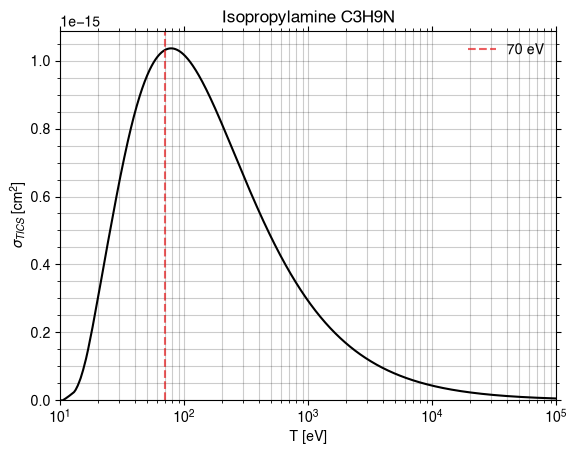

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(7853)
Recherche : 'Allylamine' -> CID 7853, formule C3H7N


Loading output/xyz/Allylamine_C3H7N.xyzBuilt graph: 11 atoms, 10 bondsLoading output/xyz/Allylamine_C3H7N.xyzBuilt graph: 11 atoms, 10 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Allylamine_C3H7N.gifGIF written to output/gif/Allylamine_C3H7N.gif

strucutre 3D
Réussite. Nom: Allylamine, formule: C3H7N, M: 57.09, nom_marche: Allylamine
PYSCF CONVERGENCE
converged SCF energy = -172.165338478583
**** MO energy ****
MO #1   energy= -15.5421547741966  occ= 2
MO #2   energy= -11.2531442958292  occ= 2
MO #3   energy= -11.2317867539566  occ= 2
MO #4   energy= -11.2226767480709  occ= 2
MO #5   energy= -1.18334739898643  occ= 2
MO #6   energy= -1.0449717674197   occ= 2
MO #7   energy= -0.897758090353079 occ= 2
MO #8   energy= -0.759493693893063 occ= 2
MO #9   energy= -0.671266496486126 occ= 2
MO #10  energy= -0.635488322344649 occ= 2
MO #11  energy= -0.597834152951171 occ= 2
MO #12  energy= -0.575464294273188 occ= 2
MO #13  energy= -0.528296002538831 occ= 2
MO #14  energy= -0.492791717156592 occ= 2
MO #15  energy= -0.39570506851318  occ= 2
MO #16  energy= -0.365179959898469 occ= 2
MO #17  energy= 0.074478908542042  occ= 0
MO #18  energy= 0.0875678646243364 occ= 0
MO #19  energy= 0.0993639656913382 occ= 0
MO #20  energy= 0.11119938201377  

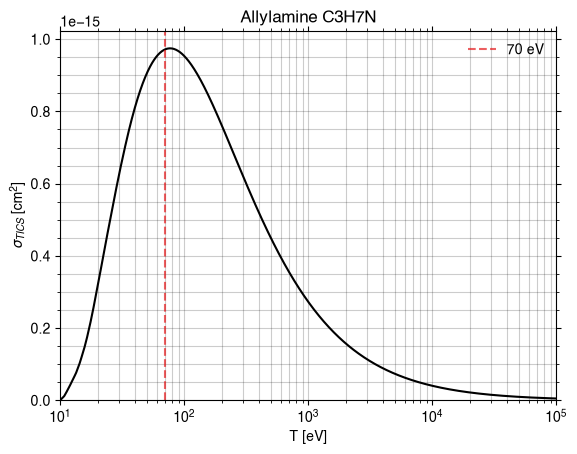

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Pyrrole_C4H5N.xyzBuilt graph: 10 atoms, 10 bondsLoading output/xyz/Pyrrole_C4H5N.xyzBuilt graph: 10 atoms, 10 bondsRendering rotation GIF (120 frames, axis=y)

Compound(8027)
Recherche : 'Pyrrole' -> CID 8027, formule C4H5N
3D


  frame 120/120
Wrote output/gif/Pyrrole_C4H5N.gifGIF written to output/gif/Pyrrole_C4H5N.gif

strucutre 3D
Réussite. Nom: Pyrrole, formule: C4H5N, M: 67.09, nom_marche: Pyrrole
PYSCF CONVERGENCE
converged SCF energy = -208.891371742872
**** MO energy ****
MO #1   energy= -15.6055272138178  occ= 2
MO #2   energy= -11.2509720153322  occ= 2
MO #3   energy= -11.2509256163254  occ= 2
MO #4   energy= -11.2085381477939  occ= 2
MO #5   energy= -11.2074692042312  occ= 2
MO #6   energy= -1.29046213756127  occ= 2
MO #7   energy= -1.0415813480171   occ= 2
MO #8   energy= -0.975000181052089 occ= 2
MO #9   energy= -0.791687188599968 occ= 2
MO #10  energy= -0.766286708540676 occ= 2
MO #11  energy= -0.734053007195347 occ= 2
MO #12  energy= -0.592508392221192 occ= 2
MO #13  energy= -0.579729225612254 occ= 2
MO #14  energy= -0.567606874799293 occ= 2
MO #15  energy= -0.546134230825856 occ= 2
MO #16  energy= -0.528587566298045 occ= 2
MO #17  energy= -0.347932684076774 occ= 2
MO #18  energy= -0.297072468367716 occ= 2
MO #19  energy= 0.068926686047758  occ= 0
MO #20  energy= 0.0908213447533696 occ= 

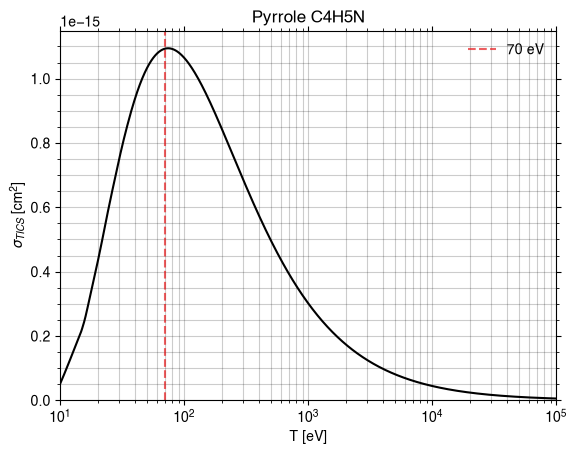

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(1049)
Recherche : 'Pyridine' -> CID 1049, formule C5H5N


Loading output/xyz/Pyridine_C5H5N.xyzBuilt graph: 11 atoms, 11 bondsLoading output/xyz/Pyridine_C5H5N.xyzBuilt graph: 11 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Pyridine_C5H5N.gifGIF written to output/gif/Pyridine_C5H5N.gif

strucutre 3D
Réussite. Nom: Pyridine, formule: C5H5N, M: 79.1, nom_marche: Pyridine
PYSCF CONVERGENCE
converged SCF energy = -246.783336559438
**** MO energy ****
MO #1   energy= -15.5681655161652  occ= 2
MO #2   energy= -11.2752236863131  occ= 2
MO #3   energy= -11.275206366656   occ= 2
MO #4   energy= -11.2598436553971  occ= 2
MO #5   energy= -11.2413354314648  occ= 2
MO #6   energy= -11.2412827266209  occ= 2
MO #7   energy= -1.25088002106853  occ= 2
MO #8   energy= -1.08874693411997  occ= 2
MO #9   energy= -1.03521740629702  occ= 2
MO #10  energy= -0.859633101795144 occ= 2
MO #11  energy= -0.853754605089222 occ= 2
MO #12  energy= -0.720930357567802 occ= 2
MO #13  energy= -0.659778257702523 occ= 2
MO #14  energy= -0.654129325540834 occ= 2
MO #15  energy= -0.601169298183938 occ= 2
MO #16  energy= -0.572231515820661 occ= 2
MO #17  energy= -0.539775558934516 occ= 2
MO #18  energy= -0.518658677006974 occ= 2
MO #19  energy= -0.421811181624314 occ= 2
MO #20  energy= -0.382038361844202 occ=

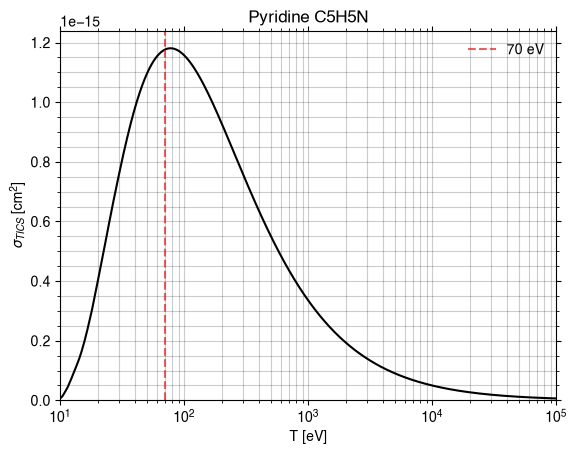

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(9260)
Recherche : 'Pyrimidine' -> CID 9260, formule C4H4N2


Loading output/xyz/Pyrimidine_C4H4N2.xyzBuilt graph: 10 atoms, 10 bondsLoading output/xyz/Pyrimidine_C4H4N2.xyzBuilt graph: 10 atoms, 10 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Pyrimidine_C4H4N2.gifGIF written to output/gif/Pyrimidine_C4H4N2.gif

strucutre 3D
Réussite. Nom: Pyrimidine, formule: C4H4N2, M: 80.09, nom_marche: Pyrimidine
PYSCF CONVERGENCE
converged SCF energy = -262.786225189379
**** MO energy ****
MO #1   energy= -15.5783156612447  occ= 2
MO #2   energy= -15.5782886730057  occ= 2
MO #3   energy= -11.3179663761826  occ= 2
MO #4   energy= -11.3009383769222  occ= 2
MO #5   energy= -11.300912772152   occ= 2
MO #6   energy= -11.2495222622764  occ= 2
MO #7   energy= -1.30726037299483  occ= 2
MO #8   energy= -1.19029999599548  occ= 2
MO #9   energy= -1.08015491359936  occ= 2
MO #10  energy= -0.896015466095766 occ= 2
MO #11  energy= -0.890049571210168 occ= 2
MO #12  energy= -0.739119294600691 occ= 2
MO #13  energy= -0.700468113659241 occ= 2
MO #14  energy= -0.656887570027493 occ= 2
MO #15  energy= -0.591856515956281 occ= 2
MO #16  energy= -0.584680581640338 occ= 2
MO #17  energy= -0.574936444879393 occ= 2
MO #18  energy= -0.479281813759556 occ= 2
MO #19  energy= -0.420159678248474 occ= 2
MO #20  energy= -0.41918866544257

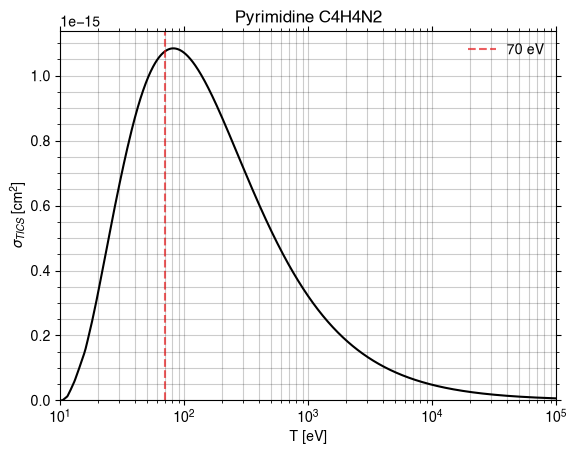

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(795)
Recherche : 'Imidazole' -> CID 795, formule C3H4N2


Loading output/xyz/Imidazole_C3H4N2.xyzBuilt graph: 9 atoms, 9 bondsLoading output/xyz/Imidazole_C3H4N2.xyzBuilt graph: 9 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Imidazole_C3H4N2.gifGIF written to output/gif/Imidazole_C3H4N2.gif

strucutre 3D
Réussite. Nom: Imidazole, formule: C3H4N2, M: 68.08, nom_marche: Imidazole
PYSCF CONVERGENCE
converged SCF energy = -224.902776751765
**** MO energy ****
MO #1   energy= -15.623265135459   occ= 2
MO #2   energy= -15.5462429198986  occ= 2
MO #3   energy= -11.2961225204346  occ= 2
MO #4   energy= -11.2607979714222  occ= 2
MO #5   energy= -11.2423406998518  occ= 2
MO #6   energy= -1.34246061306686  occ= 2
MO #7   energy= -1.16898961796623  occ= 2
MO #8   energy= -1.00561869847593  occ= 2
MO #9   energy= -0.828690124019546 occ= 2
MO #10  energy= -0.800179726393808 occ= 2
MO #11  energy= -0.758054746024882 occ= 2
MO #12  energy= -0.609833139141114 occ= 2
MO #13  energy= -0.602319944241983 occ= 2
MO #14  energy= -0.600212856698461 occ= 2
MO #15  energy= -0.56854797100395  occ= 2
MO #16  energy= -0.43979180925546  occ= 2
MO #17  energy= -0.402911112309859 occ= 2
MO #18  energy= -0.319651758689652 occ= 2
MO #19  energy= 0.0623533686380258 occ= 0
MO #20  energy= 0.0887598923652008 

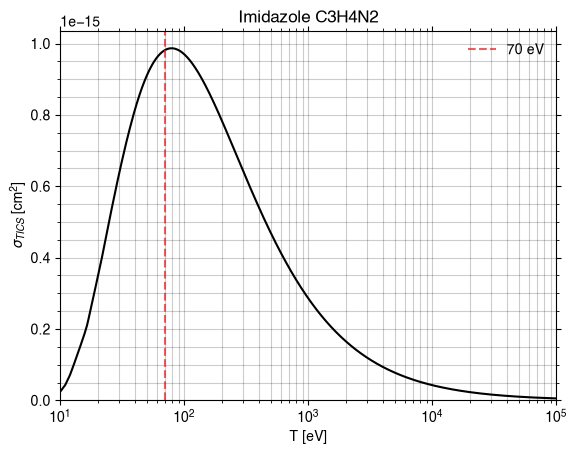

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(1048)
Recherche : 'Pyrazole' -> CID 1048, formule C3H4N2


Loading output/xyz/Pyrazole_C3H4N2.xyzBuilt graph: 9 atoms, 9 bondsLoading output/xyz/Pyrazole_C3H4N2.xyzBuilt graph: 9 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Pyrazole_C3H4N2.gifGIF written to output/gif/Pyrazole_C3H4N2.gif

strucutre 3D
Réussite. Nom: Pyrazole, formule: C3H4N2, M: 68.08, nom_marche: Pyrazole
PYSCF CONVERGENCE
converged SCF energy = -224.880605440703
**** MO energy ****
MO #1   energy= -15.6395109823205  occ= 2
MO #2   energy= -15.5885487060683  occ= 2
MO #3   energy= -11.2790063184322  occ= 2
MO #4   energy= -11.2520135266646  occ= 2
MO #5   energy= -11.2225313687068  occ= 2
MO #6   energy= -1.37397557134191  occ= 2
MO #7   energy= -1.09261399705395  occ= 2
MO #8   energy= -1.05495055540021  occ= 2
MO #9   energy= -0.82312287449635  occ= 2
MO #10  energy= -0.799694464657547 occ= 2
MO #11  energy= -0.743538325562078 occ= 2
MO #12  energy= -0.608033603568972 occ= 2
MO #13  energy= -0.607238148119566 occ= 2
MO #14  energy= -0.592503125871819 occ= 2
MO #15  energy= -0.563505685509638 occ= 2
MO #16  energy= -0.463770741821548 occ= 2
MO #17  energy= -0.364215616791489 occ= 2
MO #18  energy= -0.349180689006603 occ= 2
MO #19  energy= 0.0679439692067351 occ= 0
MO #20  energy= 0.0872802695852981 oc

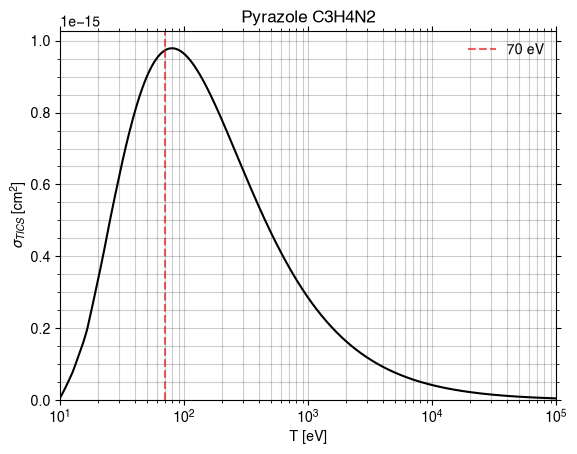

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(9255)
Recherche : 'Oxazole' -> CID 9255, formule C3H3NO


Loading output/xyz/Oxazole_C3H3NO.xyzBuilt graph: 8 atoms, 8 bondsLoading output/xyz/Oxazole_C3H3NO.xyzBuilt graph: 8 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Oxazole_C3H3NO.gifGIF written to output/gif/Oxazole_C3H3NO.gif

strucutre 3D
Réussite. Nom: Oxazole, formule: C3H3NO, M: 69.06, nom_marche: Oxazole
PYSCF CONVERGENCE
converged SCF energy = -244.72481277929
**** MO energy ****
MO #1   energy= -20.6499413403749  occ= 2
MO #2   energy= -15.5760028408077  occ= 2
MO #3   energy= -11.3427459035377  occ= 2
MO #4   energy= -11.2997131794448  occ= 2
MO #5   energy= -11.2673784668175  occ= 2
MO #6   energy= -1.49245948082336  occ= 2
MO #7   energy= -1.24017387141048  occ= 2
MO #8   energy= -1.03092120202593  occ= 2
MO #9   energy= -0.843765118820485 occ= 2
MO #10  energy= -0.826492118523499 occ= 2
MO #11  energy= -0.755776799993761 occ= 2
MO #12  energy= -0.663375387011797 occ= 2
MO #13  energy= -0.630926548940657 occ= 2
MO #14  energy= -0.596428197327626 occ= 2
MO #15  energy= -0.583096164337019 occ= 2
MO #16  energy= -0.472213510487249 occ= 2
MO #17  energy= -0.461543808170378 occ= 2
MO #18  energy= -0.342258482477675 occ= 2
MO #19  energy= 0.0657775310422224 occ= 0
MO #20  energy= 0.0874689572067526 occ= 

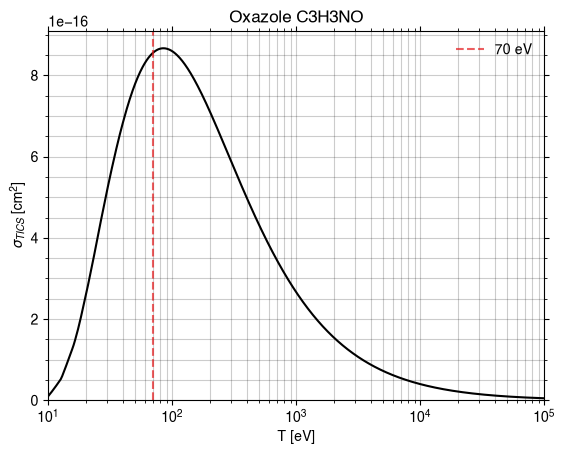

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(9254)
Recherche : 'Isoxazole' -> CID 9254, formule C3H3NO


Loading output/xyz/Isoxazole_C3H3NO.xyzBuilt graph: 8 atoms, 8 bondsLoading output/xyz/Isoxazole_C3H3NO.xyzBuilt graph: 8 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Isoxazole_C3H3NO.gifGIF written to output/gif/Isoxazole_C3H3NO.gif

strucutre 3D
Réussite. Nom: Isoxazole, formule: C3H3NO, M: 69.06, nom_marche: Isoxazole
PYSCF CONVERGENCE
converged SCF energy = -244.678769030788
**** MO energy ****
MO #1   energy= -20.6522236402856  occ= 2
MO #2   energy= -15.6298363333623  occ= 2
MO #3   energy= -11.3247128608933  occ= 2
MO #4   energy= -11.286430719884   occ= 2
MO #5   energy= -11.2481720249666  occ= 2
MO #6   energy= -1.49296657030864  occ= 2
MO #7   energy= -1.15792759311249  occ= 2
MO #8   energy= -1.07633541317213  occ= 2
MO #9   energy= -0.834371509738935 occ= 2
MO #10  energy= -0.823663260581872 occ= 2
MO #11  energy= -0.744771577879444 occ= 2
MO #12  energy= -0.655890473911036 occ= 2
MO #13  energy= -0.623769414770088 occ= 2
MO #14  energy= -0.592766339154387 occ= 2
MO #15  energy= -0.569789521037137 occ= 2
MO #16  energy= -0.485149165475377 occ= 2
MO #17  energy= -0.428423414131785 occ= 2
MO #18  energy= -0.369607098899724 occ= 2
MO #19  energy= 0.0649368013525209 occ= 0
MO #20  energy= 0.0814922376429638 

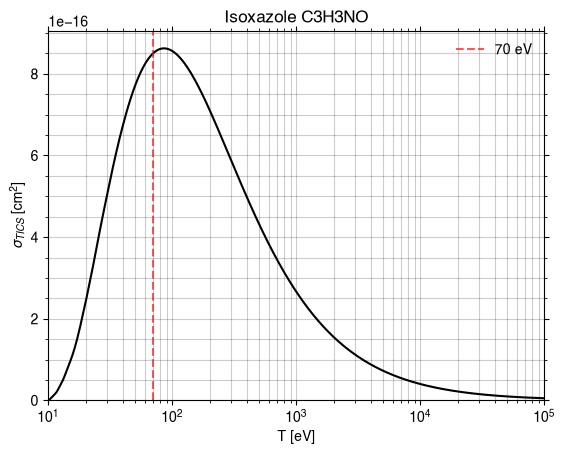

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(9256)
Recherche : 'Thiazole' -> CID 9256, formule C3H3NS


Loading output/xyz/Thiazole_C3H3NS.xyzBuilt graph: 8 atoms, 8 bondsLoading output/xyz/Thiazole_C3H3NS.xyzBuilt graph: 8 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Thiazole_C3H3NS.gifGIF written to output/gif/Thiazole_C3H3NS.gif

strucutre 3D
Réussite. Nom: Thiazole, formule: C3H3NS, M: 85.13, nom_marche: Thiazole
PYSCF CONVERGENCE
converged SCF energy = -179.804942154162
**** MO energy ****
MO #1   energy= -15.5777180938484  occ= 2
MO #2   energy= -11.310837038008   occ= 2
MO #3   energy= -11.2750601447689  occ= 2
MO #4   energy= -11.2702042234776  occ= 2
MO #5   energy= -1.2796526388448   occ= 2
MO #6   energy= -1.07389908190505  occ= 2
MO #7   energy= -1.0034794055986   occ= 2
MO #8   energy= -0.804395160357586 occ= 2
MO #9   energy= -0.77718641605841  occ= 2
MO #10  energy= -0.697809251860555 occ= 2
MO #11  energy= -0.592974626173325 occ= 2
MO #12  energy= -0.571480684873939 occ= 2
MO #13  energy= -0.562104051892584 occ= 2
MO #14  energy= -0.51046852456242  occ= 2
MO #15  energy= -0.439899655717539 occ= 2
MO #16  energy= -0.393325306342398 occ= 2
MO #17  energy= -0.343376149472491 occ= 2
MO #18  energy= 0.0658593450054577 occ= 0
MO #19  energy= 0.0745386785341368 occ= 0
MO #20  energy= 0.0859732615057838 oc

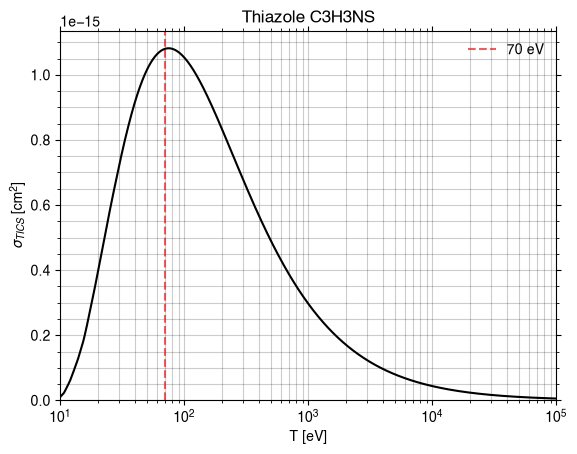

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(7865)
Recherche : 'Methyl formate' -> CID 7865, formule C2H4O2


Loading output/xyz/Methyl_formate_C2H4O2.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Methyl_formate_C2H4O2.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methyl_formate_C2H4O2.gifGIF written to output/gif/Methyl_formate_C2H4O2.gif

strucutre 3D
Réussite. Nom: Methyl formate, formule: C2H4O2, M: 60.05, nom_marche: Methyl_formate
PYSCF CONVERGENCE
converged SCF energy = -227.882503292475
**** MO energy ****
MO #1   energy= -20.6190637063084  occ= 2
MO #2   energy= -20.5619610723803  occ= 2
MO #3   energy= -11.3928375216487  occ= 2
MO #4   energy= -11.2938707611642  occ= 2
MO #5   energy= -1.46038335947362  occ= 2
MO #6   energy= -1.36663799877442  occ= 2
MO #7   energy= -0.988648100379315 occ= 2
MO #8   energy= -0.823878165140673 occ= 2
MO #9   energy= -0.733837811072714 occ= 2
MO #10  energy= -0.681037609449919 occ= 2
MO #11  energy= -0.676358602868244 occ= 2
MO #12  energy= -0.598944962546113 occ= 2
MO #13  energy= -0.553392438892829 occ= 2
MO #14  energy= -0.534778211459948 occ= 2
MO #15  energy= -0.471685396484121 occ= 2
MO #16  energy= -0.46734626282526  occ= 2
MO #17  energy= 0.0610829597288074 occ= 0
MO #18  energy= 0.0847979124553936 occ= 0
MO #19  energy= 0.0958229693075185 occ= 0
MO #20  energy= 0.1027969

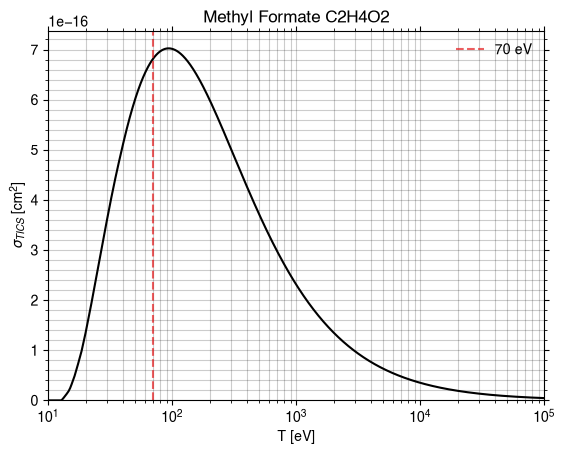

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(8008)
Recherche : 'Butyronitrile' -> CID 8008, formule C4H7N


Loading output/xyz/Butyronitrile_C4H7N.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/Butyronitrile_C4H7N.xyzBuilt graph: 12 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Butyronitrile_C4H7N.gifGIF written to output/gif/Butyronitrile_C4H7N.gif

strucutre 3D
Réussite. Nom: Butyronitrile, formule: C4H7N, M: 69.11, nom_marche: Butyronitrile
PYSCF CONVERGENCE
converged SCF energy = -210.075098038816
**** MO energy ****
MO #1   energy= -15.5681390744893  occ= 2
MO #2   energy= -11.2831728674615  occ= 2
MO #3   energy= -11.27315029286    occ= 2
MO #4   energy= -11.2509573294416  occ= 2
MO #5   energy= -11.2344275510447  occ= 2
MO #6   energy= -1.21439092766429  occ= 2
MO #7   energy= -1.10331324609108  occ= 2
MO #8   energy= -0.986260556223975 occ= 2
MO #9   energy= -0.843077547453596 occ= 2
MO #10  energy= -0.706123579351952 occ= 2
MO #11  energy= -0.672847138075636 occ= 2
MO #12  energy= -0.606252692292344 occ= 2
MO #13  energy= -0.584151183465028 occ= 2
MO #14  energy= -0.56291923981443  occ= 2
MO #15  energy= -0.530052775404467 occ= 2
MO #16  energy= -0.517486776673663 occ= 2
MO #17  energy= -0.504870052286891 occ= 2
MO #18  energy= -0.455341534933779 occ= 2
MO #19  energy= -0.452139324431291 occ= 2
MO #20  energy= 0.0619514362

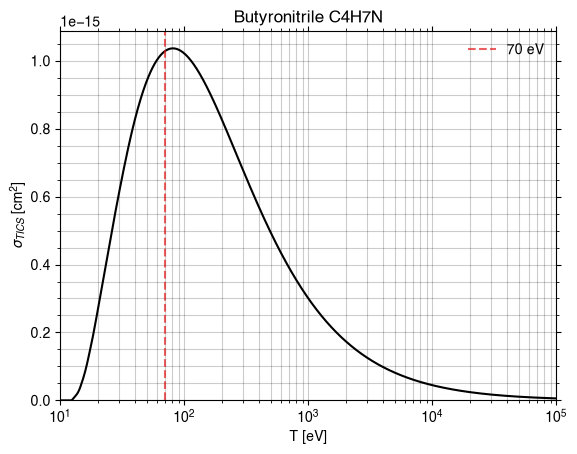

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6559)
Recherche : 'Isobutyronitrile' -> CID 6559, formule C4H7N


Loading output/xyz/Isobutyronitrile_C4H7N.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/Isobutyronitrile_C4H7N.xyzBuilt graph: 12 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Isobutyronitrile_C4H7N.gifGIF written to output/gif/Isobutyronitrile_C4H7N.gif

strucutre 3D
Réussite. Nom: Isobutyronitrile, formule: C4H7N, M: 69.11, nom_marche: Isobutyronitrile
PYSCF CONVERGENCE
converged SCF energy = -210.074912598956
**** MO energy ****
MO #1   energy= -15.5681972471715  occ= 2
MO #2   energy= -11.2885579834551  occ= 2
MO #3   energy= -11.2709807054569  occ= 2
MO #4   energy= -11.2437870140034  occ= 2
MO #5   energy= -11.2437709851444  occ= 2
MO #6   energy= -1.21527143078902  occ= 2
MO #7   energy= -1.11063568184141  occ= 2
MO #8   energy= -0.959724945931036 occ= 2
MO #9   energy= -0.876422987797305 occ= 2
MO #10  energy= -0.709763126844628 occ= 2
MO #11  energy= -0.644046828784745 occ= 2
MO #12  energy= -0.601150546801097 occ= 2
MO #13  energy= -0.575243431630541 occ= 2
MO #14  energy= -0.563573640429122 occ= 2
MO #15  energy= -0.535272362644094 occ= 2
MO #16  energy= -0.525781446303894 occ= 2
MO #17  energy= -0.518370469396601 occ= 2
MO #18  energy= -0.453506191808036 occ= 2
MO #19  energy= -0.453334889214406 occ= 2
MO #20  energy= 0.0635

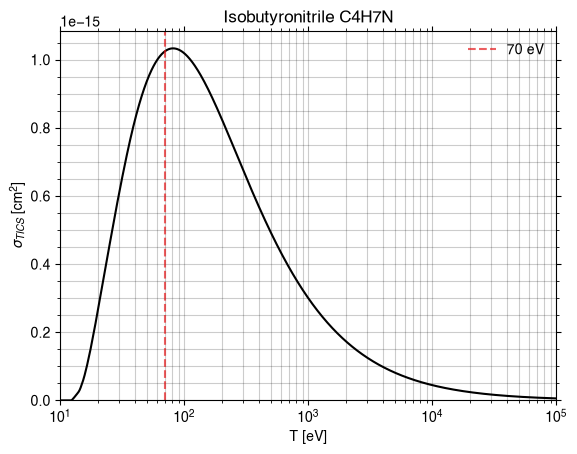

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(8062)
Recherche : 'Succinonitrile' -> CID 8062, formule C4H4N2


Loading output/xyz/Succinonitrile_C4H4N2.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Succinonitrile_C4H4N2.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Succinonitrile_C4H4N2.gifGIF written to output/gif/Succinonitrile_C4H4N2.gif

strucutre 3D
Réussite. Nom: Succinonitrile, formule: C4H4N2, M: 80.09, nom_marche: Succinonitrile
PYSCF CONVERGENCE
converged SCF energy = -262.780867435971
**** MO energy ****
MO #1   energy= -15.5901488282089  occ= 2
MO #2   energy= -15.5901465813946  occ= 2
MO #3   energy= -11.3212520059252  occ= 2
MO #4   energy= -11.3206453333958  occ= 2
MO #5   energy= -11.2926164112978  occ= 2
MO #6   energy= -11.2926130336782  occ= 2
MO #7   energy= -1.23901549272034  occ= 2
MO #8   energy= -1.22997949598193  occ= 2
MO #9   energy= -1.13275823081034  occ= 2
MO #10  energy= -0.977256010923924 occ= 2
MO #11  energy= -0.758607058647812 occ= 2
MO #12  energy= -0.727284057071577 occ= 2
MO #13  energy= -0.650460150132147 occ= 2
MO #14  energy= -0.6408649821916   occ= 2
MO #15  energy= -0.606475619494412 occ= 2
MO #16  energy= -0.569883021468843 occ= 2
MO #17  energy= -0.566833823672432 occ= 2
MO #18  energy= -0.487185990559662 occ= 2
MO #19  energy= -0.47808518568671  occ= 2
MO #20  energy= -0.473843

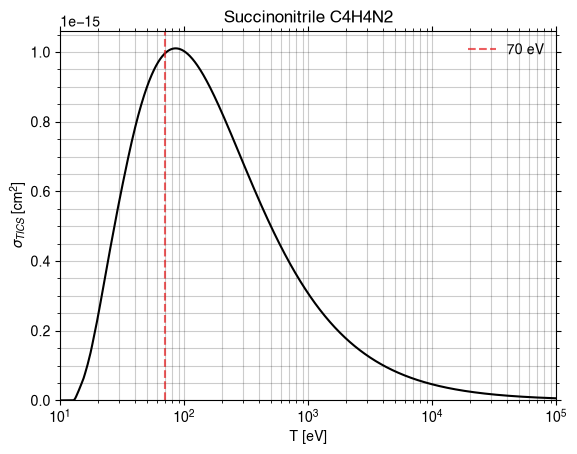

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6579)
Recherche : 'Acrylamide' -> CID 6579, formule C3H5NO


Loading output/xyz/Acrylamide_C3H5NO.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Acrylamide_C3H5NO.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Acrylamide_C3H5NO.gifGIF written to output/gif/Acrylamide_C3H5NO.gif

strucutre 3D
Réussite. Nom: Acrylamide, formule: C3H5NO, M: 71.08, nom_marche: Acrylamide
PYSCF CONVERGENCE
converged SCF energy = -245.923327533912
**** MO energy ****
MO #1   energy= -20.5167069129629  occ= 2
MO #2   energy= -15.5897987894907  occ= 2
MO #3   energy= -11.3575686735599  occ= 2
MO #4   energy= -11.2543515128356  occ= 2
MO #5   energy= -11.2462864118338  occ= 2
MO #6   energy= -1.37352813135595  occ= 2
MO #7   energy= -1.20990296155448  occ= 2
MO #8   energy= -1.06589234791731  occ= 2
MO #9   energy= -0.879444528389904 occ= 2
MO #10  energy= -0.769985567326682 occ= 2
MO #11  energy= -0.713144911816883 occ= 2
MO #12  energy= -0.693376719755966 occ= 2
MO #13  energy= -0.614590296404577 occ= 2
MO #14  energy= -0.595620950316206 occ= 2
MO #15  energy= -0.574734785365635 occ= 2
MO #16  energy= -0.542275670587518 occ= 2
MO #17  energy= -0.430528781748157 occ= 2
MO #18  energy= -0.417450951091281 occ= 2
MO #19  energy= -0.388895095621997 occ= 2
MO #20  energy= 0.064031412182660

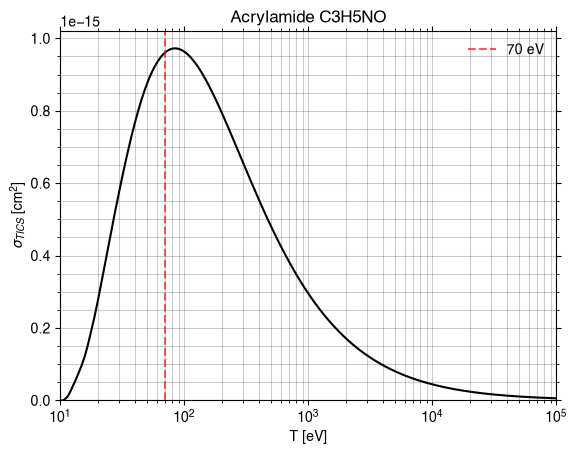

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6228)
Recherche : 'Dimethylformamide' -> CID 6228, formule C3H7NO


Loading output/xyz/Dimethylformamide_C3H7NO.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/Dimethylformamide_C3H7NO.xyzBuilt graph: 12 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Dimethylformamide_C3H7NO.gifGIF written to output/gif/Dimethylformamide_C3H7NO.gif

strucutre 3D
Réussite. Nom: Dimethylformamide, formule: C3H7NO, M: 73.09, nom_marche: Dimethylformamide
PYSCF CONVERGENCE
converged SCF energy = -247.088552648283
**** MO energy ****
MO #1   energy= -20.5216050765711  occ= 2
MO #2   energy= -15.5945456301824  occ= 2
MO #3   energy= -11.3491862004937  occ= 2
MO #4   energy= -11.2772233930304  occ= 2
MO #5   energy= -11.2626785055081  occ= 2
MO #6   energy= -1.37039347004855  occ= 2
MO #7   energy= -1.24926503692102  occ= 2
MO #8   energy= -0.984551557078934 occ= 2
MO #9   energy= -0.945785281347572 occ= 2
MO #10  energy= -0.782150275882866 occ= 2
MO #11  energy= -0.697911523607509 occ= 2
MO #12  energy= -0.66064892714154  occ= 2
MO #13  energy= -0.65181011964693  occ= 2
MO #14  energy= -0.581688525034708 occ= 2
MO #15  energy= -0.571011239846843 occ= 2
MO #16  energy= -0.567793558334347 occ= 2
MO #17  energy= -0.544675332117706 occ= 2
MO #18  energy= -0.528651938637836 occ= 2
MO #19  energy= -0.428006690834753 occ= 2
MO #20  energy= -0.

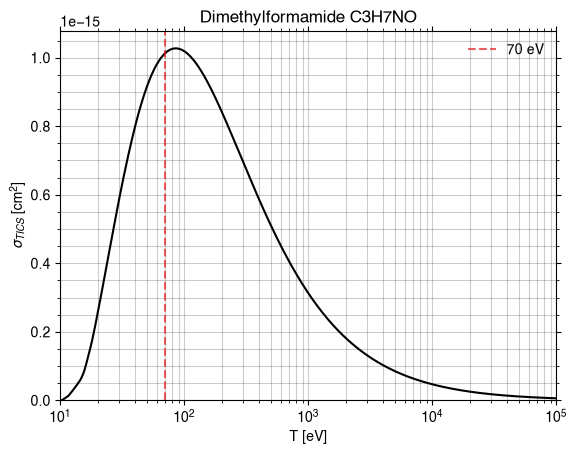

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6348)
Recherche : 'Carbon disulfide' -> CID 6348, formule CS2


Loading output/xyz/Carbon_disulfide_CS2.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Carbon_disulfide_CS2.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Carbon_disulfide_CS2.gifGIF written to output/gif/Carbon_disulfide_CS2.gif

strucutre 3D
Réussite. Nom: Carbon disulfide, formule: CS2, M: 76.15, nom_marche: Carbon_disulfide
PYSCF CONVERGENCE
converged SCF energy = -57.7994281745006
**** MO energy ****
MO #1   energy= -11.4145308531983  occ= 2
MO #2   energy= -1.13388437314654  occ= 2
MO #3   energy= -1.01690727739892  occ= 2
MO #4   energy= -0.685854457395767 occ= 2
MO #5   energy= -0.580909862726877 occ= 2
MO #6   energy= -0.516739131937183 occ= 2
MO #7   energy= -0.516739125350748 occ= 2
MO #8   energy= -0.37361665431578  occ= 2
MO #9   energy= -0.37361663174277  occ= 2
MO #10  energy= 0.0376959532368665 occ= 0
MO #11  energy= 0.037696129706949  occ= 0
MO #12  energy= 0.0617873864437268 occ= 0
MO #13  energy= 0.0738391062396661 occ= 0
MO #14  energy= 0.0935818967024644 occ= 0
MO #15  energy= 0.106085815208137  occ= 0
MO #16  energy= 0.106085832507636  occ= 0
MO #17  energy= 0.114043988903939  occ= 0
MO #18  energy= 0.114044000532575  occ= 0
MO #19  energy= 0.209933192937119  occ= 0
MO #20  energy= 0.219195

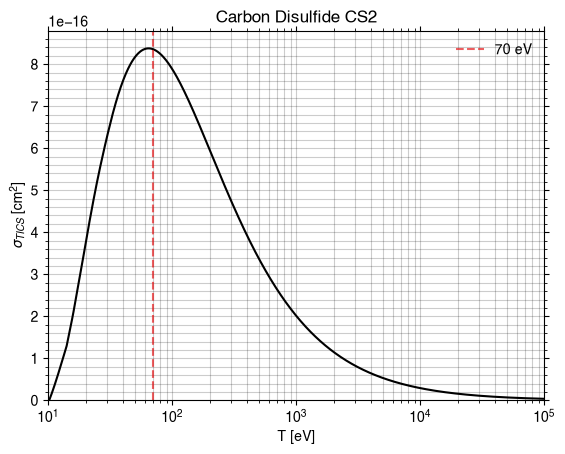

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(31297)
Recherche : 'Methanesulfonyl chloride' -> CID 31297, formule CH3ClO2S


Loading output/xyz/Methanesulfonyl_chloride_CH3ClO2S.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Methanesulfonyl_chloride_CH3ClO2S.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methanesulfonyl_chloride_CH3ClO2S.gifGIF written to output/gif/Methanesulfonyl_chloride_CH3ClO2S.gif

strucutre 3D
Réussite. Nom: Methanesulfonyl chloride, formule: CH3ClO2S, M: 114.55, nom_marche: Methanesulfonyl_chloride
PYSCF CONVERGENCE
converged SCF energy = -214.069478841384
**** MO energy ****
MO #1   energy= -20.5786935710385  occ= 2
MO #2   energy= -20.5786678886981  occ= 2
MO #3   energy= -11.3092291940784  occ= 2
MO #4   energy= -1.48298137356081  occ= 2
MO #5   energy= -1.36797039275432  occ= 2
MO #6   energy= -1.16011783770695  occ= 2
MO #7   energy= -1.0720224060816   occ= 2
MO #8   energy= -0.851827124292171 occ= 2
MO #9   energy= -0.716540401608927 occ= 2
MO #10  energy= -0.698212727702699 occ= 2
MO #11  energy= -0.685669712410354 occ= 2
MO #12  energy= -0.628761405107583 occ= 2
MO #13  energy= -0.627776341285814 occ= 2
MO #14  energy= -0.549022177944201 occ= 2
MO #15  energy= -0.530761610345171 occ= 2
MO #16  energy= -0.508439776586587 occ= 2
MO #17  energy= -0.502860625113084 occ= 2
MO #18  energy= -0.482100031621106 occ= 2
MO #19  energy= -0.4736925555997   occ= 2
MO

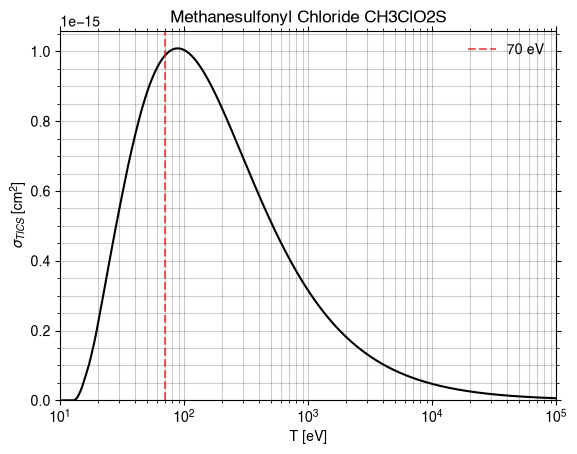

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(679)
Recherche : 'Dimethyl sulfoxide' -> CID 679, formule C2H6OS


Loading output/xyz/Dimethyl_sulfoxide_C2H6OS.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Dimethyl_sulfoxide_C2H6OS.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Dimethyl_sulfoxide_C2H6OS.gifGIF written to output/gif/Dimethyl_sulfoxide_C2H6OS.gif

strucutre 3D
Réussite. Nom: Dimethyl sulfoxide, formule: C2H6OS, M: 78.14, nom_marche: Dimethyl_sulfoxide
PYSCF CONVERGENCE
converged SCF energy = -164.077247681531
**** MO energy ****
MO #1   energy= -20.5033974158389  occ= 2
MO #2   energy= -11.263702244286   occ= 2
MO #3   energy= -11.2636861950702  occ= 2
MO #4   energy= -1.33416230087091  occ= 2
MO #5   energy= -1.06556370140579  occ= 2
MO #6   energy= -0.97495407943488  occ= 2
MO #7   energy= -0.820157458787801 occ= 2
MO #8   energy= -0.640544605384778 occ= 2
MO #9   energy= -0.6280329511183   occ= 2
MO #10  energy= -0.620849566600473 occ= 2
MO #11  energy= -0.584797193104517 occ= 2
MO #12  energy= -0.563787793666921 occ= 2
MO #13  energy= -0.546856347881964 occ= 2
MO #14  energy= -0.513989790225896 occ= 2
MO #15  energy= -0.42054306466877  occ= 2
MO #16  energy= -0.368127137212593 occ= 2
MO #17  energy= 0.0647035745449035 occ= 0
MO #18  energy= 0.0807793498243135 occ= 0
MO #19  energy= 0.0871241893454491 occ= 0
MO #20  energy= 0

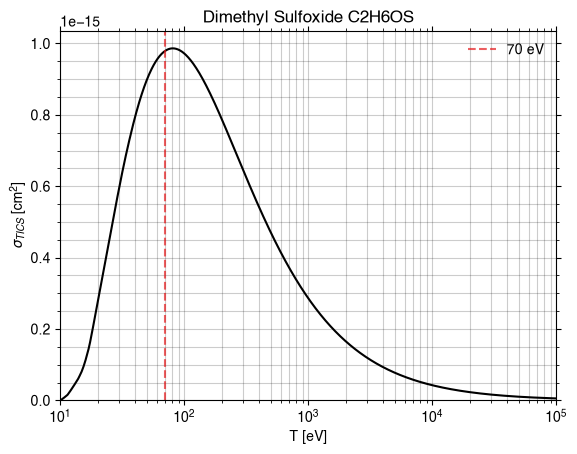

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(9609)
Recherche : 'Diethyl sulfide' -> CID 9609, formule C4H10S


Loading output/xyz/Diethyl_sulfide_C4H10S.xyzBuilt graph: 15 atoms, 14 bondsLoading output/xyz/Diethyl_sulfide_C4H10S.xyzBuilt graph: 15 atoms, 14 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Diethyl_sulfide_C4H10S.gifGIF written to output/gif/Diethyl_sulfide_C4H10S.gif

strucutre 3D
Réussite. Nom: Diethyl sulfide, formule: C4H10S, M: 90.19, nom_marche: Diethyl_sulfide
PYSCF CONVERGENCE
converged SCF energy = -167.31989296982
**** MO energy ****
MO #1   energy= -11.2518993409509  occ= 2
MO #2   energy= -11.2513964522427  occ= 2
MO #3   energy= -11.2210115142546  occ= 2
MO #4   energy= -11.2209440474521  occ= 2
MO #5   energy= -1.08851722738879  occ= 2
MO #6   energy= -1.0330272559932   occ= 2
MO #7   energy= -0.930148675740309 occ= 2
MO #8   energy= -0.833100275779788 occ= 2
MO #9   energy= -0.784116229807999 occ= 2
MO #10  energy= -0.636757061983491 occ= 2
MO #11  energy= -0.613494505643309 occ= 2
MO #12  energy= -0.610444348186113 occ= 2
MO #13  energy= -0.563211747001904 occ= 2
MO #14  energy= -0.543485880635054 occ= 2
MO #15  energy= -0.515245320051725 occ= 2
MO #16  energy= -0.513492711002318 occ= 2
MO #17  energy= -0.495684522678236 occ= 2
MO #18  energy= -0.45627426028787  occ= 2
MO #19  energy= -0.425285854244663 occ= 2
MO #20  energy= -0.33113

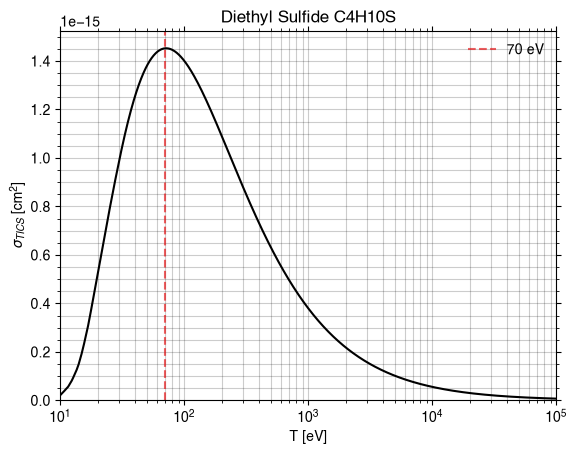

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Thiacyclopropane_C2H4S.xyzBuilt graph: 7 atoms, 7 bondsLoading output/xyz/Thiacyclopropane_C2H4S.xyzBuilt graph: 7 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

Compound(9865)
Recherche : 'Thiacyclopropane' -> CID 9865, formule C2H4S
3D


  frame 120/120
Wrote output/gif/Thiacyclopropane_C2H4S.gifGIF written to output/gif/Thiacyclopropane_C2H4S.gif

strucutre 3D
Réussite. Nom: Thiacyclopropane, formule: C2H4S, M: 60.12, nom_marche: Thiacyclopropane
PYSCF CONVERGENCE
converged SCF energy = -88.0259644711064
**** MO energy ****
MO #1   energy= -11.2658539044586  occ= 2
MO #2   energy= -11.2651316518877  occ= 2
MO #3   energy= -1.17189898972917  occ= 2
MO #4   energy= -0.850488318681841 occ= 2
MO #5   energy= -0.827144177171217 occ= 2
MO #6   energy= -0.674288244078003 occ= 2
MO #7   energy= -0.613711924722619 occ= 2
MO #8   energy= -0.542929250409212 occ= 2
MO #9   energy= -0.453083719828189 occ= 2
MO #10  energy= -0.436619964593796 occ= 2
MO #11  energy= -0.342799136689532 occ= 2
MO #12  energy= 0.0779414207196204 occ= 0
MO #13  energy= 0.0797046551628618 occ= 0
MO #14  energy= 0.08991073023483   occ= 0
MO #15  energy= 0.0958944434229426 occ= 0
MO #16  energy= 0.119059198402239  occ= 0
MO #17  energy= 0.163723067893979  occ= 0
MO #18  energy= 0.165679057300538  occ= 0
MO #19  energy= 0.176745402396823  occ= 0
MO #20  energy= 0.1780

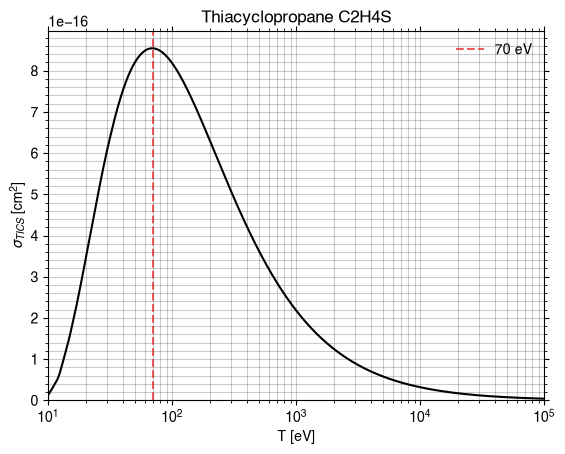

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(8030)
Recherche : 'Thiophene' -> CID 8030, formule C4H4S


Loading output/xyz/Thiophene_C4H4S.xyzBuilt graph: 9 atoms, 9 bondsLoading output/xyz/Thiophene_C4H4S.xyzBuilt graph: 9 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Thiophene_C4H4S.gifGIF written to output/gif/Thiophene_C4H4S.gif

strucutre 3D
Réussite. Nom: Thiophene, formule: C4H4S, M: 84.14, nom_marche: Thiophene
PYSCF CONVERGENCE
converged SCF energy = -163.801458596484
**** MO energy ****
MO #1   energy= -11.2615313075253  occ= 2
MO #2   energy= -11.2614837365994  occ= 2
MO #3   energy= -11.239850308407   occ= 2
MO #4   energy= -11.2388265337085  occ= 2
MO #5   energy= -1.17151335338945  occ= 2
MO #6   energy= -0.988659329272875 occ= 2
MO #7   energy= -0.980248721657939 occ= 2
MO #8   energy= -0.765993207186358 occ= 2
MO #9   energy= -0.751292586051225 occ= 2
MO #10  energy= -0.696556308627414 occ= 2
MO #11  energy= -0.572968045627982 occ= 2
MO #12  energy= -0.549972425618145 occ= 2
MO #13  energy= -0.530337495772726 occ= 2
MO #14  energy= -0.522878024025343 occ= 2
MO #15  energy= -0.477380255030095 occ= 2
MO #16  energy= -0.346138484946154 occ= 2
MO #17  energy= -0.325613228369752 occ= 2
MO #18  energy= 0.0703972238363942 occ= 0
MO #19  energy= 0.079214399117338  occ= 0
MO #20  energy= 0.0851564564883939 o

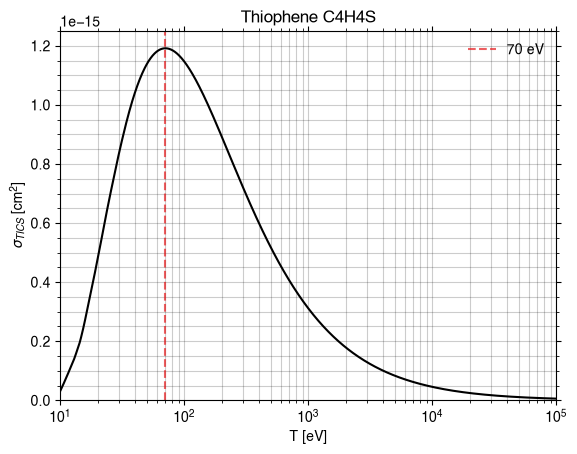

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(1127)
Recherche : 'Tetrahydrothiophene' -> CID 1127, formule C4H8S


Loading output/xyz/Tetrahydrothiophene_C4H8S.xyzBuilt graph: 13 atoms, 13 bondsLoading output/xyz/Tetrahydrothiophene_C4H8S.xyzBuilt graph: 13 atoms, 13 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Tetrahydrothiophene_C4H8S.gifGIF written to output/gif/Tetrahydrothiophene_C4H8S.gif

strucutre 3D
Réussite. Nom: Tetrahydrothiophene, formule: C4H8S, M: 88.17, nom_marche: Tetrahydrothiophene
PYSCF CONVERGENCE
converged SCF energy = -166.153387900442
**** MO energy ****
MO #1   energy= -11.250223074602   occ= 2
MO #2   energy= -11.2502067886283  occ= 2
MO #3   energy= -11.2309436181999  occ= 2
MO #4   energy= -11.2303059805738  occ= 2
MO #5   energy= -1.13273065453478  occ= 2
MO #6   energy= -0.986643743704675 occ= 2
MO #7   energy= -0.96842983871248  occ= 2
MO #8   energy= -0.792401522047297 occ= 2
MO #9   energy= -0.78076946387585  occ= 2
MO #10  energy= -0.656073189541519 occ= 2
MO #11  energy= -0.63993571577193  occ= 2
MO #12  energy= -0.59839549392597  occ= 2
MO #13  energy= -0.54756301460576  occ= 2
MO #14  energy= -0.508532032409648 occ= 2
MO #15  energy= -0.489942490795317 occ= 2
MO #16  energy= -0.481120785969659 occ= 2
MO #17  energy= -0.47989514344602  occ= 2
MO #18  energy= -0.417521238215166 occ= 2
MO #19  energy= -0.327545816656826 occ= 2
MO #20  energy= 

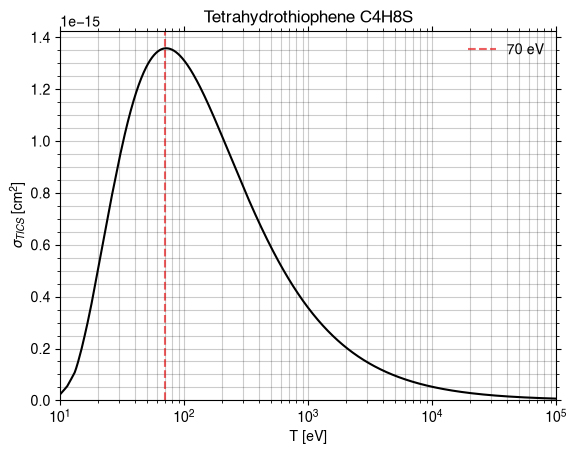

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(68983)
Recherche : 'Trimethylphosphine' -> CID 68983, formule C3H9P


Loading output/xyz/Trimethylphosphine_C3H9P.xyzBuilt graph: 13 atoms, 12 bondsLoading output/xyz/Trimethylphosphine_C3H9P.xyzBuilt graph: 13 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Trimethylphosphine_C3H9P.gifGIF written to output/gif/Trimethylphosphine_C3H9P.gif

strucutre 3D
Réussite. Nom: Trimethylphosphine, formule: C3H9P, M: 76.08, nom_marche: Trimethylphosphine
PYSCF CONVERGENCE
converged SCF energy = -125.275464747528
**** MO energy ****
MO #1   energy= -11.2172455390637  occ= 2
MO #2   energy= -11.2172439863871  occ= 2
MO #3   energy= -11.2172304209029  occ= 2
MO #4   energy= -1.02298349489005  occ= 2
MO #5   energy= -0.933835003143772 occ= 2
MO #6   energy= -0.933819404887097 occ= 2
MO #7   energy= -0.715173970160222 occ= 2
MO #8   energy= -0.596648669443602 occ= 2
MO #9   energy= -0.580852787643445 occ= 2
MO #10  energy= -0.580843426894802 occ= 2
MO #11  energy= -0.547551368194752 occ= 2
MO #12  energy= -0.547531024369082 occ= 2
MO #13  energy= -0.535056844228709 occ= 2
MO #14  energy= -0.456787253754731 occ= 2
MO #15  energy= -0.456774601427661 occ= 2
MO #16  energy= -0.323574879623617 occ= 2
MO #17  energy= 0.0687279409670613 occ= 0
MO #18  energy= 0.0694072358709171 occ= 0
MO #19  energy= 0.0694079602561782 occ= 0
MO #20  energy= 0.

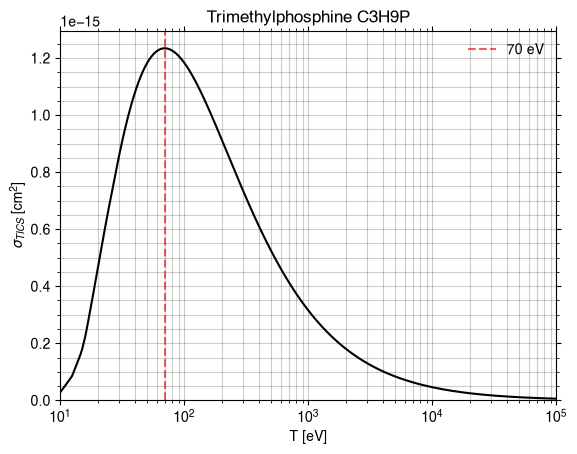

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(5359282)
Recherche : 'Aluminium monochloride' -> CID 5359282, formule AlCl


[22:43:17] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[22:43:17] UFFTYPER: Unrecognized charge state for atom: 0
geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /**********

2D
[Level 1] Processing SMILES: [Al]Cl
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
2
1
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Aluminium monochloride, formule: AlCl, M: 62.43, nom_marche: Aluminium_monochloride
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Al   1.103741   0.000000   0.000000    0.000000  0.000000  0.000000
  Cl  -1.103741   0.000000   0.000000    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -16.7245723217533
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Al     0.0120764804    -0.0000000000    -0.0000000000
1 Cl    -0.0120764804     0.0000000000     0.0000000000
-------------

Step    0 : Gradient = 1.208e-02/1.208e-02 (rms/max) Energy = -16.7245723218
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 1.86294e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Al   1.086589   0.000000   0.000000   -0.017152  0.000000  0.000000
  Cl  -1.086589  -0.000000  -0.000000    0.017152 -0.000000 -0.000000
converged SCF energy = -16.7251345626236
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Al     0.0050873149     0.0000000000    -0.0000000000
1 Cl    -0.0050873149    -0.0000000000     0.0000000000
----------------------------------------------
cycle 2: E = -16.7251345626  dE = -0.000562241  norm(grad) = 0.00719455


... (4 outputs left out)

Step    3 : Displace = 1.564e-03/1.564e-03 (rms/max) Trust = 2.000e-01 (+) Grad = 3.634e-05/3.634e-05 (rms/max) E (change) = -16.7252420008 (-2.042e-06) Quality = 0.948
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 1.29408e-01



Geometry optimization cycle 5
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Al   1.075595  -0.000000   0.000000   -0.000074  0.000000  0.000000
  Cl  -1.075595   0.000000  -0.000000    0.000074 -0.000000 -0.000000
converged SCF energy = -16.7252420058594
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Al     0.0000006427    -0.0000000000    -0.0000000000
1 Cl    -0.0000006427     0.0000000000     0.0000000000
----------------------------------------------
cycle 5: E = -16.7252420059  dE = -5.10522e-09  norm(grad) = 9.08972e-07


Step    4 : Displace = 7.430e-05/7.430e-05 (rms/max) Trust = 2.828e-01 (+) Grad = 6.427e-07/6.427e-07 (rms/max) E (change) = -16.7252420059 (-5.105e-09) Quality = 1.001
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 1.29408e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 27.990 seconds
  frame 120/120xyz/Aluminium_monochloride_AlCl.xyzAl0 reads +1 at charge=+0, not one of it

converged SCF energy = -16.7252420058639
**** MO energy ****
MO #1   energy= -1.07260425448194  occ= 2
MO #2   energy= -0.544345408060231 occ= 2
MO #3   energy= -0.458577983389196 occ= 2
MO #4   energy= -0.458577983389193 occ= 2
MO #5   energy= -0.331598994683563 occ= 2
MO #6   energy= 0.0164204118315405 occ= 0
MO #7   energy= 0.0164204118315414 occ= 0
MO #8   energy= 0.0311403922801734 occ= 0
MO #9   energy= 0.0552044376177007 occ= 0
MO #10  energy= 0.0552044376177018 occ= 0
MO #11  energy= 0.0698273442163388 occ= 0
MO #12  energy= 0.105839624565887  occ= 0
MO #13  energy= 0.105839624565889  occ= 0
MO #14  energy= 0.108453931639875  occ= 0
MO #15  energy= 0.124235059869189  occ= 0
MO #16  energy= 0.124235059869194  occ= 0
MO #17  energy= 0.135456867711069  occ= 0
MO #18  energy= 0.189290355939959  occ= 0
MO #19  energy= 0.195519968886627  occ= 0
MO #20  energy= 0.19551996888663   occ= 0
MO #21  energy= 0.252369317353373  occ= 0
MO #22  energy= 0.252369317353419  occ= 0
MO #23  energy=

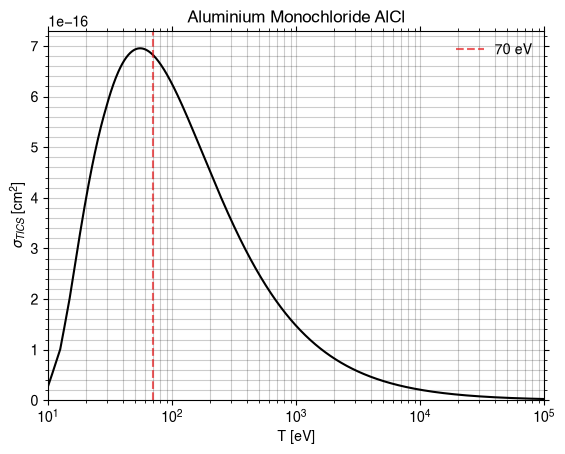

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(5464153)
Recherche : 'Aluminium monofluoride' -> CID 5464153, formule AlF
2D
[Level 1] Processing SMILES: F[Al]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
2
1
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Aluminium monofluoride, formule: AlF, M: 45.979942, nom_marche: Aluminium_monofluoride
PYSCF CONVERGENCE


[22:43:58] UFFTYPER: Warning: hybridization set to SP3 for atom 1
[22:43:58] UFFTYPER: Unrecognized charge state for atom: 1
geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /**********


Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   F   0.901039   0.000000   0.000000    0.000000  0.000000  0.000000
  Al  -0.901039   0.000000   0.000000    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -101.471539078888
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 F     0.0551007007     0.0000000000    -0.0000000000
1 Al    -0.0551007007    -0.0000000000     0.0000000000
----------------------------------------------
cycle 1: E = -101.471539079  dE = -101.472  norm(grad) = 0.0779242


Step    0 : Gradient = 5.510e-02/5.510e-02 (rms/max) Energy = -101.4715390789
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 2.59536e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   F   0.844866  -0.000000   0.000000   -0.056173 -0.000000  0.000000
  Al  -0.844866   0.000000  -0.000000    0.056173  0.000000 -0.000000
converged SCF energy = -101.480028333211
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 F     0.0208931772    -0.0000000000     0.0000000000
1 Al    -0.0208931772     0.0000000000    -0.0000000000
----------------------------------------------
cycle 2: E = -101.480028333  dE = -0.00848925  norm(grad) = 0.0295474


... (6 outputs left out)

Step    4 : Displace = 1.464e-03/1.464e-03 (rms/max) Trust = 2.000e-01 (+) Grad = 1.169e-04/1.169e-04 (rms/max) E (change) = -101.4809251652 (-5.001e-06) Quality = 1.072
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 2.83801e-01



Geometry optimization cycle 6
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   F   0.823061   0.000000  -0.000000   -0.000109  0.000000 -0.000000
  Al  -0.823061  -0.000000   0.000000    0.000109 -0.000000  0.000000
converged SCF energy = -101.48092518911
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 F    -0.0000008327    -0.0000000000     0.0000000000
1 Al     0.0000008327     0.0000000000    -0.0000000000
----------------------------------------------
cycle 6: E = -101.480925189  dE = -2.38941e-08  norm(grad) = 1.17765e-06


Step    5 : Displace = 1.090e-04/1.090e-04 (rms/max) Trust = 2.828e-01 (+) Grad = 8.327e-07/8.327e-07 (rms/max) E (change) = -101.4809251891 (-2.389e-08) Quality = 0.992
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 2.83801e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 21.593 seconds
  frame 120/120xyz/Aluminium_monofluoride_AlF.xyzAl1 reads +1 at charge=+0, not one of it

converged SCF energy = -101.480925189149
**** MO energy ****
MO #1   energy= -26.2486455549354  occ= 2
MO #2   energy= -1.53670083048147  occ= 2
MO #3   energy= -0.677671760953828 occ= 2
MO #4   energy= -0.617828781540477 occ= 2
MO #5   energy= -0.617828781540435 occ= 2
MO #6   energy= -0.336737824184901 occ= 2
MO #7   energy= 0.0184520384214621 occ= 0
MO #8   energy= 0.0184520384214888 occ= 0
MO #9   energy= 0.0312201338114782 occ= 0
MO #10  energy= 0.0643120306463872 occ= 0
MO #11  energy= 0.0643120306464906 occ= 0
MO #12  energy= 0.0731506560020581 occ= 0
MO #13  energy= 0.104864428879319  occ= 0
MO #14  energy= 0.109024958811588  occ= 0
MO #15  energy= 0.109024958811598  occ= 0
MO #16  energy= 0.112919660087304  occ= 0
MO #17  energy= 0.112919660087467  occ= 0
MO #18  energy= 0.126810432033566  occ= 0
MO #19  energy= 0.222917493196008  occ= 0
MO #20  energy= 0.245560674570204  occ= 0
MO #21  energy= 0.24556067457028   occ= 0
MO #22  energy= 0.262906935967191  occ= 0
MO #23  energy=

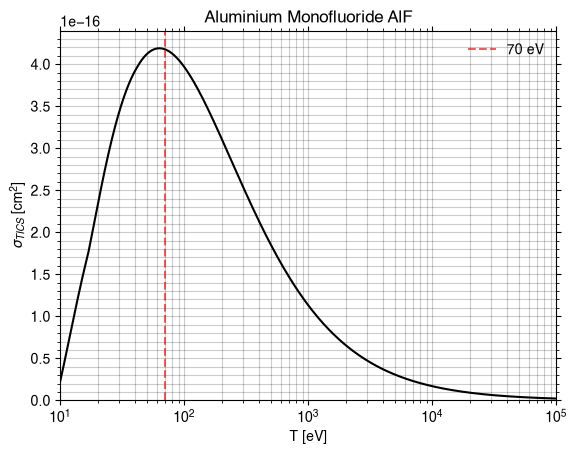

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(139247)
Recherche : 'Diatomic carbon' -> CID 139247, formule C2


Loading output/xyz/Diatomic_carbon_C2.xyzStated charge +0, but the bond orders give -2; formal charges follow the structureBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Diatomic_carbon_C2.xyzStated charge +0, but the bond orders give -2; formal charges follow the structureBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Diatomic_carbon_C2.gifGIF written to output/gif/Diatomic_carbon_C2.gif

strucutre 3D
Réussite. Nom: Diatomic carbon, formule: C2, M: 24.02, nom_marche: Diatomic_carbon
PYSCF CONVERGENCE
converged SCF energy = -75.3998927195903
**** MO energy ****
MO #1   energy= -11.3472761624346  occ= 2
MO #2   energy= -11.3440106859563  occ= 2
MO #3   energy= -1.07905294916091  occ= 2
MO #4   energy= -0.503877667492187 occ= 2
MO #5   energy= -0.470143909934338 occ= 2
MO #6   energy= -0.470143909934328 occ= 2
MO #7   energy= -0.115212805971154 occ= 0
MO #8   energy= 0.0995944118043119 occ= 0
MO #9   energy= 0.107547561320348  occ= 0
MO #10  energy= 0.144733654437094  occ= 0
MO #11  energy= 0.144733654437101  occ= 0
MO #12  energy= 0.223952972112027  occ= 0
MO #13  energy= 0.27395079784724   occ= 0
MO #14  energy= 0.27395079784726   occ= 0
MO #15  energy= 0.274887196471281  occ= 0
MO #16  energy= 0.274887196471314  occ= 0
MO #17  energy= 0.284704540721818  occ= 0
MO #18  energy= 0.308608663341406  occ= 0
MO #19  energy= 0.308608663341473  occ= 0
MO #20  energy= 0.375389827

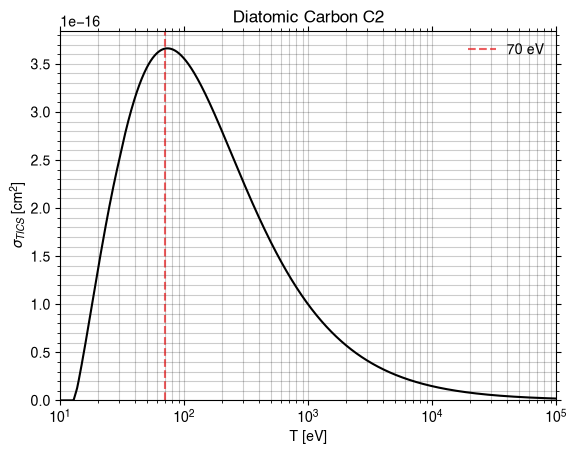

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(281)
Recherche : 'Carbon monoxide' -> CID 281, formule CO


Loading output/xyz/Carbon_monoxide_CO.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Carbon_monoxide_CO.xyzBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Carbon_monoxide_CO.gifGIF written to output/gif/Carbon_monoxide_CO.gif

strucutre 3D
Réussite. Nom: Carbon monoxide, formule: CO, M: 28.01, nom_marche: Carbon_monoxide
PYSCF CONVERGENCE
converged SCF energy = -112.780852159516
**** MO energy ****
MO #1   energy= -20.661777562742   occ= 2
MO #2   energy= -11.3288618517368  occ= 2
MO #3   energy= -1.57269982344034  occ= 2
MO #4   energy= -0.811064196218673 occ= 2
MO #5   energy= -0.673541011818529 occ= 2
MO #6   energy= -0.673541011818479 occ= 2
MO #7   energy= -0.545427839976181 occ= 2
MO #8   energy= 0.0744490497496919 occ= 0
MO #9   energy= 0.104442557159417  occ= 0
MO #10  energy= 0.104442557159422  occ= 0
MO #11  energy= 0.116719091454662  occ= 0
MO #12  energy= 0.162690510229927  occ= 0
MO #13  energy= 0.162690510229939  occ= 0
MO #14  energy= 0.188509311548096  occ= 0
MO #15  energy= 0.275927742874096  occ= 0
MO #16  energy= 0.275927742874116  occ= 0
MO #17  energy= 0.343624675070168  occ= 0
MO #18  energy= 0.350471019241852  occ= 0
MO #19  energy= 0.350471019241872  occ= 0
MO #20  energy= 0.430704212

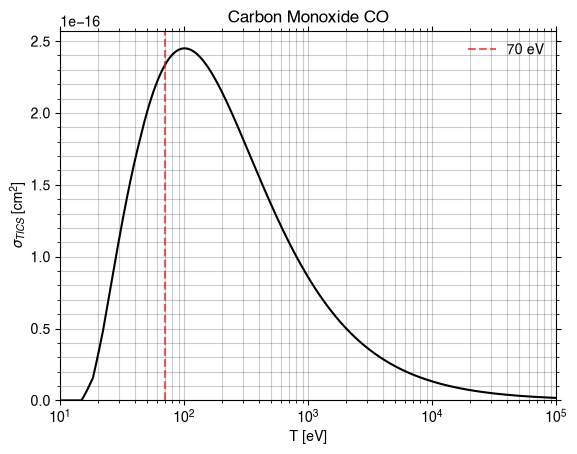

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(108054)
Recherche : 'Carbon monosulfide' -> CID 108054, formule CS


Loading output/xyz/Carbon_monosulfide_CS.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Carbon_monosulfide_CS.xyzBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Carbon_monosulfide_CS.gifGIF written to output/gif/Carbon_monosulfide_CS.gif

strucutre 3D
Réussite. Nom: Carbon monosulfide, formule: CS, M: 44.08, nom_marche: Carbon_monosulfide
PYSCF CONVERGENCE
converged SCF energy = -47.7683130025723
**** MO energy ****
MO #1   energy= -11.3246050326796  occ= 2
MO #2   energy= -1.1361348025772   occ= 2
MO #3   energy= -0.687208360522067 occ= 2
MO #4   energy= -0.480862525917297 occ= 2
MO #5   energy= -0.480862525917288 occ= 2
MO #6   energy= -0.462773201268267 occ= 2
MO #7   energy= 0.0657293375122934 occ= 0
MO #8   energy= 0.0657293375122992 occ= 0
MO #9   energy= 0.0685317874474625 occ= 0
MO #10  energy= 0.0995340044060822 occ= 0
MO #11  energy= 0.0995340044061245 occ= 0
MO #12  energy= 0.100663756267887  occ= 0
MO #13  energy= 0.207879901206766  occ= 0
MO #14  energy= 0.242581156415768  occ= 0
MO #15  energy= 0.242581156415772  occ= 0
MO #16  energy= 0.261087723673707  occ= 0
MO #17  energy= 0.324799792796278  occ= 0
MO #18  energy= 0.324799792796288  occ= 0
MO #19  energy= 0.369886808640708  occ= 0
MO #20  energy= 0.369

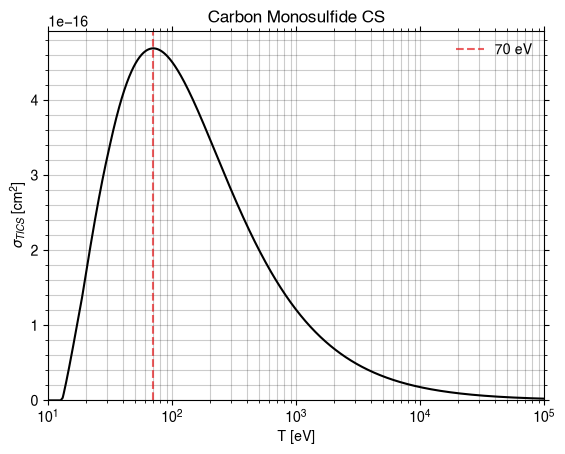

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(783)
Recherche : 'Molecular hydrogen' -> CID 783, formule H2


[22:45:16] WARNING: not removing hydrogen atom without neighbors
[22:45:16] WARNING: not removing hydrogen atom without neighbors
geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*****

2D
[Level 1] Processing SMILES: [HH]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
2
1
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Molecular hydrogen, formule: H2, M: 2.016, nom_marche: Molecular_hydrogen
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   H   0.354666   0.000000   0.000000    0.000000  0.000000  0.000000
   H  -0.354666   0.000000   0.000000    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -1.13257411750035
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 H    -0.0206436777     0.0000000000    -0.0000000000
1 H     0.0206436777    -0.0000000000     0.0000000000
---------------------------

Step    0 : Gradient = 2.064e-02/2.064e-02 (rms/max) Energy = -1.1325741175
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 4.35932e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   H   0.367196  -0.000000   0.000000    0.012530 -0.000000  0.000000
   H  -0.367196   0.000000  -0.000000   -0.012530  0.000000 -0.000000
converged SCF energy = -1.13305140911733
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 H    -0.0000571670    -0.0000000000     0.0000000000
1 H     0.0000571670     0.0000000000    -0.0000000000
----------------------------------------------
cycle 2: E = -1.13305140912  dE = -0.000477292  norm(grad) = 8.08464e-05


Step    1 : Displace = 1.253e-02/1.253e-02 (rms/max) Trust = 1.000e-01 (=) Grad = 5.717e-05/5.717e-05 (rms/max) E (change) = -1.1330514091 (-4.773e-04) Quality = 0.976
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 4.34725e-01



Geometry optimization cycle 3
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   H   0.367230  -0.000000  -0.000000    0.000035  0.000000 -0.000000
   H  -0.367230   0.000000   0.000000   -0.000035 -0.000000  0.000000
converged SCF energy = -1.13305141316581
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 H    -0.0000041940    -0.0000000000    -0.0000000000
1 H     0.0000041940     0.0000000000     0.0000000000
----------------------------------------------
cycle 3: E = -1.13305141317  dE = -4.04847e-09  norm(grad) = 5.93116e-06


Step    2 : Displace = 3.479e-05/3.479e-05 (rms/max) Trust = 1.414e-01 (+) Grad = 4.194e-06/4.194e-06 (rms/max) E (change) = -1.1330514132 (-4.048e-09) Quality = 1.077
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 5.00000e-02 5.00000e-02 4.34725e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 2.385 seconds
  frame 120/120xyz/Molecular_hydrogen_H2.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/

converged SCF energy = -1.13305141316594
**** MO energy ****
MO #1   energy= -0.596381199529913 occ= 2
MO #2   energy= 0.126569486516802  occ= 0
MO #3   energy= 0.19863267322314   occ= 0
MO #4   energy= 0.198632673223142  occ= 0
MO #5   energy= 0.224801095572046  occ= 0
MO #6   energy= 0.31226632791175   occ= 0
MO #7   energy= 0.312266327911754  occ= 0
MO #8   energy= 0.363006986969302  occ= 0
MO #9   energy= 0.418254385572403  occ= 0
MO #10  energy= 0.883082208303569  occ= 0
MO #11  energy= 0.916493186068284  occ= 0
MO #12  energy= 0.916493186068285  occ= 0
MO #13  energy= 1.17528151153562   occ= 0
MO #14  energy= 1.29243799276612   occ= 0
MO #15  energy= 1.29243799276612   occ= 0
MO #16  energy= 1.56056222144763   occ= 0
MO #17  energy= 2.54364288366546   occ= 0
MO #18  energy= 2.61242662683153   occ= 0
MO #19  energy= 3.17631591902778   occ= 0
MO #20  energy= 3.17631591902778   occ= 0
MO #21  energy= 3.56687882781937   occ= 0
MO #22  energy= 3.56687882781938   occ= 0
MO #23  energy=

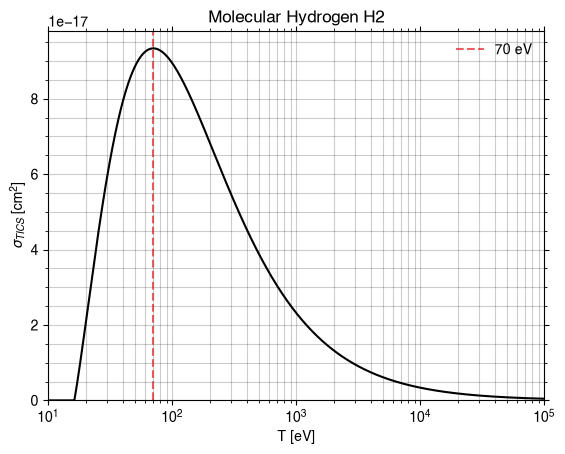

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(313)
Recherche : 'Hydrogen chloride' -> CID 313, formule ClH


Loading output/xyz/Hydrogen_chloride_ClH.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Hydrogen_chloride_ClH.xyzBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Hydrogen_chloride_ClH.gifGIF written to output/gif/Hydrogen_chloride_ClH.gif

strucutre 3D
Réussite. Nom: Hydrogen chloride, formule: ClH, M: 36.46, nom_marche: Hydrogen_chloride
PYSCF CONVERGENCE
converged SCF energy = -15.3186936125078
**** MO energy ****
MO #1   energy= -1.11854169999672  occ= 2
MO #2   energy= -0.620063502821697 occ= 2
MO #3   energy= -0.475572984405828 occ= 2
MO #4   energy= -0.475572984405827 occ= 2
MO #5   energy= 0.110912737490545  occ= 0
MO #6   energy= 0.121745335528648  occ= 0
MO #7   energy= 0.144880103351435  occ= 0
MO #8   energy= 0.144880103351439  occ= 0
MO #9   energy= 0.22357924376451   occ= 0
MO #10  energy= 0.237365278680448  occ= 0
MO #11  energy= 0.237365278680453  occ= 0
MO #12  energy= 0.334126929276782  occ= 0
MO #13  energy= 0.356147327146715  occ= 0
MO #14  energy= 0.356147327146719  occ= 0
MO #15  energy= 0.452841273526413  occ= 0
MO #16  energy= 0.452841273526426  occ= 0
MO #17  energy= 0.531410116178767  occ= 0
MO #18  energy= 0.632096765123583  occ= 0
MO #19  energy= 0.762240400040438  occ= 0
MO #20  energy= 0.7724

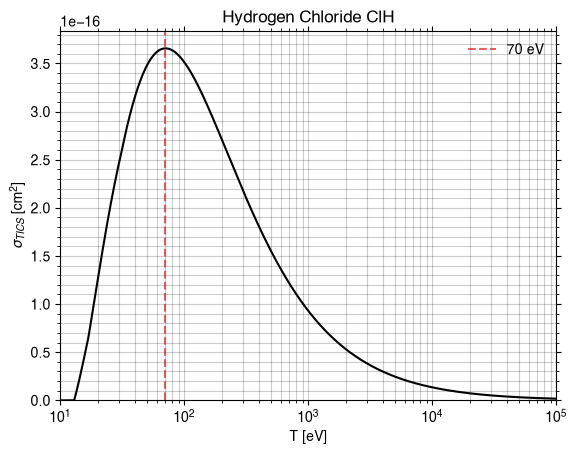

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(14917)
Recherche : 'Hydrogen fluoride' -> CID 14917, formule FH


Loading output/xyz/Hydrogen_fluoride_FH.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Hydrogen_fluoride_FH.xyzBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Hydrogen_fluoride_FH.gifGIF written to output/gif/Hydrogen_fluoride_FH.gif

strucutre 3D
Réussite. Nom: Hydrogen fluoride, formule: FH, M: 20.0064, nom_marche: Hydrogen_fluoride
PYSCF CONVERGENCE
converged SCF energy = -100.064797322193
**** MO energy ****
MO #1   energy= -26.2962814250929  occ= 2
MO #2   energy= -1.59337364837822  occ= 2
MO #3   energy= -0.759580672511184 occ= 2
MO #4   energy= -0.648211248378958 occ= 2
MO #5   energy= -0.648211248378834 occ= 2
MO #6   energy= 0.0817992318931786 occ= 0
MO #7   energy= 0.154940568312978  occ= 0
MO #8   energy= 0.15562714072937   occ= 0
MO #9   energy= 0.155627140729374  occ= 0
MO #10  energy= 0.276323629321256  occ= 0
MO #11  energy= 0.27632362932133   occ= 0
MO #12  energy= 0.290529742120625  occ= 0
MO #13  energy= 0.358152179222891  occ= 0
MO #14  energy= 0.588140919206137  occ= 0
MO #15  energy= 0.609284371094425  occ= 0
MO #16  energy= 0.60928437109447   occ= 0
MO #17  energy= 0.729487715169704  occ= 0
MO #18  energy= 0.72948771516973   occ= 0
MO #19  energy= 0.859231723503355  occ= 0
MO #20  energy= 0.910

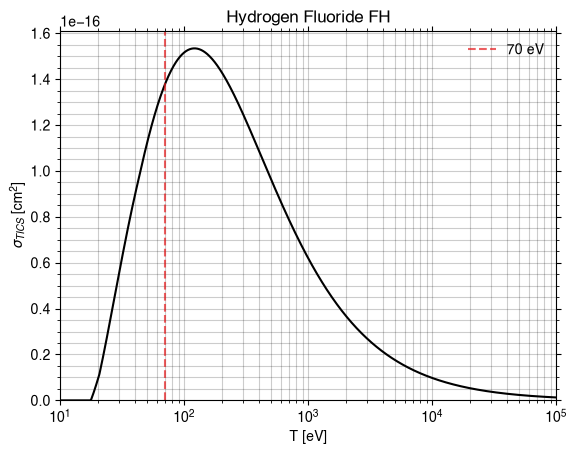

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(4873)
Recherche : 'Potassium chloride' -> CID 4873, formule ClK


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [Cl-].[K+]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
2
0
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Potassium chloride, formule: ClK, M: 74.55, nom_marche: Potassium_chloride
PYSCF CONVERGENCE
temp.xyz a échoué : TypeError : 'NoneType' object is not subscriptable
ORBITAL CAR
Potassium chloride a échoué : TypeError : 'NoneType' object is not iterable


/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/geometric/internal.py:528: RuntimeWarning: invalid value encountered in scalar divide
  if L[0]/L[1] < thre_lo and L[0]/L[1] > 0.0 and self.rmode in (-1, 0):
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/geometric/internal.py:534: RuntimeWarning: invalid value encountered in scalar divide
  elif L[0]/L[1] > thre_hi and self.rmode in (1, 0):
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/geometric/internal.py:540: RuntimeWarning: invalid value encountered in scalar divide
  if L[0]/L[1] < thre_mid and L[0]/L[1] > 0.0:
Loading output/xyz/Molecular_nitrogen_N2.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Molecular_nitrogen_N2.xyzBuilt graph: 2 atoms, 1 bonds

Compound(947)
Recherche : 'Molecular nitrogen' -> CID 947, formule N2
3D


  frame 120/120ion GIF (120 frames, axis=y)
Wrote output/gif/Molecular_nitrogen_N2.gifGIF written to output/gif/Molecular_nitrogen_N2.gif

strucutre 3D
Réussite. Nom: Molecular nitrogen, formule: N2, M: 28.014, nom_marche: Molecular_nitrogen
PYSCF CONVERGENCE
converged SCF energy = -108.98498837489
**** MO energy ****
MO #1   energy= -15.6892273389507  occ= 2
MO #2   energy= -15.6859761564068  occ= 2
MO #3   energy= -1.46122192732675  occ= 2
MO #4   energy= -0.78342497868956  occ= 2
MO #5   energy= -0.633077334205533 occ= 2
MO #6   energy= -0.608241434730678 occ= 2
MO #7   energy= -0.608241434730627 occ= 2
MO #8   energy= 0.125785315722243  occ= 0
MO #9   energy= 0.142083322103941  occ= 0
MO #10  energy= 0.142083322103953  occ= 0
MO #11  energy= 0.15463697376378   occ= 0
MO #12  energy= 0.316435512142085  occ= 0
MO #13  energy= 0.365021930861425  occ= 0
MO #14  energy= 0.365021930861447  occ= 0
MO #15  energy= 0.390052857376008  occ= 0
MO #16  energy= 0.390052857376081  occ= 0
MO #17  energy= 0.406605641739077  occ= 0
MO #18  energy= 0.40660564173922   occ= 0
MO #19  energy= 0.415945867618178  occ= 0
MO #20  energy= 0.522

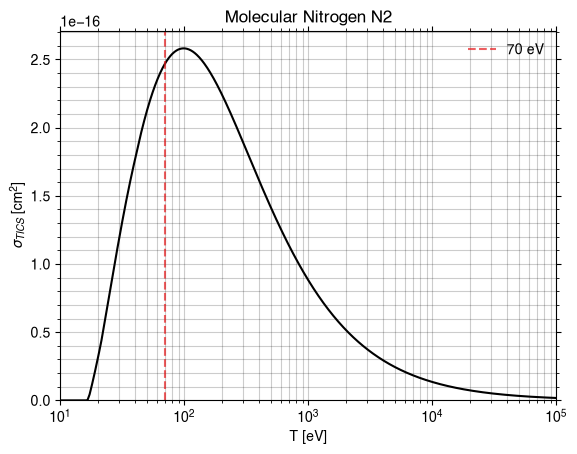

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(5234)
Recherche : 'Sodium chloride' -> CID 5234, formule ClNa


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [Na+].[Cl-]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
2
0
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Sodium chloride, formule: ClNa, M: 58.44, nom_marche: Sodium_chloride
PYSCF CONVERGENCE
temp.xyz a échoué : TypeError : 'NoneType' object is not subscriptable
ORBITAL CAR
Sodium chloride a échoué : TypeError : 'NoneType' object is not iterable


/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/geometric/internal.py:528: RuntimeWarning: invalid value encountered in scalar divide
  if L[0]/L[1] < thre_lo and L[0]/L[1] > 0.0 and self.rmode in (-1, 0):
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/geometric/internal.py:534: RuntimeWarning: invalid value encountered in scalar divide
  elif L[0]/L[1] > thre_hi and self.rmode in (1, 0):
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/geometric/internal.py:540: RuntimeWarning: invalid value encountered in scalar divide
  if L[0]/L[1] < thre_mid and L[0]/L[1] > 0.0:
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Phosphorus mononitride not found : IndexError : list index out of range
Phosphorus mononitride a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(66241)
Recherche : 'Silicon monoxide' -> CID 66241, formule OSi


Loading output/xyz/Silicon_monoxide_OSi.xyzBuilt graph: 2 atoms, 1 bondsLoading output/xyz/Silicon_monoxide_OSi.xyzBuilt graph: 2 atoms, 1 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Silicon_monoxide_OSi.gifGIF written to output/gif/Silicon_monoxide_OSi.gif

strucutre 3D
Réussite. Nom: Silicon monoxide, formule: OSi, M: 44.084, nom_marche: Silicon_monoxide
PYSCF CONVERGENCE
converged SCF energy = -78.6284853965744
**** MO energy ****
MO #1   energy= -20.5175285549114  occ= 2
MO #2   energy= -1.32331245155712  occ= 2
MO #3   energy= -0.61679478093113  occ= 2
MO #4   energy= -0.521408053672552 occ= 2
MO #5   energy= -0.521408053672434 occ= 2
MO #6   energy= -0.429749008234765 occ= 2
MO #7   energy= 0.0292509191369439 occ= 0
MO #8   energy= 0.0292509191369832 occ= 0
MO #9   energy= 0.0507330700416787 occ= 0
MO #10  energy= 0.0858553198070737 occ= 0
MO #11  energy= 0.0942500185088446 occ= 0
MO #12  energy= 0.0942500185088869 occ= 0
MO #13  energy= 0.137391501414898  occ= 0
MO #14  energy= 0.159707075456785  occ= 0
MO #15  energy= 0.159707075456838  occ= 0
MO #16  energy= 0.17298148113153   occ= 0
MO #17  energy= 0.172981481131573  occ= 0
MO #18  energy= 0.190446883197552  occ= 0
MO #19  energy= 0.240821878417656  occ= 0
MO #20  energy= 0.24082

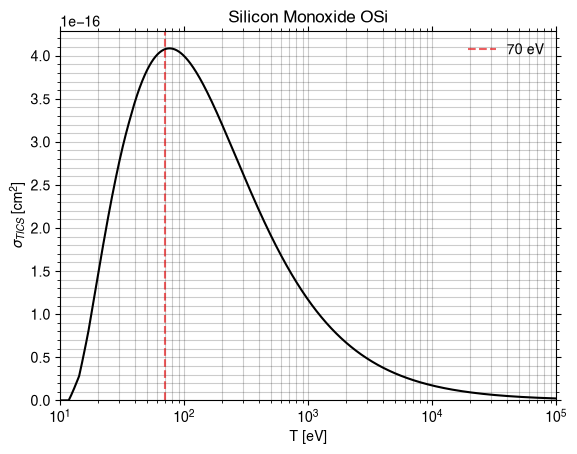

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(237873)
Recherche : 'Sodium sulfide' -> CID 237873, formule HNa2S+


[22:46:29] UFFTYPER: Unrecognized charge state for atom: 0
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

2D
[Level 1] Processing SMILES: [Na+].[Na+].[SH-]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
4
1
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Sodium sulfide, formule: HNa2S+, M: 79.06, nom_marche: Sodium_sulfide
PYSCF CONVERGENCE
temp.xyz a échoué : RuntimeError : Electron number 29 and spin 0 are not consistent
Note mol.spin = 2S = Nalpha - Nbeta, not 2S+1
Sodium sulfide a échoué : UnboundLocalError : cannot access local variable 'mf' where it is not associated with a value
Silicon monosulfide not found : IndexError : list index out of range
Silicon monosulfide a échoué : TypeError : cannot unpack non-iterable NoneType object


PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Aluminium isocyanide not found : IndexError : list index out of range
Aluminium isocyanide a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(10176082)
Recherche : 'Aluminium hydroxide' -> CID 10176082, formule AlH3O3


... (8 outputs left out)

Loading output/xyz/Carbon_dioxide_CO2.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Carbon_dioxide_CO2.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Carbon_dioxide_CO2.gifGIF written to output/gif/Carbon_dioxide_CO2.gif

strucutre 3D
Réussite. Nom: Carbon dioxide, formule: CO2, M: 44.009, nom_marche: Carbon_dioxide
PYSCF CONVERGENCE
converged SCF energy = -187.703416563818
**** MO energy ****
MO #1   energy= -20.6602466346888  occ= 2
MO #2   energy= -20.6602087566888  occ= 2
MO #3   energy= -11.4800217867381  occ= 2
MO #4   energy= -1.51124392531356  occ= 2
MO #5   energy= -1.45873943539029  occ= 2
MO #6   energy= -0.804788288048382 occ= 2
MO #7   energy= -0.736926817459629 occ= 2
MO #8   energy= -0.70090427939883  occ= 2
MO #9   energy= -0.700904279398821 occ= 2
MO #10  energy= -0.543016338305828 occ= 2
MO #11  energy= -0.543016338305819 occ= 2
MO #12  energy= 0.044205249648531  occ= 0
MO #13  energy= 0.0964167753672149 occ= 0
MO #14  energy= 0.103349062674088  occ= 0
MO #15  energy= 0.103349062674108  occ= 0
MO #16  energy= 0.128944900395167  occ= 0
MO #17  energy= 0.14012080067334   occ= 0
MO #18  energy= 0.140120800673352  occ= 0
MO #19  energy= 0.17653196311375   occ= 0
MO #20  energy= 0.176531963

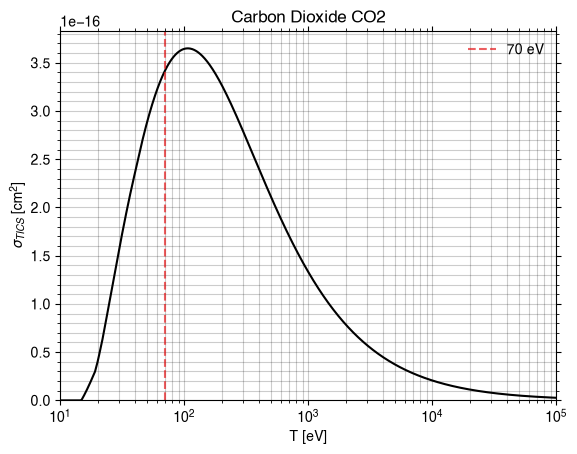

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Water_H2O.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Water_H2O.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

Compound(962)
Recherche : 'Water' -> CID 962, formule H2O
3D


  frame 120/120
Wrote output/gif/Water_H2O.gifGIF written to output/gif/Water_H2O.gif

strucutre 3D
Réussite. Nom: Water, formule: H2O, M: 18.015, nom_marche: Water
PYSCF CONVERGENCE
converged SCF energy = -76.0627868801916
**** MO energy ****
MO #1   energy= -20.5673043567071  occ= 2
MO #2   energy= -1.34699966122407  occ= 2
MO #3   energy= -0.710439640870369 occ= 2
MO #4   energy= -0.583637500642439 occ= 2
MO #5   energy= -0.509582579005603 occ= 2
MO #6   energy= 0.0696083324150249 occ= 0
MO #7   energy= 0.100842445554568  occ= 0
MO #8   energy= 0.130024880597925  occ= 0
MO #9   energy= 0.132731699355877  occ= 0
MO #10  energy= 0.216605154113151  occ= 0
MO #11  energy= 0.238580360854085  occ= 0
MO #12  energy= 0.264103317483851  occ= 0
MO #13  energy= 0.289973603323715  occ= 0
MO #14  energy= 0.299256146748196  occ= 0
MO #15  energy= 0.351183025614532  occ= 0
MO #16  energy= 0.35730215457211   occ= 0
MO #17  energy= 0.399455947327124  occ= 0
MO #18  energy= 0.520582561480371  occ= 0
MO #19  energy= 0.528766946652052  occ= 0
MO #20  energy= 0.567645227998797  occ= 0
MO 

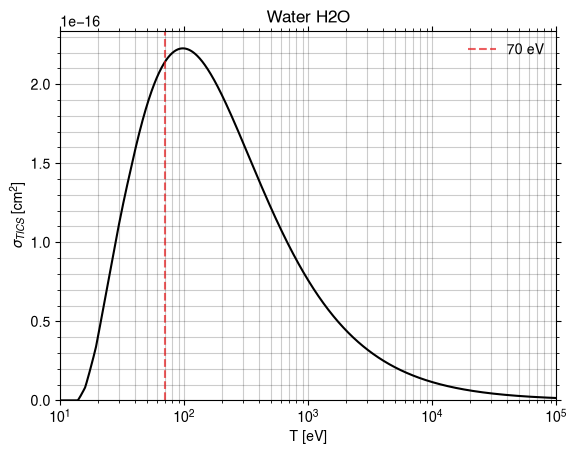

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Hydrogen_sulfide_H2S.xyz

Compound(402)
Recherche : 'Hydrogen sulfide' -> CID 402, formule H2S
3D


  frame 120/120atoms, 2 bondsLoading output/xyz/Hydrogen_sulfide_H2S.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/Hydrogen_sulfide_H2S.gifGIF written to output/gif/Hydrogen_sulfide_H2S.gif

strucutre 3D
Réussite. Nom: Hydrogen sulfide, formule: H2S, M: 34.08, nom_marche: Hydrogen_sulfide
PYSCF CONVERGENCE
converged SCF energy = -11.1312552213733
**** MO energy ****
MO #1   energy= -0.985521542969543 occ= 2
MO #2   energy= -0.592016158468213 occ= 2
MO #3   energy= -0.499632139127336 occ= 2
MO #4   energy= -0.384109709547218 occ= 2
MO #5   energy= 0.0886185994825087 occ= 0
MO #6   energy= 0.0940654545136826 occ= 0
MO #7   energy= 0.112414531260854  occ= 0
MO #8   energy= 0.115628334045154  occ= 0
MO #9   energy= 0.13456681809642   occ= 0
MO #10  energy= 0.205580252868107  occ= 0
MO #11  energy= 0.236390697066682  occ= 0
MO #12  energy= 0.242113670160298  occ= 0
MO #13  energy= 0.248889886994461  occ= 0
MO #14  energy= 0.29994098955307   occ= 0
MO #15  energy= 0.328360076014705  occ= 0
MO #16  energy= 0.335839828712748  occ= 0
MO #17  energy= 0.37147587803131   occ= 0
MO #18  energy= 0.384810466803722  occ= 0
MO #19  energy= 0.388237174725334  occ= 0
MO #20  energy= 0.392218

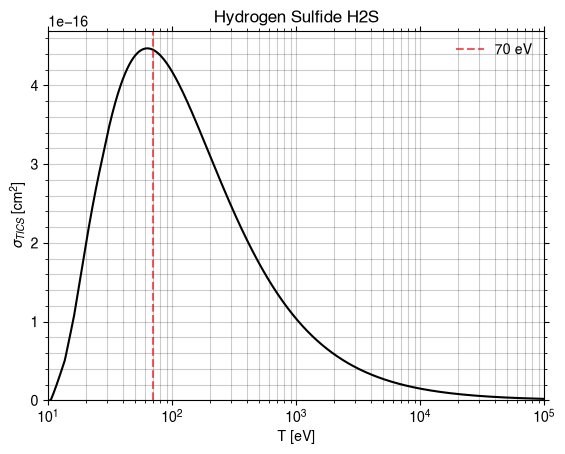

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Hydrogen_cyanide_CHN.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Hydrogen_cyanide_CHN.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

Compound(768)
Recherche : 'Hydrogen cyanide' -> CID 768, formule CHN
3D


  frame 120/120
Wrote output/gif/Hydrogen_cyanide_CHN.gifGIF written to output/gif/Hydrogen_cyanide_CHN.gif

strucutre 3D
Réussite. Nom: Hydrogen cyanide, formule: CHN, M: 27.025, nom_marche: Hydrogen_cyanide
PYSCF CONVERGENCE
converged SCF energy = -92.9106397577761
**** MO energy ****
MO #1   energy= -15.6018200100205  occ= 2
MO #2   energy= -11.2936467551125  occ= 2
MO #3   energy= -1.23325815285305  occ= 2
MO #4   energy= -0.814163210089475 occ= 2
MO #5   energy= -0.58238241747577  occ= 2
MO #6   energy= -0.494799949717786 occ= 2
MO #7   energy= -0.494799949717738 occ= 2
MO #8   energy= 0.0618933855469024 occ= 0
MO #9   energy= 0.121148502865764  occ= 0
MO #10  energy= 0.135033338605158  occ= 0
MO #11  energy= 0.135033338605183  occ= 0
MO #12  energy= 0.187395262656416  occ= 0
MO #13  energy= 0.234741852811551  occ= 0
MO #14  energy= 0.234741852811564  occ= 0
MO #15  energy= 0.273252255553232  occ= 0
MO #16  energy= 0.273252255553234  occ= 0
MO #17  energy= 0.299804163929563  occ= 0
MO #18  energy= 0.30515929907061   occ= 0
MO #19  energy= 0.305159299070656  occ= 0
MO #20  energy= 0.32514

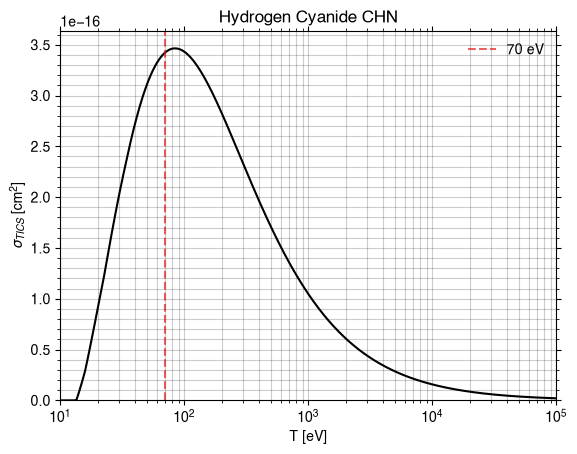

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Hydrogen_isocyanide_CHN.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Hydrogen_isocyanide_CHN.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

Compound(6432654)
Recherche : 'Hydrogen isocyanide' -> CID 6432654, formule CHN
3D


  frame 120/120
Wrote output/gif/Hydrogen_isocyanide_CHN.gifGIF written to output/gif/Hydrogen_isocyanide_CHN.gif

strucutre 3D
Réussite. Nom: Hydrogen isocyanide, formule: CHN, M: 27.025, nom_marche: Hydrogen_isocyanide
PYSCF CONVERGENCE
converged SCF energy = -92.89547798106
**** MO energy ****
MO #1   energy= -15.6059067424837  occ= 2
MO #2   energy= -11.2972128861597  occ= 2
MO #3   energy= -1.2636709630211   occ= 2
MO #4   energy= -0.869749688815695 occ= 2
MO #5   energy= -0.520302104540114 occ= 2
MO #6   energy= -0.520302104540086 occ= 2
MO #7   energy= -0.491294593765028 occ= 2
MO #8   energy= 0.0761713397688109 occ= 0
MO #9   energy= 0.110172584640551  occ= 0
MO #10  energy= 0.149323802945512  occ= 0
MO #11  energy= 0.149323802945517  occ= 0
MO #12  energy= 0.183871988033893  occ= 0
MO #13  energy= 0.208070172302247  occ= 0
MO #14  energy= 0.208070172302283  occ= 0
MO #15  energy= 0.293236056096046  occ= 0
MO #16  energy= 0.293236056096095  occ= 0
MO #17  energy= 0.310509600975864  occ= 0
MO #18  energy= 0.329391262956487  occ= 0
MO #19  energy= 0.329391262956511  occ= 0
MO #20  energy= 0.3

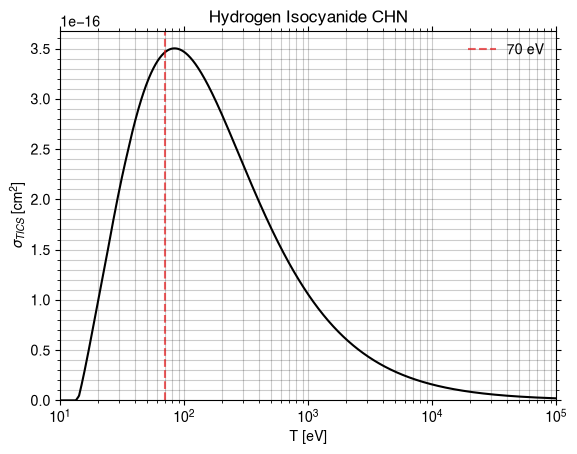

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(138843)
Recherche : 'Phosphaethyne' -> CID 138843, formule CHP


Loading output/xyz/Phosphaethyne_CHP.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Phosphaethyne_CHP.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Phosphaethyne_CHP.gifGIF written to output/gif/Phosphaethyne_CHP.gif

strucutre 3D
Réussite. Nom: Phosphaethyne, formule: CHP, M: 43.992, nom_marche: Phosphaethyne
PYSCF CONVERGENCE
converged SCF energy = -44.7782586031568
**** MO energy ****
MO #1   energy= -11.2635990256637  occ= 2
MO #2   energy= -0.981009239162187 occ= 2
MO #3   energy= -0.727972780699453 occ= 2
MO #4   energy= -0.493096993765349 occ= 2
MO #5   energy= -0.392640053141486 occ= 2
MO #6   energy= -0.392640053141472 occ= 2
MO #7   energy= 0.0595856598711615 occ= 0
MO #8   energy= 0.0648427473496626 occ= 0
MO #9   energy= 0.0648427473496707 occ= 0
MO #10  energy= 0.0760325076655867 occ= 0
MO #11  energy= 0.0996339015684704 occ= 0
MO #12  energy= 0.0996339015684958 occ= 0
MO #13  energy= 0.152711944969862  occ= 0
MO #14  energy= 0.21040804067794   occ= 0
MO #15  energy= 0.220949977628414  occ= 0
MO #16  energy= 0.220949977628418  occ= 0
MO #17  energy= 0.247631757001068  occ= 0
MO #18  energy= 0.253265786876343  occ= 0
MO #19  energy= 0.253265786876389  occ= 0
MO #20  energy= 0.27734944782

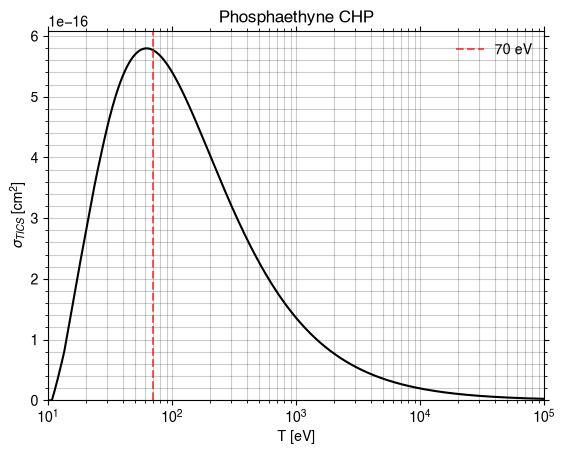

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(945)
Recherche : 'Nitroxyl' -> CID 945, formule HNO


Loading output/xyz/Nitroxyl_HNO.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Nitroxyl_HNO.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Nitroxyl_HNO.gifGIF written to output/gif/Nitroxyl_HNO.gif

strucutre 3D
Réussite. Nom: Nitroxyl, formule: HNO, M: 31.014, nom_marche: Nitroxyl
PYSCF CONVERGENCE
converged SCF energy = -129.838854142213
**** MO energy ****
MO #1   energy= -20.6570431105904  occ= 2
MO #2   energy= -15.7118171334223  occ= 2
MO #3   energy= -1.5075720002905   occ= 2
MO #4   energy= -1.0135030100886   occ= 2
MO #5   energy= -0.74382751149701  occ= 2
MO #6   energy= -0.658883093451983 occ= 2
MO #7   energy= -0.582992463861451 occ= 2
MO #8   energy= -0.438572634903032 occ= 2
MO #9   energy= 0.0636311384568174 occ= 0
MO #10  energy= 0.0858045256483043 occ= 0
MO #11  energy= 0.111981527734948  occ= 0
MO #12  energy= 0.130069794632077  occ= 0
MO #13  energy= 0.13741352742541   occ= 0
MO #14  energy= 0.187515415507759  occ= 0
MO #15  energy= 0.215258245401762  occ= 0
MO #16  energy= 0.244498233606409  occ= 0
MO #17  energy= 0.2929613558023    occ= 0
MO #18  energy= 0.333635514890659  occ= 0
MO #19  energy= 0.397115023135359  occ= 0
MO #20  energy= 0.398471588140077  occ=

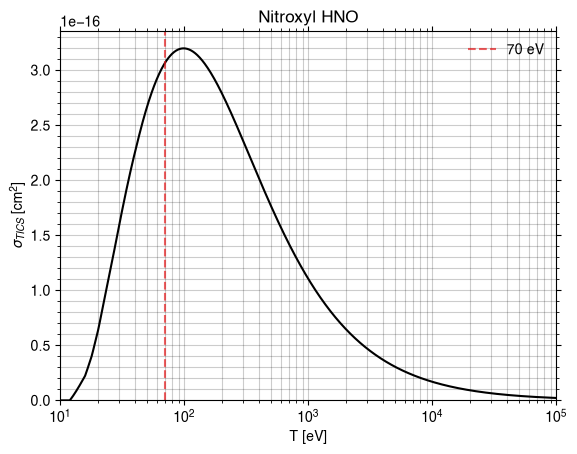

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(9032)
Recherche : 'Potassium cyanide' -> CID 9032, formule CKN


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [C-]#N.[K+]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
3
1
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Potassium cyanide, formule: CKN, M: 65.116, nom_marche: Potassium_cyanide
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   0.582808   0.000000   0.000000    0.000000  0.000000  0.000000
   N  -0.582808   0.000000   0.000000    0.000000  0.000000  0.000000
   K   0.000000   0.000000   0.000000    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -261.58651788625
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C   -10.8864847673     0.0000000000     0.0000000000
1 N   

Step    0 : Gradient = 1.434e+01/2.026e+01 (rms/max) Energy = -261.5865178862
Hessian Eigenvalues: -2.32959e+01 -6.93737e+00 5.00000e-02 ... 5.00000e-02 2.50000e-01 2.50000e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   0.656719  -0.000000  -0.000000    0.073911 -0.000000 -0.000000
   N  -0.515297   0.000000   0.000000    0.067511  0.000000  0.000000
   K  -0.141421  -0.000000  -0.000000   -0.141421 -0.000000 -0.000000
converged SCF energy = -258.27486063111
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C    -0.8275134217    -0.0000000000    -0.0000000000
1 N    71.6264375283    -0.0000000000    -0.0000000000
2 K   -70.7989241066     0.0000000000     0.0000000000
----------------------------------------------
cycle 2: E = -258.274860631  dE = 3.31166  norm(grad) = 100.715


... (26 outputs left out)

Step   14 : Displace = 8.014e-05/1.112e-04 (rms/max) Trust = 1.000e-01 (+) Grad = 7.440e-03/9.680e-03 (rms/max) E (change) = -265.3526193161 (-2.361e-06) Quality = 1.282
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 2.50000e-01 3.15447e+00 1.86010e+02



Geometry optimization cycle 16
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   0.825737  -0.000000  -0.000000    0.000050  0.000000 -0.000000
   N  -0.648744   0.000000   0.000000   -0.000032 -0.000000  0.000000
   K  -0.176993   0.000000   0.000000   -0.000018 -0.000000  0.000000
converged SCF energy = -265.352619520634
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C     0.0000460003     0.0000000000    -0.0000000000
1 N     0.0000126499     0.0000000000     0.0000000000
2 K    -0.0000586502    -0.0000000000    -0.0000000000
----------------------------------------------
cycle 16: E = -265.352619521  dE = -2.04566e-07  norm(grad) = 7.56035e-05


Step   15 : Displace = 3.615e-05/5.047e-05 (rms/max) Trust = 1.414e-01 (+) Grad = 4.365e-05/5.865e-05 (rms/max) E (change) = -265.3526195206 (-2.046e-07) Quality = 0.968
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 2.50000e-01 3.15447e+00 1.86010e+02
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 42.370 seconds
  frame 120/120xyz/Potassium_cyanide_CKN.xyzK2 reads +3 at charge=+0, not one of its usua

converged SCF energy = -265.352619520641
**** MO energy ****
MO #1   energy= -25.6274221475199  occ= 2
MO #2   energy= -19.1852243090259  occ= 2
MO #3   energy= -11.3014996411867  occ= 2
MO #4   energy= -7.19116014108365  occ= 2
MO #5   energy= -7.19116013810238  occ= 2
MO #6   energy= -6.16318103301246  occ= 2
MO #7   energy= -2.66595165322352  occ= 2
MO #8   energy= -1.79943100976009  occ= 2
MO #9   energy= -1.79943098222708  occ= 2
MO #10  energy= -1.47532139469303  occ= 2
MO #11  energy= -0.729731520370816 occ= 2
MO #12  energy= -0.72973148653609  occ= 2
MO #13  energy= -0.66445022497826  occ= 2
MO #14  energy= -0.541339138916616 occ= 2
MO #15  energy= -0.536349021345938 occ= 2
MO #16  energy= -0.536348989293907 occ= 2
MO #17  energy= 0.0717774448695891 occ= 0
MO #18  energy= 0.118825498005395  occ= 0
MO #19  energy= 0.134181174517665  occ= 0
MO #20  energy= 0.134181176161544  occ= 0
MO #21  energy= 0.252921819621067  occ= 0
MO #22  energy= 0.262815983101304  occ= 0
MO #23  energy=

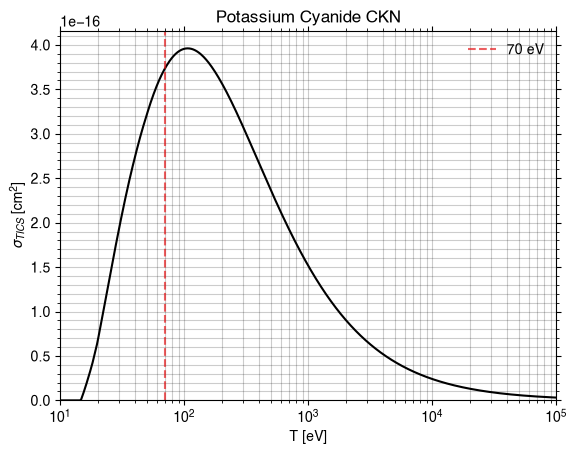

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(948)
Recherche : 'Nitrous oxide' -> CID 948, formule N2O


Loading output/xyz/Nitrous_oxide_N2O.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Nitrous_oxide_N2O.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Nitrous_oxide_N2O.gifGIF written to output/gif/Nitrous_oxide_N2O.gif

strucutre 3D
Réussite. Nom: Nitrous oxide, formule: N2O, M: 44.013, nom_marche: Nitrous_oxide
PYSCF CONVERGENCE
converged SCF energy = -183.726572293499
**** MO energy ****
MO #1   energy= -20.6352762866893  occ= 2
MO #2   energy= -15.8102143490921  occ= 2
MO #3   energy= -15.7343604929012  occ= 2
MO #4   energy= -1.55962221206206  occ= 2
MO #5   energy= -1.33941318331264  occ= 2
MO #6   energy= -0.816336208640898 occ= 2
MO #7   energy= -0.71893481140623  occ= 2
MO #8   energy= -0.718934811406187 occ= 2
MO #9   energy= -0.704560567076132 occ= 2
MO #10  energy= -0.504630438895553 occ= 2
MO #11  energy= -0.504630438895446 occ= 2
MO #12  energy= 0.0835488144280054 occ= 0
MO #13  energy= 0.112602171120655  occ= 0
MO #14  energy= 0.117115360093581  occ= 0
MO #15  energy= 0.117115360093629  occ= 0
MO #16  energy= 0.136373934122072  occ= 0
MO #17  energy= 0.136373934122112  occ= 0
MO #18  energy= 0.162545687217953  occ= 0
MO #19  energy= 0.231940971236533  occ= 0
MO #20  energy= 0.29058564976

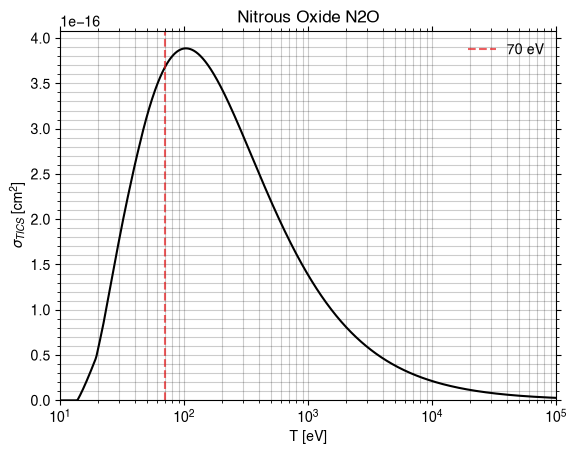

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(8929)
Recherche : 'Sodium cyanide' -> CID 8929, formule CNNa


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [C-]#N.[Na+]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
3
1
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Sodium cyanide, formule: CNNa, M: 49.007, nom_marche: Sodium_cyanide
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   0.581590   0.000000   0.000000    0.000000  0.000000  0.000000
   N  -0.581590   0.000000   0.000000    0.000000  0.000000  0.000000
  Na   0.000000   0.000000   0.000000    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -244.116570997303
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C   -13.7771494392     0.0000000000     0.0000000000
1 N    15

Step    0 : Gradient = 1.193e+01/1.533e+01 (rms/max) Energy = -244.1165709973
Hessian Eigenvalues: -2.29176e+01 -6.80097e+00 5.00000e-02 ... 5.00000e-02 2.50000e-01 2.50000e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   C   0.674774  -0.000000   0.000000    0.093184 -0.000000  0.000000
   N  -0.720333   0.000000  -0.000000   -0.138743  0.000000 -0.000000
  Na   0.045559   0.000000   0.000000    0.045559  0.000000  0.000000
converged SCF energy = -248.253579511243
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 C    -9.9975913352     0.0000000000     0.0000000000
1 N     4.6535106139     0.0000000000     0.0000000000
2 Na     5.3440807213    -0.0000000000    -0.0000000000
----------------------------------------------
cycle 2: E = -248.253579511  dE = -4.13701  norm(grad) = 12.2542


... (124 outputs left out)

Step   29 : Displace = 3.000e-01/4.243e-01 (rms/max) Trust = 3.000e-01 (=) Grad = 6.982e-05/9.837e-05 (rms/max) E (change) = -237.0740720572 (-6.053e-05) Quality = 1.136
Eigenvalues below 1.0000e-05 (7.5663e-06) - returning guess
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.00000e-01 1.00000e-01 1.00000e-01



Geometry optimization cycle 31
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   O   5.962783   0.001945   0.001668    0.000074  0.000035  0.000030
  Na  -2.025825  -0.000660  -0.000566    0.000100 -0.000012 -0.000010
   H  -3.936958  -0.001285  -0.001102   -0.000174 -0.000023 -0.000020
converged SCF energy = -237.07407209908
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 O    -0.0000417669    -0.0000000290    -0.0000000248
1 Na    -0.0000299142     0.0000000196     0.0000000168
2 H     0.0000716811     0.0000000093     0.0000000080
----------------------------------------------
cycle 31: E = -237.074072099  dE = -4.18646e-08  norm(grad) = 8.81902e-05


Step   30 : Displace = 1.232e-04/1.735e-04 (rms/max) Trust = 3.000e-01 (=) Grad = 5.092e-05/7.168e-05 (rms/max) E (change) = -237.0740720991 (-4.186e-08) Quality = 1.717
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.00000e-01 1.00000e-01 1.00000e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 85.336 seconds
  frame 120/120xyz/Sodium_hydroxide_HNaO.xyzBuilt graph: 3 atoms, 1 bondsLoading output/x

converged SCF energy = -237.074355960655
**** MO energy ****
MO #1   energy= -40.4670919328164  occ= 2
MO #2   energy= -20.7173124711181  occ= 2
MO #3   energy= -2.78939097603137  occ= 2
MO #4   energy= -1.51130533034804  occ= 2
MO #5   energy= -1.51130466202844  occ= 2
MO #6   energy= -1.50987706851488  occ= 2
MO #7   energy= -1.27283753515772  occ= 2
MO #8   energy= -0.596615920420869 occ= 2
MO #9   energy= -0.596549512365322 occ= 2
MO #10  energy= -0.273650997598843 occ= 2
MO #11  energy= -0.0335181829668932 occ= 0
MO #12  energy= -0.00462236393776272 occ= 0
MO #13  energy= 0.0205724190178184 occ= 0
MO #14  energy= 0.0206166587604747 occ= 0
MO #15  energy= 0.0401771298868397 occ= 0
MO #16  energy= 0.07381727534066   occ= 0
MO #17  energy= 0.0738271473573355 occ= 0
MO #18  energy= 0.0786083871739925 occ= 0
MO #19  energy= 0.121440391218393  occ= 0
MO #20  energy= 0.126694775044687  occ= 0
MO #21  energy= 0.135621794174159  occ= 0
MO #22  energy= 0.139958233421538  occ= 0
MO #23  ener

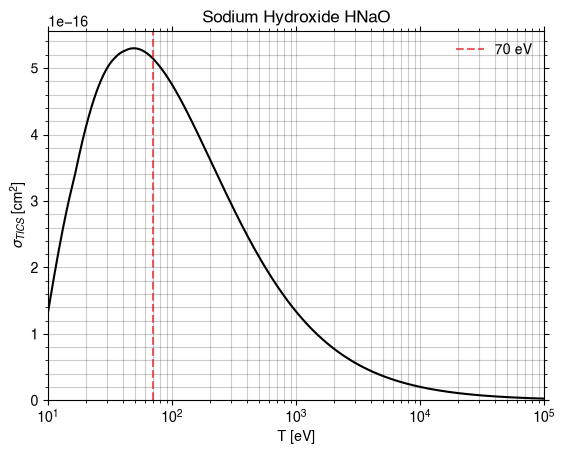

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Carbonyl_sulfide_COS.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Carbonyl_sulfide_COS.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

Compound(10039)
Recherche : 'Carbonyl sulfide' -> CID 10039, formule COS
3D


  frame 120/120
Wrote output/gif/Carbonyl_sulfide_COS.gifGIF written to output/gif/Carbonyl_sulfide_COS.gif

strucutre 3D
Réussite. Nom: Carbonyl sulfide, formule: COS, M: 60.08, nom_marche: Carbonyl_sulfide
PYSCF CONVERGENCE
converged SCF energy = -122.758398000164
**** MO energy ****
MO #1   energy= -20.6615367934776  occ= 2
MO #2   energy= -11.4464731904859  occ= 2
MO #3   energy= -1.49565745398167  occ= 2
MO #4   energy= -1.086599600494    occ= 2
MO #5   energy= -0.779632700024447 occ= 2
MO #6   energy= -0.652952198793338 occ= 2
MO #7   energy= -0.652952198568609 occ= 2
MO #8   energy= -0.638442248616876 occ= 2
MO #9   energy= -0.420093564721109 occ= 2
MO #10  energy= -0.42009356385753  occ= 2
MO #11  energy= 0.056254168754179  occ= 0
MO #12  energy= 0.0765526765222703 occ= 0
MO #13  energy= 0.0858107932669051 occ= 0
MO #14  energy= 0.0858107954686744 occ= 0
MO #15  energy= 0.111503086566952  occ= 0
MO #16  energy= 0.111503094194076  occ= 0
MO #17  energy= 0.117078148685619  occ= 0
MO #18  energy= 0.133889658652394  occ= 0
MO #19  energy= 0.133889659906819  occ= 0
MO #20  energy= 0.190482

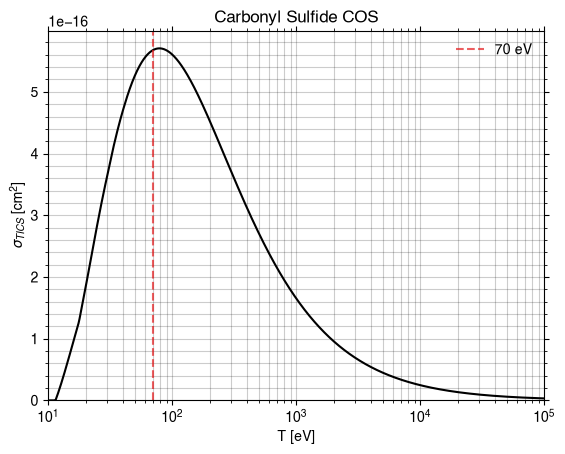

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(24823)
Recherche : 'Ozone' -> CID 24823, formule O3


Loading output/xyz/Ozone_O3.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Ozone_O3.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ozone_O3.gifGIF written to output/gif/Ozone_O3.gif

strucutre 3D
Réussite. Nom: Ozone, formule: O3, M: 47.998, nom_marche: Ozone
PYSCF CONVERGENCE
converged SCF energy = -224.328467147983
**** MO energy ****
MO #1   energy= -20.9018288132777  occ= 2
MO #2   energy= -20.7844243539457  occ= 2
MO #3   energy= -20.6454193081363  occ= 2
MO #4   energy= -1.74163248154952  occ= 2
MO #5   energy= -1.36258407757133  occ= 2
MO #6   energy= -1.11543143678614  occ= 2
MO #7   energy= -0.83302967043934  occ= 2
MO #8   energy= -0.798359476248632 occ= 2
MO #9   energy= -0.760365617233828 occ= 2
MO #10  energy= -0.569389891760605 occ= 2
MO #11  energy= -0.526896217399936 occ= 2
MO #12  energy= -0.48741407834164  occ= 2
MO #13  energy= -0.057870668173031 occ= 0
MO #14  energy= 0.0812494190886071 occ= 0
MO #15  energy= 0.0856925714696141 occ= 0
MO #16  energy= 0.10611959079448   occ= 0
MO #17  energy= 0.122491890381582  occ= 0
MO #18  energy= 0.147709456800615  occ= 0
MO #19  energy= 0.161728572792785  occ= 0
MO #20  energy= 0.162632247145889  occ= 0
MO #

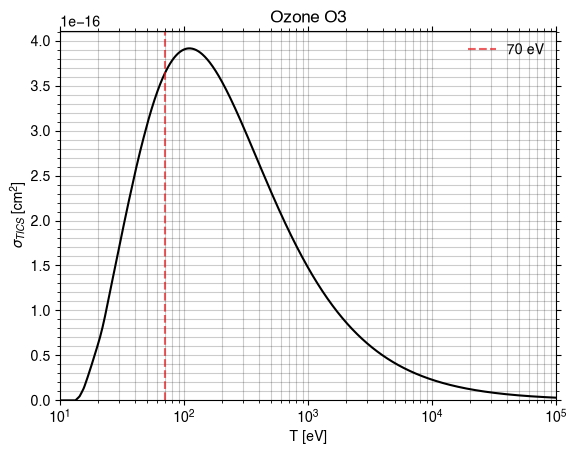

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(1119)
Recherche : 'Sulfur dioxide' -> CID 1119, formule O2S


Loading output/xyz/Sulfur_dioxide_O2S.xyzBuilt graph: 3 atoms, 2 bondsLoading output/xyz/Sulfur_dioxide_O2S.xyzBuilt graph: 3 atoms, 2 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Sulfur_dioxide_O2S.gifGIF written to output/gif/Sulfur_dioxide_O2S.gif

strucutre 3D
Réussite. Nom: Sulfur dioxide, formule: O2S, M: 64.07, nom_marche: Sulfur_dioxide
PYSCF CONVERGENCE
converged SCF energy = -159.657436548925
**** MO energy ****
MO #1   energy= -20.6418010949988  occ= 2
MO #2   energy= -20.6417753984653  occ= 2
MO #3   energy= -1.42975126140102  occ= 2
MO #4   energy= -1.34152511988832  occ= 2
MO #5   energy= -0.906926033978948 occ= 2
MO #6   energy= -0.669571840193126 occ= 2
MO #7   energy= -0.659316620519005 occ= 2
MO #8   energy= -0.619329393680698 occ= 2
MO #9   energy= -0.525732230411666 occ= 2
MO #10  energy= -0.505655152917535 occ= 2
MO #11  energy= -0.486696137479535 occ= 2
MO #12  energy= -0.0444276859392332 occ= 0
MO #13  energy= 0.0656814745836289 occ= 0
MO #14  energy= 0.0694446669772389 occ= 0
MO #15  energy= 0.0909563127685883 occ= 0
MO #16  energy= 0.107756113638956  occ= 0
MO #17  energy= 0.135724471363614  occ= 0
MO #18  energy= 0.144101666469797  occ= 0
MO #19  energy= 0.152586831509006  occ= 0
MO #20  energy= 0.157877964

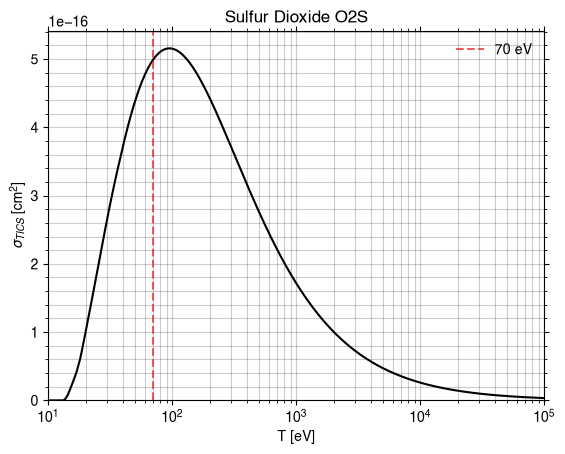

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

c-Silicon dicarbide not found : IndexError : list index out of range
c-Silicon dicarbide a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(139230)
Recherche : 'Disilicon carbide' -> CID 139230, formule CH4Si2


Loading output/xyz/Disilicon_carbide_CH4Si2.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Disilicon_carbide_CH4Si2.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Disilicon_carbide_CH4Si2.gifGIF written to output/gif/Disilicon_carbide_CH4Si2.gif

strucutre 3D
Réussite. Nom: Disilicon carbide, formule: CH4Si2, M: 72.21, nom_marche: Disilicon_carbide
PYSCF CONVERGENCE
converged SCF energy = -47.5101997029596
**** MO energy ****
MO #1   energy= -11.1564910374582  occ= 2
MO #2   energy= -0.865040305658063 occ= 2
MO #3   energy= -0.709498364092436 occ= 2
MO #4   energy= -0.598346249131243 occ= 2
MO #5   energy= -0.503091979735151 occ= 2
MO #6   energy= -0.482177529204185 occ= 2
MO #7   energy= -0.468652285119985 occ= 2
MO #8   energy= -0.316747737559208 occ= 2
MO #9   energy= -0.278442373829737 occ= 2
MO #10  energy= -0.0428134094370378 occ= 0
MO #11  energy= 0.0409305570286732 occ= 0
MO #12  energy= 0.0454401783132449 occ= 0
MO #13  energy= 0.0519193242460108 occ= 0
MO #14  energy= 0.0582738046141987 occ= 0
MO #15  energy= 0.0720611241653488 occ= 0
MO #16  energy= 0.077356340173367  occ= 0
MO #17  energy= 0.0788454951998737 occ= 0
MO #18  energy= 0.0888765670767062 occ= 0
MO #19  energy= 0.130604729925566  occ= 0
MO #20  energy= 0.

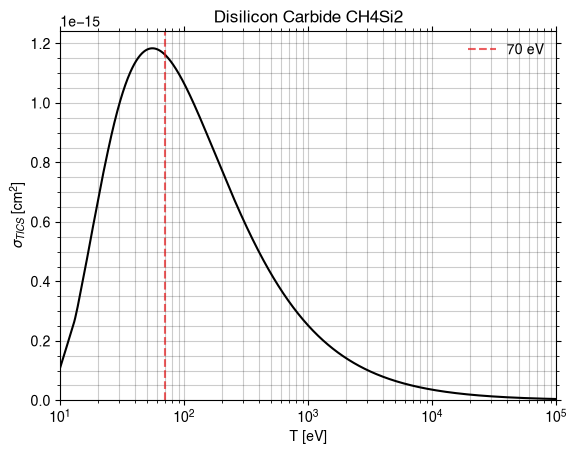

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(143780)
Recherche : 'Tricarbon monoxide' -> CID 143780, formule C3H2O


Loading output/xyz/Tricarbon_monoxide_C3H2O.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Tricarbon_monoxide_C3H2O.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Tricarbon_monoxide_C3H2O.gifGIF written to output/gif/Tricarbon_monoxide_C3H2O.gif

strucutre 3D
Réussite. Nom: Tricarbon monoxide, formule: C3H2O, M: 54.05, nom_marche: Tricarbon_monoxide
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -189.607511941194
**** MO energy ****
MO #1   energy= -20.5971901247578  occ= 2
MO #2   energy= -11.3505803396968  occ= 2
MO #3   energy= -11.306066335349   occ= 2
MO #4   energy= -11.2318648658239  occ= 2
MO #5   energy= -1.43618487849873  occ= 2
MO #6   energy= -1.11071403182077  occ= 2
MO #7   energy= -0.973821330992422 occ= 2
MO #8   energy= -0.720157670460321 occ= 2
MO #9   energy= -0.693706231733376 occ= 2
MO #10  energy= -0.66669071699798  occ= 2
MO #11  energy= -0.613139033808224 occ= 2
MO #12  energy= -0.598061453758038 occ= 2
MO #13  energy= -0.420898408548261 occ= 2
MO #14  energy= -0.364731841273393 occ= 2
MO #15  energy= 0.0297811049393424 occ= 0
MO #16  energy= 0.0562078273085298 occ= 0
MO #17  energy= 0.08002849965197   occ= 0
MO #

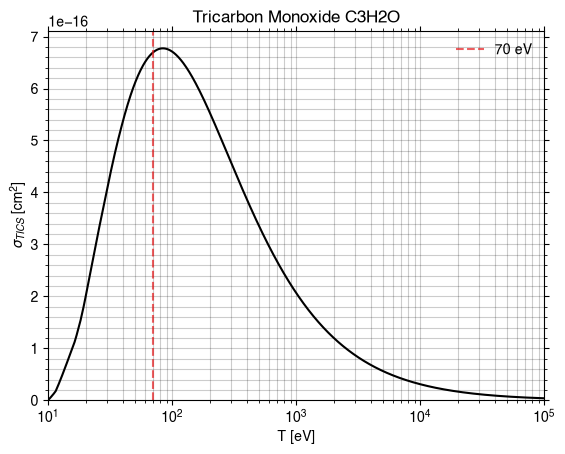

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Tricarbon sulfide not found : IndexError : list index out of range
Tricarbon sulfide a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(712)
Recherche : 'Formaldehyde' -> CID 712, formule CH2O


Loading output/xyz/Formaldehyde_CH2O.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Formaldehyde_CH2O.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Formaldehyde_CH2O.gifGIF written to output/gif/Formaldehyde_CH2O.gif

strucutre 3D
Réussite. Nom: Formaldehyde, formule: CH2O, M: 30.026, nom_marche: Formaldehyde
PYSCF CONVERGENCE
converged SCF energy = -113.915215839878
**** MO energy ****
MO #1   energy= -20.5786370930061  occ= 2
MO #2   energy= -11.3456403565456  occ= 2
MO #3   energy= -1.39419602264996  occ= 2
MO #4   energy= -0.875069732677304 occ= 2
MO #5   energy= -0.690627804944661 occ= 2
MO #6   energy= -0.64853451873331  occ= 2
MO #7   energy= -0.529990422716331 occ= 2
MO #8   energy= -0.446349623848775 occ= 2
MO #9   energy= 0.0651261987420853 occ= 0
MO #10  energy= 0.0907464908739742 occ= 0
MO #11  energy= 0.110686327743914  occ= 0
MO #12  energy= 0.119087110702042  occ= 0
MO #13  energy= 0.134323952608139  occ= 0
MO #14  energy= 0.168971303196073  occ= 0
MO #15  energy= 0.175888443617995  occ= 0
MO #16  energy= 0.187555607700376  occ= 0
MO #17  energy= 0.250632908882626  occ= 0
MO #18  energy= 0.290094820440378  occ= 0
MO #19  energy= 0.303655006035127  occ= 0
MO #20  energy= 0.328157919803

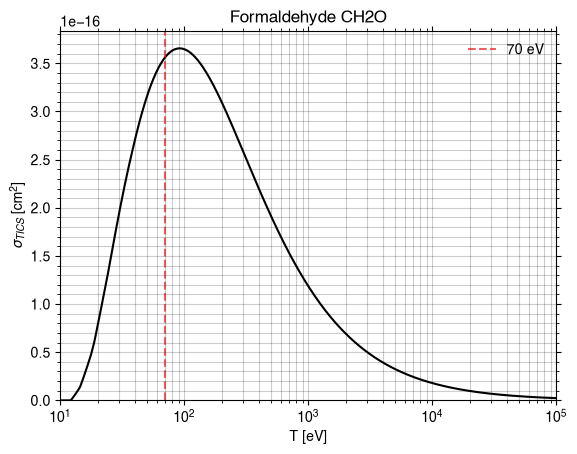

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(79115)
Recherche : 'Thioformaldehyde' -> CID 79115, formule CH2S


Loading output/xyz/Thioformaldehyde_CH2S.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Thioformaldehyde_CH2S.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Thioformaldehyde_CH2S.gifGIF written to output/gif/Thioformaldehyde_CH2S.gif

strucutre 3D
Réussite. Nom: Thioformaldehyde, formule: CH2S, M: 46.09, nom_marche: Thioformaldehyde
PYSCF CONVERGENCE
converged SCF energy = -48.9704451263412
**** MO energy ****
MO #1   energy= -11.3341537963839  occ= 2
MO #2   energy= -1.04886722669604  occ= 2
MO #3   energy= -0.81956092193716  occ= 2
MO #4   energy= -0.637702225560805 occ= 2
MO #5   energy= -0.537087376602134 occ= 2
MO #6   energy= -0.407311619306999 occ= 2
MO #7   energy= -0.353082696963959 occ= 2
MO #8   energy= 0.0324494392159558 occ= 0
MO #9   energy= 0.0709656766792585 occ= 0
MO #10  energy= 0.0904942102143757 occ= 0
MO #11  energy= 0.0986776689527026 occ= 0
MO #12  energy= 0.109723824885436  occ= 0
MO #13  energy= 0.172327792336426  occ= 0
MO #14  energy= 0.175442616658665  occ= 0
MO #15  energy= 0.188454825132875  occ= 0
MO #16  energy= 0.235482450747691  occ= 0
MO #17  energy= 0.245022941905608  occ= 0
MO #18  energy= 0.261211021190718  occ= 0
MO #19  energy= 0.283810898064754  occ= 0
MO #20  energy= 0.30571

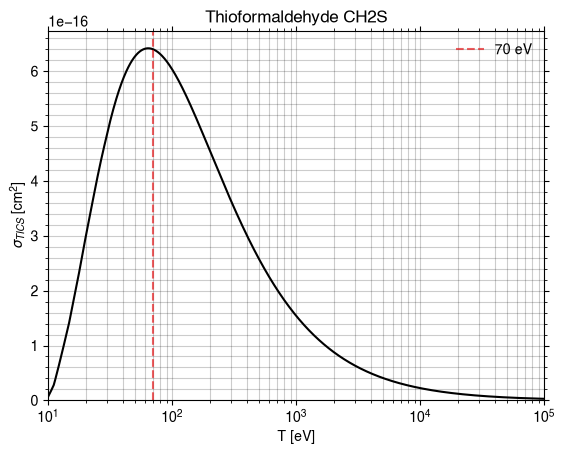

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(521293)
Recherche : 'Fulminic acid' -> CID 521293, formule CHNO


Loading output/xyz/Fulminic_acid_CHNO.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Fulminic_acid_CHNO.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Fulminic_acid_CHNO.gifGIF written to output/gif/Fulminic_acid_CHNO.gif

strucutre 3D
Réussite. Nom: Fulminic acid, formule: CHNO, M: 43.025, nom_marche: Fulminic_acid
PYSCF CONVERGENCE
converged SCF energy = -167.675338465211
**** MO energy ****
MO #1   energy= -20.5672020898458  occ= 2
MO #2   energy= -15.7216010708793  occ= 2
MO #3   energy= -11.3397232464761  occ= 2
MO #4   energy= -1.3840369797215   occ= 2
MO #5   energy= -1.22469940396605  occ= 2
MO #6   energy= -0.843698950033307 occ= 2
MO #7   energy= -0.681652824040139 occ= 2
MO #8   energy= -0.626842684706953 occ= 2
MO #9   energy= -0.626842683722763 occ= 2
MO #10  energy= -0.43108926938982  occ= 2
MO #11  energy= -0.431089269122385 occ= 2
MO #12  energy= 0.046804745454299  occ= 0
MO #13  energy= 0.101129702385677  occ= 0
MO #14  energy= 0.112608593835657  occ= 0
MO #15  energy= 0.112608606019405  occ= 0
MO #16  energy= 0.12214838662383   occ= 0
MO #17  energy= 0.156260996414031  occ= 0
MO #18  energy= 0.156260998508903  occ= 0
MO #19  energy= 0.202369197700929  occ= 0
MO #20  energy= 0.2505790654

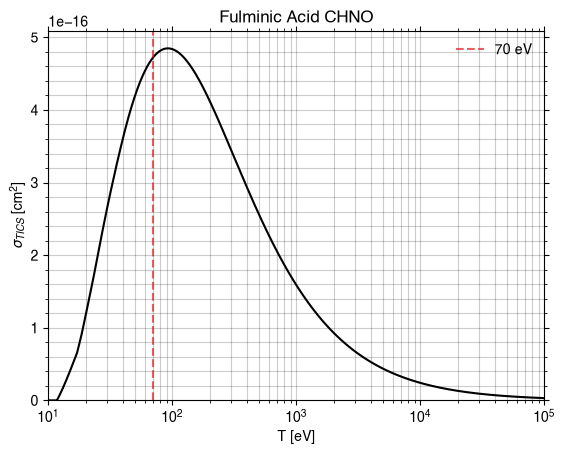

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(540)
Recherche : 'Cyanic acid' -> CID 540, formule CHNO


Loading output/xyz/Cyanic_acid_CHNO.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Cyanic_acid_CHNO.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyanic_acid_CHNO.gifGIF written to output/gif/Cyanic_acid_CHNO.gif

strucutre 3D
Réussite. Nom: Cyanic acid, formule: CHNO, M: 43.025, nom_marche: Cyanic_acid
PYSCF CONVERGENCE
converged SCF energy = -167.795705884055
**** MO energy ****
MO #1   energy= -20.6832104842957  occ= 2
MO #2   energy= -15.5842913570446  occ= 2
MO #3   energy= -11.3513539657423  occ= 2
MO #4   energy= -1.48664825462232  occ= 2
MO #5   energy= -1.22658020984715  occ= 2
MO #6   energy= -0.868385110635835 occ= 2
MO #7   energy= -0.712718693991409 occ= 2
MO #8   energy= -0.664741829212225 occ= 2
MO #9   energy= -0.575432293236563 occ= 2
MO #10  energy= -0.477980525010349 occ= 2
MO #11  energy= -0.462323151969056 occ= 2
MO #12  energy= 0.033513077442958  occ= 0
MO #13  energy= 0.092510919066346  occ= 0
MO #14  energy= 0.101360246173709  occ= 0
MO #15  energy= 0.103857458346382  occ= 0
MO #16  energy= 0.164691634284569  occ= 0
MO #17  energy= 0.181481224607774  occ= 0
MO #18  energy= 0.202284649224716  occ= 0
MO #19  energy= 0.220562521811495  occ= 0
MO #20  energy= 0.22081125792298

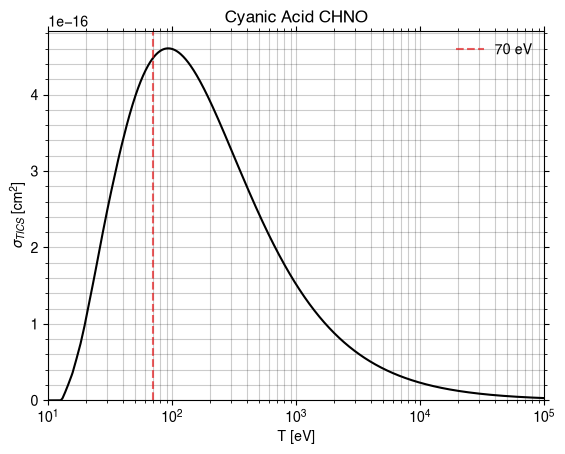

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(18431933)
Recherche : 'Isocyanogen' -> CID 18431933, formule C2N2
3D


  frame 120/120xyz/Isocyanogen_C2N2.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Isocyanogen_C2N2.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/Isocyanogen_C2N2.gifGIF written to output/gif/Isocyanogen_C2N2.gif

strucutre 3D
Réussite. Nom: Isocyanogen, formule: C2N2, M: 52.03, nom_marche: Isocyanogen
PYSCF CONVERGENCE
converged SCF energy = -184.610471591338
**** MO energy ****
MO #1   energy= -15.6867061274746  occ= 2
MO #2   energy= -15.6392269221272  occ= 2
MO #3   energy= -11.3905725418189  occ= 2
MO #4   energy= -11.3603202590771  occ= 2
MO #5   energy= -1.34055218880124  occ= 2
MO #6   energy= -1.26813654429609  occ= 2
MO #7   energy= -0.96451976085924  occ= 2
MO #8   energy= -0.623415927335191 occ= 2
MO #9   energy= -0.623415927335184 occ= 2
MO #10  energy= -0.621078742301719 occ= 2
MO #11  energy= -0.54080642039348  occ= 2
MO #12  energy= -0.502472856799555 occ= 2
MO #13  energy= -0.502472856799549 occ= 2
MO #14  energy= 0.0572522695674317 occ= 0
MO #15  energy= 0.0796670166079397 occ= 0
MO #16  energy= 0.0796670166079822 occ= 0
MO #17  energy= 0.102094080062384  occ= 0
MO #18  energy= 0.151103329242446  occ= 0
MO #19  energy= 0.196734690773275  occ= 0
MO #20  energy= 0.196734690773318

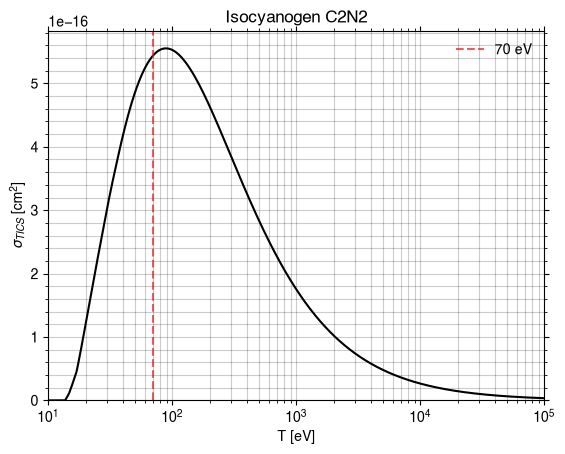

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(784)
Recherche : 'Hydrogen peroxide' -> CID 784, formule H2O2


Loading output/xyz/Hydrogen_peroxide_H2O2.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Hydrogen_peroxide_H2O2.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Hydrogen_peroxide_H2O2.gifGIF written to output/gif/Hydrogen_peroxide_H2O2.gif

strucutre 3D
Réussite. Nom: Hydrogen peroxide, formule: H2O2, M: 34.015, nom_marche: Hydrogen_peroxide
PYSCF CONVERGENCE
converged SCF energy = -150.841041527777
**** MO energy ****
MO #1   energy= -20.6337768210272  occ= 2
MO #2   energy= -20.6334921222135  occ= 2
MO #3   energy= -1.48236774183555  occ= 2
MO #4   energy= -1.20981373594354  occ= 2
MO #5   energy= -0.722981312186855 occ= 2
MO #6   energy= -0.707096059728107 occ= 2
MO #7   energy= -0.607925968819522 occ= 2
MO #8   energy= -0.508249555211882 occ= 2
MO #9   energy= -0.504035919494753 occ= 2
MO #10  energy= 0.0710259572113748 occ= 0
MO #11  energy= 0.0773621512926505 occ= 0
MO #12  energy= 0.103335828294795  occ= 0
MO #13  energy= 0.12071263820086   occ= 0
MO #14  energy= 0.157876044698304  occ= 0
MO #15  energy= 0.158377853393353  occ= 0
MO #16  energy= 0.163182199569466  occ= 0
MO #17  energy= 0.205188283694626  occ= 0
MO #18  energy= 0.235566912089652  occ= 0
MO #19  energy= 0.245131180888566  occ= 0
MO #20  energy= 0.31

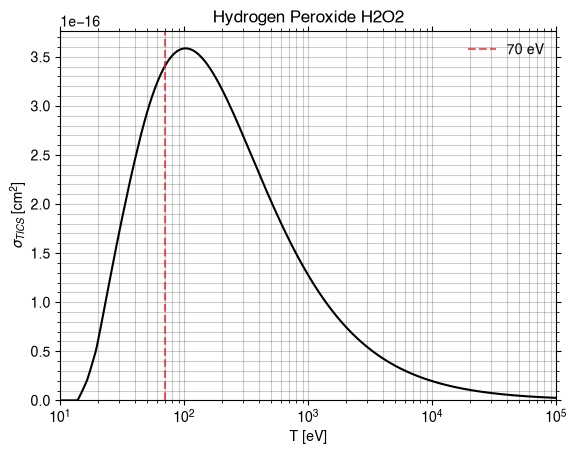

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6347)
Recherche : 'Isocyanic acid' -> CID 6347, formule CHNO


Loading output/xyz/Isocyanic_acid_CHNO.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Isocyanic_acid_CHNO.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Isocyanic_acid_CHNO.gifGIF written to output/gif/Isocyanic_acid_CHNO.gif

strucutre 3D
Réussite. Nom: Isocyanic acid, formule: CHNO, M: 43.025, nom_marche: Isocyanic_acid
PYSCF CONVERGENCE
converged SCF energy = -167.832435590932
**** MO energy ****
MO #1   energy= -20.6186926888653  occ= 2
MO #2   energy= -15.5938712850622  occ= 2
MO #3   energy= -11.4058567266149  occ= 2
MO #4   energy= -1.46784312062506  occ= 2
MO #5   energy= -1.29726810341029  occ= 2
MO #6   energy= -0.797065026859144 occ= 2
MO #7   energy= -0.729253105031336 occ= 2
MO #8   energy= -0.662317064455194 occ= 2
MO #9   energy= -0.647238646913151 occ= 2
MO #10  energy= -0.502916645109252 occ= 2
MO #11  energy= -0.462871167978602 occ= 2
MO #12  energy= 0.0508785499636559 occ= 0
MO #13  energy= 0.095088709550346  occ= 0
MO #14  energy= 0.11527248263159   occ= 0
MO #15  energy= 0.116679252164723  occ= 0
MO #16  energy= 0.140435034231041  occ= 0
MO #17  energy= 0.154623849899542  occ= 0
MO #18  energy= 0.198895331704774  occ= 0
MO #19  energy= 0.205076715981276  occ= 0
MO #20  energy= 0.21832906

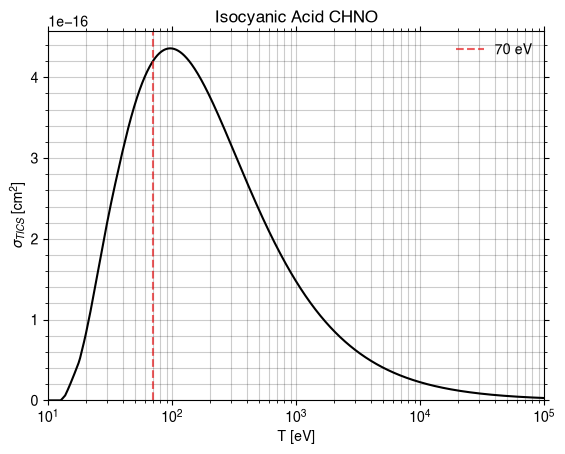

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Isothiocyanic_acid_CHNS.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Isothiocyanic_acid_CHNS.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

Compound(62481)
Recherche : 'Isothiocyanic acid' -> CID 62481, formule CHNS
3D


  frame 120/120
Wrote output/gif/Isothiocyanic_acid_CHNS.gifGIF written to output/gif/Isothiocyanic_acid_CHNS.gif

strucutre 3D
Réussite. Nom: Isothiocyanic acid, formule: CHNS, M: 59.09, nom_marche: Isothiocyanic_acid
PYSCF CONVERGENCE
converged SCF energy = -102.880517685721
**** MO energy ****
MO #1   energy= -15.6073827160818  occ= 2
MO #2   energy= -11.3849154780306  occ= 2
MO #3   energy= -1.31380378307293  occ= 2
MO #4   energy= -1.0486110016335   occ= 2
MO #5   energy= -0.791061648394681 occ= 2
MO #6   energy= -0.622200083118777 occ= 2
MO #7   energy= -0.585871115666879 occ= 2
MO #8   energy= -0.578728961660591 occ= 2
MO #9   energy= -0.398765366751882 occ= 2
MO #10  energy= -0.375666459826299 occ= 2
MO #11  energy= 0.0559024969856158 occ= 0
MO #12  energy= 0.0752248096519263 occ= 0
MO #13  energy= 0.088493434988177  occ= 0
MO #14  energy= 0.0990242003104707 occ= 0
MO #15  energy= 0.114239448380053  occ= 0
MO #16  energy= 0.12642120737551   occ= 0
MO #17  energy= 0.149690894934273  occ= 0
MO #18  energy= 0.18271924772061   occ= 0
MO #19  energy= 0.206172120886473  occ= 0
MO #20  energy= 0.2

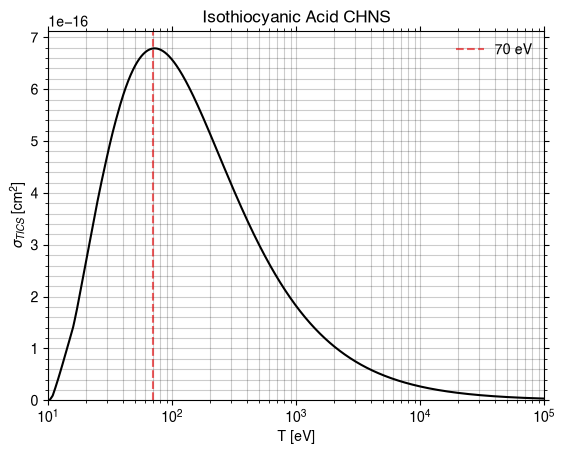

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(222)
Recherche : 'Ammonia' -> CID 222, formule H3N


Loading output/xyz/Ammonia_H3N.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Ammonia_H3N.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ammonia_H3N.gifGIF written to output/gif/Ammonia_H3N.gif

strucutre 3D
Réussite. Nom: Ammonia, formule: H3N, M: 17.031, nom_marche: Ammonia
PYSCF CONVERGENCE
converged SCF energy = -56.221330543828
**** MO energy ****
MO #1   energy= -15.5435285352098  occ= 2
MO #2   energy= -1.13942450598745  occ= 2
MO #3   energy= -0.62459014627038  occ= 2
MO #4   energy= -0.624571385139982 occ= 2
MO #5   energy= -0.431133936443331 occ= 2
MO #6   energy= 0.078921834568483  occ= 0
MO #7   energy= 0.157095487342447  occ= 0
MO #8   energy= 0.157097053550013  occ= 0
MO #9   energy= 0.206444414684518  occ= 0
MO #10  energy= 0.22385485054683   occ= 0
MO #11  energy= 0.223857111014139  occ= 0
MO #12  energy= 0.26276692875327   occ= 0
MO #13  energy= 0.262769414549492  occ= 0
MO #14  energy= 0.265930137497224  occ= 0
MO #15  energy= 0.340965060982927  occ= 0
MO #16  energy= 0.373200177231848  occ= 0
MO #17  energy= 0.405938494946311  occ= 0
MO #18  energy= 0.405940182763152  occ= 0
MO #19  energy= 0.477034609705768  occ= 0
MO #20  energy= 0.477037443695765  occ= 0


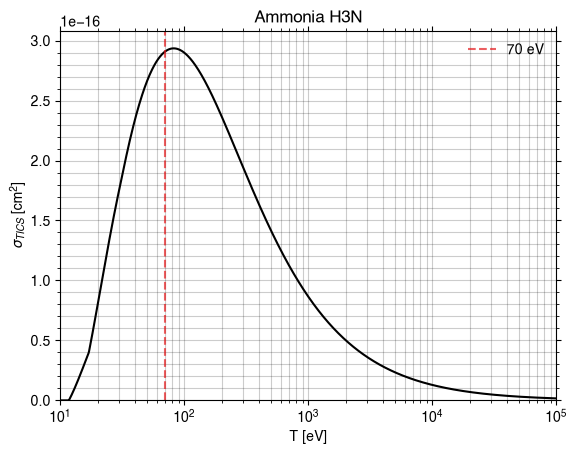

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(781)
Recherche : 'Thiocyanic acid' -> CID 781, formule CHNS


Loading output/xyz/Thiocyanic_acid_CHNS.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Thiocyanic_acid_CHNS.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Thiocyanic_acid_CHNS.gifGIF written to output/gif/Thiocyanic_acid_CHNS.gif

strucutre 3D
Réussite. Nom: Thiocyanic acid, formule: CHNS, M: 59.09, nom_marche: Thiocyanic_acid
PYSCF CONVERGENCE
converged SCF energy = -102.876742168157
**** MO energy ****
MO #1   energy= -15.5942536502362  occ= 2
MO #2   energy= -11.3095338300804  occ= 2
MO #3   energy= -1.2383597990511   occ= 2
MO #4   energy= -1.0746037048449   occ= 2
MO #5   energy= -0.724082487312145 occ= 2
MO #6   energy= -0.596193293948871 occ= 2
MO #7   energy= -0.563495161010297 occ= 2
MO #8   energy= -0.539395123237743 occ= 2
MO #9   energy= -0.475065310572617 occ= 2
MO #10  energy= -0.408058809556323 occ= 2
MO #11  energy= 0.045007129555975  occ= 0
MO #12  energy= 0.0775273086756884 occ= 0
MO #13  energy= 0.0826650738132868 occ= 0
MO #14  energy= 0.0938694185903796 occ= 0
MO #15  energy= 0.112859268414345  occ= 0
MO #16  energy= 0.152687143404887  occ= 0
MO #17  energy= 0.167706125301319  occ= 0
MO #18  energy= 0.175060565720098  occ= 0
MO #19  energy= 0.194641081271987  occ= 0
MO #20  energy= 0.2008687

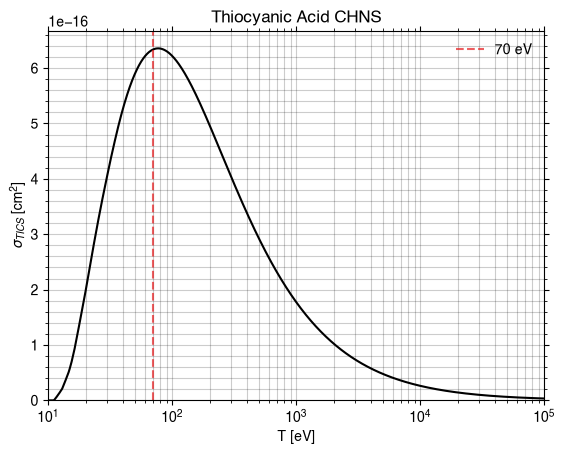

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(139610)
Recherche : 'Thionylimide' -> CID 139610, formule HNOS


Loading output/xyz/Thionylimide_HNOS.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Thionylimide_HNOS.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Thionylimide_HNOS.gifGIF written to output/gif/Thionylimide_HNOS.gif

strucutre 3D
Réussite. Nom: Thionylimide, formule: HNOS, M: 63.08, nom_marche: Thionylimide
PYSCF CONVERGENCE
converged SCF energy = -139.846331598796
**** MO energy ****
MO #1   energy= -20.5816565724541  occ= 2
MO #2   energy= -15.6199735221281  occ= 2
MO #3   energy= -1.40670962519557  occ= 2
MO #4   energy= -1.23901580833262  occ= 2
MO #5   energy= -0.863589484445761 occ= 2
MO #6   energy= -0.707688144643512 occ= 2
MO #7   energy= -0.628501779336451 occ= 2
MO #8   energy= -0.605708269428223 occ= 2
MO #9   energy= -0.515161254140736 occ= 2
MO #10  energy= -0.449980611562437 occ= 2
MO #11  energy= -0.443841927924597 occ= 2
MO #12  energy= 0.0221998750654362 occ= 0
MO #13  energy= 0.0610348749401216 occ= 0
MO #14  energy= 0.0780243850901736 occ= 0
MO #15  energy= 0.0961160861006304 occ= 0
MO #16  energy= 0.104216705748821  occ= 0
MO #17  energy= 0.150077995123246  occ= 0
MO #18  energy= 0.160157104958652  occ= 0
MO #19  energy= 0.166030268271409  occ= 0
MO #20  energy= 0.1925362992686

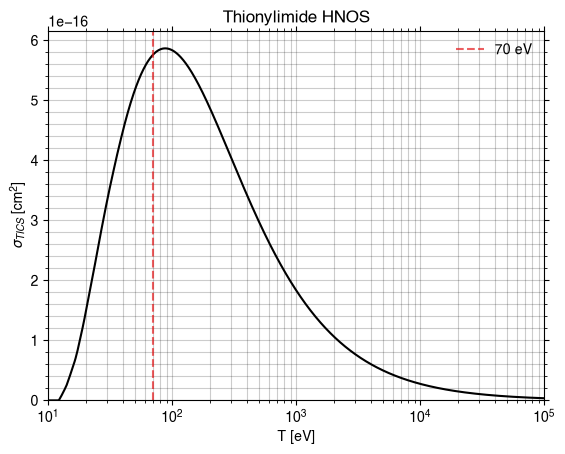

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Silicon tricarbide not found : IndexError : list index out of range
Silicon tricarbide a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(24529)
Recherche : 'Nitrous acid' -> CID 24529, formule HNO2


Loading output/xyz/Nitrous_acid_HNO2.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Nitrous_acid_HNO2.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Nitrous_acid_HNO2.gifGIF written to output/gif/Nitrous_acid_HNO2.gif

strucutre 3D
Réussite. Nom: Nitrous acid, formule: HNO2, M: 47.014, nom_marche: Nitrous_acid
PYSCF CONVERGENCE
converged SCF energy = -204.678901926435
**** MO energy ****
MO #1   energy= -20.6749668509634  occ= 2
MO #2   energy= -20.6571785883748  occ= 2
MO #3   energy= -15.8195512210026  occ= 2
MO #4   energy= -1.51993979028553  occ= 2
MO #5   energy= -1.37981710335227  occ= 2
MO #6   energy= -0.976910392175284 occ= 2
MO #7   energy= -0.770324476037459 occ= 2
MO #8   energy= -0.701571383536731 occ= 2
MO #9   energy= -0.652901835223048 occ= 2
MO #10  energy= -0.599134430735504 occ= 2
MO #11  energy= -0.505526905535748 occ= 2
MO #12  energy= -0.486626343943209 occ= 2
MO #13  energy= 0.0393827858978567 occ= 0
MO #14  energy= 0.0590889225309964 occ= 0
MO #15  energy= 0.101962835640741  occ= 0
MO #16  energy= 0.106429456262359  occ= 0
MO #17  energy= 0.121464837756207  occ= 0
MO #18  energy= 0.154434265698278  occ= 0
MO #19  energy= 0.161438171993457  occ= 0
MO #20  energy= 0.162009977724

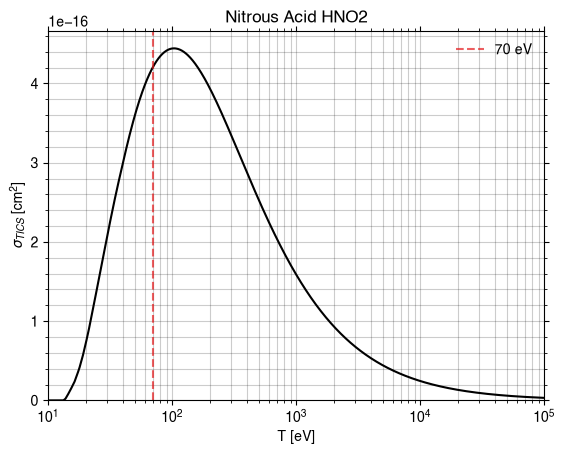

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(123173)
Recherche : 'Cyclopropenylidene' -> CID 123173, formule C3H4


Loading output/xyz/Cyclopropenylidene_C3H4.xyzBuilt graph: 7 atoms, 7 bondsLoading output/xyz/Cyclopropenylidene_C3H4.xyzBuilt graph: 7 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyclopropenylidene_C3H4.gifGIF written to output/gif/Cyclopropenylidene_C3H4.gif

strucutre 3D
Réussite. Nom: Cyclopropenylidene, formule: C3H4, M: 40.06, nom_marche: Cyclopropenylidene
PYSCF CONVERGENCE
converged SCF energy = -115.861407425439
**** MO energy ****
MO #1   energy= -11.2343751731376  occ= 2
MO #2   energy= -11.2322233340695  occ= 2
MO #3   energy= -11.2257150739972  occ= 2
MO #4   energy= -1.18784276092658  occ= 2
MO #5   energy= -0.817238305495145 occ= 2
MO #6   energy= -0.775251000828955 occ= 2
MO #7   energy= -0.687718990254726 occ= 2
MO #8   energy= -0.617661922527773 occ= 2
MO #9   energy= -0.480988547426612 occ= 2
MO #10  energy= -0.450528492861153 occ= 2
MO #11  energy= -0.344756491516986 occ= 2
MO #12  energy= 0.0770243365764396 occ= 0
MO #13  energy= 0.0932249739526362 occ= 0
MO #14  energy= 0.0980713362269734 occ= 0
MO #15  energy= 0.12819357485191   occ= 0
MO #16  energy= 0.161288766093227  occ= 0
MO #17  energy= 0.168872142192389  occ= 0
MO #18  energy= 0.179176438959129  occ= 0
MO #19  energy= 0.203106933786451  occ= 0
MO #20  energy= 0.2

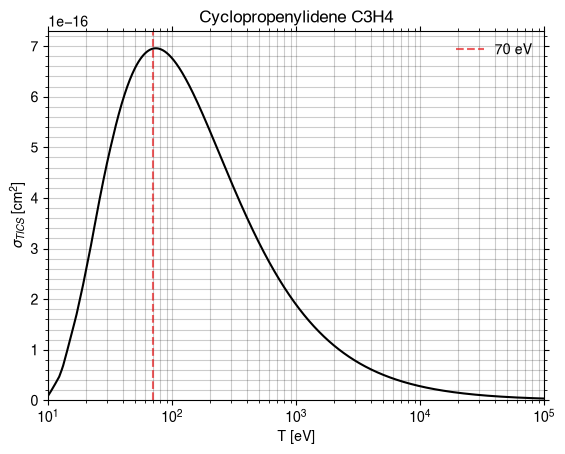

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Propadienylidene not found : IndexError : list index out of range
Propadienylidene a échoué : TypeError : cannot unpack non-iterable NoneType object


Loading output/xyz/Ketene_C2H2O.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Ketene_C2H2O.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

Compound(10038)
Recherche : 'Ketene' -> CID 10038, formule C2H2O
3D


  frame 120/120
Wrote output/gif/Ketene_C2H2O.gifGIF written to output/gif/Ketene_C2H2O.gif

strucutre 3D
Réussite. Nom: Ketene, formule: C2H2O, M: 42.04, nom_marche: Ketene
PYSCF CONVERGENCE
converged SCF energy = -151.789182848791
**** MO energy ****
MO #1   energy= -20.6256941729082  occ= 2
MO #2   energy= -11.3836417169219  occ= 2
MO #3   energy= -11.2419781469396  occ= 2
MO #4   energy= -1.46182764794222  occ= 2
MO #5   energy= -1.06048262055594  occ= 2
MO #6   energy= -0.757238290931369 occ= 2
MO #7   energy= -0.68472200839426  occ= 2
MO #8   energy= -0.653788102394663 occ= 2
MO #9   energy= -0.638233384366827 occ= 2
MO #10  energy= -0.555898311936268 occ= 2
MO #11  energy= -0.372555250118907 occ= 2
MO #12  energy= 0.0587051543860611 occ= 0
MO #13  energy= 0.08786730686118   occ= 0
MO #14  energy= 0.105002867956162  occ= 0
MO #15  energy= 0.115499807882323  occ= 0
MO #16  energy= 0.116540740757679  occ= 0
MO #17  energy= 0.13050706783684   occ= 0
MO #18  energy= 0.172666502604223  occ= 0
MO #19  energy= 0.177372831580192  occ= 0
MO #20  energy= 0.185041970079312  occ= 0


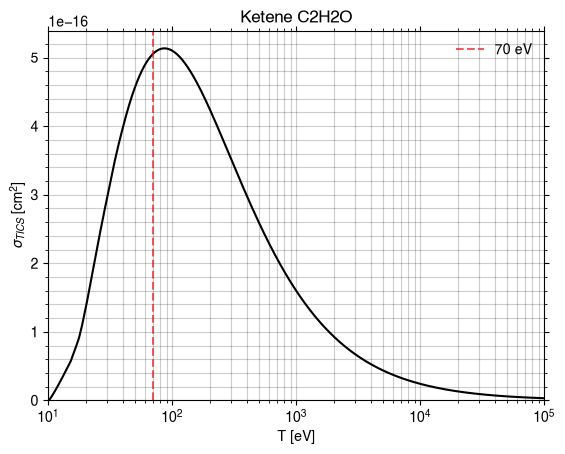

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Methylenimine not found : IndexError : list index out of range
Methylenimine a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(160435)
Recherche : 'Carbodiimide' -> CID 160435, formule CH2N2


Loading output/xyz/Carbodiimide_CH2N2.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Carbodiimide_CH2N2.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Carbodiimide_CH2N2.gifGIF written to output/gif/Carbodiimide_CH2N2.gif

strucutre 3D
Réussite. Nom: Carbodiimide, formule: CH2N2, M: 42.04, nom_marche: Carbodiimide
PYSCF CONVERGENCE
converged SCF energy = -147.935882749909
**** MO energy ****
MO #1   energy= -15.5601363004763  occ= 2
MO #2   energy= -15.560085355654   occ= 2
MO #3   energy= -11.358730475463   occ= 2
MO #4   energy= -1.31841210787873  occ= 2
MO #5   energy= -1.22897966596469  occ= 2
MO #6   energy= -0.78625896543619  occ= 2
MO #7   energy= -0.723500430962766 occ= 2
MO #8   energy= -0.606713801148203 occ= 2
MO #9   energy= -0.603782799166021 occ= 2
MO #10  energy= -0.466678108403372 occ= 2
MO #11  energy= -0.39017106998223  occ= 2
MO #12  energy= 0.0564663047646405 occ= 0
MO #13  energy= 0.105961798217831  occ= 0
MO #14  energy= 0.118263318981187  occ= 0
MO #15  energy= 0.160756325690628  occ= 0
MO #16  energy= 0.177692402144095  occ= 0
MO #17  energy= 0.181222392245973  occ= 0
MO #18  energy= 0.197572179170734  occ= 0
MO #19  energy= 0.240737152531936  occ= 0
MO #20  energy= 0.240740045697

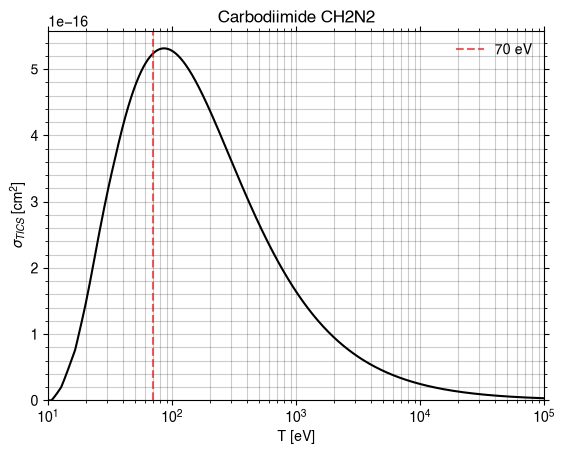

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(15265722)
Recherche : 'Isocyanoacetylene' -> CID 15265722, formule C3HN


Loading output/xyz/Isocyanoacetylene_C3HN.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Isocyanoacetylene_C3HN.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Isocyanoacetylene_C3HN.gifGIF written to output/gif/Isocyanoacetylene_C3HN.gif

strucutre 3D
Réussite. Nom: Isocyanoacetylene, formule: C3HN, M: 51.05, nom_marche: Isocyanoacetylene
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -168.561989810332
**** MO energy ****
MO #1   energy= -15.6496296421354  occ= 2
MO #2   energy= -11.3362813734295  occ= 2
MO #3   energy= -11.317957061636   occ= 2
MO #4   energy= -11.2817506112267  occ= 2
MO #5   energy= -1.29704087914239  occ= 2
MO #6   energy= -1.0785235178031   occ= 2
MO #7   energy= -0.900293318014619 occ= 2
MO #8   energy= -0.745423592414859 occ= 2
MO #9   energy= -0.578362481747548 occ= 2
MO #10  energy= -0.578362470222238 occ= 2
MO #11  energy= -0.507161480834242 occ= 2
MO #12  energy= -0.428967170738593 occ= 2
MO #13  energy= -0.428967167942588 occ= 2
MO #14  energy= 0.060615158951419  occ= 0
MO #15  energy= 0.0854416880291417 occ= 0
MO #16  energy= 0.103088408501721  occ= 0
MO #17  energy= 0.103088436911294  occ= 0
MO #18 

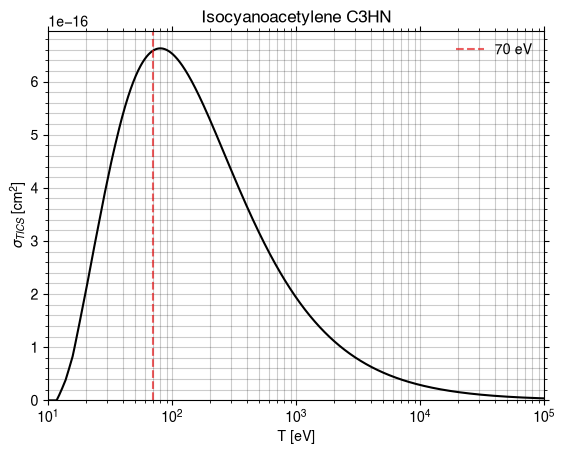

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(284)
Recherche : 'Formic acid' -> CID 284, formule CH2O2


Loading output/xyz/Formic_acid_CH2O2.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Formic_acid_CH2O2.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Formic_acid_CH2O2.gifGIF written to output/gif/Formic_acid_CH2O2.gif

strucutre 3D
Réussite. Nom: Formic acid, formule: CH2O2, M: 46.025, nom_marche: Formic_acid
PYSCF CONVERGENCE
converged SCF energy = -188.847089508348
**** MO energy ****
MO #1   energy= -20.6286019782639  occ= 2
MO #2   energy= -20.5660032729516  occ= 2
MO #3   energy= -11.4019872239781  occ= 2
MO #4   energy= -1.46649946464146  occ= 2
MO #5   energy= -1.36785603665888  occ= 2
MO #6   energy= -0.899710664729874 occ= 2
MO #7   energy= -0.724456578616657 occ= 2
MO #8   energy= -0.708395791322122 occ= 2
MO #9   energy= -0.63338454296343  occ= 2
MO #10  energy= -0.598070920259392 occ= 2
MO #11  energy= -0.49317373866768  occ= 2
MO #12  energy= -0.473881761403253 occ= 2
MO #13  energy= 0.0556927745166256 occ= 0
MO #14  energy= 0.0823256805396683 occ= 0
MO #15  energy= 0.0976832721910084 occ= 0
MO #16  energy= 0.10458684539989   occ= 0
MO #17  energy= 0.136843760821091  occ= 0
MO #18  energy= 0.138280871322167  occ= 0
MO #19  energy= 0.142546880142044  occ= 0
MO #20  energy= 0.1534613443027

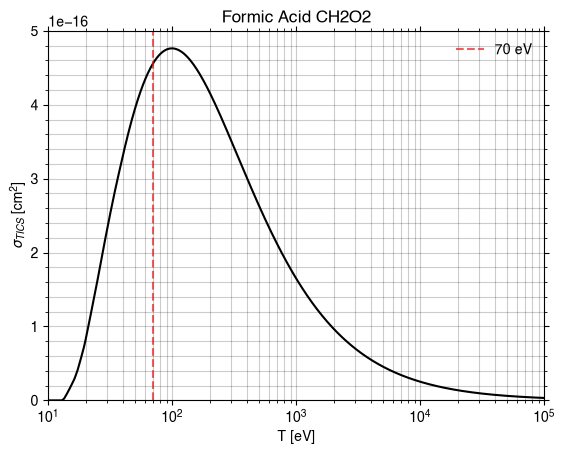

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(9864)
Recherche : 'Cyanamide' -> CID 9864, formule CH2N2


Loading output/xyz/Cyanamide_CH2N2.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Cyanamide_CH2N2.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyanamide_CH2N2.gifGIF written to output/gif/Cyanamide_CH2N2.gif

strucutre 3D
Réussite. Nom: Cyanamide, formule: CH2N2, M: 42.04, nom_marche: Cyanamide
PYSCF CONVERGENCE
converged SCF energy = -147.969106778648
**** MO energy ****
MO #1   energy= -15.6322758252927  occ= 2
MO #2   energy= -15.561647319453   occ= 2
MO #3   energy= -11.3091382144518  occ= 2
MO #4   energy= -1.27276234312696  occ= 2
MO #5   energy= -1.18578582741131  occ= 2
MO #6   energy= -0.809558466444976 occ= 2
MO #7   energy= -0.733508550150987 occ= 2
MO #8   energy= -0.571677664015274 occ= 2
MO #9   energy= -0.555664286637328 occ= 2
MO #10  energy= -0.463707287783926 occ= 2
MO #11  energy= -0.409316272282908 occ= 2
MO #12  energy= 0.0498510583143954 occ= 0
MO #13  energy= 0.103247949130694  occ= 0
MO #14  energy= 0.123968559503877  occ= 0
MO #15  energy= 0.178841819783314  occ= 0
MO #16  energy= 0.183472670118362  occ= 0
MO #17  energy= 0.185381353162678  occ= 0
MO #18  energy= 0.192100161551249  occ= 0
MO #19  energy= 0.213008814992261  occ= 0
MO #20  energy= 0.233196463434635  o

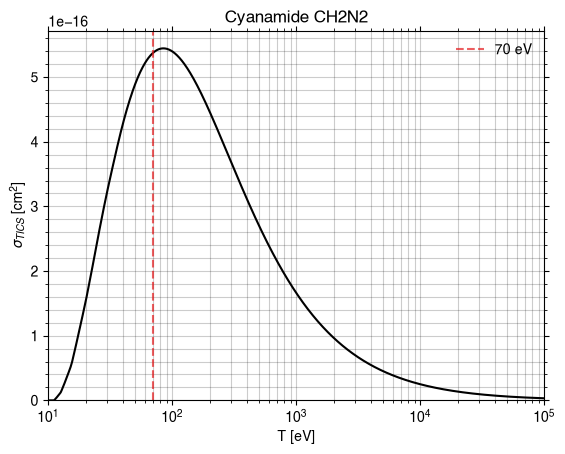

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(787)
Recherche : 'Hydroxylamine' -> CID 787, formule H3NO


Loading output/xyz/Hydroxylamine_H3NO.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Hydroxylamine_H3NO.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Hydroxylamine_H3NO.gifGIF written to output/gif/Hydroxylamine_H3NO.gif

strucutre 3D
Réussite. Nom: Hydroxylamine, formule: H3NO, M: 33.03, nom_marche: Hydroxylamine
PYSCF CONVERGENCE
converged SCF energy = -131.04667483982
**** MO energy ****
MO #1   energy= -20.5869787308771  occ= 2
MO #2   energy= -15.6095189388409  occ= 2
MO #3   energy= -1.39245241846856  occ= 2
MO #4   energy= -1.07911918724388  occ= 2
MO #5   energy= -0.692908688974658 occ= 2
MO #6   energy= -0.671572232053848 occ= 2
MO #7   energy= -0.609356192060709 occ= 2
MO #8   energy= -0.48331296706391  occ= 2
MO #9   energy= -0.436641121225335 occ= 2
MO #10  energy= 0.0808629206901382 occ= 0
MO #11  energy= 0.0925515271424522 occ= 0
MO #12  energy= 0.116801629493394  occ= 0
MO #13  energy= 0.118131112063211  occ= 0
MO #14  energy= 0.17548756571068   occ= 0
MO #15  energy= 0.196629784326616  occ= 0
MO #16  energy= 0.212314239421891  occ= 0
MO #17  energy= 0.236333276146499  occ= 0
MO #18  energy= 0.247256246700115  occ= 0
MO #19  energy= 0.297852009940813  occ= 0
MO #20  energy= 0.310314039053

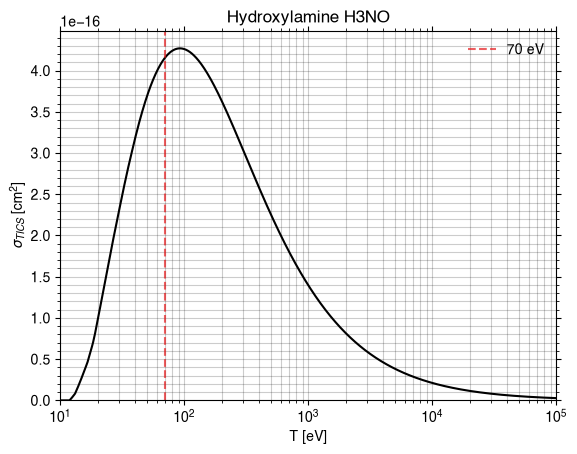

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(3843063)
Recherche : 'Cyanoformaldehyde' -> CID 3843063, formule C2HNO


Loading output/xyz/Cyanoformaldehyde_C2HNO.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Cyanoformaldehyde_C2HNO.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyanoformaldehyde_C2HNO.gifGIF written to output/gif/Cyanoformaldehyde_C2HNO.gif

strucutre 3D
Réussite. Nom: Cyanoformaldehyde, formule: C2HNO, M: 55.04, nom_marche: Cyanoformaldehyde
PYSCF CONVERGENCE
converged SCF energy = -205.667495907256
**** MO energy ****
MO #1   energy= -20.6254784088805  occ= 2
MO #2   energy= -15.6284185904076  occ= 2
MO #3   energy= -11.4105610009554  occ= 2
MO #4   energy= -11.3123374887494  occ= 2
MO #5   energy= -1.44758880445365  occ= 2
MO #6   energy= -1.25944477720865  occ= 2
MO #7   energy= -0.992342177909222 occ= 2
MO #8   energy= -0.783717416635376 occ= 2
MO #9   energy= -0.706889547365325 occ= 2
MO #10  energy= -0.610772815099952 occ= 2
MO #11  energy= -0.602117575431291 occ= 2
MO #12  energy= -0.514171571714459 occ= 2
MO #13  energy= -0.507185122304312 occ= 2
MO #14  energy= -0.497825377475035 occ= 2
MO #15  energy= 0.0277368641812323 occ= 0
MO #16  energy= 0.0528025295110162 occ= 0
MO #17  energy= 0.0910995124426656 occ= 0
MO #18  energy= 0.102434557454787  occ= 0
MO #19  energy= 0.113195716836631  occ= 0
MO #20  energy= 0.14

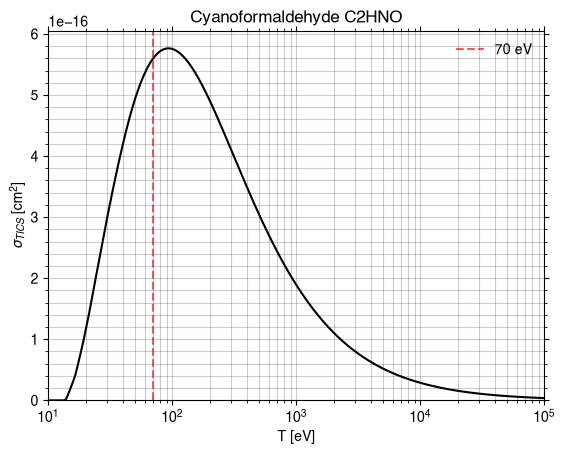

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(416793)
Recherche : 'dithioformic acid' -> CID 416793, formule CH2S2


Loading output/xyz/dithioformic_acid_CH2S2.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/dithioformic_acid_CH2S2.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/dithioformic_acid_CH2S2.gifGIF written to output/gif/dithioformic_acid_CH2S2.gif

strucutre 3D
Réussite. Nom: dithioformic acid, formule: CH2S2, M: 78.16, nom_marche: dithioformic_acid
PYSCF CONVERGENCE
converged SCF energy = -58.9477377651892
**** MO energy ****
MO #1   energy= -11.3678810377157  occ= 2
MO #2   energy= -1.11132116931183  occ= 2
MO #3   energy= -0.971748610785077 occ= 2
MO #4   energy= -0.803161524126896 occ= 2
MO #5   energy= -0.610237523866456 occ= 2
MO #6   energy= -0.584363133154834 occ= 2
MO #7   energy= -0.500271814522304 occ= 2
MO #8   energy= -0.478843158089682 occ= 2
MO #9   energy= -0.358076655710655 occ= 2
MO #10  energy= -0.349240866757495 occ= 2
MO #11  energy= 0.0337489099510577 occ= 0
MO #12  energy= 0.0640302389245404 occ= 0
MO #13  energy= 0.0691561351814911 occ= 0
MO #14  energy= 0.0843850168399237 occ= 0
MO #15  energy= 0.100142707271671  occ= 0
MO #16  energy= 0.100526030045245  occ= 0
MO #17  energy= 0.109777396356156  occ= 0
MO #18  energy= 0.129106187496306  occ= 0
MO #19  energy= 0.14689804689301   occ= 0
MO #20  energy= 0.17

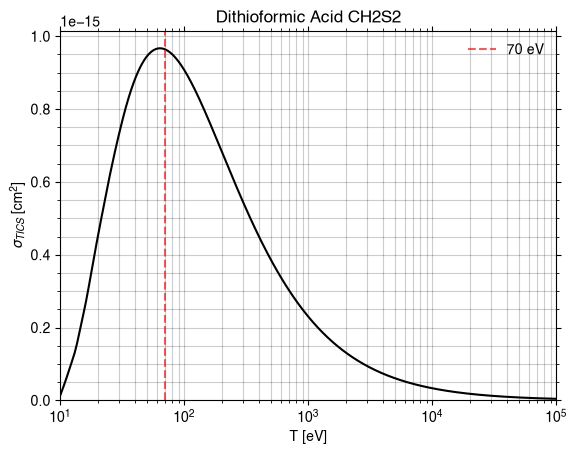

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(137779)
Recherche : 'Cyclopropenone' -> CID 137779, formule C3H2O


Loading output/xyz/Cyclopropenone_C3H2O.xyzBuilt graph: 6 atoms, 6 bondsLoading output/xyz/Cyclopropenone_C3H2O.xyzBuilt graph: 6 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyclopropenone_C3H2O.gifGIF written to output/gif/Cyclopropenone_C3H2O.gif

strucutre 3D
Réussite. Nom: Cyclopropenone, formule: C3H2O, M: 54.05, nom_marche: Cyclopropenone
PYSCF CONVERGENCE
converged SCF energy = -189.611621688959
**** MO energy ****
MO #1   energy= -20.5253161470072  occ= 2
MO #2   energy= -11.3438139842737  occ= 2
MO #3   energy= -11.2882316197957  occ= 2
MO #4   energy= -11.2864469823422  occ= 2
MO #5   energy= -1.3995684243843   occ= 2
MO #6   energy= -1.22516549214867  occ= 2
MO #7   energy= -0.829444578724736 occ= 2
MO #8   energy= -0.795634231697015 occ= 2
MO #9   energy= -0.679544755493435 occ= 2
MO #10  energy= -0.616218263177771 occ= 2
MO #11  energy= -0.593307584721845 occ= 2
MO #12  energy= -0.564623481610504 occ= 2
MO #13  energy= -0.423968721483366 occ= 2
MO #14  energy= -0.387493819688608 occ= 2
MO #15  energy= 0.0600205549477941 occ= 0
MO #16  energy= 0.0834882136758391 occ= 0
MO #17  energy= 0.0860168594735556 occ= 0
MO #18  energy= 0.095494886347379  occ= 0
MO #19  energy= 0.120987450557652  occ= 0
MO #20  energy= 0.13777868

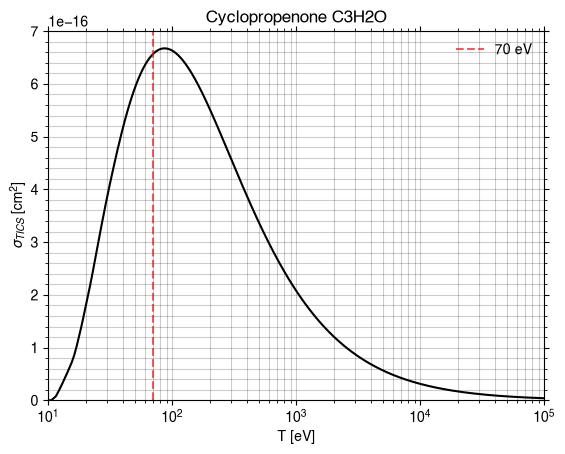

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

E-Cyanomethanimine not found : IndexError : list index out of range
E-Cyanomethanimine a échoué : TypeError : cannot unpack non-iterable NoneType object


Loading output/xyz/Acetonitrile_C2H3N.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Acetonitrile_C2H3N.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

Compound(6342)
Recherche : 'Acetonitrile' -> CID 6342, formule C2H3N
3D


  frame 120/120
Wrote output/gif/Acetonitrile_C2H3N.gifGIF written to output/gif/Acetonitrile_C2H3N.gif

strucutre 3D
Réussite. Nom: Acetonitrile, formule: C2H3N, M: 41.05, nom_marche: Acetonitrile
PYSCF CONVERGENCE
converged SCF energy = -131.976970368576
**** MO energy ****
MO #1   energy= -15.5730270898305  occ= 2
MO #2   energy= -11.2871957389047  occ= 2
MO #3   energy= -11.2804834974607  occ= 2
MO #4   energy= -1.21811248433551  occ= 2
MO #5   energy= -1.03951548461959  occ= 2
MO #6   energy= -0.702036770963296 occ= 2
MO #7   energy= -0.627866271980272 occ= 2
MO #8   energy= -0.62785015540445  occ= 2
MO #9   energy= -0.556935837820319 occ= 2
MO #10  energy= -0.461252053904512 occ= 2
MO #11  energy= -0.461249437081469 occ= 2
MO #12  energy= 0.057416119512709  occ= 0
MO #13  energy= 0.0974409944617847 occ= 0
MO #14  energy= 0.13678761832585   occ= 0
MO #15  energy= 0.136790016403635  occ= 0
MO #16  energy= 0.174903440211894  occ= 0
MO #17  energy= 0.174905153694829  occ= 0
MO #18  energy= 0.175347673114935  occ= 0
MO #19  energy= 0.198910513262857  occ= 0
MO #20  energy= 0.198914842782

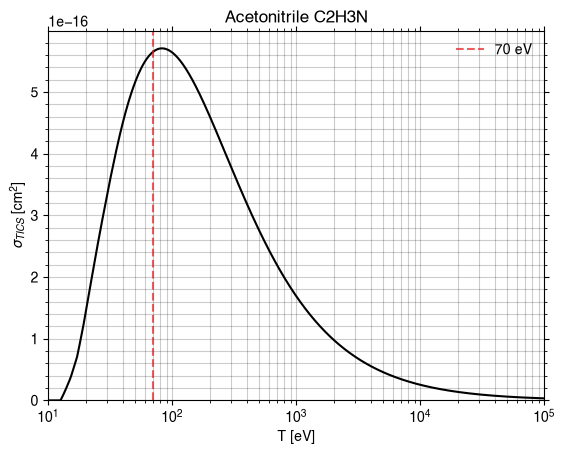

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(11646)
Recherche : 'Methyl isocyanide' -> CID 11646, formule C2H3N


Loading output/xyz/Methyl_isocyanide_C2H3N.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Methyl_isocyanide_C2H3N.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methyl_isocyanide_C2H3N.gifGIF written to output/gif/Methyl_isocyanide_C2H3N.gif

strucutre 3D
Réussite. Nom: Methyl isocyanide, formule: C2H3N, M: 41.05, nom_marche: Methyl_isocyanide
PYSCF CONVERGENCE
converged SCF energy = -131.945989489462
**** MO energy ****
MO #1   energy= -15.596653006253   occ= 2
MO #2   energy= -11.3039440764986  occ= 2
MO #3   energy= -11.275361114281   occ= 2
MO #4   energy= -1.26832118516755  occ= 2
MO #5   energy= -1.02568831103163  occ= 2
MO #6   energy= -0.740060145378756 occ= 2
MO #7   energy= -0.641568920294451 occ= 2
MO #8   energy= -0.641565014346451 occ= 2
MO #9   energy= -0.473718959573199 occ= 2
MO #10  energy= -0.472067829218629 occ= 2
MO #11  energy= -0.472063807477608 occ= 2
MO #12  energy= 0.0607526473456232 occ= 0
MO #13  energy= 0.114991360524061  occ= 0
MO #14  energy= 0.136214488666027  occ= 0
MO #15  energy= 0.136216079042281  occ= 0
MO #16  energy= 0.148028471520367  occ= 0
MO #17  energy= 0.184172893216482  occ= 0
MO #18  energy= 0.184183573093342  occ= 0
MO #19  energy= 0.184934558232444  occ= 0
MO #20  energy= 0.18

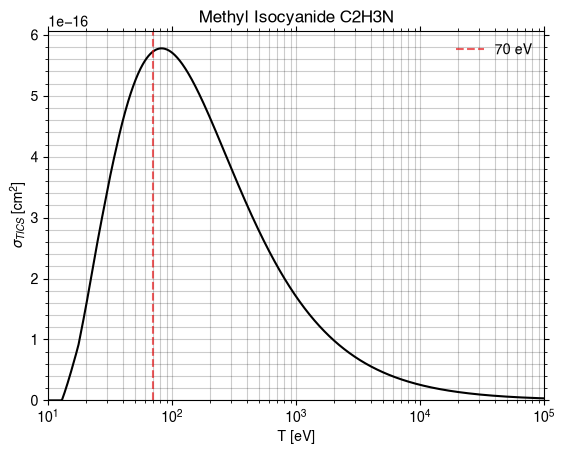

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(887)
Recherche : 'Methanol' -> CID 887, formule CH4O


Loading output/xyz/Methanol_CH4O.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Methanol_CH4O.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methanol_CH4O.gifGIF written to output/gif/Methanol_CH4O.gif

strucutre 3D
Réussite. Nom: Methanol, formule: CH4O, M: 32.042, nom_marche: Methanol
PYSCF CONVERGENCE
converged SCF energy = -115.0947411595
**** MO energy ****
MO #1   energy= -20.5567154612207  occ= 2
MO #2   energy= -11.2704016642334  occ= 2
MO #3   energy= -1.35584850854455  occ= 2
MO #4   energy= -0.922160663522664 occ= 2
MO #5   energy= -0.687516028283355 occ= 2
MO #6   energy= -0.623815301747122 occ= 2
MO #7   energy= -0.595774732027785 occ= 2
MO #8   energy= -0.502144984620127 occ= 2
MO #9   energy= -0.449575092910766 occ= 2
MO #10  energy= 0.0673087317874312 occ= 0
MO #11  energy= 0.0967665436827628 occ= 0
MO #12  energy= 0.11510089358152   occ= 0
MO #13  energy= 0.117614764905498  occ= 0
MO #14  energy= 0.155191334810732  occ= 0
MO #15  energy= 0.174455231243177  occ= 0
MO #16  energy= 0.17983805738892   occ= 0
MO #17  energy= 0.210765773338815  occ= 0
MO #18  energy= 0.212258255397003  occ= 0
MO #19  energy= 0.248195214992123  occ= 0
MO #20  energy= 0.286279254828341  occ= 

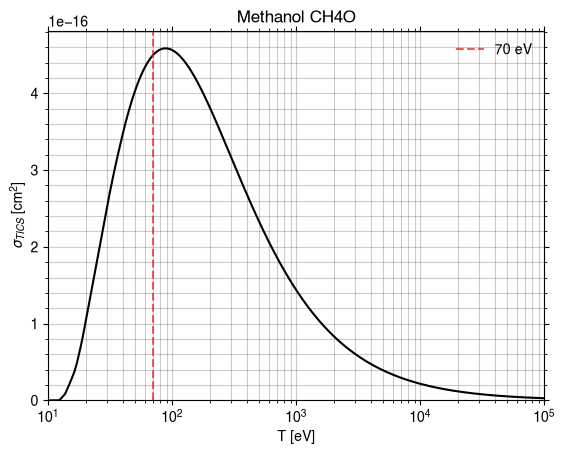

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(878)
Recherche : 'Methanethiol' -> CID 878, formule CH4S


Loading output/xyz/Methanethiol_CH4S.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Methanethiol_CH4S.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methanethiol_CH4S.gifGIF written to output/gif/Methanethiol_CH4S.gif

strucutre 3D
Réussite. Nom: Methanethiol, formule: CH4S, M: 48.11, nom_marche: Methanethiol
PYSCF CONVERGENCE
converged SCF energy = -50.1750604692701
**** MO energy ****
MO #1   energy= -11.2578517125717  occ= 2
MO #2   energy= -1.04231625292826  occ= 2
MO #3   energy= -0.866856157361259 occ= 2
MO #4   energy= -0.607599912492682 occ= 2
MO #5   energy= -0.589956523241821 occ= 2
MO #6   energy= -0.534915160735022 occ= 2
MO #7   energy= -0.458324029213667 occ= 2
MO #8   energy= -0.354781628190217 occ= 2
MO #9   energy= 0.069986894296509  occ= 0
MO #10  energy= 0.0822875866455336 occ= 0
MO #11  energy= 0.0970706906909287 occ= 0
MO #12  energy= 0.105946548233331  occ= 0
MO #13  energy= 0.142256504269135  occ= 0
MO #14  energy= 0.168254158470559  occ= 0
MO #15  energy= 0.171347658139711  occ= 0
MO #16  energy= 0.184685097737475  occ= 0
MO #17  energy= 0.201122063092641  occ= 0
MO #18  energy= 0.212780564437675  occ= 0
MO #19  energy= 0.235392015126659  occ= 0
MO #20  energy= 0.2684821180364

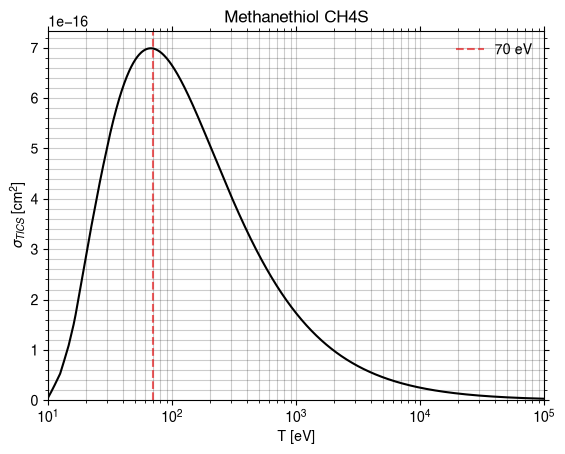

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(713)
Recherche : 'Formamide' -> CID 713, formule CH3NO


Loading output/xyz/Formamide_CH3NO.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Formamide_CH3NO.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Formamide_CH3NO.gifGIF written to output/gif/Formamide_CH3NO.gif

strucutre 3D
Réussite. Nom: Formamide, formule: CH3NO, M: 45.041, nom_marche: Formamide
PYSCF CONVERGENCE
converged SCF energy = -169.007610584349
**** MO energy ****
MO #1   energy= -20.5318381096548  occ= 2
MO #2   energy= -15.5998002621474  occ= 2
MO #3   energy= -11.3614862877949  occ= 2
MO #4   energy= -1.3790150197579   occ= 2
MO #5   energy= -1.2170371120892   occ= 2
MO #6   energy= -0.854615885470473 occ= 2
MO #7   energy= -0.745072832631951 occ= 2
MO #8   energy= -0.674307320102432 occ= 2
MO #9   energy= -0.608454782032172 occ= 2
MO #10  energy= -0.56856508899714  occ= 2
MO #11  energy= -0.438708012078516 occ= 2
MO #12  energy= -0.423610784325189 occ= 2
MO #13  energy= 0.0616725016183679 occ= 0
MO #14  energy= 0.0900351724938879 occ= 0
MO #15  energy= 0.112112079390803  occ= 0
MO #16  energy= 0.129601647961994  occ= 0
MO #17  energy= 0.147023971764697  occ= 0
MO #18  energy= 0.152864907175535  occ= 0
MO #19  energy= 0.15316536642793   occ= 0
MO #20  energy= 0.174382754401694  

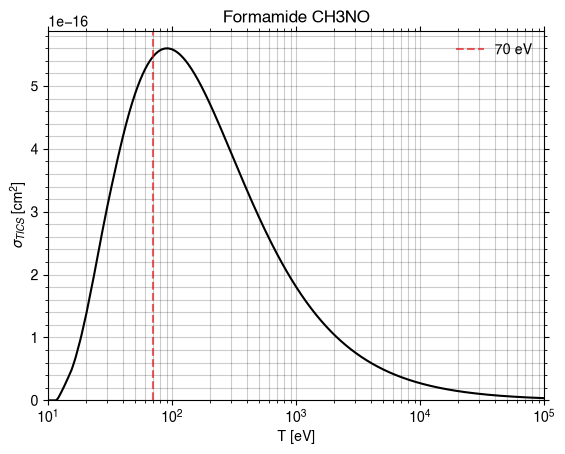

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Carbonic_acid_CH2O3.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Carbonic_acid_CH2O3.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

Compound(767)
Recherche : 'Carbonic acid' -> CID 767, formule CH2O3
3D


  frame 120/120
Wrote output/gif/Carbonic_acid_CH2O3.gifGIF written to output/gif/Carbonic_acid_CH2O3.gif

strucutre 3D
Réussite. Nom: Carbonic acid, formule: CH2O3, M: 62.025, nom_marche: Carbonic_acid
PYSCF CONVERGENCE
converged SCF energy = -263.766829633526
**** MO energy ****
MO #1   energy= -20.6332391557099  occ= 2
MO #2   energy= -20.6332137720423  occ= 2
MO #3   energy= -20.5582934828173  occ= 2
MO #4   energy= -11.4579097722355  occ= 2
MO #5   energy= -1.50887424866288  occ= 2
MO #6   energy= -1.40685679543253  occ= 2
MO #7   energy= -1.36810074070934  occ= 2
MO #8   energy= -0.906485167852239 occ= 2
MO #9   energy= -0.754854931237073 occ= 2
MO #10  energy= -0.72600918100343  occ= 2
MO #11  energy= -0.682260879601652 occ= 2
MO #12  energy= -0.663117984039217 occ= 2
MO #13  energy= -0.602720047141137 occ= 2
MO #14  energy= -0.556857435916537 occ= 2
MO #15  energy= -0.490420193712778 occ= 2
MO #16  energy= -0.482862518447192 occ= 2
MO #17  energy= 0.046822167426677  occ= 0
MO #18  energy= 0.0668750461459477 occ= 0
MO #19  energy= 0.0945991677735618 occ= 0
MO #20  energy= 0.106048175

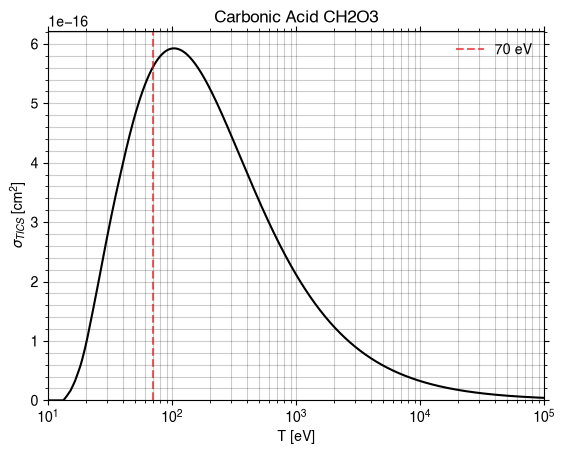

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(12222)
Recherche : 'Propynal' -> CID 12222, formule C3H2O


Loading output/xyz/Propynal_C3H2O.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Propynal_C3H2O.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Propynal_C3H2O.gifGIF written to output/gif/Propynal_C3H2O.gif

strucutre 3D
Réussite. Nom: Propynal, formule: C3H2O, M: 54.05, nom_marche: Propynal
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -189.616352819096
**** MO energy ****
MO #1   energy= -20.5811407761716  occ= 2
MO #2   energy= -11.3701622713797  occ= 2
MO #3   energy= -11.2727350608543  occ= 2
MO #4   energy= -11.2608018616395  occ= 2
MO #5   energy= -1.40709473874515  occ= 2
MO #6   energy= -1.07399396095023  occ= 2
MO #7   energy= -0.922148608874778 occ= 2
MO #8   energy= -0.76080173866243  occ= 2
MO #9   energy= -0.716512362213908 occ= 2
MO #10  energy= -0.664423244670598 occ= 2
MO #11  energy= -0.560736800272853 occ= 2
MO #12  energy= -0.468153218512036 occ= 2
MO #13  energy= -0.433226070014561 occ= 2
MO #14  energy= -0.426080958956873 occ= 2
MO #15  energy= 0.0590231034526442 occ= 0
MO #16  energy= 0.0600623568354807 occ= 0
MO #17  energy= 0.0810632331586199 occ= 0
MO #18  energy= 0.113694

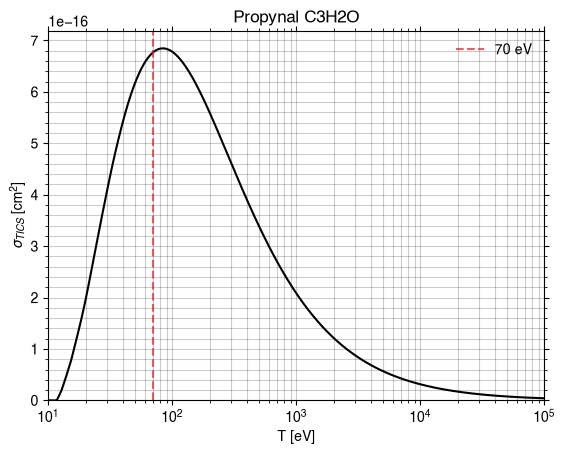

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(138122)
Recherche : 'Ketenimine' -> CID 138122, formule C2H3N


Loading output/xyz/Ketenimine_C2H3N.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Ketenimine_C2H3N.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ketenimine_C2H3N.gifGIF written to output/gif/Ketenimine_C2H3N.gif

strucutre 3D
Réussite. Nom: Ketenimine, formule: C2H3N, M: 41.05, nom_marche: Ketenimine
PYSCF CONVERGENCE
converged SCF energy = -131.88222405122
**** MO energy ****
MO #1   energy= -15.5664118607474  occ= 2
MO #2   energy= -11.3488867175112  occ= 2
MO #3   energy= -11.204981927355   occ= 2
MO #4   energy= -1.28416142461688  occ= 2
MO #5   energy= -1.02534194369147  occ= 2
MO #6   energy= -0.764298885540484 occ= 2
MO #7   energy= -0.668887144218097 occ= 2
MO #8   energy= -0.613597660077801 occ= 2
MO #9   energy= -0.565562238086841 occ= 2
MO #10  energy= -0.517629589026164 occ= 2
MO #11  energy= -0.314411040480309 occ= 2
MO #12  energy= 0.0626937969790667 occ= 0
MO #13  energy= 0.0873174559434432 occ= 0
MO #14  energy= 0.0983617691646745 occ= 0
MO #15  energy= 0.137090640218538  occ= 0
MO #16  energy= 0.158275324389135  occ= 0
MO #17  energy= 0.179977358160198  occ= 0
MO #18  energy= 0.182051313125953  occ= 0
MO #19  energy= 0.195089776417177  occ= 0
MO #20  energy= 0.217349116357833  

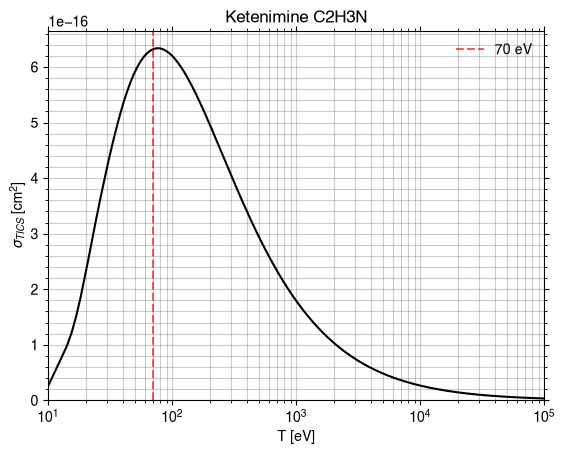

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6354)
Recherche : 'Ethylene oxide' -> CID 6354, formule C2H4O


Loading output/xyz/Ethylene_oxide_C2H4O.xyzBuilt graph: 7 atoms, 7 bondsLoading output/xyz/Ethylene_oxide_C2H4O.xyzBuilt graph: 7 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ethylene_oxide_C2H4O.gifGIF written to output/gif/Ethylene_oxide_C2H4O.gif

strucutre 3D
Réussite. Nom: Ethylene oxide, formule: C2H4O, M: 44.05, nom_marche: Ethylene_oxide
PYSCF CONVERGENCE
converged SCF energy = -152.929222010355
**** MO energy ****
MO #1   energy= -20.5776493528716  occ= 2
MO #2   energy= -11.2867346324522  occ= 2
MO #3   energy= -11.2860437703791  occ= 2
MO #4   energy= -1.40668544288788  occ= 2
MO #5   energy= -0.931958376803355 occ= 2
MO #6   energy= -0.863486692228715 occ= 2
MO #7   energy= -0.701762129032129 occ= 2
MO #8   energy= -0.65878273540303  occ= 2
MO #9   energy= -0.558722420505823 occ= 2
MO #10  energy= -0.546301560083778 occ= 2
MO #11  energy= -0.457023402488794 occ= 2
MO #12  energy= -0.437519497007868 occ= 2
MO #13  energy= 0.0724374469237515 occ= 0
MO #14  energy= 0.0886543817704801 occ= 0
MO #15  energy= 0.109018968191157  occ= 0
MO #16  energy= 0.11148840066725   occ= 0
MO #17  energy= 0.145824888442768  occ= 0
MO #18  energy= 0.159791347318938  occ= 0
MO #19  energy= 0.164772842930204  occ= 0
MO #20  energy= 0.18143952

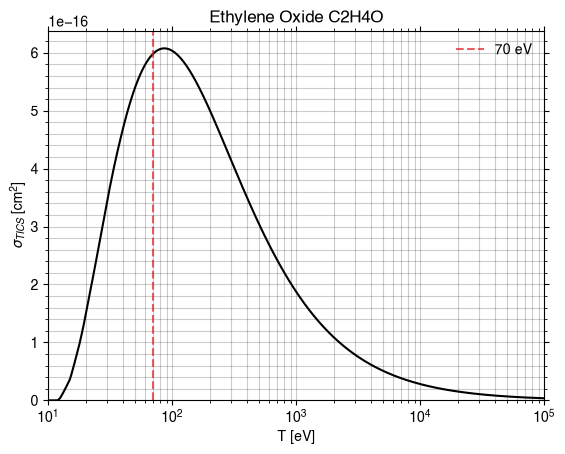

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6329)
Recherche : 'Methylamine' -> CID 6329, formule CH5N


Loading output/xyz/Methylamine_CH5N.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Methylamine_CH5N.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methylamine_CH5N.gifGIF written to output/gif/Methylamine_CH5N.gif

strucutre 3D
Réussite. Nom: Methylamine, formule: CH5N, M: 31.057, nom_marche: Methylamine
PYSCF CONVERGENCE
converged SCF energy = -95.2565850014825
**** MO energy ****
MO #1   energy= -15.5373651780732  occ= 2
MO #2   energy= -11.2378434185403  occ= 2
MO #3   energy= -1.17795623281231  occ= 2
MO #4   energy= -0.890491221307357 occ= 2
MO #5   energy= -0.664217908808169 occ= 2
MO #6   energy= -0.606404044264025 occ= 2
MO #7   energy= -0.565571127562016 occ= 2
MO #8   energy= -0.512970700259999 occ= 2
MO #9   energy= -0.387195482451403 occ= 2
MO #10  energy= 0.0761034754821033 occ= 0
MO #11  energy= 0.106265088268262  occ= 0
MO #12  energy= 0.138962086485918  occ= 0
MO #13  energy= 0.154260731631846  occ= 0
MO #14  energy= 0.173152421096108  occ= 0
MO #15  energy= 0.1870931517756    occ= 0
MO #16  energy= 0.200071656911806  occ= 0
MO #17  energy= 0.219533577144168  occ= 0
MO #18  energy= 0.222611957449     occ= 0
MO #19  energy= 0.265279749670701  occ= 0
MO #20  energy= 0.27476297649776

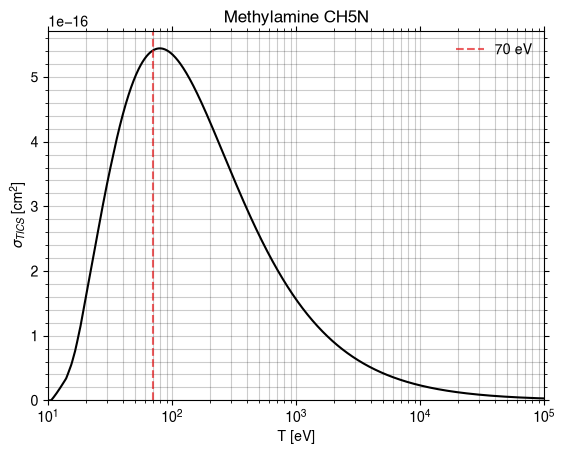

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Propargylimine not found : IndexError : list index out of range
Propargylimine a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(11199)
Recherche : 'Vinyl alcohol' -> CID 11199, formule C2H4O


Loading output/xyz/Vinyl_alcohol_C2H4O.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Vinyl_alcohol_C2H4O.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Vinyl_alcohol_C2H4O.gifGIF written to output/gif/Vinyl_alcohol_C2H4O.gif

strucutre 3D
Réussite. Nom: Vinyl alcohol, formule: C2H4O, M: 44.05, nom_marche: Vinyl_alcohol
PYSCF CONVERGENCE
converged SCF energy = -152.958780629203
**** MO energy ****
MO #1   energy= -20.5918136659633  occ= 2
MO #2   energy= -11.2972974042195  occ= 2
MO #3   energy= -11.2132442273839  occ= 2
MO #4   energy= -1.40104096282386  occ= 2
MO #5   energy= -1.02133430010668  occ= 2
MO #6   energy= -0.79656624764446  occ= 2
MO #7   energy= -0.739553994395902 occ= 2
MO #8   energy= -0.624759199773457 occ= 2
MO #9   energy= -0.577837010235069 occ= 2
MO #10  energy= -0.575247387671801 occ= 2
MO #11  energy= -0.517316631613163 occ= 2
MO #12  energy= -0.34707749521241  occ= 2
MO #13  energy= 0.0601645382042335 occ= 0
MO #14  energy= 0.0897679042187348 occ= 0
MO #15  energy= 0.10432629772025   occ= 0
MO #16  energy= 0.122844652544415  occ= 0
MO #17  energy= 0.12613140143652   occ= 0
MO #18  energy= 0.150220442826907  occ= 0
MO #19  energy= 0.151851876117288  occ= 0
MO #20  energy= 0.1721526438

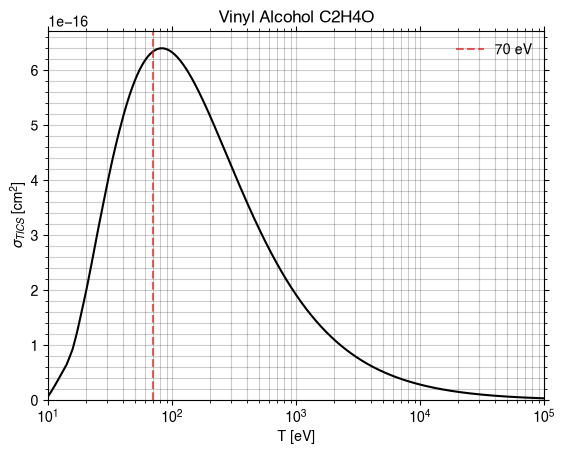

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(108850)
Recherche : 'Cyanodiacetylene' -> CID 108850, formule C5HN


Loading output/xyz/Cyanodiacetylene_C5HN.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Cyanodiacetylene_C5HN.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyanodiacetylene_C5HN.gifGIF written to output/gif/Cyanodiacetylene_C5HN.gif

strucutre 3D
Réussite. Nom: Cyanodiacetylene, formule: C5HN, M: 75.07, nom_marche: Cyanodiacetylene
PYSCF CONVERGENCE

WARN: 3 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -244.315720718455
**** MO energy ****
MO #1   energy= -15.6090561369903  occ= 2
MO #2   energy= -11.318814041015   occ= 2
MO #3   energy= -11.3144401573383  occ= 2
MO #4   energy= -11.3058769709598  occ= 2
MO #5   energy= -11.2935903369434  occ= 2
MO #6   energy= -11.2896921218945  occ= 2
MO #7   energy= -1.2483899997671   occ= 2
MO #8   energy= -1.13511811148057  occ= 2
MO #9   energy= -1.06997071858372  occ= 2
MO #10  energy= -0.931719594021715 occ= 2
MO #11  energy= -0.840521120296984 occ= 2
MO #12  energy= -0.745673186872651 occ= 2
MO #13  energy= -0.591787910919526 occ= 2
MO #14  energy= -0.563694242780272 occ= 2
MO #15  energy= -0.563694242175264 occ= 2
MO #16  energy= -0.496879260113838 occ= 2
MO #17  energy= -0.496879257830034 occ= 2
MO #18  e

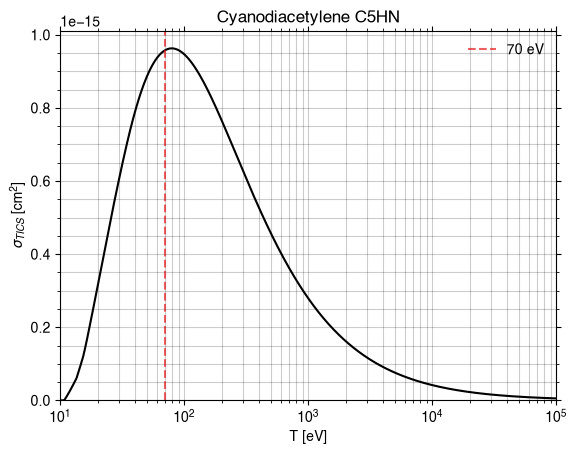

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Isocyanodiacetylene not found : IndexError : list index out of range
Isocyanodiacetylene a échoué : TypeError : cannot unpack non-iterable NoneType object


Loading output/xyz/Acetaldehyde_C2H4O.xyzBuilt graph: 7 atoms, 6 bonds

Compound(177)
Recherche : 'Acetaldehyde' -> CID 177, formule C2H4O
3D


  frame 120/120xyz/Acetaldehyde_C2H4O.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/Acetaldehyde_C2H4O.gifGIF written to output/gif/Acetaldehyde_C2H4O.gif

strucutre 3D
Réussite. Nom: Acetaldehyde, formule: C2H4O, M: 44.05, nom_marche: Acetaldehyde
PYSCF CONVERGENCE
converged SCF energy = -152.979170817269
**** MO energy ****
MO #1   energy= -20.5587952298497  occ= 2
MO #2   energy= -11.3382873721996  occ= 2
MO #3   energy= -11.2426453173036  occ= 2
MO #4   energy= -1.38258709810725  occ= 2
MO #5   energy= -1.02415817828895  occ= 2
MO #6   energy= -0.804887138054479 occ= 2
MO #7   energy= -0.672312129130365 occ= 2
MO #8   energy= -0.62086651747206  occ= 2
MO #9   energy= -0.609839291026537 occ= 2
MO #10  energy= -0.558248978692902 occ= 2
MO #11  energy= -0.50026420482385  occ= 2
MO #12  energy= -0.429644531622319 occ= 2
MO #13  energy= 0.0671485258628017 occ= 0
MO #14  energy= 0.0879203024316944 occ= 0
MO #15  energy= 0.114425671282814  occ= 0
MO #16  energy= 0.117632166942298  occ= 0
MO #17  energy= 0.123040430195324  occ= 0
MO #18  energy= 0.143239328809249  occ= 0
MO #19  energy= 0.158576992765125  occ= 0
MO #20  energy= 0.159247875805

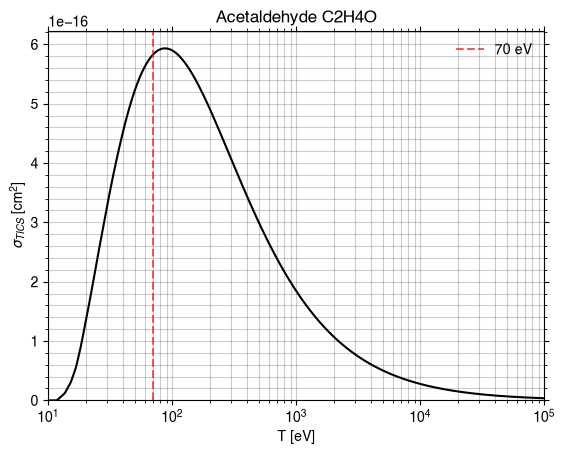

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(123241)
Recherche : 'Thioacetaldehyde' -> CID 123241, formule C2H4S


Loading output/xyz/Thioacetaldehyde_C2H4S.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Thioacetaldehyde_C2H4S.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Thioacetaldehyde_C2H4S.gifGIF written to output/gif/Thioacetaldehyde_C2H4S.gif

strucutre 3D
Réussite. Nom: Thioacetaldehyde, formule: C2H4S, M: 60.12, nom_marche: Thioacetaldehyde
PYSCF CONVERGENCE
converged SCF energy = -88.0302100220281
**** MO energy ****
MO #1   energy= -11.3334599502783  occ= 2
MO #2   energy= -11.2496334686019  occ= 2
MO #3   energy= -1.08779685441475  occ= 2
MO #4   energy= -0.951290414847321 occ= 2
MO #5   energy= -0.77804207088661  occ= 2
MO #6   energy= -0.624759673420087 occ= 2
MO #7   energy= -0.598108036985167 occ= 2
MO #8   energy= -0.57045917201668  occ= 2
MO #9   energy= -0.505093805448595 occ= 2
MO #10  energy= -0.38706542889539  occ= 2
MO #11  energy= -0.341099084255703 occ= 2
MO #12  energy= 0.0493131627204837 occ= 0
MO #13  energy= 0.0696915279833856 occ= 0
MO #14  energy= 0.0888649996756282 occ= 0
MO #15  energy= 0.0938001361582862 occ= 0
MO #16  energy= 0.109644627171139  occ= 0
MO #17  energy= 0.122164499851211  occ= 0
MO #18  energy= 0.156075066948519  occ= 0
MO #19  energy= 0.158350702926635  occ= 0
MO #20  energy= 0.1615

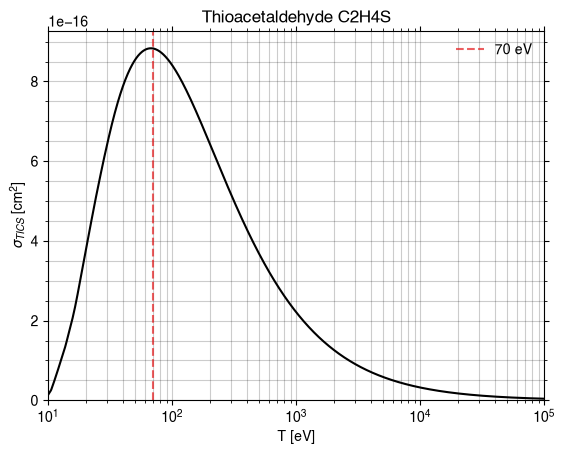

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(12228)
Recherche : 'Methyl isocyanate' -> CID 12228, formule C2H3NO


Loading output/xyz/Methyl_isocyanate_C2H3NO.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Methyl_isocyanate_C2H3NO.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methyl_isocyanate_C2H3NO.gifGIF written to output/gif/Methyl_isocyanate_C2H3NO.gif

strucutre 3D
Réussite. Nom: Methyl isocyanate, formule: C2H3NO, M: 57.05, nom_marche: Methyl_isocyanate
PYSCF CONVERGENCE
converged SCF energy = -206.869636498921
**** MO energy ****
MO #1   energy= -20.6110353195995  occ= 2
MO #2   energy= -15.5836020886272  occ= 2
MO #3   energy= -11.3911806448989  occ= 2
MO #4   energy= -11.2926169371773  occ= 2
MO #5   energy= -1.45979924352974  occ= 2
MO #6   energy= -1.30037439600047  occ= 2
MO #7   energy= -0.981861376877248 occ= 2
MO #8   energy= -0.742570582062889 occ= 2
MO #9   energy= -0.692174777720446 occ= 2
MO #10  energy= -0.674261583809624 occ= 2
MO #11  energy= -0.666852200861639 occ= 2
MO #12  energy= -0.597406593690341 occ= 2
MO #13  energy= -0.570971978149174 occ= 2
MO #14  energy= -0.470289447621973 occ= 2
MO #15  energy= -0.430422699174933 occ= 2
MO #16  energy= 0.0569130098959256 occ= 0
MO #17  energy= 0.0812598746507192 occ= 0
MO #18  energy= 0.112655084348312  occ= 0
MO #19  energy= 0.112910721300426  occ= 0
MO #20  energy= 0.1

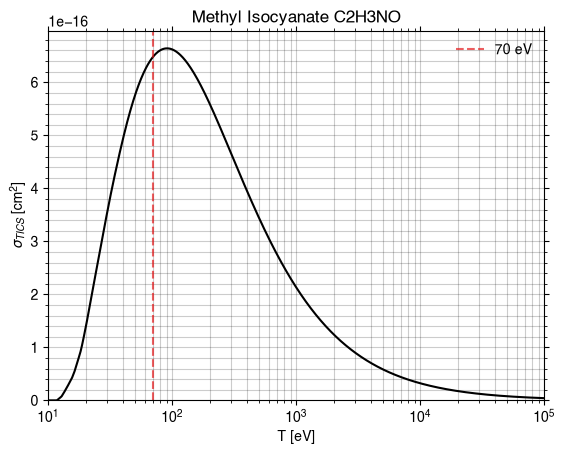

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(7857)
Recherche : 'Glycolonitrile' -> CID 7857, formule C2H3NO


Loading output/xyz/Glycolonitrile_C2H3NO.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Glycolonitrile_C2H3NO.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Glycolonitrile_C2H3NO.gifGIF written to output/gif/Glycolonitrile_C2H3NO.gif

strucutre 3D
Réussite. Nom: Glycolonitrile, formule: C2H3NO, M: 57.05, nom_marche: Glycolonitrile
PYSCF CONVERGENCE
converged SCF energy = -206.851290009132
**** MO energy ****
MO #1   energy= -20.5988892283356  occ= 2
MO #2   energy= -15.5860051818597  occ= 2
MO #3   energy= -11.3482131944513  occ= 2
MO #4   energy= -11.2853897754218  occ= 2
MO #5   energy= -1.40179574956758  occ= 2
MO #6   energy= -1.22495685185076  occ= 2
MO #7   energy= -1.0162399256704   occ= 2
MO #8   energy= -0.752065221554108 occ= 2
MO #9   energy= -0.708222081520962 occ= 2
MO #10  energy= -0.689955269806246 occ= 2
MO #11  energy= -0.58132667349695  occ= 2
MO #12  energy= -0.557161573928088 occ= 2
MO #13  energy= -0.512053987727192 occ= 2
MO #14  energy= -0.478031310367557 occ= 2
MO #15  energy= -0.461863195898368 occ= 2
MO #16  energy= 0.0470663942764133 occ= 0
MO #17  energy= 0.0818598661818935 occ= 0
MO #18  energy= 0.0982673438232025 occ= 0
MO #19  energy= 0.098785925777688  occ= 0
MO #20  energy= 0.1328590

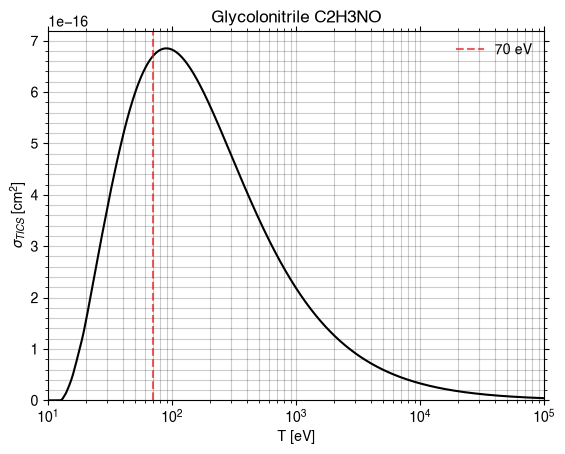

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(139576)
Recherche : 'Methylcyanoacetylene' -> CID 139576, formule C4H3N


Loading output/xyz/Methylcyanoacetylene_C4H3N.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Methylcyanoacetylene_C4H3N.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methylcyanoacetylene_C4H3N.gifGIF written to output/gif/Methylcyanoacetylene_C4H3N.gif

strucutre 3D
Réussite. Nom: Methylcyanoacetylene, formule: C4H3N, M: 65.07, nom_marche: Methylcyanoacetylene
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -207.674918403551
**** MO energy ****
MO #1   energy= -15.5910939832694  occ= 2
MO #2   energy= -11.2999805075899  occ= 2
MO #3   energy= -11.294879638914   occ= 2
MO #4   energy= -11.282942045166   occ= 2
MO #5   energy= -11.2745646782436  occ= 2
MO #6   energy= -1.23285342740463  occ= 2
MO #7   energy= -1.10793781193274  occ= 2
MO #8   energy= -1.01559920376178  occ= 2
MO #9   energy= -0.873073494252303 occ= 2
MO #10  energy= -0.670045713678739 occ= 2
MO #11  energy= -0.624470790504252 occ= 2
MO #12  energy= -0.624455584861208 occ= 2
MO #13  energy= -0.576528850531254 occ= 2
MO #14  energy= -0.52966464314456  occ= 2
MO #15  energy= -0.529663428331919 occ= 2
MO #16  energy= -0.405805581104445 occ= 2
MO #17  energy= -0.40580371350697  occ= 2


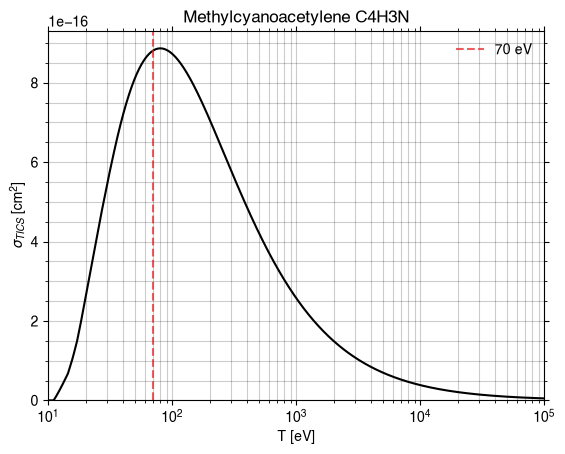

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(23270069)
Recherche : 'Propargyl cyanide' -> CID 23270069, formule C4H3N


Loading output/xyz/Propargyl_cyanide_C4H3N.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Propargyl_cyanide_C4H3N.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Propargyl_cyanide_C4H3N.gifGIF written to output/gif/Propargyl_cyanide_C4H3N.gif

strucutre 3D
Réussite. Nom: Propargyl cyanide, formule: C4H3N, M: 65.07, nom_marche: Propargyl_cyanide
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -207.665070750581
**** MO energy ****
MO #1   energy= -15.5844067982837  occ= 2
MO #2   energy= -11.3251282843509  occ= 2
MO #3   energy= -11.2902348107611  occ= 2
MO #4   energy= -11.2651157869448  occ= 2
MO #5   energy= -11.2532174886064  occ= 2
MO #6   energy= -1.22886324258744  occ= 2
MO #7   energy= -1.11108373615001  occ= 2
MO #8   energy= -1.01318035436982  occ= 2
MO #9   energy= -0.767647821092169 occ= 2
MO #10  energy= -0.721596608262985 occ= 2
MO #11  energy= -0.675521515830106 occ= 2
MO #12  energy= -0.66173679758164  occ= 2
MO #13  energy= -0.568423631899677 occ= 2
MO #14  energy= -0.477107895134332 occ= 2
MO #15  energy= -0.475015712799457 occ= 2
MO #16  energy= -0.42138072381867  occ= 2
MO #17  energy= -0.415909270243097 occ= 2
MO #18

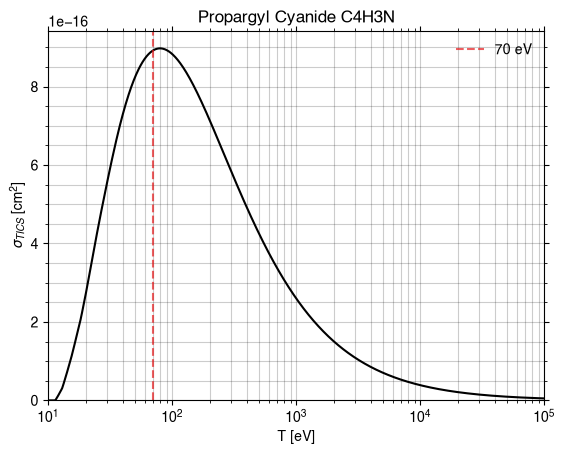

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(756)
Recherche : 'Glycolaldehyde' -> CID 756, formule C2H4O2


Loading output/xyz/Glycolaldehyde_C2H4O2.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Glycolaldehyde_C2H4O2.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Glycolaldehyde_C2H4O2.gifGIF written to output/gif/Glycolaldehyde_C2H4O2.gif

strucutre 3D
Réussite. Nom: Glycolaldehyde, formule: C2H4O2, M: 60.05, nom_marche: Glycolaldehyde
PYSCF CONVERGENCE
converged SCF energy = -227.860577636954
**** MO energy ****
MO #1   energy= -20.5725113217494  occ= 2
MO #2   energy= -20.5692522542653  occ= 2
MO #3   energy= -11.3433095730386  occ= 2
MO #4   energy= -11.3062355766864  occ= 2
MO #5   energy= -1.40090249492312  occ= 2
MO #6   energy= -1.3670321899201   occ= 2
MO #7   energy= -1.00662664750123  occ= 2
MO #8   energy= -0.812833278286117 occ= 2
MO #9   energy= -0.711828760381124 occ= 2
MO #10  energy= -0.698913354431369 occ= 2
MO #11  energy= -0.651485608745631 occ= 2
MO #12  energy= -0.611959358223416 occ= 2
MO #13  energy= -0.548743758755755 occ= 2
MO #14  energy= -0.512781343877023 occ= 2
MO #15  energy= -0.48645641289281  occ= 2
MO #16  energy= -0.432812612318354 occ= 2
MO #17  energy= 0.0598179100097305 occ= 0
MO #18  energy= 0.0831767675012635 occ= 0
MO #19  energy= 0.0875873924941237 occ= 0
MO #20  energy= 0.1025447

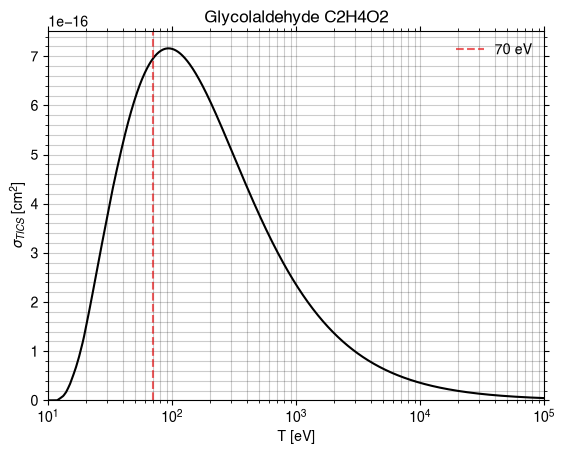

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(3036308)
Recherche : '1,2-ethenediol' -> CID 3036308, formule C2H4O2


Loading output/xyz/1_2-ethenediol_C2H4O2.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/1_2-ethenediol_C2H4O2.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/1_2-ethenediol_C2H4O2.gifGIF written to output/gif/1_2-ethenediol_C2H4O2.gif

strucutre 3D
Réussite. Nom: 1,2-ethenediol, formule: C2H4O2, M: 60.05, nom_marche: 1_2-ethenediol
PYSCF CONVERGENCE
converged SCF energy = -227.841446195253
**** MO energy ****
MO #1   energy= -20.5848788112205  occ= 2
MO #2   energy= -20.5831509972814  occ= 2
MO #3   energy= -11.282647567062   occ= 2
MO #4   energy= -11.2808435207929  occ= 2
MO #5   energy= -1.40060276957812  occ= 2
MO #6   energy= -1.38857354191792  occ= 2
MO #7   energy= -1.00893973447798  occ= 2
MO #8   energy= -0.827202565172719 occ= 2
MO #9   energy= -0.736974877165032 occ= 2
MO #10  energy= -0.70538096218284  occ= 2
MO #11  energy= -0.623238884430688 occ= 2
MO #12  energy= -0.593695961885722 occ= 2
MO #13  energy= -0.562679232291545 occ= 2
MO #14  energy= -0.554487309945013 occ= 2
MO #15  energy= -0.529068003776654 occ= 2
MO #16  energy= -0.322245312525148 occ= 2
MO #17  energy= 0.0543932015015436 occ= 0
MO #18  energy= 0.0735536594363357 occ= 0
MO #19  energy= 0.0882007939458545 occ= 0
MO #20  energy= 0.1118040

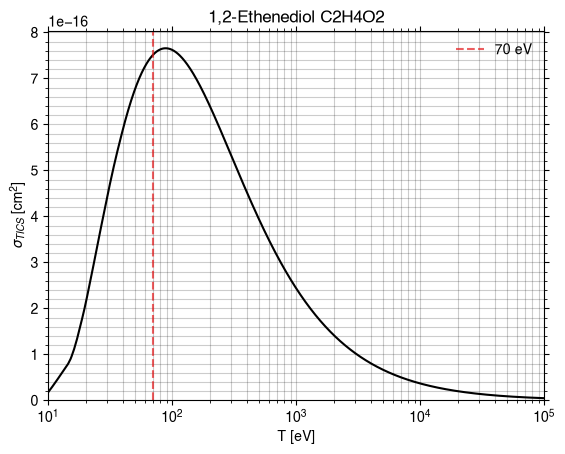

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(176)
Recherche : 'Acetic acid' -> CID 176, formule C2H4O2


Loading output/xyz/Acetic_acid_C2H4O2.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Acetic_acid_C2H4O2.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Acetic_acid_C2H4O2.gifGIF written to output/gif/Acetic_acid_C2H4O2.gif

strucutre 3D
Réussite. Nom: Acetic acid, formule: C2H4O2, M: 60.05, nom_marche: Acetic_acid
PYSCF CONVERGENCE
converged SCF energy = -227.909442625955
**** MO energy ****
MO #1   energy= -20.6164767964583  occ= 2
MO #2   energy= -20.5493907145594  occ= 2
MO #3   energy= -11.3925468821946  occ= 2
MO #4   energy= -11.246293083182   occ= 2
MO #5   energy= -1.45754406092591  occ= 2
MO #6   energy= -1.35616218250539  occ= 2
MO #7   energy= -1.028502495777    occ= 2
MO #8   energy= -0.8307749732312   occ= 2
MO #9   energy= -0.702601271184999 occ= 2
MO #10  energy= -0.676951337226289 occ= 2
MO #11  energy= -0.651595269902696 occ= 2
MO #12  energy= -0.578842237678761 occ= 2
MO #13  energy= -0.568518822602287 occ= 2
MO #14  energy= -0.565495436535501 occ= 2
MO #15  energy= -0.481787950895441 occ= 2
MO #16  energy= -0.455199555810669 occ= 2
MO #17  energy= 0.055001044982788  occ= 0
MO #18  energy= 0.0844117115742097 occ= 0
MO #19  energy= 0.0976962827023329 occ= 0
MO #20  energy= 0.1040449347584

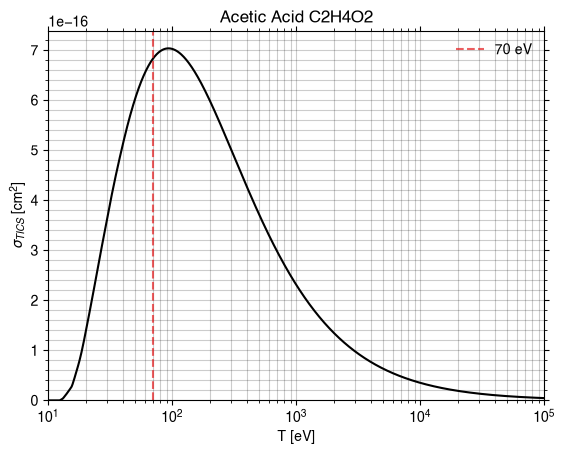

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Hexapentaenylidene not found : IndexError : list index out of range
Hexapentaenylidene a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(7847)
Recherche : 'Propenal' -> CID 7847, formule C3H4O


Loading output/xyz/Propenal_C3H4O.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Propenal_C3H4O.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Propenal_C3H4O.gifGIF written to output/gif/Propenal_C3H4O.gif

strucutre 3D
Réussite. Nom: Propenal, formule: C3H4O, M: 56.06, nom_marche: Propenal
PYSCF CONVERGENCE
converged SCF energy = -190.839515026493
**** MO energy ****
MO #1   energy= -20.5566104314955  occ= 2
MO #2   energy= -11.3375180313327  occ= 2
MO #3   energy= -11.2699262082513  occ= 2
MO #4   energy= -11.2564693142629  occ= 2
MO #5   energy= -1.38311619891325  occ= 2
MO #6   energy= -1.09002489996628  occ= 2
MO #7   energy= -0.886090592687353 occ= 2
MO #8   energy= -0.790761399828195 occ= 2
MO #9   energy= -0.670704157769959 occ= 2
MO #10  energy= -0.669066148292988 occ= 2
MO #11  energy= -0.601815355587306 occ= 2
MO #12  energy= -0.562431099949666 occ= 2
MO #13  energy= -0.539126909572818 occ= 2
MO #14  energy= -0.434205623738297 occ= 2
MO #15  energy= -0.400889248759    occ= 2
MO #16  energy= 0.0650555743926964 occ= 0
MO #17  energy= 0.0724209082564385 occ= 0
MO #18  energy= 0.0834481683542794 occ= 0
MO #19  energy= 0.086069440018961  occ= 0
MO #20  energy= 0.128858180357062  occ

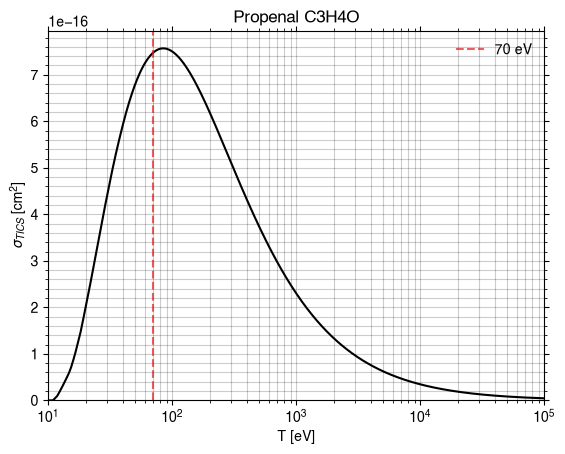

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(136789)
Recherche : 'Cyanoallene' -> CID 136789, formule C4H3N


Loading output/xyz/Cyanoallene_C4H3N.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Cyanoallene_C4H3N.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Cyanoallene_C4H3N.gifGIF written to output/gif/Cyanoallene_C4H3N.gif

strucutre 3D
Réussite. Nom: Cyanoallene, formule: C4H3N, M: 65.07, nom_marche: Cyanoallene
PYSCF CONVERGENCE
converged SCF energy = -207.568248202174
**** MO energy ****
MO #1   energy= -15.5603301858001  occ= 2
MO #2   energy= -11.4111219140867  occ= 2
MO #3   energy= -11.2828531787818  occ= 2
MO #4   energy= -11.2610246540374  occ= 2
MO #5   energy= -11.253492473964   occ= 2
MO #6   energy= -1.21551876817649  occ= 2
MO #7   energy= -1.15559788077588  occ= 2
MO #8   energy= -1.04147610387245  occ= 2
MO #9   energy= -0.809072031895376 occ= 2
MO #10  energy= -0.714973911595711 occ= 2
MO #11  energy= -0.689631540151287 occ= 2
MO #12  energy= -0.632817529208509 occ= 2
MO #13  energy= -0.569240269896471 occ= 2
MO #14  energy= -0.549963451213124 occ= 2
MO #15  energy= -0.474209769738079 occ= 2
MO #16  energy= -0.460488789302119 occ= 2
MO #17  energy= -0.30304405119481  occ= 2
MO #18  energy= -0.00504397024504755 occ= 0
MO #19  energy= 0.0513192449664057 occ= 0
MO #20  energy= 0.082094372076

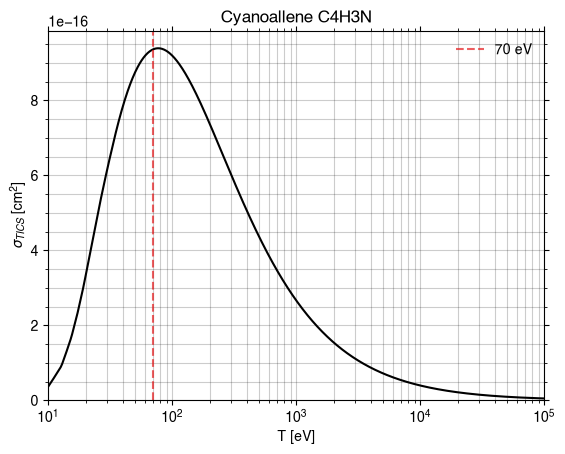

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(140746)
Recherche : 'Ethanimine' -> CID 140746, formule C2H5N


Loading output/xyz/Ethanimine_C2H5N.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Ethanimine_C2H5N.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ethanimine_C2H5N.gifGIF written to output/gif/Ethanimine_C2H5N.gif

strucutre 3D
Réussite. Nom: Ethanimine, formule: C2H5N, M: 43.07, nom_marche: Ethanimine
PYSCF CONVERGENCE
converged SCF energy = -133.129284909511
**** MO energy ****
MO #1   energy= -15.5527636339729  occ= 2
MO #2   energy= -11.2880907388146  occ= 2
MO #3   energy= -11.2303295555872  occ= 2
MO #4   energy= -1.19946029904357  occ= 2
MO #5   energy= -0.995378939230086 occ= 2
MO #6   energy= -0.77569426126972  occ= 2
MO #7   energy= -0.687310760306119 occ= 2
MO #8   energy= -0.587138960702025 occ= 2
MO #9   energy= -0.565971398903957 occ= 2
MO #10  energy= -0.546248262526106 occ= 2
MO #11  energy= -0.422981988105467 occ= 2
MO #12  energy= -0.42270813905919  occ= 2
MO #13  energy= 0.0716270793393285 occ= 0
MO #14  energy= 0.0891873940524939 occ= 0
MO #15  energy= 0.124422719699279  occ= 0
MO #16  energy= 0.139992527819158  occ= 0
MO #17  energy= 0.15019171885851   occ= 0
MO #18  energy= 0.162666964061136  occ= 0
MO #19  energy= 0.169714354724624  occ= 0
MO #20  energy= 0.1908546839037   

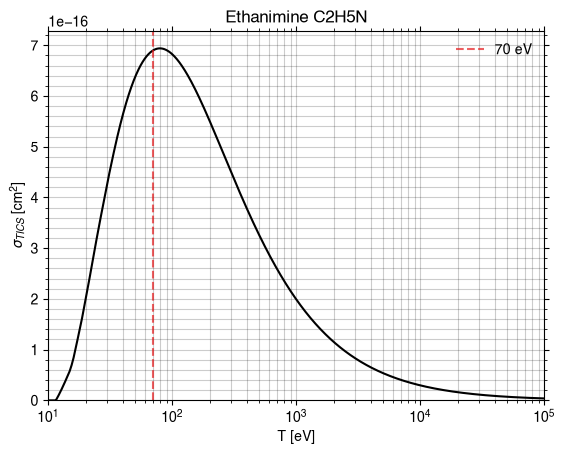

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(11642)
Recherche : 'Vinylamine' -> CID 11642, formule C2H5N


Loading output/xyz/Vinylamine_C2H5N.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Vinylamine_C2H5N.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Vinylamine_C2H5N.gifGIF written to output/gif/Vinylamine_C2H5N.gif

strucutre 3D
Réussite. Nom: Vinylamine, formule: C2H5N, M: 43.07, nom_marche: Vinylamine
PYSCF CONVERGENCE
converged SCF energy = -133.122869600408
**** MO energy ****
MO #1   energy= -15.5655111897663  occ= 2
MO #2   energy= -11.2657023728812  occ= 2
MO #3   energy= -11.1883636040576  occ= 2
MO #4   energy= -1.21706576890473  occ= 2
MO #5   energy= -0.988022254448509 occ= 2
MO #6   energy= -0.793175393514176 occ= 2
MO #7   energy= -0.71309409266479  occ= 2
MO #8   energy= -0.640482845014148 occ= 2
MO #9   energy= -0.568858521146687 occ= 2
MO #10  energy= -0.512008893649524 occ= 2
MO #11  energy= -0.500889681247569 occ= 2
MO #12  energy= -0.303728046692648 occ= 2
MO #13  energy= 0.0727771504661763 occ= 0
MO #14  energy= 0.094758057088578  occ= 0
MO #15  energy= 0.100757306254965  occ= 0
MO #16  energy= 0.151861218358179  occ= 0
MO #17  energy= 0.161669689397464  occ= 0
MO #18  energy= 0.164703658194057  occ= 0
MO #19  energy= 0.177100781350231  occ= 0
MO #20  energy= 0.20357839952768  

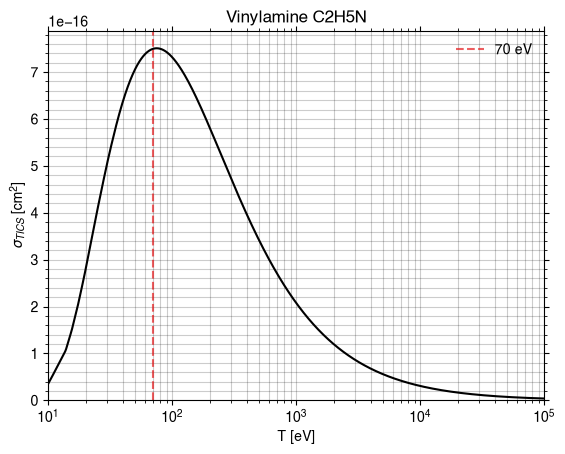

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(10901)
Recherche : 'Aminoacetonitrile' -> CID 10901, formule C2H4N2


Loading output/xyz/Aminoacetonitrile_C2H4N2.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Aminoacetonitrile_C2H4N2.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Aminoacetonitrile_C2H4N2.gifGIF written to output/gif/Aminoacetonitrile_C2H4N2.gif

strucutre 3D
Réussite. Nom: Aminoacetonitrile, formule: C2H4N2, M: 56.07, nom_marche: Aminoacetonitrile
PYSCF CONVERGENCE
converged SCF energy = -187.017362588492
**** MO energy ****
MO #1   energy= -15.5777899969124  occ= 2
MO #2   energy= -15.5774960041283  occ= 2
MO #3   energy= -11.3169663481558  occ= 2
MO #4   energy= -11.2790956111076  occ= 2
MO #5   energy= -1.23573276173192  occ= 2
MO #6   energy= -1.20370041934849  occ= 2
MO #7   energy= -0.981817003427921 occ= 2
MO #8   energy= -0.736736951826011 occ= 2
MO #9   energy= -0.674480588592837 occ= 2
MO #10  energy= -0.651856600869326 occ= 2
MO #11  energy= -0.599672673538869 occ= 2
MO #12  energy= -0.557400651578732 occ= 2
MO #13  energy= -0.471613606576524 occ= 2
MO #14  energy= -0.468219841034392 occ= 2
MO #15  energy= -0.428491305972351 occ= 2
MO #16  energy= 0.0557106997287988 occ= 0
MO #17  energy= 0.0898389650387926 occ= 0
MO #18  energy= 0.0978271926598063 occ= 0
MO #19  energy= 0.124172876791587  occ= 0
MO #20  energy= 0.1

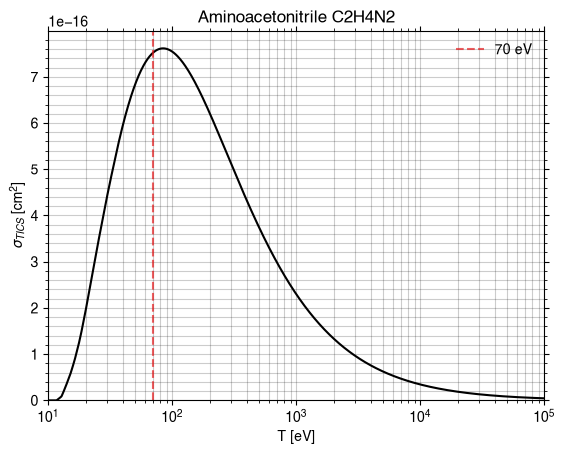

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(1176)
Recherche : 'Urea' -> CID 1176, formule CH4N2O


Loading output/xyz/Urea_CH4N2O.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Urea_CH4N2O.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Urea_CH4N2O.gifGIF written to output/gif/Urea_CH4N2O.gif

strucutre 3D
Réussite. Nom: Urea, formule: CH4N2O, M: 60.056, nom_marche: Urea
PYSCF CONVERGENCE
converged SCF energy = -224.085703446645
**** MO energy ****
MO #1   energy= -20.5055888375289  occ= 2
MO #2   energy= -15.5849930795903  occ= 2
MO #3   energy= -15.5849370423355  occ= 2
MO #4   energy= -11.3832400526066  occ= 2
MO #5   energy= -1.37823725838874  occ= 2
MO #6   energy= -1.22995319231973  occ= 2
MO #7   energy= -1.17040834714414  occ= 2
MO #8   energy= -0.834669338805906 occ= 2
MO #9   energy= -0.736092204500069 occ= 2
MO #10  energy= -0.72909386880132  occ= 2
MO #11  energy= -0.647424103398301 occ= 2
MO #12  energy= -0.601931484482636 occ= 2
MO #13  energy= -0.596144733685966 occ= 2
MO #14  energy= -0.437839957364563 occ= 2
MO #15  energy= -0.425061413930447 occ= 2
MO #16  energy= -0.415060271020042 occ= 2
MO #17  energy= 0.0580139883958637 occ= 0
MO #18  energy= 0.0925619025627389 occ= 0
MO #19  energy= 0.101628174883951  occ= 0
MO #20  energy= 0.130471672345776  occ= 0
MO

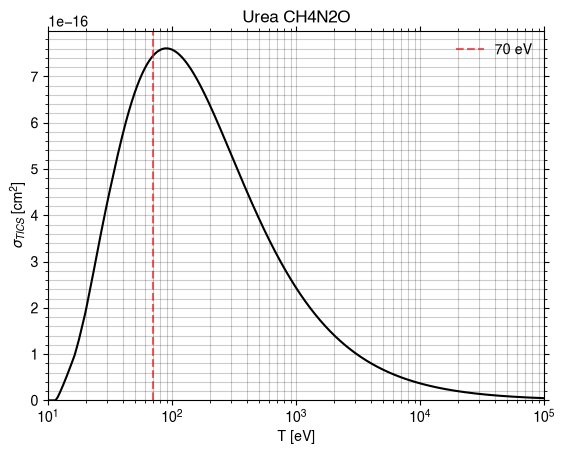

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(138385)
Recherche : 'Methyldiacetylene' -> CID 138385, formule C5H4


Loading output/xyz/Methyldiacetylene_C5H4.xyzBuilt graph: 9 atoms, 8 bondsLoading output/xyz/Methyldiacetylene_C5H4.xyzBuilt graph: 9 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methyldiacetylene_C5H4.gifGIF written to output/gif/Methyldiacetylene_C5H4.gif

strucutre 3D
Réussite. Nom: Methyldiacetylene, formule: C5H4, M: 64.08, nom_marche: Methyldiacetylene
PYSCF CONVERGENCE

WARN: 3 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -191.618331626902
**** MO energy ****
MO #1   energy= -11.2601018282695  occ= 2
MO #2   energy= -11.2546542682519  occ= 2
MO #3   energy= -11.253338551511   occ= 2
MO #4   energy= -11.2429481083482  occ= 2
MO #5   energy= -11.2424052007384  occ= 2
MO #6   energy= -1.09131754269504  occ= 2
MO #7   energy= -1.04156546996653  occ= 2
MO #8   energy= -0.970530610232284 occ= 2
MO #9   energy= -0.821426163865322 occ= 2
MO #10  energy= -0.706928437226637 occ= 2
MO #11  energy= -0.640109582919226 occ= 2
MO #12  energy= -0.600866021482756 occ= 2
MO #13  energy= -0.600823267404132 occ= 2
MO #14  energy= -0.476146398505528 occ= 2
MO #15  energy= -0.476143461741001 occ= 2
MO #16  energy= -0.354107810007876 occ= 2
MO #17  energy= -0.354105487308703 occ= 2
MO #18 

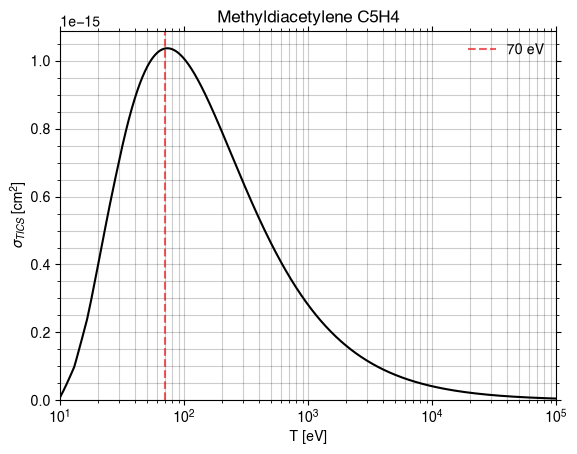

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(8254)
Recherche : 'Dimethyl ether' -> CID 8254, formule C2H6O


Loading output/xyz/Dimethyl_ether_C2H6O.xyzBuilt graph: 9 atoms, 8 bondsLoading output/xyz/Dimethyl_ether_C2H6O.xyzBuilt graph: 9 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Dimethyl_ether_C2H6O.gifGIF written to output/gif/Dimethyl_ether_C2H6O.gif

strucutre 3D
Réussite. Nom: Dimethyl ether, formule: C2H6O, M: 46.07, nom_marche: Dimethyl_ether
PYSCF CONVERGENCE
converged SCF energy = -154.132069332597
**** MO energy ****
MO #1   energy= -20.5539611013866  occ= 2
MO #2   energy= -11.2688149645505  occ= 2
MO #3   energy= -11.2687814679748  occ= 2
MO #4   energy= -1.36457170434591  occ= 2
MO #5   energy= -0.965175706689148 occ= 2
MO #6   energy= -0.874852909189816 occ= 2
MO #7   energy= -0.658851680170753 occ= 2
MO #8   energy= -0.646022598870352 occ= 2
MO #9   energy= -0.632471382155561 occ= 2
MO #10  energy= -0.554350880810436 occ= 2
MO #11  energy= -0.525979604315339 occ= 2
MO #12  energy= -0.478808028205371 occ= 2
MO #13  energy= -0.425900672461278 occ= 2
MO #14  energy= 0.0699729687940238 occ= 0
MO #15  energy= 0.0888713126533765 occ= 0
MO #16  energy= 0.112495277432021  occ= 0
MO #17  energy= 0.115679191040178  occ= 0
MO #18  energy= 0.148082938327576  occ= 0
MO #19  energy= 0.149694825152521  occ= 0
MO #20  energy= 0.16739610

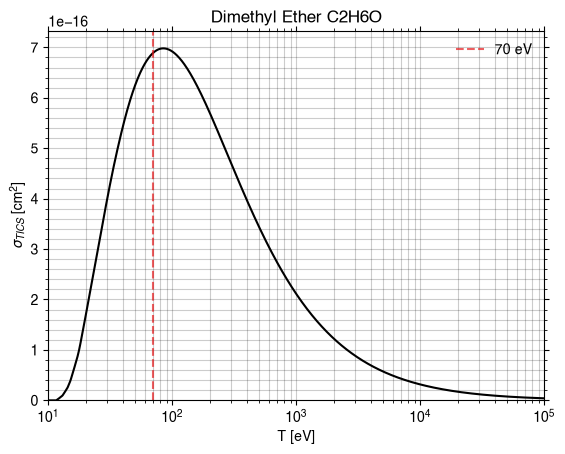

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(178)
Recherche : 'Acetamide' -> CID 178, formule C2H5NO


Loading output/xyz/Acetamide_C2H5NO.xyzBuilt graph: 9 atoms, 8 bondsLoading output/xyz/Acetamide_C2H5NO.xyzBuilt graph: 9 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Acetamide_C2H5NO.gifGIF written to output/gif/Acetamide_C2H5NO.gif

strucutre 3D
Réussite. Nom: Acetamide, formule: C2H5NO, M: 59.07, nom_marche: Acetamide
PYSCF CONVERGENCE
converged SCF energy = -208.066316959794
**** MO energy ****
MO #1   energy= -20.517431727805   occ= 2
MO #2   energy= -15.5899387221377  occ= 2
MO #3   energy= -11.3565618845662  occ= 2
MO #4   energy= -11.2383223330083  occ= 2
MO #5   energy= -1.3714356216859   occ= 2
MO #6   energy= -1.20943678923845  occ= 2
MO #7   energy= -1.00604031931737  occ= 2
MO #8   energy= -0.80086918339012  occ= 2
MO #9   energy= -0.718514952222126 occ= 2
MO #10  energy= -0.664512795239684 occ= 2
MO #11  energy= -0.617133222357918 occ= 2
MO #12  energy= -0.585250342211229 occ= 2
MO #13  energy= -0.558801377082982 occ= 2
MO #14  energy= -0.523234332367849 occ= 2
MO #15  energy= -0.425439610960725 occ= 2
MO #16  energy= -0.416183755687627 occ= 2
MO #17  energy= 0.0618466367515325 occ= 0
MO #18  energy= 0.0910947096559247 occ= 0
MO #19  energy= 0.101024901317321  occ= 0
MO #20  energy= 0.119827942083781  

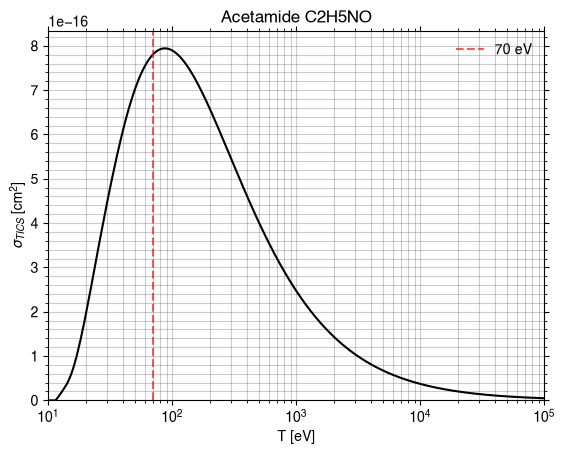

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(702)
Recherche : 'Ethanol' -> CID 702, formule C2H6O


Loading output/xyz/Ethanol_C2H6O.xyzBuilt graph: 9 atoms, 8 bondsLoading output/xyz/Ethanol_C2H6O.xyzBuilt graph: 9 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ethanol_C2H6O.gifGIF written to output/gif/Ethanol_C2H6O.gif

strucutre 3D
Réussite. Nom: Ethanol, formule: C2H6O, M: 46.07, nom_marche: Ethanol
PYSCF CONVERGENCE
converged SCF energy = -154.147907925879
**** MO energy ****
MO #1   energy= -20.552365660589   occ= 2
MO #2   energy= -11.2735331583151  occ= 2
MO #3   energy= -11.2172467125988  occ= 2
MO #4   energy= -1.3550640774976   occ= 2
MO #5   energy= -1.01086779537026  occ= 2
MO #6   energy= -0.846273458206383 occ= 2
MO #7   energy= -0.685407543794131 occ= 2
MO #8   energy= -0.626131590194845 occ= 2
MO #9   energy= -0.606696348569911 occ= 2
MO #10  energy= -0.542572850050363 occ= 2
MO #11  energy= -0.526909975087257 occ= 2
MO #12  energy= -0.480772979044552 occ= 2
MO #13  energy= -0.442297626298579 occ= 2
MO #14  energy= 0.0690650298027045 occ= 0
MO #15  energy= 0.0935800163364669 occ= 0
MO #16  energy= 0.0967496476535146 occ= 0
MO #17  energy= 0.112282760365472  occ= 0
MO #18  energy= 0.139718968074721  occ= 0
MO #19  energy= 0.152605675647145  occ= 0
MO #20  energy= 0.163669943478797  occ= 

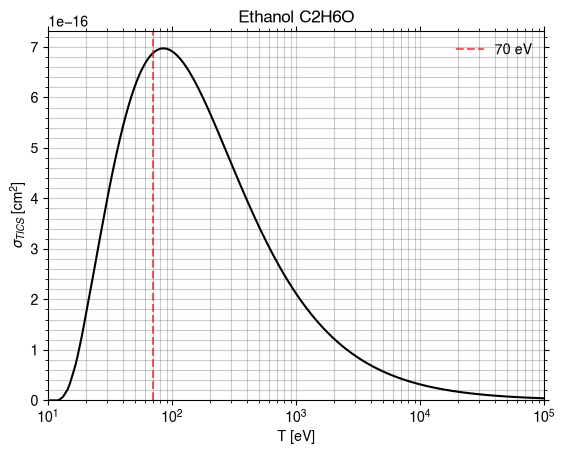

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Cyanotriacetylene not found : IndexError : list index out of range
Cyanotriacetylene a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(6343)
Recherche : 'Ethyl mercaptan' -> CID 6343, formule C2H6S


Loading output/xyz/Ethyl_mercaptan_C2H6S.xyzBuilt graph: 9 atoms, 8 bondsLoading output/xyz/Ethyl_mercaptan_C2H6S.xyzBuilt graph: 9 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ethyl_mercaptan_C2H6S.gifGIF written to output/gif/Ethyl_mercaptan_C2H6S.gif

strucutre 3D
Réussite. Nom: Ethyl mercaptan, formule: C2H6S, M: 62.14, nom_marche: Ethyl_mercaptan
PYSCF CONVERGENCE
converged SCF energy = -89.2246759738126
**** MO energy ****
MO #1   energy= -11.2607056516339  occ= 2
MO #2   energy= -11.2275910885491  occ= 2
MO #3   energy= -1.07378978334787  occ= 2
MO #4   energy= -0.946985361284025 occ= 2
MO #5   energy= -0.815909194973045 occ= 2
MO #6   energy= -0.630924886520069 occ= 2
MO #7   energy= -0.616732867211137 occ= 2
MO #8   energy= -0.541827284812936 occ= 2
MO #9   energy= -0.513714240535526 occ= 2
MO #10  energy= -0.502773523709962 occ= 2
MO #11  energy= -0.449002710451008 occ= 2
MO #12  energy= -0.352805565619835 occ= 2
MO #13  energy= 0.0697382538757608 occ= 0
MO #14  energy= 0.0839633729625578 occ= 0
MO #15  energy= 0.0892098625462046 occ= 0
MO #16  energy= 0.101841136977679  occ= 0
MO #17  energy= 0.117011005610185  occ= 0
MO #18  energy= 0.143918372490252  occ= 0
MO #19  energy= 0.157590133238613  occ= 0
MO #20  energy= 0.164865

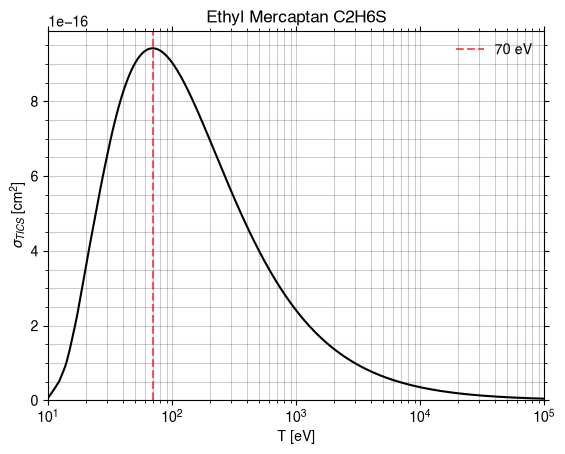

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(1068)
Recherche : 'Dimethyl sulfide' -> CID 1068, formule C2H6S


Loading output/xyz/Dimethyl_sulfide_C2H6S.xyzBuilt graph: 9 atoms, 8 bondsLoading output/xyz/Dimethyl_sulfide_C2H6S.xyzBuilt graph: 9 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Dimethyl_sulfide_C2H6S.gifGIF written to output/gif/Dimethyl_sulfide_C2H6S.gif

strucutre 3D
Réussite. Nom: Dimethyl sulfide, formule: C2H6S, M: 62.14, nom_marche: Dimethyl_sulfide
PYSCF CONVERGENCE
converged SCF energy = -89.2218480732991
**** MO energy ****
MO #1   energy= -11.2507414013864  occ= 2
MO #2   energy= -11.2507295953987  occ= 2
MO #3   energy= -1.06260780144348  occ= 2
MO #4   energy= -0.949342260037231 occ= 2
MO #5   energy= -0.809007928399179 occ= 2
MO #6   energy= -0.603982194693144 occ= 2
MO #7   energy= -0.601394460576571 occ= 2
MO #8   energy= -0.573077358622688 occ= 2
MO #9   energy= -0.563243944109403 occ= 2
MO #10  energy= -0.497318966277842 occ= 2
MO #11  energy= -0.43345697345811  occ= 2
MO #12  energy= -0.334076954507513 occ= 2
MO #13  energy= 0.0746434603536291 occ= 0
MO #14  energy= 0.0838067333433766 occ= 0
MO #15  energy= 0.0942518438822569 occ= 0
MO #16  energy= 0.102909908920914  occ= 0
MO #17  energy= 0.11789735284803   occ= 0
MO #18  energy= 0.148136494647304  occ= 0
MO #19  energy= 0.163801444898018  occ= 0
MO #20  energy= 0.1802

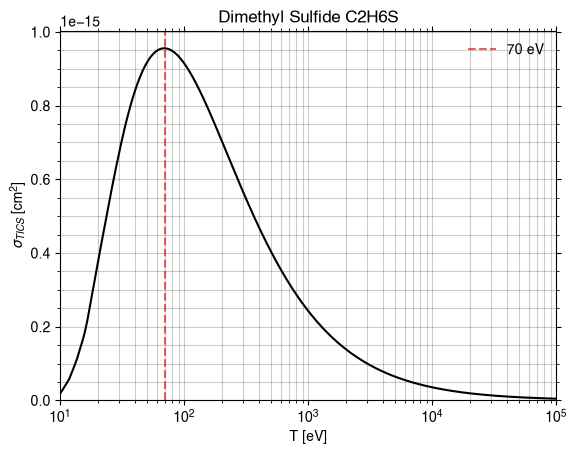

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/N-methylformamide_C2H5NO.xyzBuilt graph: 9 atoms, 8 bondsLoading output/xyz/N-methylformamide_C2H5NO.xyzBuilt graph: 9 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

Compound(31254)
Recherche : 'N-methylformamide' -> CID 31254, formule C2H5NO
3D


  frame 120/120
Wrote output/gif/N-methylformamide_C2H5NO.gifGIF written to output/gif/N-methylformamide_C2H5NO.gif

strucutre 3D
Réussite. Nom: N-methylformamide, formule: C2H5NO, M: 59.07, nom_marche: N-methylformamide
PYSCF CONVERGENCE
converged SCF energy = -208.047727160523
**** MO energy ****
MO #1   energy= -20.5262838354235  occ= 2
MO #2   energy= -15.5962361330948  occ= 2
MO #3   energy= -11.3536037033655  occ= 2
MO #4   energy= -11.2653932876548  occ= 2
MO #5   energy= -1.37452676306841  occ= 2
MO #6   energy= -1.23484127324568  occ= 2
MO #7   energy= -0.966546177337012 occ= 2
MO #8   energy= -0.808980349286522 occ= 2
MO #9   energy= -0.739090087774851 occ= 2
MO #10  energy= -0.642933212519522 occ= 2
MO #11  energy= -0.628304083171321 occ= 2
MO #12  energy= -0.593661028847752 occ= 2
MO #13  energy= -0.556671755995065 occ= 2
MO #14  energy= -0.535181584171021 occ= 2
MO #15  energy= -0.432071131635652 occ= 2
MO #16  energy= -0.396476346864922 occ= 2
MO #17  energy= 0.0602188195750131 occ= 0
MO #18  energy= 0.0856553180920077 occ= 0
MO #19  energy= 0.100378714660944  occ= 0
MO #20  energy= 0.1

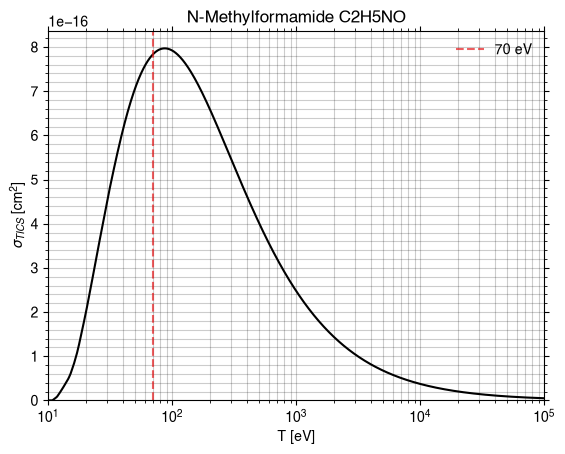

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(180)
Recherche : 'Acetone' -> CID 180, formule C3H6O


Loading output/xyz/Acetone_C3H6O.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Acetone_C3H6O.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Acetone_C3H6O.gifGIF written to output/gif/Acetone_C3H6O.gif

strucutre 3D
Réussite. Nom: Acetone, formule: C3H6O, M: 58.08, nom_marche: Acetone
PYSCF CONVERGENCE
converged SCF energy = -192.039334875647
**** MO energy ****
MO #1   energy= -20.5427870144904  occ= 2
MO #2   energy= -11.3329684315501  occ= 2
MO #3   energy= -11.2361158136815  occ= 2
MO #4   energy= -11.2360818838982  occ= 2
MO #5   energy= -1.37328817552152  occ= 2
MO #6   energy= -1.04611776971939  occ= 2
MO #7   energy= -0.969240536267627 occ= 2
MO #8   energy= -0.740907887416274 occ= 2
MO #9   energy= -0.640534455420484 occ= 2
MO #10  energy= -0.634868177684048 occ= 2
MO #11  energy= -0.629485673176311 occ= 2
MO #12  energy= -0.568191426671304 occ= 2
MO #13  energy= -0.555690875125824 occ= 2
MO #14  energy= -0.534146759701628 occ= 2
MO #15  energy= -0.483660909660635 occ= 2
MO #16  energy= -0.416106115890319 occ= 2
MO #17  energy= 0.0641327591569443 occ= 0
MO #18  energy= 0.0907638808838058 occ= 0
MO #19  energy= 0.0963089915155799 occ= 0
MO #20  energy= 0.108989757295854  occ= 

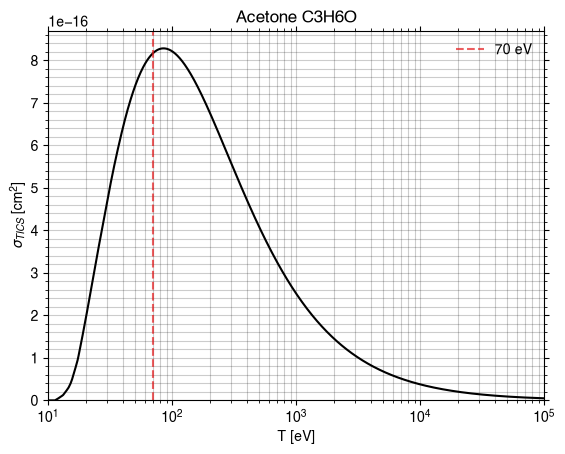

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(174)
Recherche : 'Ethylene glycol' -> CID 174, formule C2H6O2


Loading output/xyz/Ethylene_glycol_C2H6O2.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Ethylene_glycol_C2H6O2.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ethylene_glycol_C2H6O2.gifGIF written to output/gif/Ethylene_glycol_C2H6O2.gif

strucutre 3D
Réussite. Nom: Ethylene glycol, formule: C2H6O2, M: 62.07, nom_marche: Ethylene_glycol
PYSCF CONVERGENCE
converged SCF energy = -229.034868756529
**** MO energy ****
MO #1   energy= -20.5686286685611  occ= 2
MO #2   energy= -20.553259076491   occ= 2
MO #3   energy= -11.2809639879879  occ= 2
MO #4   energy= -11.2801603922307  occ= 2
MO #5   energy= -1.37902985893888  occ= 2
MO #6   energy= -1.34654433475345  occ= 2
MO #7   energy= -0.99974447304778  occ= 2
MO #8   energy= -0.852871822700486 occ= 2
MO #9   energy= -0.708751907018534 occ= 2
MO #10  energy= -0.682429422358613 occ= 2
MO #11  energy= -0.649474383228714 occ= 2
MO #12  energy= -0.620273587390269 occ= 2
MO #13  energy= -0.575555575310585 occ= 2
MO #14  energy= -0.525215337940821 occ= 2
MO #15  energy= -0.502995486850288 occ= 2
MO #16  energy= -0.474042800635086 occ= 2
MO #17  energy= -0.436913223863506 occ= 2
MO #18  energy= 0.0610755643508725 occ= 0
MO #19  energy= 0.0867047139283721 occ= 0
MO #20  energy= 0.08873

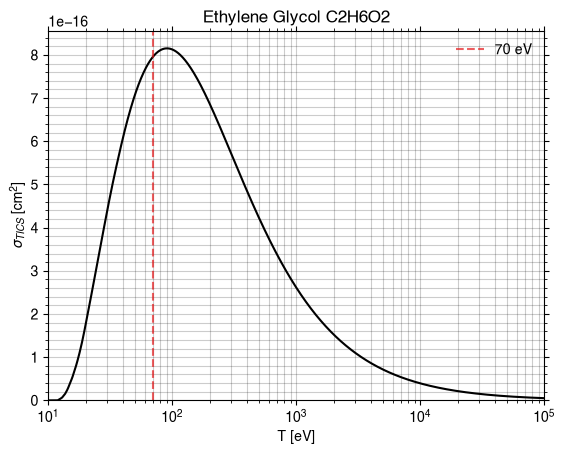

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(527)
Recherche : 'Propanal' -> CID 527, formule C3H6O


Loading output/xyz/Propanal_C3H6O.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Propanal_C3H6O.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Propanal_C3H6O.gifGIF written to output/gif/Propanal_C3H6O.gif

strucutre 3D
Réussite. Nom: Propanal, formule: C3H6O, M: 58.08, nom_marche: Propanal
PYSCF CONVERGENCE
converged SCF energy = -192.028346887995
**** MO energy ****
MO #1   energy= -20.557829606219   occ= 2
MO #2   energy= -11.3347201266002  occ= 2
MO #3   energy= -11.2456822910052  occ= 2
MO #4   energy= -11.2211533812694  occ= 2
MO #5   energy= -1.38201700434652  occ= 2
MO #6   energy= -1.0637662500954   occ= 2
MO #7   energy= -0.909376888262162 occ= 2
MO #8   energy= -0.775138369070458 occ= 2
MO #9   energy= -0.678801512722419 occ= 2
MO #10  energy= -0.639150721509064 occ= 2
MO #11  energy= -0.626572563955112 occ= 2
MO #12  energy= -0.538435730889271 occ= 2
MO #13  energy= -0.524511485738801 occ= 2
MO #14  energy= -0.517513604262832 occ= 2
MO #15  energy= -0.492130896222111 occ= 2
MO #16  energy= -0.424648397610319 occ= 2
MO #17  energy= 0.06625552688194   occ= 0
MO #18  energy= 0.0859033847919202 occ= 0
MO #19  energy= 0.0891770521419186 occ= 0
MO #20  energy= 0.112980167173433  occ

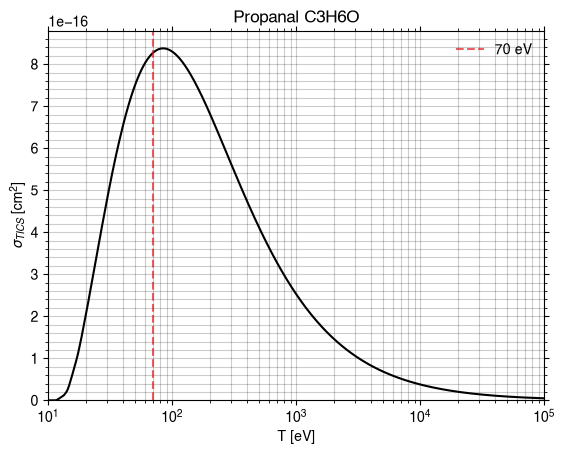

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(62540)
Recherche : 'Methoxymethanol' -> CID 62540, formule C2H6O2


Loading output/xyz/Methoxymethanol_C2H6O2.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Methoxymethanol_C2H6O2.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methoxymethanol_C2H6O2.gifGIF written to output/gif/Methoxymethanol_C2H6O2.gif

strucutre 3D
Réussite. Nom: Methoxymethanol, formule: C2H6O2, M: 62.07, nom_marche: Methoxymethanol
PYSCF CONVERGENCE
converged SCF energy = -229.027195673523
**** MO energy ****
MO #1   energy= -20.5718222561847  occ= 2
MO #2   energy= -20.5641882363384  occ= 2
MO #3   energy= -11.3343536426492  occ= 2
MO #4   energy= -11.2756893455192  occ= 2
MO #5   energy= -1.40517460900736  occ= 2
MO #6   energy= -1.33826392506338  occ= 2
MO #7   energy= -0.966270466864422 occ= 2
MO #8   energy= -0.869744187847626 occ= 2
MO #9   energy= -0.723697172636797 occ= 2
MO #10  energy= -0.677905248528285 occ= 2
MO #11  energy= -0.658733147590453 occ= 2
MO #12  energy= -0.622041713903297 occ= 2
MO #13  energy= -0.569596577818608 occ= 2
MO #14  energy= -0.526461946709542 occ= 2
MO #15  energy= -0.503601601920707 occ= 2
MO #16  energy= -0.475021784177578 occ= 2
MO #17  energy= -0.443752305008729 occ= 2
MO #18  energy= 0.0615473438246639 occ= 0
MO #19  energy= 0.0857351670213159 occ= 0
MO #20  energy= 0.08952

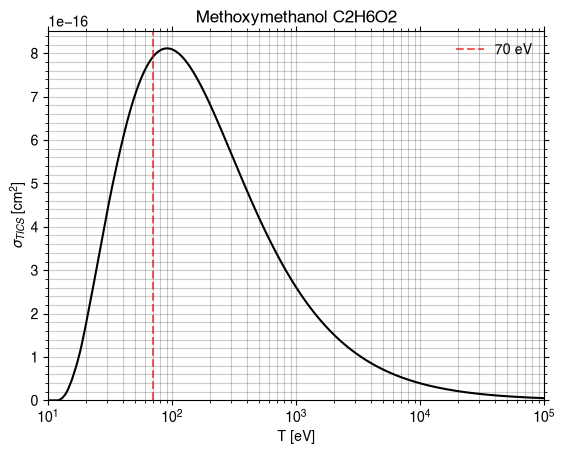

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Methylcyanodiacetylene not found : IndexError : list index out of range
Methylcyanodiacetylene a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(6378)
Recherche : 'Propylene oxide' -> CID 6378, formule C3H6O


Loading output/xyz/Propylene_oxide_C3H6O.xyzBuilt graph: 10 atoms, 10 bondsLoading output/xyz/Propylene_oxide_C3H6O.xyzBuilt graph: 10 atoms, 10 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Propylene_oxide_C3H6O.gifGIF written to output/gif/Propylene_oxide_C3H6O.gif

strucutre 3D
Réussite. Nom: Propylene oxide, formule: C3H6O, M: 58.08, nom_marche: Propylene_oxide
PYSCF CONVERGENCE
converged SCF energy = -191.986034438993
**** MO energy ****
MO #1   energy= -20.568766071996   occ= 2
MO #2   energy= -11.2869734174265  occ= 2
MO #3   energy= -11.2801754563392  occ= 2
MO #4   energy= -11.2228816911235  occ= 2
MO #5   energy= -1.40948835386044  occ= 2
MO #6   energy= -1.00775933237513  occ= 2
MO #7   energy= -0.908693201202933 occ= 2
MO #8   energy= -0.815045653085591 occ= 2
MO #9   energy= -0.695608940792244 occ= 2
MO #10  energy= -0.645898890416909 occ= 2
MO #11  energy= -0.58914803952015  occ= 2
MO #12  energy= -0.560853644197085 occ= 2
MO #13  energy= -0.523431437605988 occ= 2
MO #14  energy= -0.52221200208547  occ= 2
MO #15  energy= -0.447519514798682 occ= 2
MO #16  energy= -0.425550187951618 occ= 2
MO #17  energy= 0.0723356636120773 occ= 0
MO #18  energy= 0.089862215112265  occ= 0
MO #19  energy= 0.0928334007533697 occ= 0
MO #20  energy= 0.108697

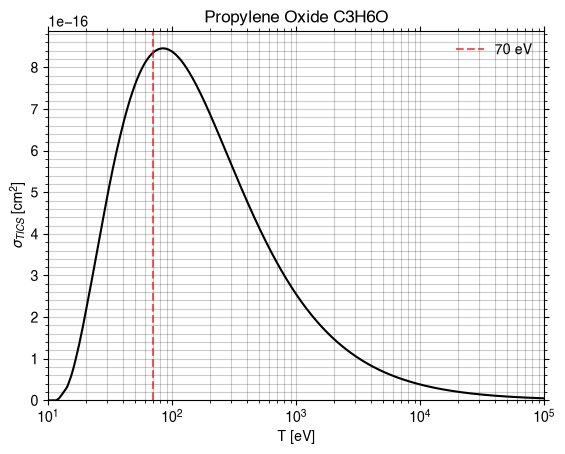

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(700)
Recherche : 'Ethanolamine' -> CID 700, formule C2H7NO


Loading output/xyz/Ethanolamine_C2H7NO.xyzBuilt graph: 11 atoms, 10 bondsLoading output/xyz/Ethanolamine_C2H7NO.xyzBuilt graph: 11 atoms, 10 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ethanolamine_C2H7NO.gifGIF written to output/gif/Ethanolamine_C2H7NO.gif

strucutre 3D
Réussite. Nom: Ethanolamine, formule: C2H7NO, M: 61.08, nom_marche: Ethanolamine
PYSCF CONVERGENCE
converged SCF energy = -209.194530993341
**** MO energy ****
MO #1   energy= -20.5558173204864  occ= 2
MO #2   energy= -15.5427246633809  occ= 2
MO #3   energy= -11.2730099869379  occ= 2
MO #4   energy= -11.246166274423   occ= 2
MO #5   energy= -1.35708237120111  occ= 2
MO #6   energy= -1.18151068414556  occ= 2
MO #7   energy= -0.970951218910653 occ= 2
MO #8   energy= -0.823481474414415 occ= 2
MO #9   energy= -0.694225784497188 occ= 2
MO #10  energy= -0.670580529925974 occ= 2
MO #11  energy= -0.642824489945518 occ= 2
MO #12  energy= -0.586631864158772 occ= 2
MO #13  energy= -0.554941896973547 occ= 2
MO #14  energy= -0.53639040973024  occ= 2
MO #15  energy= -0.48656122265778  occ= 2
MO #16  energy= -0.444698742343537 occ= 2
MO #17  energy= -0.392792959767448 occ= 2
MO #18  energy= 0.0669965989457098 occ= 0
MO #19  energy= 0.0802351262559192 occ= 0
MO #20  energy= 0.09762525855

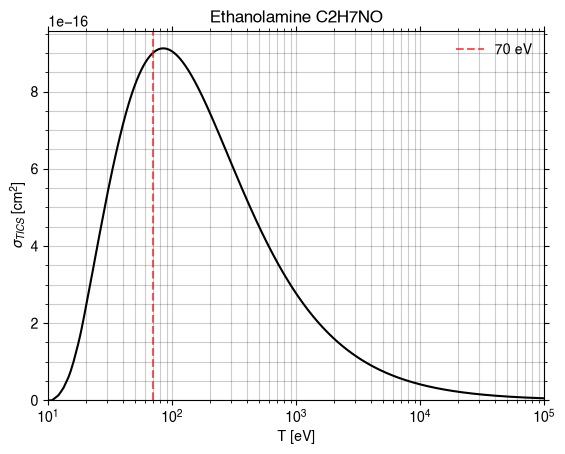

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Cyanotetraacetylene not found : IndexError : list index out of range
Cyanotetraacetylene a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(8025)
Recherche : 'Ethyl formate' -> CID 8025, formule C3H6O2


Loading output/xyz/Ethyl_formate_C3H6O2.xyzBuilt graph: 11 atoms, 10 bondsLoading output/xyz/Ethyl_formate_C3H6O2.xyzBuilt graph: 11 atoms, 10 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ethyl_formate_C3H6O2.gifGIF written to output/gif/Ethyl_formate_C3H6O2.gif

strucutre 3D
Réussite. Nom: Ethyl formate, formule: C3H6O2, M: 74.08, nom_marche: Ethyl_formate
PYSCF CONVERGENCE
converged SCF energy = -266.936101772057
**** MO energy ****
MO #1   energy= -20.6145206825329  occ= 2
MO #2   energy= -20.5613156136052  occ= 2
MO #3   energy= -11.3922048645853  occ= 2
MO #4   energy= -11.2924016413445  occ= 2
MO #5   energy= -11.228111618016   occ= 2
MO #6   energy= -1.45969456333215  occ= 2
MO #7   energy= -1.36664672236141  occ= 2
MO #8   energy= -1.04662785306807  occ= 2
MO #9   energy= -0.898689407711821 occ= 2
MO #10  energy= -0.808322440116392 occ= 2
MO #11  energy= -0.72811304989871  occ= 2
MO #12  energy= -0.687750103747908 occ= 2
MO #13  energy= -0.680337486330266 occ= 2
MO #14  energy= -0.58360638779322  occ= 2
MO #15  energy= -0.582439151349728 occ= 2
MO #16  energy= -0.558858594369909 occ= 2
MO #17  energy= -0.513730086234175 occ= 2
MO #18  energy= -0.511963645456413 occ= 2
MO #19  energy= -0.464764085215474 occ= 2
MO #20  energy= -0.46424749

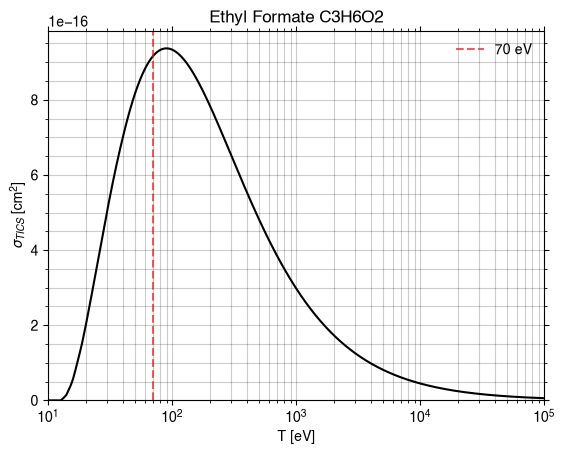

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6584)
Recherche : 'Methyl acetate' -> CID 6584, formule C3H6O2


Loading output/xyz/Methyl_acetate_C3H6O2.xyzBuilt graph: 11 atoms, 10 bondsLoading output/xyz/Methyl_acetate_C3H6O2.xyzBuilt graph: 11 atoms, 10 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methyl_acetate_C3H6O2.gifGIF written to output/gif/Methyl_acetate_C3H6O2.gif

strucutre 3D
Réussite. Nom: Methyl acetate, formule: C3H6O2, M: 74.08, nom_marche: Methyl_acetate
PYSCF CONVERGENCE
converged SCF energy = -266.943724472031
**** MO energy ****
MO #1   energy= -20.6076832845927  occ= 2
MO #2   energy= -20.5470622949997  occ= 2
MO #3   energy= -11.3854233626906  occ= 2
MO #4   energy= -11.2874823211442  occ= 2
MO #5   energy= -11.2398700083784  occ= 2
MO #6   energy= -1.45234058114647  occ= 2
MO #7   energy= -1.35593306062259  occ= 2
MO #8   energy= -1.03485780452406  occ= 2
MO #9   energy= -0.946190706097283 occ= 2
MO #10  energy= -0.779298410952975 occ= 2
MO #11  energy= -0.690065528724228 occ= 2
MO #12  energy= -0.677353462826802 occ= 2
MO #13  energy= -0.676842389956049 occ= 2
MO #14  energy= -0.598619642963521 occ= 2
MO #15  energy= -0.588700428548131 occ= 2
MO #16  energy= -0.555069064689992 occ= 2
MO #17  energy= -0.526676250988752 occ= 2
MO #18  energy= -0.523006042108916 occ= 2
MO #19  energy= -0.46477597888405  occ= 2
MO #20  energy= -0.450396

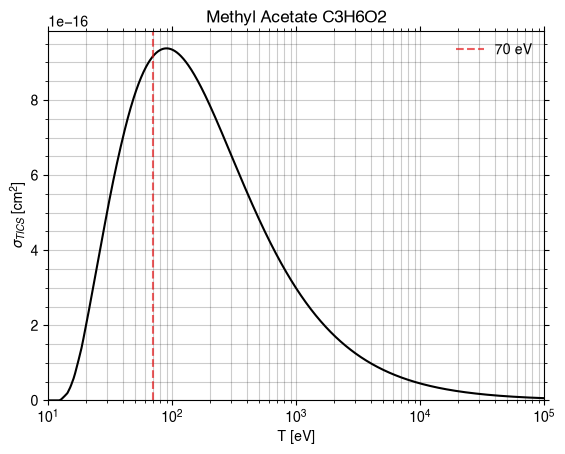

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Methyltriacetylene not found : IndexError : list index out of range
Methyltriacetylene a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(8008)
Recherche : 'n-Propyl cyanide' -> CID 8008, formule C4H7N


Loading output/xyz/n-Propyl_cyanide_C4H7N.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/n-Propyl_cyanide_C4H7N.xyzBuilt graph: 12 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/n-Propyl_cyanide_C4H7N.gifGIF written to output/gif/n-Propyl_cyanide_C4H7N.gif

strucutre 3D
Réussite. Nom: n-Propyl cyanide, formule: C4H7N, M: 69.11, nom_marche: n-Propyl_cyanide
PYSCF CONVERGENCE
converged SCF energy = -210.075098038817
**** MO energy ****
MO #1   energy= -15.5681390744893  occ= 2
MO #2   energy= -11.2831728674614  occ= 2
MO #3   energy= -11.2731502928598  occ= 2
MO #4   energy= -11.2509573294415  occ= 2
MO #5   energy= -11.2344275510448  occ= 2
MO #6   energy= -1.2143909276643   occ= 2
MO #7   energy= -1.10331324609104  occ= 2
MO #8   energy= -0.986260556223947 occ= 2
MO #9   energy= -0.843077547453575 occ= 2
MO #10  energy= -0.706123579351901 occ= 2
MO #11  energy= -0.672847138075598 occ= 2
MO #12  energy= -0.606252692292318 occ= 2
MO #13  energy= -0.584151183465013 occ= 2
MO #14  energy= -0.562919239814456 occ= 2
MO #15  energy= -0.530052775404457 occ= 2
MO #16  energy= -0.517486776673643 occ= 2
MO #17  energy= -0.504870052286872 occ= 2
MO #18  energy= -0.455341534933773 occ= 2
MO #19  energy= -0.452139324431293 occ= 2
MO #20  energy= 0.0619

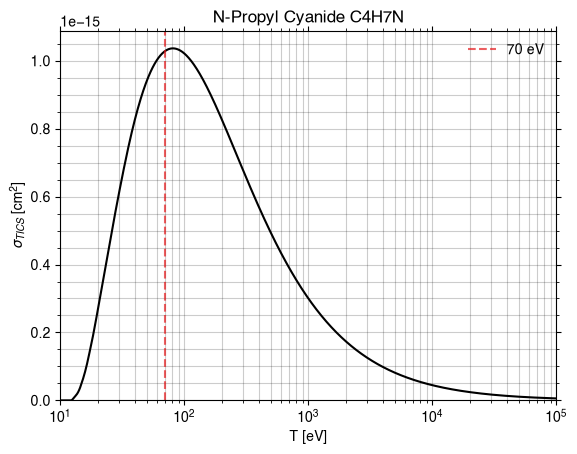

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

iso-Propyl cyanide not found : IndexError : list index out of range
iso-Propyl cyanide a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(8019)
Recherche : '2-methoxyethanol' -> CID 8019, formule C3H8O2


Loading output/xyz/2-methoxyethanol_C3H8O2.xyzBuilt graph: 13 atoms, 12 bondsLoading output/xyz/2-methoxyethanol_C3H8O2.xyzBuilt graph: 13 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/2-methoxyethanol_C3H8O2.gifGIF written to output/gif/2-methoxyethanol_C3H8O2.gif

strucutre 3D
Réussite. Nom: 2-methoxyethanol, formule: C3H8O2, M: 76.09, nom_marche: 2-methoxyethanol
PYSCF CONVERGENCE
converged SCF energy = -268.070614276265
**** MO energy ****
MO #1   energy= -20.5610480212797  occ= 2
MO #2   energy= -20.5602879360608  occ= 2
MO #3   energy= -11.2777839468571  occ= 2
MO #4   energy= -11.2750013974418  occ= 2
MO #5   energy= -11.2744426611883  occ= 2
MO #6   energy= -1.3767683945055   occ= 2
MO #7   energy= -1.3582378165953   occ= 2
MO #8   energy= -1.01301574504297  occ= 2
MO #9   energy= -0.911905101856732 occ= 2
MO #10  energy= -0.843519807117204 occ= 2
MO #11  energy= -0.701958197629516 occ= 2
MO #12  energy= -0.668353977683106 occ= 2
MO #13  energy= -0.656894339324618 occ= 2
MO #14  energy= -0.632936915412696 occ= 2
MO #15  energy= -0.593989872164759 occ= 2
MO #16  energy= -0.572618528087759 occ= 2
MO #17  energy= -0.545687944771512 occ= 2
MO #18  energy= -0.493633922196214 occ= 2
MO #19  energy= -0.485527808366549 occ= 2
MO #20  energy= -0.44

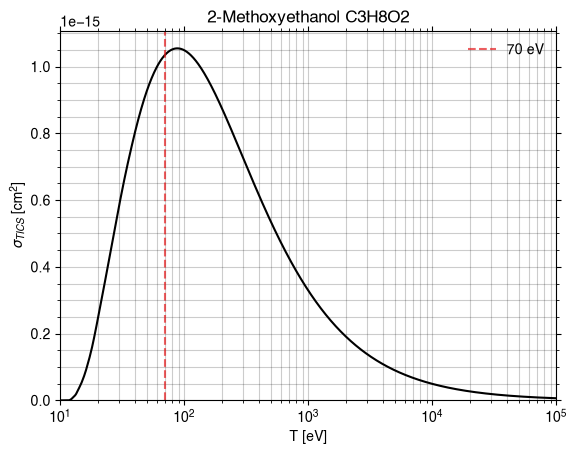

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(7505)
Recherche : 'Benzonitrile' -> CID 7505, formule C7H5N


Loading output/xyz/Benzonitrile_C7H5N.xyzBuilt graph: 13 atoms, 13 bondsLoading output/xyz/Benzonitrile_C7H5N.xyzBuilt graph: 13 atoms, 13 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Benzonitrile_C7H5N.gifGIF written to output/gif/Benzonitrile_C7H5N.gif

strucutre 3D
Réussite. Nom: Benzonitrile, formule: C7H5N, M: 103.12, nom_marche: Benzonitrile
PYSCF CONVERGENCE

WARN: 2 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -322.54980215812
**** MO energy ****
MO #1   energy= -15.5747679719584  occ= 2
MO #2   energy= -11.2902350246373  occ= 2
MO #3   energy= -11.2784334149068  occ= 2
MO #4   energy= -11.2722116323692  occ= 2
MO #5   energy= -11.2721566037473  occ= 2
MO #6   energy= -11.267124473137   occ= 2
MO #7   energy= -11.2621735198063  occ= 2
MO #8   energy= -11.2620150390097  occ= 2
MO #9   energy= -1.22325815709419  occ= 2
MO #10  energy= -1.18257973217555  occ= 2
MO #11  energy= -1.06420701752001  occ= 2
MO #12  energy= -1.04603505239271  occ= 2
MO #13  energy= -0.888120525455308 occ= 2
MO #14  energy= -0.85906163146274  occ= 2
MO #15  energy= -0.767189251618767 occ= 2
MO #16  energy= -0.698376892162166 occ= 2
MO #17  energy= -0.662535968901356 occ= 2
MO #18  energy= 

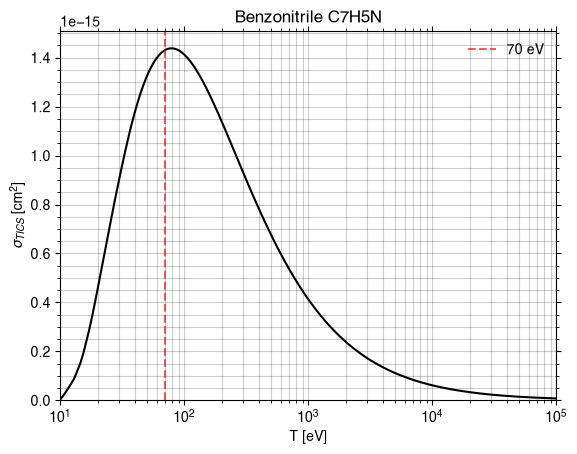

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Cyanopentaacetylene not found : IndexError : list index out of range
Cyanopentaacetylene a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(7219)
Recherche : 'Indene' -> CID 7219, formule C9H8


Loading output/xyz/Indene_C9H8.xyzBuilt graph: 17 atoms, 18 bondsLoading output/xyz/Indene_C9H8.xyzBuilt graph: 17 atoms, 18 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Indene_C9H8.gifGIF written to output/gif/Indene_C9H8.gif

strucutre 3D
Réussite. Nom: Indene, formule: C9H8, M: 116.16, nom_marche: Indene
PYSCF CONVERGENCE

WARN: 3 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -345.582587302312
**** MO energy ****
MO #1   energy= -11.2342851331047  occ= 2
MO #2   energy= -11.2325927418547  occ= 2
MO #3   energy= -11.2307448009171  occ= 2
MO #4   energy= -11.2303001710667  occ= 2
MO #5   energy= -11.2301124587572  occ= 2
MO #6   energy= -11.2289708747461  occ= 2
MO #7   energy= -11.2284190996577  occ= 2
MO #8   energy= -11.2283435457212  occ= 2
MO #9   energy= -11.2274742169466  occ= 2
MO #10  energy= -1.18141624306591  occ= 2
MO #11  energy= -1.09922496596639  occ= 2
MO #12  energy= -1.02853488448389  occ= 2
MO #13  energy= -0.970218439243524 occ= 2
MO #14  energy= -0.943863481386824 occ= 2
MO #15  energy= -0.825796391603685 occ= 2
MO #16  energy= -0.789638924729015 occ= 2
MO #17  energy= -0.758215691376105 occ= 2
MO #18  energy= -0.691028787

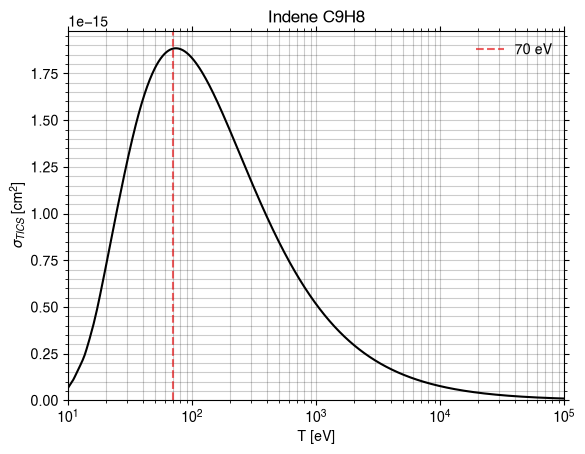

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6846)
Recherche : '1-cyanonaphthalene' -> CID 6846, formule C11H7N


Loading output/xyz/1-cyanonaphthalene_C11H7N.xyzBuilt graph: 19 atoms, 20 bondsLoading output/xyz/1-cyanonaphthalene_C11H7N.xyzBuilt graph: 19 atoms, 20 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/1-cyanonaphthalene_C11H7N.gifGIF written to output/gif/1-cyanonaphthalene_C11H7N.gif

strucutre 3D
Réussite. Nom: 1-cyanonaphthalene, formule: C11H7N, M: 153.18, nom_marche: 1-cyanonaphthalene
PYSCF CONVERGENCE

WARN: 6 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -475.24663117422
**** MO energy ****
MO #1   energy= -15.5702088528766  occ= 2
MO #2   energy= -11.2864682296736  occ= 2
MO #3   energy= -11.2751236953843  occ= 2
MO #4   energy= -11.2718710248968  occ= 2
MO #5   energy= -11.2705974362733  occ= 2
MO #6   energy= -11.2683625668674  occ= 2
MO #7   energy= -11.2636392547768  occ= 2
MO #8   energy= -11.257800804329   occ= 2
MO #9   energy= -11.2568855077638  occ= 2
MO #10  energy= -11.2540188700479  occ= 2
MO #11  energy= -11.2522038723319  occ= 2
MO #12  energy= -11.2517616467084  occ= 2
MO #13  energy= -1.22711952299652  occ= 2
MO #14  energy= -1.20162225186419  occ= 2
MO #15  energy= -1.13490069254091  occ= 2
MO #16  energy= -1.0845738060285   occ= 2
MO #17  energy= -1.03861526994027  occ= 2
MO 

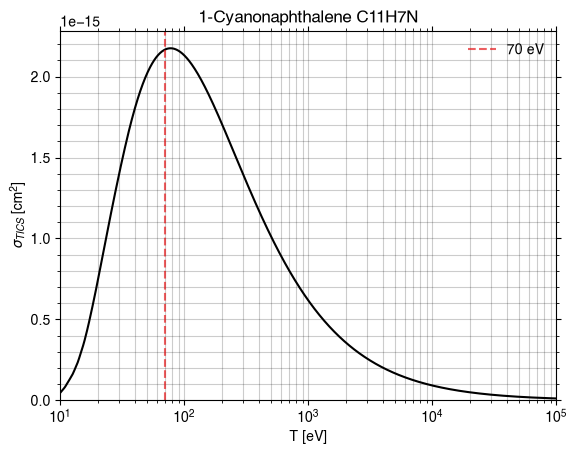

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(11944)
Recherche : '2-cyanonaphthalene' -> CID 11944, formule C11H7N


Loading output/xyz/2-cyanonaphthalene_C11H7N.xyzBuilt graph: 19 atoms, 20 bondsLoading output/xyz/2-cyanonaphthalene_C11H7N.xyzBuilt graph: 19 atoms, 20 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/2-cyanonaphthalene_C11H7N.gifGIF written to output/gif/2-cyanonaphthalene_C11H7N.gif

strucutre 3D
Réussite. Nom: 2-cyanonaphthalene, formule: C11H7N, M: 153.18, nom_marche: 2-cyanonaphthalene
PYSCF CONVERGENCE

WARN: 6 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -475.246368919109
**** MO energy ****
MO #1   energy= -15.5730173940018  occ= 2
MO #2   energy= -11.2876202405795  occ= 2
MO #3   energy= -11.2769184722896  occ= 2
MO #4   energy= -11.2752605512748  occ= 2
MO #5   energy= -11.2663878253479  occ= 2
MO #6   energy= -11.2657076813252  occ= 2
MO #7   energy= -11.2645625561964  occ= 2
MO #8   energy= -11.26064226762    occ= 2
MO #9   energy= -11.2597107856737  occ= 2
MO #10  energy= -11.2579303378752  occ= 2
MO #11  energy= -11.2560590924853  occ= 2
MO #12  energy= -11.2547843288884  occ= 2
MO #13  energy= -1.22372213160848  occ= 2
MO #14  energy= -1.20282288782189  occ= 2
MO #15  energy= -1.13994762142696  occ= 2
MO #16  energy= -1.07768799073879  occ= 2
MO #17  energy= -1.04949400748492  occ= 2
MO

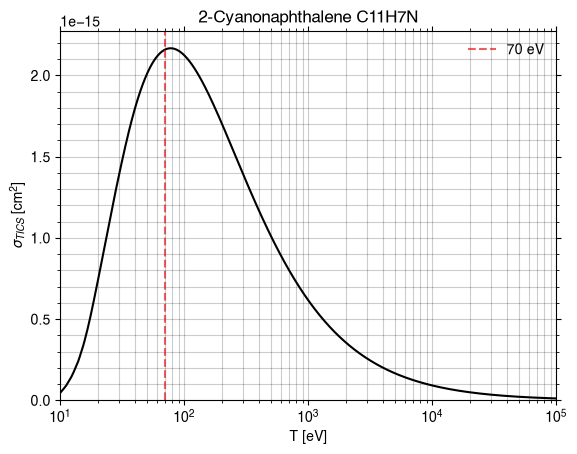

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

1-cyanoacenaphtylene not found : IndexError : list index out of range
1-cyanoacenaphtylene a échoué : TypeError : cannot unpack non-iterable NoneType object
5-cyanoacenaphtylene not found : IndexError : list index out of range
5-cyanoacenaphtylene a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(3014262)
Recherche : '1-cyanopyrene' -> CID 3014262, formule C17H9N


Loading output/xyz/1-cyanopyrene_C17H9N.xyzBuilt graph: 27 atoms, 30 bondsLoading output/xyz/1-cyanopyrene_C17H9N.xyzBuilt graph: 27 atoms, 30 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/1-cyanopyrene_C17H9N.gifGIF written to output/gif/1-cyanopyrene_C17H9N.gif

strucutre 3D
Réussite. Nom: 1-cyanopyrene, formule: C17H9N, M: 227.26, nom_marche: 1-cyanopyrene
PYSCF CONVERGENCE

WARN: 15 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -703.725978723985
**** MO energy ****
MO #1   energy= -15.5668856849608  occ= 2
MO #2   energy= -11.2802289101095  occ= 2
MO #3   energy= -11.2729546219932  occ= 2
MO #4   energy= -11.2722193763522  occ= 2
MO #5   energy= -11.2672412799587  occ= 2
MO #6   energy= -11.2661332094152  occ= 2
MO #7   energy= -11.2621509023423  occ= 2
MO #8   energy= -11.2611446006099  occ= 2
MO #9   energy= -11.2602371274698  occ= 2
MO #10  energy= -11.2587118059716  occ= 2
MO #11  energy= -11.2584815975485  occ= 2
MO #12  energy= -11.257380432404   occ= 2
MO #13  energy= -11.2560704708929  occ= 2
MO #14  energy= -11.2556155326437  occ= 2
MO #15  energy= -11.2545926594873  occ= 2
MO #16  energy= -11.2533588222944  occ= 2
MO #17  energy= -11.2520464444602  occ= 2
MO #18  ene

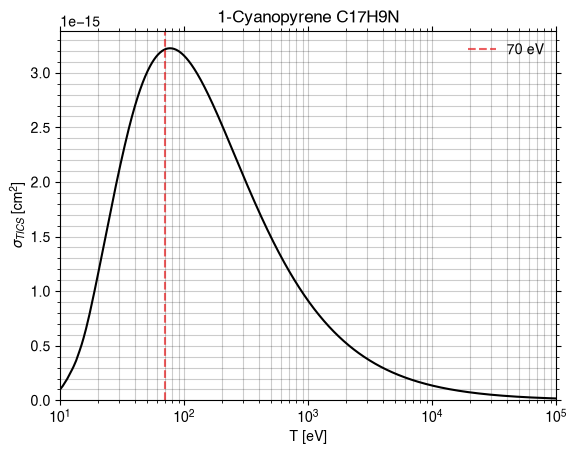

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(55038)
Recherche : '2-cyanopyrene' -> CID 55038, formule C17H9N


Loading output/xyz/2-cyanopyrene_C17H9N.xyzBuilt graph: 27 atoms, 30 bondsLoading output/xyz/2-cyanopyrene_C17H9N.xyzBuilt graph: 27 atoms, 30 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/2-cyanopyrene_C17H9N.gifGIF written to output/gif/2-cyanopyrene_C17H9N.gif

strucutre 3D
Réussite. Nom: 2-cyanopyrene, formule: C17H9N, M: 227.26, nom_marche: 2-cyanopyrene
PYSCF CONVERGENCE

WARN: 14 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -703.724653157196
**** MO energy ****
MO #1   energy= -15.5728254663825  occ= 2
MO #2   energy= -11.2876613080319  occ= 2
MO #3   energy= -11.2765836124967  occ= 2
MO #4   energy= -11.2674383161497  occ= 2
MO #5   energy= -11.2673917124745  occ= 2
MO #6   energy= -11.2656717682582  occ= 2
MO #7   energy= -11.2642462093852  occ= 2
MO #8   energy= -11.2638399862493  occ= 2
MO #9   energy= -11.2600802931344  occ= 2
MO #10  energy= -11.2595229682566  occ= 2
MO #11  energy= -11.2585244502255  occ= 2
MO #12  energy= -11.2571000597347  occ= 2
MO #13  energy= -11.2570820824434  occ= 2
MO #14  energy= -11.255800889412   occ= 2
MO #15  energy= -11.2557980482811  occ= 2
MO #16  energy= -11.2536373730139  occ= 2
MO #17  energy= -11.2525354383584  occ= 2
MO #18  ene

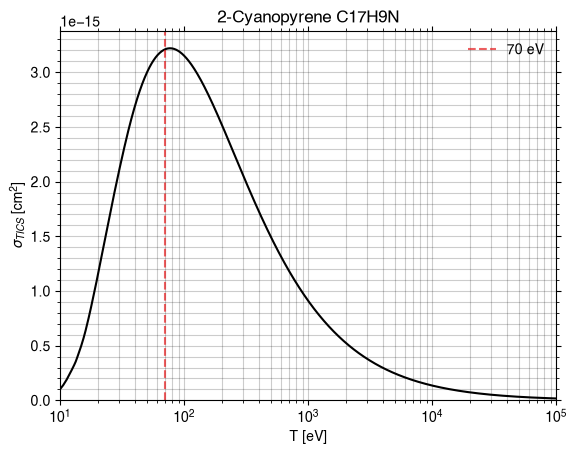

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(85964984)
Recherche : '4-cyanopyrene' -> CID 85964984, formule C17H9N


Loading output/xyz/4-cyanopyrene_C17H9N.xyzBuilt graph: 27 atoms, 30 bondsLoading output/xyz/4-cyanopyrene_C17H9N.xyzBuilt graph: 27 atoms, 30 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/4-cyanopyrene_C17H9N.gifGIF written to output/gif/4-cyanopyrene_C17H9N.gif

strucutre 3D
Réussite. Nom: 4-cyanopyrene, formule: C17H9N, M: 227.26, nom_marche: 4-cyanopyrene
PYSCF CONVERGENCE

WARN: 15 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -703.724239504089
**** MO energy ****
MO #1   energy= -15.5717097084095  occ= 2
MO #2   energy= -11.2873211518099  occ= 2
MO #3   energy= -11.2772065955109  occ= 2
MO #4   energy= -11.2768270747554  occ= 2
MO #5   energy= -11.2662879394434  occ= 2
MO #6   energy= -11.2642564621458  occ= 2
MO #7   energy= -11.2623390699816  occ= 2
MO #8   energy= -11.2610783693235  occ= 2
MO #9   energy= -11.2592213985055  occ= 2
MO #10  energy= -11.2585109372293  occ= 2
MO #11  energy= -11.2577368057865  occ= 2
MO #12  energy= -11.2574412979249  occ= 2
MO #13  energy= -11.2541606083736  occ= 2
MO #14  energy= -11.253690186516   occ= 2
MO #15  energy= -11.2529276363778  occ= 2
MO #16  energy= -11.2509481365667  occ= 2
MO #17  energy= -11.2499222135981  occ= 2
MO #18  ene

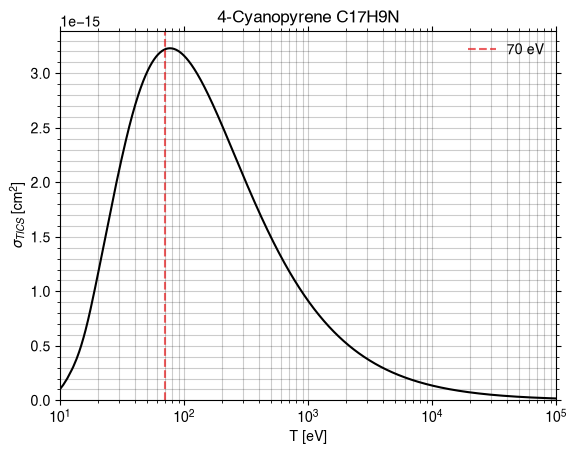

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Cyanophosphaethyne not found : IndexError : list index out of range
Cyanophosphaethyne a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(141467)
Recherche : 'Silyl cyanide' -> CID 141467, formule CH3NSi


Loading output/xyz/Silyl_cyanide_CH3NSi.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Silyl_cyanide_CH3NSi.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Silyl_cyanide_CH3NSi.gifGIF written to output/gif/Silyl_cyanide_CH3NSi.gif

strucutre 3D
Réussite. Nom: Silyl cyanide, formule: CH3NSi, M: 57.126, nom_marche: Silyl_cyanide
PYSCF CONVERGENCE
converged SCF energy = -97.860809406269
**** MO energy ****
MO #1   energy= -15.5965857911393  occ= 2
MO #2   energy= -11.2685129520021  occ= 2
MO #3   energy= -1.22667872596661  occ= 2
MO #4   energy= -0.817593842369469 occ= 2
MO #5   energy= -0.642407798472448 occ= 2
MO #6   energy= -0.557972909990354 occ= 2
MO #7   energy= -0.531371696456685 occ= 2
MO #8   energy= -0.531367022587804 occ= 2
MO #9   energy= -0.476189332619391 occ= 2
MO #10  energy= -0.476186787199804 occ= 2
MO #11  energy= 0.0381081160652276 occ= 0
MO #12  energy= 0.0517155737378349 occ= 0
MO #13  energy= 0.0517161522223384 occ= 0
MO #14  energy= 0.0695249467041192 occ= 0
MO #15  energy= 0.0953868035622285 occ= 0
MO #16  energy= 0.0953964438528966 occ= 0
MO #17  energy= 0.125794408733212  occ= 0
MO #18  energy= 0.131637776335206  occ= 0
MO #19  energy= 0.131647750749214  occ= 0
MO #20  energy= 0.156575125

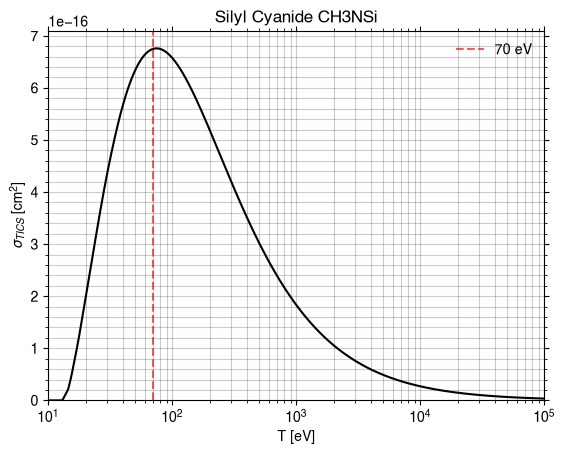

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(750)
Recherche : 'Glycine' -> CID 750, formule C2H5NO2


Loading output/xyz/Glycine_C2H5NO2.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Glycine_C2H5NO2.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Glycine_C2H5NO2.gifGIF written to output/gif/Glycine_C2H5NO2.gif

strucutre 3D
Réussite. Nom: Glycine, formule: C2H5NO2, M: 75.07, nom_marche: Glycine
PYSCF CONVERGENCE
converged SCF energy = -282.953807998085
**** MO energy ****
MO #1   energy= -20.6197992654468  occ= 2
MO #2   energy= -20.5544438533467  occ= 2
MO #3   energy= -15.5472072215254  occ= 2
MO #4   energy= -11.3913218894917  occ= 2
MO #5   energy= -11.2800187443904  occ= 2
MO #6   energy= -1.46114206306182  occ= 2
MO #7   energy= -1.36041648507619  occ= 2
MO #8   energy= -1.19236714553076  occ= 2
MO #9   energy= -0.977381982823839 occ= 2
MO #10  energy= -0.820916643821306 occ= 2
MO #11  energy= -0.708952484472402 occ= 2
MO #12  energy= -0.697885531488266 occ= 2
MO #13  energy= -0.697243307154304 occ= 2
MO #14  energy= -0.624014523253472 occ= 2
MO #15  energy= -0.596147748961186 occ= 2
MO #16  energy= -0.582326219702186 occ= 2
MO #17  energy= -0.542510769250605 occ= 2
MO #18  energy= -0.487206675592464 occ= 2
MO #19  energy= -0.464657152489838 occ= 2
MO #20  energy= -0.410609983313194 occ

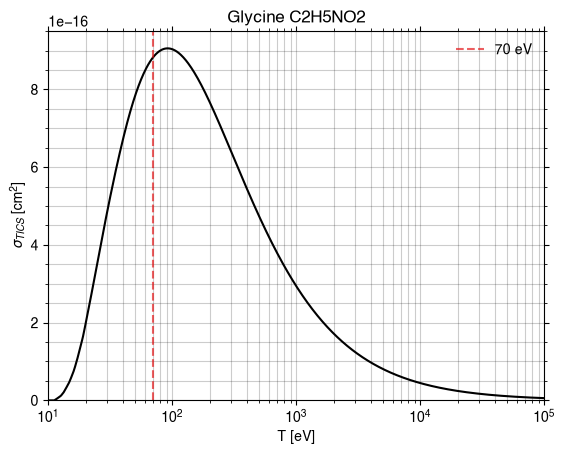

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6341)
Recherche : 'Ethylamine' -> CID 6341, formule C2H7N


Loading output/xyz/Ethylamine_C2H7N.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Ethylamine_C2H7N.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ethylamine_C2H7N.gifGIF written to output/gif/Ethylamine_C2H7N.gif

strucutre 3D
Réussite. Nom: Ethylamine, formule: C2H7N, M: 45.08, nom_marche: Ethylamine
PYSCF CONVERGENCE
converged SCF energy = -134.307900385859
**** MO energy ****
MO #1   energy= -15.5355944029654  occ= 2
MO #2   energy= -11.2451444720357  occ= 2
MO #3   energy= -11.2121867293452  occ= 2
MO #4   energy= -1.17769868445031  occ= 2
MO #5   energy= -0.985115363254728 occ= 2
MO #6   energy= -0.828962445661084 occ= 2
MO #7   energy= -0.672313622752327 occ= 2
MO #8   energy= -0.599234131083732 occ= 2
MO #9   energy= -0.567278582247363 occ= 2
MO #10  energy= -0.563546474638836 occ= 2
MO #11  energy= -0.509629622676326 occ= 2
MO #12  energy= -0.485239360498239 occ= 2
MO #13  energy= -0.385606369026249 occ= 2
MO #14  energy= 0.074902113730436  occ= 0
MO #15  energy= 0.0987006393216475 occ= 0
MO #16  energy= 0.108899485088456  occ= 0
MO #17  energy= 0.125734966004987  occ= 0
MO #18  energy= 0.159355482233686  occ= 0
MO #19  energy= 0.161991592937777  occ= 0
MO #20  energy= 0.18239025084408  

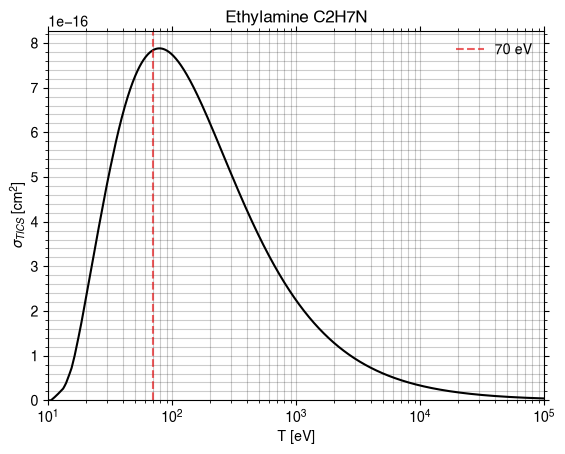

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(670)
Recherche : 'Dihydroxyacetone' -> CID 670, formule C3H6O3
3D


  frame 120/120xyz/Dihydroxyacetone_C3H6O3.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/Dihydroxyacetone_C3H6O3.xyzBuilt graph: 12 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/Dihydroxyacetone_C3H6O3.gifGIF written to output/gif/Dihydroxyacetone_C3H6O3.gif

strucutre 3D
Réussite. Nom: Dihydroxyacetone, formule: C3H6O3, M: 90.08, nom_marche: Dihydroxyacetone
PYSCF CONVERGENCE
converged SCF energy = -341.801514962038
**** MO energy ****
MO #1   energy= -20.5713821467702  occ= 2
MO #2   energy= -20.5713740885595  occ= 2
MO #3   energy= -20.5622052601623  occ= 2
MO #4   energy= -11.34195262004    occ= 2
MO #5   energy= -11.3063423607063  occ= 2
MO #6   energy= -11.3062951980931  occ= 2
MO #7   energy= -1.40535649641254  occ= 2
MO #8   energy= -1.37549053452596  occ= 2
MO #9   energy= -1.35783194614217  occ= 2
MO #10  energy= -1.03969697867833  occ= 2
MO #11  energy= -0.943612824860804 occ= 2
MO #12  energy= -0.778581467739222 occ= 2
MO #13  energy= -0.72159803843657  occ= 2
MO #14  energy= -0.705481737798972 occ= 2
MO #15  energy= -0.696271910676085 occ= 2
MO #16  energy= -0.646010207153097 occ= 2
MO #17  energy= -0.632386332196629 occ= 2
MO #18  energy= -0.607912507019922 occ= 2
MO #19  energy= -0.544881071484473 occ= 2
MO #20  energy= -0.53

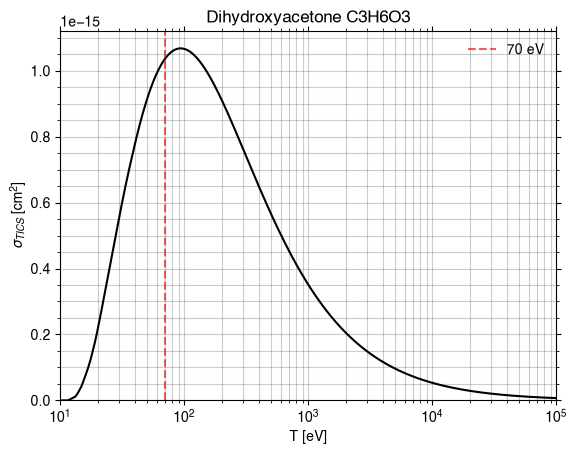

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(10903)
Recherche : 'Ethyl methyl ether' -> CID 10903, formule C3H8O


Loading output/xyz/Ethyl_methyl_ether_C3H8O.xyzBuilt graph: 12 atoms, 11 bondsLoading output/xyz/Ethyl_methyl_ether_C3H8O.xyzBuilt graph: 12 atoms, 11 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Ethyl_methyl_ether_C3H8O.gifGIF written to output/gif/Ethyl_methyl_ether_C3H8O.gif

strucutre 3D
Réussite. Nom: Ethyl methyl ether, formule: C3H8O, M: 60.1, nom_marche: Ethyl_methyl_ether
PYSCF CONVERGENCE
converged SCF energy = -193.1861344492
**** MO energy ****
MO #1   energy= -20.551454690007   occ= 2
MO #2   energy= -11.2708617150768  occ= 2
MO #3   energy= -11.2673965599852  occ= 2
MO #4   energy= -11.2117506036611  occ= 2
MO #5   energy= -1.36547217284249  occ= 2
MO #6   energy= -1.0220771014285   occ= 2
MO #7   energy= -0.912848776426184 occ= 2
MO #8   energy= -0.82899871439901  occ= 2
MO #9   energy= -0.668962045403187 occ= 2
MO #10  energy= -0.647990184180404 occ= 2
MO #11  energy= -0.622348986292426 occ= 2
MO #12  energy= -0.582760212764022 occ= 2
MO #13  energy= -0.534728540283488 occ= 2
MO #14  energy= -0.505789102054653 occ= 2
MO #15  energy= -0.501035263100092 occ= 2
MO #16  energy= -0.473886315838001 occ= 2
MO #17  energy= -0.422609506092897 occ= 2
MO #18  energy= 0.0725302201672552 occ= 0
MO #19  energy= 0.0845420007481272 occ= 0
MO #20  energy= 0.101

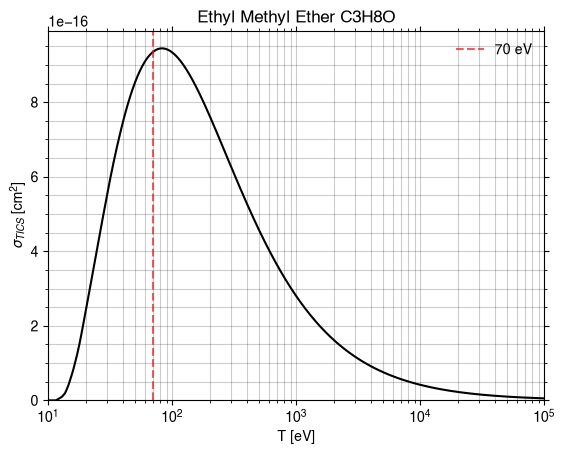

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(8418)
Recherche : 'Anthracene' -> CID 8418, formule C14H10


Loading output/xyz/Anthracene_C14H10.xyzBuilt graph: 24 atoms, 26 bondsLoading output/xyz/Anthracene_C14H10.xyzBuilt graph: 24 atoms, 26 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Anthracene_C14H10.gifGIF written to output/gif/Anthracene_C14H10.gif

strucutre 3D
Réussite. Nom: Anthracene, formule: C14H10, M: 178.23, nom_marche: Anthracene
PYSCF CONVERGENCE

WARN: 9 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -536.169238586157
**** MO energy ****
MO #1   energy= -11.2426979419244  occ= 2
MO #2   energy= -11.2424911589656  occ= 2
MO #3   energy= -11.2417742861272  occ= 2
MO #4   energy= -11.2414120950841  occ= 2
MO #5   energy= -11.2397120509193  occ= 2
MO #6   energy= -11.2396173402771  occ= 2
MO #7   energy= -11.2386999258091  occ= 2
MO #8   energy= -11.2386698136519  occ= 2
MO #9   energy= -11.2385858629019  occ= 2
MO #10  energy= -11.2385487484507  occ= 2
MO #11  energy= -11.2368797215518  occ= 2
MO #12  energy= -11.2368630106133  occ= 2
MO #13  energy= -11.2357687373022  occ= 2
MO #14  energy= -11.2357539004087  occ= 2
MO #15  energy= -1.19285430017596  occ= 2
MO #16  energy= -1.15232084290795  occ= 2
MO #17  energy= -1.08559492777359  occ= 2
MO #18  energy= -1

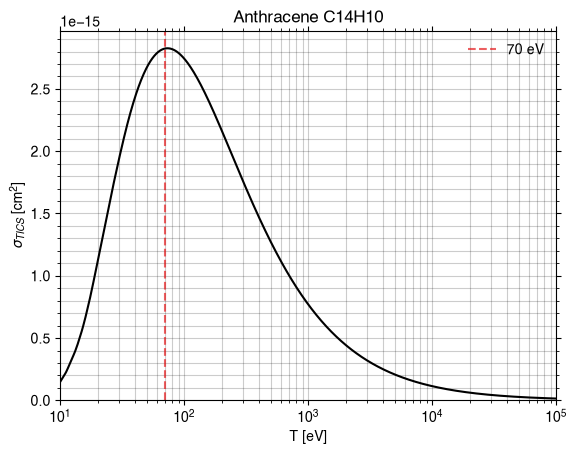

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(31423)
Recherche : 'Pyrene' -> CID 31423, formule C16H10


Loading output/xyz/Pyrene_C16H10.xyzBuilt graph: 26 atoms, 29 bondsLoading output/xyz/Pyrene_C16H10.xyzBuilt graph: 26 atoms, 29 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Pyrene_C16H10.gifGIF written to output/gif/Pyrene_C16H10.gif

strucutre 3D
Réussite. Nom: Pyrene, formule: C16H10, M: 202.25, nom_marche: Pyrene
PYSCF CONVERGENCE

WARN: 13 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -611.960951344425
**** MO energy ****
MO #1   energy= -11.2435666331217  occ= 2
MO #2   energy= -11.2431901050493  occ= 2
MO #3   energy= -11.2428145824672  occ= 2
MO #4   energy= -11.2427864498481  occ= 2
MO #5   energy= -11.2420935476665  occ= 2
MO #6   energy= -11.2413486645072  occ= 2
MO #7   energy= -11.2403501561338  occ= 2
MO #8   energy= -11.2403312517981  occ= 2
MO #9   energy= -11.2391430077651  occ= 2
MO #10  energy= -11.2391371089375  occ= 2
MO #11  energy= -11.2381467559757  occ= 2
MO #12  energy= -11.2381453557788  occ= 2
MO #13  energy= -11.2370729465333  occ= 2
MO #14  energy= -11.2370698575552  occ= 2
MO #15  energy= -11.2363799735763  occ= 2
MO #16  energy= -11.2363785006045  occ= 2
MO #17  energy= -1.20666529698974  occ= 2
MO #18  energy= -1.150319

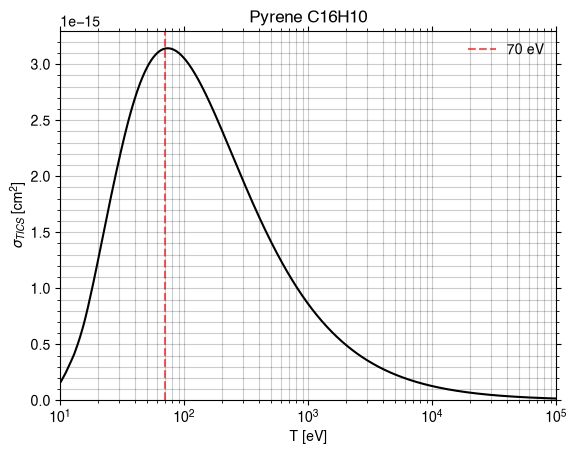

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6305)
Recherche : 'Tryptophan' -> CID 6305, formule C11H12N2O2


Loading output/xyz/Tryptophan_C11H12N2O2.xyzBuilt graph: 27 atoms, 28 bondsLoading output/xyz/Tryptophan_C11H12N2O2.xyzBuilt graph: 27 atoms, 28 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Tryptophan_C11H12N2O2.gifGIF written to output/gif/Tryptophan_C11H12N2O2.gif

strucutre 3D
Réussite. Nom: Tryptophan, formule: C11H12N2O2, M: 204.22, nom_marche: Tryptophan
PYSCF CONVERGENCE

WARN: 5 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -682.428998150085
**** MO energy ****
MO #1   energy= -20.6045395643227  occ= 2
MO #2   energy= -20.5393713573321  occ= 2
MO #3   energy= -15.6028332174654  occ= 2
MO #4   energy= -15.5474446577409  occ= 2
MO #5   energy= -11.3806971613627  occ= 2
MO #6   energy= -11.2787450960204  occ= 2
MO #7   energy= -11.2702861608894  occ= 2
MO #8   energy= -11.2640388199728  occ= 2
MO #9   energy= -11.2402852712729  occ= 2
MO #10  energy= -11.2332637438493  occ= 2
MO #11  energy= -11.2314788854688  occ= 2
MO #12  energy= -11.229704557671   occ= 2
MO #13  energy= -11.2222277743639  occ= 2
MO #14  energy= -11.2215839312737  occ= 2
MO #15  energy= -11.2210630044805  occ= 2
MO #16  energy= -1.4462130740429   occ= 2
MO #17  energy= -1.34349076138598  occ= 2
MO #18  energy

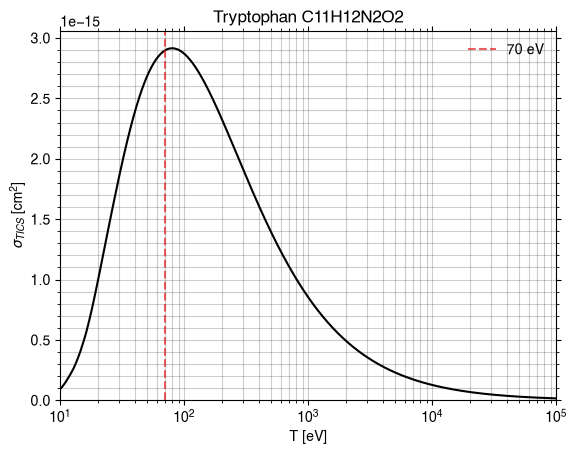

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(23987)
Recherche : 'Helium' -> CID 23987, formule He


[04:35:01] UFFTYPER: Unrecognized atom type: He+4 (0)
geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  **

2D
[Level 1] Processing SMILES: [He]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
1
0
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Helium, formule: He, M: 4.0026, nom_marche: Helium
PYSCF CONVERGENCE
temp.xyz a échoué : RuntimeError : a and b must be different
ORBITAL CAR
Helium a échoué : TypeError : 'NoneType' object is not iterable
Compound(23968)
Recherche : 'Argon' -> CID 23968, formule Ar


[04:35:02] UFFTYPER: Unrecognized atom type: Ar3+4 (0)
geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *

2D
[Level 1] Processing SMILES: [Ar]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
1
0
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Argon, formule: Ar, M: 39.9, nom_marche: Argon
PYSCF CONVERGENCE
temp.xyz a échoué : RuntimeError : a and b must be different
ORBITAL CAR
Argon a échoué : TypeError : 'NoneType' object is not iterable


... (2 outputs left out)

Loading output/xyz/Thiofulminic_acid_CHNS.xyzBuilt graph: 4 atoms, 3 bonds

Compound(6857665)
Recherche : 'Thiofulminic acid' -> CID 6857665, formule CHNS
3D


  frame 120/120xyz/Thiofulminic_acid_CHNS.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/Thiofulminic_acid_CHNS.gifGIF written to output/gif/Thiofulminic_acid_CHNS.gif

strucutre 3D
Réussite. Nom: Thiofulminic acid, formule: CHNS, M: 59.09, nom_marche: Thiofulminic_acid
PYSCF CONVERGENCE
converged SCF energy = -102.822540330614
**** MO energy ****
MO #1   energy= -15.7021736814597  occ= 2
MO #2   energy= -11.3469296102046  occ= 2
MO #3   energy= -1.34978578379314  occ= 2
MO #4   energy= -0.991891861757779 occ= 2
MO #5   energy= -0.839906631646926 occ= 2
MO #6   energy= -0.63269709303321  occ= 2
MO #7   energy= -0.613741136162394 occ= 2
MO #8   energy= -0.613741133836274 occ= 2
MO #9   energy= -0.329099891591189 occ= 2
MO #10  energy= -0.329099890706929 occ= 2
MO #11  energy= 0.0453553098787509 occ= 0
MO #12  energy= 0.089449658730046  occ= 0
MO #13  energy= 0.0894496783373014 occ= 0
MO #14  energy= 0.0969688723418608 occ= 0
MO #15  energy= 0.101204986798778  occ= 0
MO #16  energy= 0.140400033677589  occ= 0
MO #17  energy= 0.140400037752728  occ= 0
MO #18  energy= 0.183298644823864  occ= 0
MO #19  energy= 0.222319586600473  occ= 0
MO #20  energy= 0.239

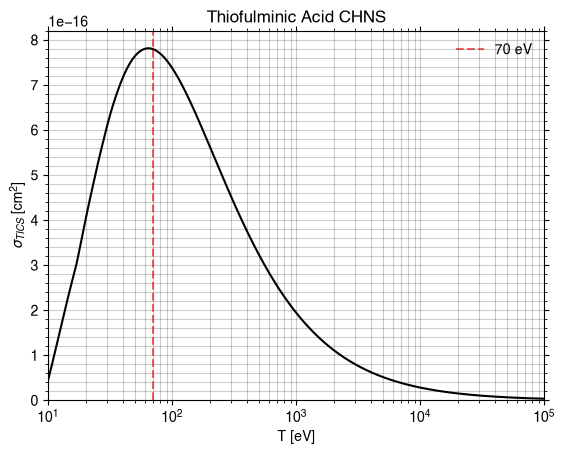

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(108196)
Recherche : 'Hydrogen disulfide' -> CID 108196, formule H2S2


Loading output/xyz/Hydrogen_disulfide_H2S2.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Hydrogen_disulfide_H2S2.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Hydrogen_disulfide_H2S2.gifGIF written to output/gif/Hydrogen_disulfide_H2S2.gif

strucutre 3D
Réussite. Nom: Hydrogen disulfide, formule: H2S2, M: 66.15, nom_marche: Hydrogen_disulfide
PYSCF CONVERGENCE
converged SCF energy = -21.0964958908757
**** MO energy ****
MO #1   energy= -1.06611187255174  occ= 2
MO #2   energy= -0.890665440214128 occ= 2
MO #3   energy= -0.605972842543118 occ= 2
MO #4   energy= -0.547733058846822 occ= 2
MO #5   energy= -0.48121916399993  occ= 2
MO #6   energy= -0.392371031905299 occ= 2
MO #7   energy= -0.375047853239934 occ= 2
MO #8   energy= 0.0582729870402783 occ= 0
MO #9   energy= 0.0899914366439667 occ= 0
MO #10  energy= 0.095029327414595  occ= 0
MO #11  energy= 0.106346961404192  occ= 0
MO #12  energy= 0.112486251636079  occ= 0
MO #13  energy= 0.12493370115944   occ= 0
MO #14  energy= 0.130533861842772  occ= 0
MO #15  energy= 0.135519567147812  occ= 0
MO #16  energy= 0.15384102714062   occ= 0
MO #17  energy= 0.202530896338634  occ= 0
MO #18  energy= 0.234492443996742  occ= 0
MO #19  energy= 0.25723893895306   occ= 0
MO #20  energy= 0.2

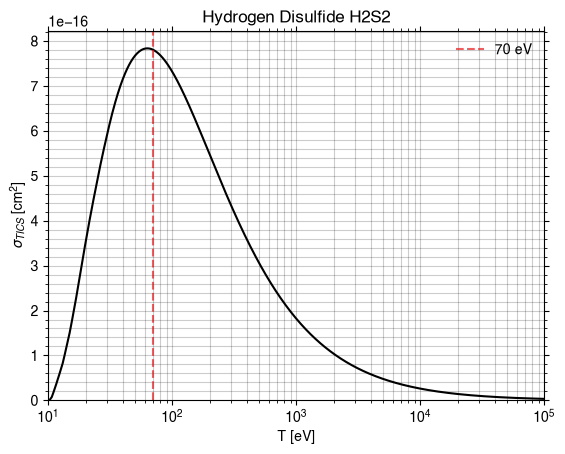

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(24682)
Recherche : 'Sulfur trioxide' -> CID 24682, formule O3S


Loading output/xyz/Sulfur_trioxide_O3S.xyzBuilt graph: 4 atoms, 3 bondsLoading output/xyz/Sulfur_trioxide_O3S.xyzBuilt graph: 4 atoms, 3 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Sulfur_trioxide_O3S.gifGIF written to output/gif/Sulfur_trioxide_O3S.gif

strucutre 3D
Réussite. Nom: Sulfur trioxide, formule: O3S, M: 80.07, nom_marche: Sulfur_trioxide
PYSCF CONVERGENCE
converged SCF energy = -234.570437043639
**** MO energy ****
MO #1   energy= -20.6596205851786  occ= 2
MO #2   energy= -20.6596107785594  occ= 2
MO #3   energy= -20.6595658109187  occ= 2
MO #4   energy= -1.56874584099268  occ= 2
MO #5   energy= -1.42795636495675  occ= 2
MO #6   energy= -1.42792381948136  occ= 2
MO #7   energy= -0.878618477387327 occ= 2
MO #8   energy= -0.742565158873672 occ= 2
MO #9   energy= -0.742560406113155 occ= 2
MO #10  energy= -0.739492779188312 occ= 2
MO #11  energy= -0.614619413119309 occ= 2
MO #12  energy= -0.614614954898442 occ= 2
MO #13  energy= -0.567534216175953 occ= 2
MO #14  energy= -0.567518620606364 occ= 2
MO #15  energy= -0.542895387245172 occ= 2
MO #16  energy= 0.0304206163151645 occ= 0
MO #17  energy= 0.0387541007067335 occ= 0
MO #18  energy= 0.0790536833960789 occ= 0
MO #19  energy= 0.0790544840693473 occ= 0
MO #20  energy= 0.08355758

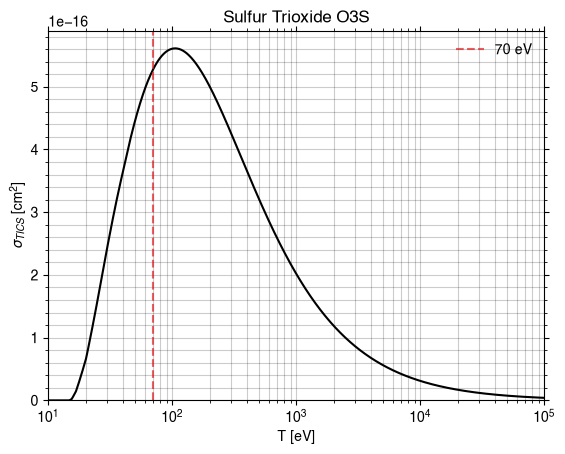

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(143774)
Recherche : 'Methylenephosphine' -> CID 143774, formule CH3P


Loading output/xyz/Methylenephosphine_CH3P.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Methylenephosphine_CH3P.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Methylenephosphine_CH3P.gifGIF written to output/gif/Methylenephosphine_CH3P.gif

strucutre 3D
Réussite. Nom: Methylenephosphine, formule: CH3P, M: 46.008, nom_marche: Methylenephosphine
PYSCF CONVERGENCE
converged SCF energy = -45.9621818046149
**** MO energy ****
MO #1   energy= -11.2699559114508  occ= 2
MO #2   energy= -0.974012033253398 occ= 2
MO #3   energy= -0.752451385245454 occ= 2
MO #4   energy= -0.613497369246677 occ= 2
MO #5   energy= -0.520583787733177 occ= 2
MO #6   energy= -0.40007162997464  occ= 2
MO #7   energy= -0.3564230746607   occ= 2
MO #8   energy= 0.050276387797616  occ= 0
MO #9   energy= 0.0633655432146321 occ= 0
MO #10  energy= 0.0729683569664084 occ= 0
MO #11  energy= 0.0775745447822623 occ= 0
MO #12  energy= 0.0922979370919569 occ= 0
MO #13  energy= 0.132713885000612  occ= 0
MO #14  energy= 0.161984396610368  occ= 0
MO #15  energy= 0.177360842151107  occ= 0
MO #16  energy= 0.201348618610719  occ= 0
MO #17  energy= 0.203673935337482  occ= 0
MO #18  energy= 0.22265498866209   occ= 0
MO #19  energy= 0.234788848368271  occ= 0
MO #20  energy= 0.

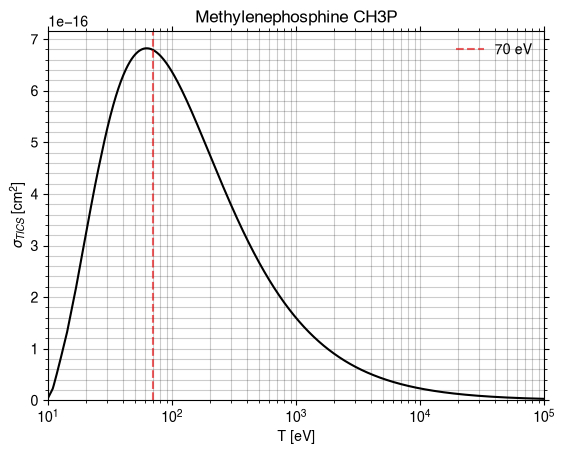

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(140368)
Recherche : 'Thioketene' -> CID 140368, formule C2H2S


Loading output/xyz/Thioketene_C2H2S.xyzBuilt graph: 5 atoms, 4 bondsLoading output/xyz/Thioketene_C2H2S.xyzBuilt graph: 5 atoms, 4 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Thioketene_C2H2S.gifGIF written to output/gif/Thioketene_C2H2S.gif

strucutre 3D
Réussite. Nom: Thioketene, formule: C2H2S, M: 58.1, nom_marche: Thioketene
PYSCF CONVERGENCE
converged SCF energy = -86.8380131796268
**** MO energy ****
MO #1   energy= -11.3475612178818  occ= 2
MO #2   energy= -11.2540314827955  occ= 2
MO #3   energy= -1.10988501368085  occ= 2
MO #4   energy= -0.991403133656611 occ= 2
MO #5   energy= -0.719471266710865 occ= 2
MO #6   energy= -0.633223489113938 occ= 2
MO #7   energy= -0.5871968653788   occ= 2
MO #8   energy= -0.498952093322426 occ= 2
MO #9   energy= -0.418380126431959 occ= 2
MO #10  energy= -0.332857578230335 occ= 2
MO #11  energy= 0.049642394887102  occ= 0
MO #12  energy= 0.0629959490010139 occ= 0
MO #13  energy= 0.0855937002535442 occ= 0
MO #14  energy= 0.0931924148559966 occ= 0
MO #15  energy= 0.104146113484046  occ= 0
MO #16  energy= 0.109507586697192  occ= 0
MO #17  energy= 0.143048604878284  occ= 0
MO #18  energy= 0.157302554335702  occ= 0
MO #19  energy= 0.182350545890476  occ= 0
MO #20  energy= 0.222839031195122  

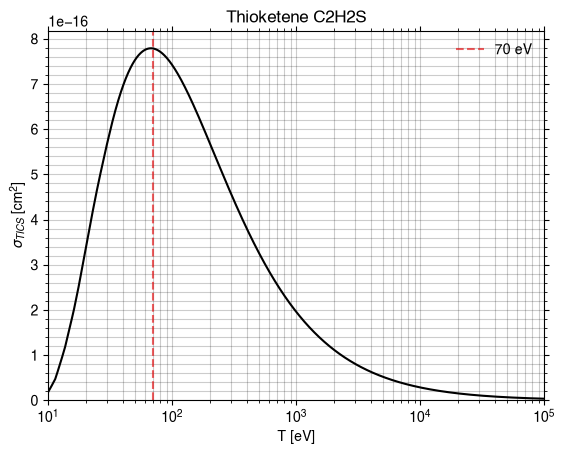

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Propadienone_C3H2O.xyz

Compound(143780)
Recherche : 'Propadienone' -> CID 143780, formule C3H2O
3D


  frame 120/120atoms, 5 bondsLoading output/xyz/Propadienone_C3H2O.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/Propadienone_C3H2O.gifGIF written to output/gif/Propadienone_C3H2O.gif

strucutre 3D
Réussite. Nom: Propadienone, formule: C3H2O, M: 54.05, nom_marche: Propadienone
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -189.607511941193
**** MO energy ****
MO #1   energy= -20.5971901247579  occ= 2
MO #2   energy= -11.3505803396969  occ= 2
MO #3   energy= -11.306066335349   occ= 2
MO #4   energy= -11.2318648658239  occ= 2
MO #5   energy= -1.43618487849876  occ= 2
MO #6   energy= -1.11071403182078  occ= 2
MO #7   energy= -0.973821330992429 occ= 2
MO #8   energy= -0.720157670460353 occ= 2
MO #9   energy= -0.693706231733401 occ= 2
MO #10  energy= -0.666690716997987 occ= 2
MO #11  energy= -0.613139033808236 occ= 2
MO #12  energy= -0.598061453758062 occ= 2
MO #13  energy= -0.420898408548261 occ= 2
MO #14  energy= -0.364731841273407 occ= 2
MO #15  energy= 0.0297811049393282 occ= 0
MO #16  energy= 0.0562078273095707 occ= 0
MO #17  energy= 0.0800284996529967 occ= 0
MO #18  energy= 

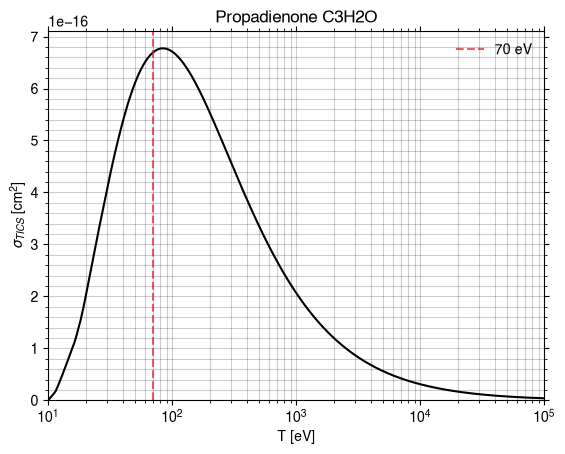

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(7860)
Recherche : 'Glyoxal' -> CID 7860, formule C2H2O2


Loading output/xyz/Glyoxal_C2H2O2.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Glyoxal_C2H2O2.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Glyoxal_C2H2O2.gifGIF written to output/gif/Glyoxal_C2H2O2.gif

strucutre 3D
Réussite. Nom: Glyoxal, formule: C2H2O2, M: 58.04, nom_marche: Glyoxal
PYSCF CONVERGENCE
converged SCF energy = -226.683986457163
**** MO energy ****
MO #1   energy= -20.6066009062679  occ= 2
MO #2   energy= -20.6065961212923  occ= 2
MO #3   energy= -11.3652854539192  occ= 2
MO #4   energy= -11.3645782407664  occ= 2
MO #5   energy= -1.43955596248341  occ= 2
MO #6   energy= -1.42021758074072  occ= 2
MO #7   energy= -0.975990122819162 occ= 2
MO #8   energy= -0.830582900216442 occ= 2
MO #9   energy= -0.708973418710192 occ= 2
MO #10  energy= -0.70793389085054  occ= 2
MO #11  energy= -0.658019208053059 occ= 2
MO #12  energy= -0.595621834335287 occ= 2
MO #13  energy= -0.527600983542714 occ= 2
MO #14  energy= -0.525307679960292 occ= 2
MO #15  energy= -0.447987170885266 occ= 2
MO #16  energy= 0.0338145890562167 occ= 0
MO #17  energy= 0.0593439485767924 occ= 0
MO #18  energy= 0.0801675302806184 occ= 0
MO #19  energy= 0.0932348882148846 occ= 0
MO #20  energy= 0.102929771161001  occ=

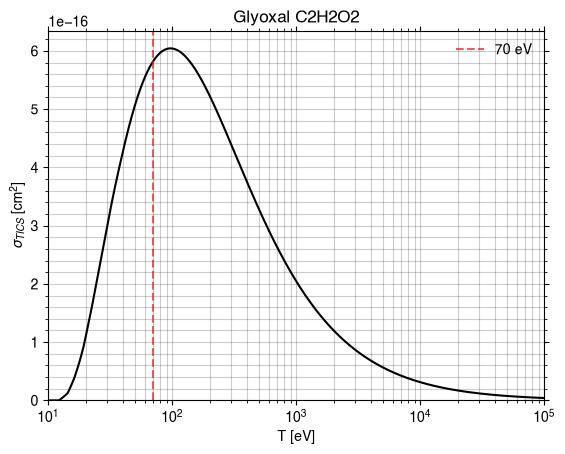

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
PubChem HTTP Error 404 PUGREST.NotFound: No CID found (No CID found that matches the given name)

Mercaptomethanimine not found : IndexError : list index out of range
Mercaptomethanimine a échoué : TypeError : cannot unpack non-iterable NoneType object
Compound(9321)
Recherche : 'Hydrazine' -> CID 9321, formule H4N2


Loading output/xyz/Hydrazine_H4N2.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Hydrazine_H4N2.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Hydrazine_H4N2.gifGIF written to output/gif/Hydrazine_H4N2.gif

strucutre 3D
Réussite. Nom: Hydrazine, formule: H4N2, M: 32.046, nom_marche: Hydrazine
PYSCF CONVERGENCE
converged SCF energy = -111.226655039552
**** MO energy ****
MO #1   energy= -15.5712781022363  occ= 2
MO #2   energy= -15.5707999079934  occ= 2
MO #3   energy= -1.26300675395325  occ= 2
MO #4   energy= -1.00620265980142  occ= 2
MO #5   energy= -0.687569591865455 occ= 2
MO #6   energy= -0.660211700799388 occ= 2
MO #7   energy= -0.604450929460654 occ= 2
MO #8   energy= -0.445602231714027 occ= 2
MO #9   energy= -0.384536372684387 occ= 2
MO #10  energy= 0.0803322699014297 occ= 0
MO #11  energy= 0.109574719782242  occ= 0
MO #12  energy= 0.140539538175916  occ= 0
MO #13  energy= 0.153921579012101  occ= 0
MO #14  energy= 0.210323394916618  occ= 0
MO #15  energy= 0.216876124326934  occ= 0
MO #16  energy= 0.22291684705722   occ= 0
MO #17  energy= 0.235346598383352  occ= 0
MO #18  energy= 0.241484114819139  occ= 0
MO #19  energy= 0.290888636441884  occ= 0
MO #20  energy= 0.304318666903362  o

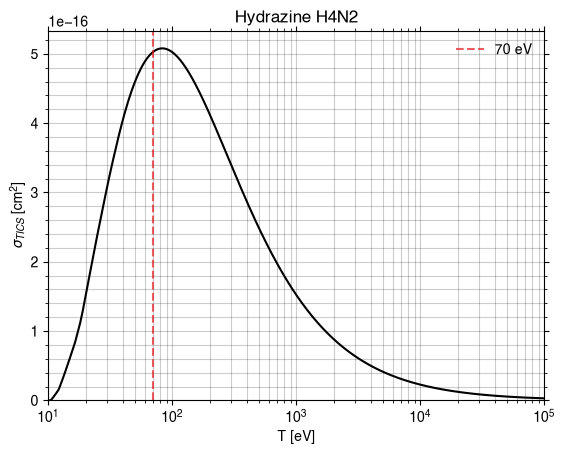

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(25515)
Recherche : 'Ammonium bisulfide' -> CID 25515, formule H5NS


[04:37:48] UFFTYPER: Unrecognized charge state for atom: 0
geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%

2D
[Level 1] Processing SMILES: [NH4+].[SH-]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
7
5
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Ammonium bisulfide, formule: H5NS, M: 51.11, nom_marche: Ammonium_bisulfide
PYSCF CONVERGENCE


21 internal coordinates being used (instead of 21 Cartesians)
Internal coordinate system (atoms numbered from 1):
Distance 1-2
Distance 1-3
Distance 1-4
Distance 1-5
Distance 1-6
Distance 1-7
Distance 2-3
Distance 2-4
Distance 2-5
Distance 2-6
Distance 2-7
Distance 5-7
Distance 6-7
Angle 3-1-5
Angle 3-1-6
Angle 3-1-7
Angle 4-1-5
Angle 4-1-6
Angle 4-1-7
Angle 5-1-6
Angle 5-1-7
Angle 6-1-7
Angle 4-2-5
Angle 4-2-6
Angle 4-2-7
Angle 5-2-6
Angle 5-2-7
Angle 6-2-7
Angle 1-3-2
Angle 1-4-2
Angle 1-5-2
Angle 1-5-7
Angle 2-5-7
Angle 1-6-7
Angle 2-6-7
Angle 2-7-6
LinearAngleX 2-1-7
LinearAngleY 2-1-7
LinearAngleX 1-2-7
LinearAngleY 1-2-7
LinearAngleX 3-2-4
LinearAngleY 3-2-4
LinearAngleX 1-6-2
LinearAngleY 1-6-2
LinearAngleX 1-7-2
LinearAngleY 1-7-2
LinearAngleX 5-7-6
LinearAngleY 5-7-6
Out-of-Plane 1-2-3-7
Out-of-Plane 1-2-4-7
Out-of-Plane 1-2-5-6
Out-of-Plane 1-2-5-7
Out-of-Plane 1-2-6-7
Out-of-Plane 1-3-4-7
Out-of-Plane 2-1-3-4
Out-of-Plane 2-1-3-7
Out-of-Plane 2-1-4-7
Out-of-Plane 2-1-5-6
Out


Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   N   0.008638   0.008878  -0.000559    0.000000  0.000000  0.000000
   S   0.683462   0.000000   0.000000    0.000000  0.000000  0.000000
   H   0.719504  -0.705668  -0.266912    0.000000  0.000000  0.000000
   H   0.472884   0.915539   0.161756    0.000000 -0.000000  0.000000
   H  -0.497928  -0.331441   0.850308    0.000000  0.000000 -0.000000
   H  -0.703098   0.112692  -0.744594    0.000000  0.000000  0.000000
   H  -0.683462   0.000000   0.000000    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr


WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -60.059111529936
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 N    12.4189887489    -0.1084932202     0.1004601948
1 S   -13.2404179329    -0.8609200275    -

... (98 outputs left out)

Step   49 : Displace = 2.525e-03/4.033e-03 (rms/max) Trust = 3.000e-01 (=) Grad = 1.399e-04/1.935e-04 (rms/max) E (change) = -67.3569824291 (-4.111e-07) Quality = 1.346
Hessian Eigenvalues: 1.38461e-03 6.13948e-03 8.52938e-03 ... 4.34798e-01 8.58099e-01 1.75992e+00



Geometry optimization cycle 51
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
   N   1.169070   0.488196  -0.522272   -0.000390 -0.000268  0.000229
   S  -2.288237  -0.389439   1.065769    0.000497  0.000178 -0.000489
   H  -1.097778  -0.184276   0.507018    0.000871  0.000179  0.000412
   H  -2.237178  -1.710174   0.942882    0.000725  0.000533 -0.000588
   H   1.512303   1.285970  -0.029002   -0.000388 -0.000224  0.000167
   H   1.059424   0.743006  -1.481716   -0.000932 -0.000176  0.000306
   H   1.864266  -0.227075  -0.470934   -0.000369 -0.000101 -0.000115
converged SCF energy = -67.3569825929388
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 N    -0.0000234637     0.0000566399    -0.0000147971
1 S    -0.0000135314    -0.0000069825     0.0000248842
2 H     0.0000106371     0.0000042439    -0.0000231893
3 H    -0.0000032771     0.0000002875    -0.0000008674
4 H    -0.0000121975 

Step   50 : Displace = 7.697e-04/1.044e-03 (rms/max) Trust = 3.000e-01 (=) Grad = 3.693e-05/6.307e-05 (rms/max) E (change) = -67.3569825929 (-1.639e-07) Quality = 1.299
Hessian Eigenvalues: 1.38461e-03 6.13948e-03 8.52938e-03 ... 4.34798e-01 8.58099e-01 1.75992e+00
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 769.339 seconds
  frame 120/120xyz/Ammonium_bisulfide_H5NS.xyzBuilt graph: 7 atoms, 5 bondsLoading output

converged SCF energy = -67.356982592964
**** MO energy ****
MO #1   energy= -15.5477848359116  occ= 2
MO #2   energy= -1.15961674970424  occ= 2
MO #3   energy= -0.969233191916494 occ= 2
MO #4   energy= -0.648610610139635 occ= 2
MO #5   energy= -0.648523486767107 occ= 2
MO #6   energy= -0.578832462536937 occ= 2
MO #7   energy= -0.482765636575955 occ= 2
MO #8   energy= -0.437644904254583 occ= 2
MO #9   energy= -0.366059306404239 occ= 2
MO #10  energy= 0.0699000765609703 occ= 0
MO #11  energy= 0.0951150251521822 occ= 0
MO #12  energy= 0.105296362874028  occ= 0
MO #13  energy= 0.116070509249271  occ= 0
MO #14  energy= 0.137314779646379  occ= 0
MO #15  energy= 0.152654836828615  occ= 0
MO #16  energy= 0.154387210418034  occ= 0
MO #17  energy= 0.190245091724076  occ= 0
MO #18  energy= 0.211337172550725  occ= 0
MO #19  energy= 0.214070012187379  occ= 0
MO #20  energy= 0.21670622766796   occ= 0
MO #21  energy= 0.231667989093606  occ= 0
MO #22  energy= 0.240953307787031  occ= 0
MO #23  energy= 

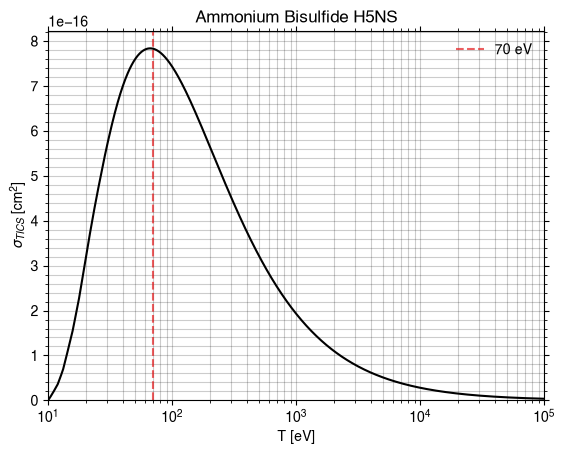

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(14068)
Recherche : 'Dicyanoacetylene' -> CID 14068, formule C4N2


Loading output/xyz/Dicyanoacetylene_C4N2.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Dicyanoacetylene_C4N2.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Dicyanoacetylene_C4N2.gifGIF written to output/gif/Dicyanoacetylene_C4N2.gif

strucutre 3D
Réussite. Nom: Dicyanoacetylene, formule: C4N2, M: 76.06, nom_marche: Dicyanoacetylene
PYSCF CONVERGENCE

WARN: 1 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -260.362176741193
**** MO energy ****
MO #1   energy= -15.6398567086412  occ= 2
MO #2   energy= -15.6397936731573  occ= 2
MO #3   energy= -11.3518657030571  occ= 2
MO #4   energy= -11.3480388547845  occ= 2
MO #5   energy= -11.3397966295014  occ= 2
MO #6   energy= -11.3397476951088  occ= 2
MO #7   energy= -1.27715722870695  occ= 2
MO #8   energy= -1.27392304169378  occ= 2
MO #9   energy= -1.14867420769058  occ= 2
MO #10  energy= -0.98508872794703  occ= 2
MO #11  energy= -0.882940337946778 occ= 2
MO #12  energy= -0.619275145315838 occ= 2
MO #13  energy= -0.617306646907006 occ= 2
MO #14  energy= -0.599662712915528 occ= 2
MO #15  energy= -0.599662712826007 occ= 2
MO #16  energy= -0.54424242521781  occ= 2
MO #17  energy= -0.544242424903272 occ= 2
MO #18  e

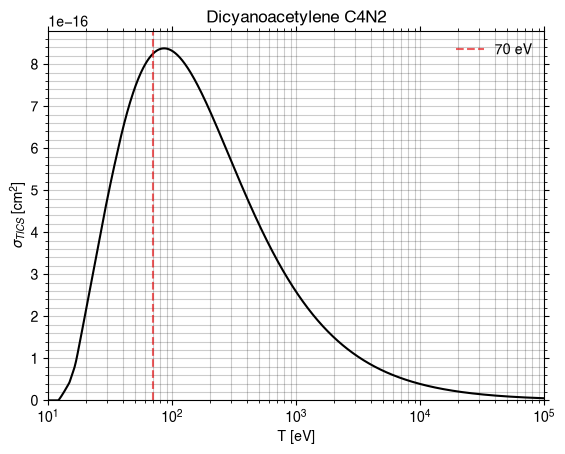

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(3005587)
Recherche : 'Thioformamide' -> CID 3005587, formule CH3NS


Loading output/xyz/Thioformamide_CH3NS.xyzBuilt graph: 6 atoms, 5 bondsLoading output/xyz/Thioformamide_CH3NS.xyzBuilt graph: 6 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Thioformamide_CH3NS.gifGIF written to output/gif/Thioformamide_CH3NS.gif

strucutre 3D
Réussite. Nom: Thioformamide, formule: CH3NS, M: 61.11, nom_marche: Thioformamide
PYSCF CONVERGENCE
converged SCF energy = -104.059333917309
**** MO energy ****
MO #1   energy= -15.6205936678047  occ= 2
MO #2   energy= -11.3616872595026  occ= 2
MO #3   energy= -1.25894683830924  occ= 2
MO #4   energy= -1.00411091069061  occ= 2
MO #5   energy= -0.83052893576015  occ= 2
MO #6   energy= -0.742375727633252 occ= 2
MO #7   energy= -0.655295949388368 occ= 2
MO #8   energy= -0.531515830046146 occ= 2
MO #9   energy= -0.517981056792162 occ= 2
MO #10  energy= -0.343694642460325 occ= 2
MO #11  energy= -0.332387444425312 occ= 2
MO #12  energy= 0.0598912321117857 occ= 0
MO #13  energy= 0.0825797904648365 occ= 0
MO #14  energy= 0.0888475695132227 occ= 0
MO #15  energy= 0.0998406098920832 occ= 0
MO #16  energy= 0.120432788101638  occ= 0
MO #17  energy= 0.12428163047224   occ= 0
MO #18  energy= 0.141735419062167  occ= 0
MO #19  energy= 0.170701104635332  occ= 0
MO #20  energy= 0.1982127734

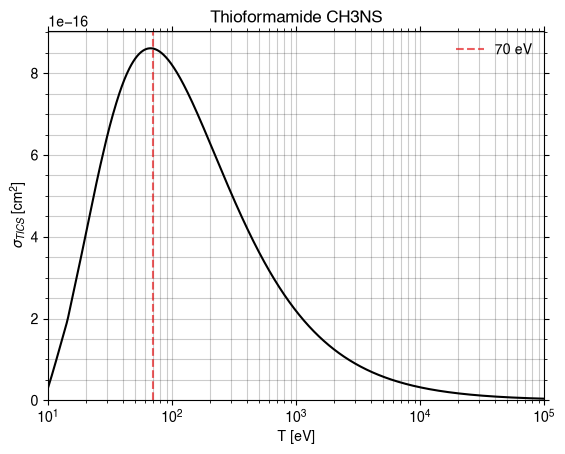

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u
Loading output/xyz/Pyruvonitrile_C3H3NO.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Pyruvonitrile_C3H3NO.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

Compound(69430)
Recherche : 'Pyruvonitrile' -> CID 69430, formule C3H3NO
3D


  frame 120/120
Wrote output/gif/Pyruvonitrile_C3H3NO.gifGIF written to output/gif/Pyruvonitrile_C3H3NO.gif

strucutre 3D
Réussite. Nom: Pyruvonitrile, formule: C3H3NO, M: 69.06, nom_marche: Pyruvonitrile
PYSCF CONVERGENCE
converged SCF energy = -244.732250976207
**** MO energy ****
MO #1   energy= -20.6036196259707  occ= 2
MO #2   energy= -15.6187797668361  occ= 2
MO #3   energy= -11.4014149761084  occ= 2
MO #4   energy= -11.3036952988662  occ= 2
MO #5   energy= -11.273227823619   occ= 2
MO #6   energy= -1.43444022529333  occ= 2
MO #7   energy= -1.25130542383678  occ= 2
MO #8   energy= -1.07049979321365  occ= 2
MO #9   energy= -0.924154531578029 occ= 2
MO #10  energy= -0.729542879589712 occ= 2
MO #11  energy= -0.674438461240765 occ= 2
MO #12  energy= -0.650191695591353 occ= 2
MO #13  energy= -0.610114464747255 occ= 2
MO #14  energy= -0.588630977209885 occ= 2
MO #15  energy= -0.557354118000529 occ= 2
MO #16  energy= -0.504228283428576 occ= 2
MO #17  energy= -0.489714574695865 occ= 2
MO #18  energy= -0.485592570386475 occ= 2
MO #19  energy= 0.048634566813702  occ= 0
MO #20  energy= 0.056269292

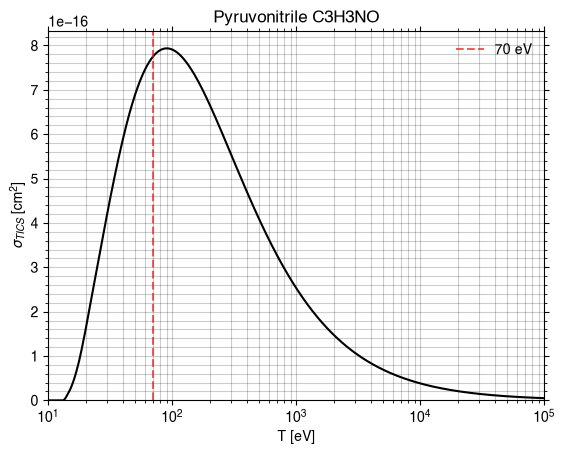

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(137843)
Recherche : 'Triacetylene' -> CID 137843, formule C6H2


Loading output/xyz/Triacetylene_C6H2.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Triacetylene_C6H2.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Triacetylene_C6H2.gifGIF written to output/gif/Triacetylene_C6H2.gif

strucutre 3D
Réussite. Nom: Triacetylene, formule: C6H2, M: 74.08, nom_marche: Triacetylene
PYSCF CONVERGENCE

WARN: 5 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -228.263508921933
**** MO energy ****
MO #1   energy= -11.2795127092896  occ= 2
MO #2   energy= -11.2757088093428  occ= 2
MO #3   energy= -11.2701507598763  occ= 2
MO #4   energy= -11.2701044248549  occ= 2
MO #5   energy= -11.2625377677444  occ= 2
MO #6   energy= -11.2625064616048  occ= 2
MO #7   energy= -1.11616771143396  occ= 2
MO #8   energy= -1.07174396976268  occ= 2
MO #9   energy= -1.02209028400781  occ= 2
MO #10  energy= -0.882739580677686 occ= 2
MO #11  energy= -0.80585192914722  occ= 2
MO #12  energy= -0.72584662461496  occ= 2
MO #13  energy= -0.716055942265467 occ= 2
MO #14  energy= -0.524377685234896 occ= 2
MO #15  energy= -0.524377683577803 occ= 2
MO #16  energy= -0.450862454485003 occ= 2
MO #17  energy= -0.450862451992545 occ= 2
MO #18  energy= -

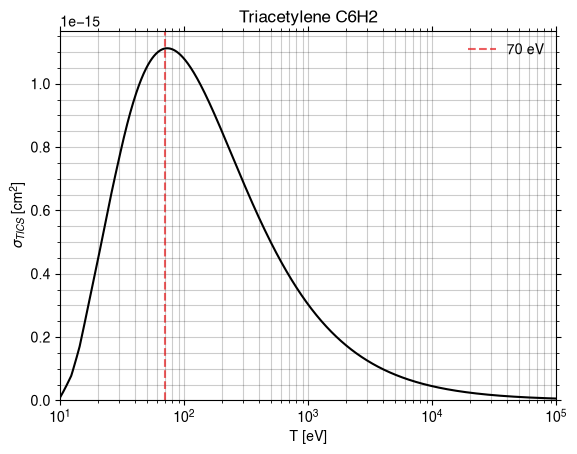

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(140071)
Recherche : 'Dicyanodiacetylene' -> CID 140071, formule C6N2


Loading output/xyz/Dicyanodiacetylene_C6N2.xyzBuilt graph: 8 atoms, 7 bondsLoading output/xyz/Dicyanodiacetylene_C6N2.xyzBuilt graph: 8 atoms, 7 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Dicyanodiacetylene_C6N2.gifGIF written to output/gif/Dicyanodiacetylene_C6N2.gif

strucutre 3D
Réussite. Nom: Dicyanodiacetylene, formule: C6N2, M: 100.08, nom_marche: Dicyanodiacetylene
PYSCF CONVERGENCE

WARN: 3 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -336.069516000263
**** MO energy ****
MO #1   energy= -15.6310892033323  occ= 2
MO #2   energy= -15.6310884251207  occ= 2
MO #3   energy= -11.3424696567682  occ= 2
MO #4   energy= -11.3414176193049  occ= 2
MO #5   energy= -11.3363781391096  occ= 2
MO #6   energy= -11.3362110370309  occ= 2
MO #7   energy= -11.3328432940059  occ= 2
MO #8   energy= -11.3328409918875  occ= 2
MO #9   energy= -1.26837334588646  occ= 2
MO #10  energy= -1.26797864289283  occ= 2
MO #11  energy= -1.1682961974376   occ= 2
MO #12  energy= -1.11270342078678  occ= 2
MO #13  energy= -0.980542637146684 occ= 2
MO #14  energy= -0.914941504446723 occ= 2
MO #15  energy= -0.841629854524783 occ= 2
MO #16  energy= -0.611098874745079 occ= 2
MO #17  energy= -0.610841630456906 occ= 2
MO #

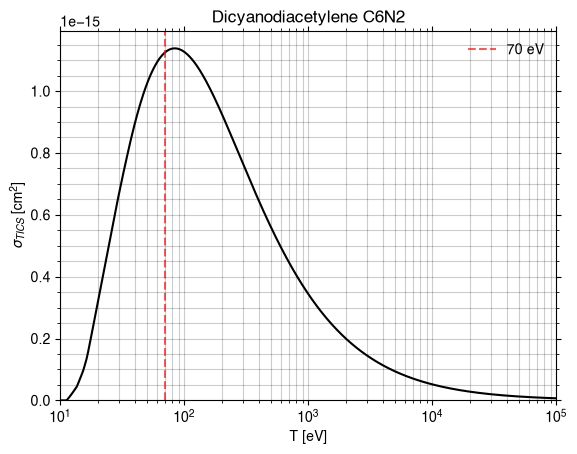

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(139338)
Recherche : 'Pentatetraene' -> CID 139338, formule C5H4


Loading output/xyz/Pentatetraene_C5H4.xyzBuilt graph: 9 atoms, 8 bondsLoading output/xyz/Pentatetraene_C5H4.xyzBuilt graph: 9 atoms, 8 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Pentatetraene_C5H4.gifGIF written to output/gif/Pentatetraene_C5H4.gif

strucutre 3D
Réussite. Nom: Pentatetraene, formule: C5H4, M: 64.08, nom_marche: Pentatetraene
PYSCF CONVERGENCE

WARN: 2 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = -191.503991830239
**** MO energy ****
MO #1   energy= -11.328026544975   occ= 2
MO #2   energy= -11.3279697278012  occ= 2
MO #3   energy= -11.218543716296   occ= 2
MO #4   energy= -11.2185341048676  occ= 2
MO #5   energy= -11.1956725379752  occ= 2
MO #6   energy= -1.14832436591056  occ= 2
MO #7   energy= -1.07027355306207  occ= 2
MO #8   energy= -0.986285692874826 occ= 2
MO #9   energy= -0.884807946483605 occ= 2
MO #10  energy= -0.675345493649813 occ= 2
MO #11  energy= -0.664878075001936 occ= 2
MO #12  energy= -0.620792807762861 occ= 2
MO #13  energy= -0.60388205593633  occ= 2
MO #14  energy= -0.559087711484274 occ= 2
MO #15  energy= -0.450300865745314 occ= 2
MO #16  energy= -0.430032238339746 occ= 2
MO #17  energy= -0.249504603629525 occ= 2
MO #18  energy=

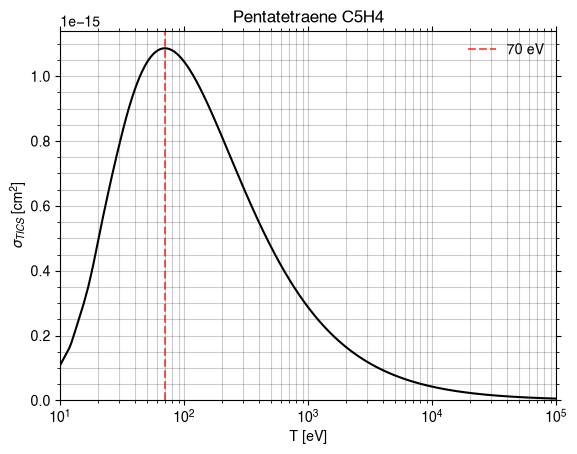

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(8009)
Recherche : 'Allyl cyanide' -> CID 8009, formule C4H5N


Loading output/xyz/Allyl_cyanide_C4H5N.xyzBuilt graph: 10 atoms, 9 bondsLoading output/xyz/Allyl_cyanide_C4H5N.xyzBuilt graph: 10 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Allyl_cyanide_C4H5N.gifGIF written to output/gif/Allyl_cyanide_C4H5N.gif

strucutre 3D
Réussite. Nom: Allyl cyanide, formule: C4H5N, M: 67.09, nom_marche: Allyl_cyanide
PYSCF CONVERGENCE
converged SCF energy = -208.87939776622
**** MO energy ****
MO #1   energy= -15.5735115710754  occ= 2
MO #2   energy= -11.2943043559542  occ= 2
MO #3   energy= -11.2787568425206  occ= 2
MO #4   energy= -11.2647426313474  occ= 2
MO #5   energy= -11.2494699176872  occ= 2
MO #6   energy= -1.2193606647046   occ= 2
MO #7   energy= -1.11274224301179  occ= 2
MO #8   energy= -0.99659084462796  occ= 2
MO #9   energy= -0.799530386700994 occ= 2
MO #10  energy= -0.715400017065456 occ= 2
MO #11  energy= -0.669861025637516 occ= 2
MO #12  energy= -0.634121079784769 occ= 2
MO #13  energy= -0.587769059427082 occ= 2
MO #14  energy= -0.556605215862499 occ= 2
MO #15  energy= -0.537351088529839 occ= 2
MO #16  energy= -0.463008112861726 occ= 2
MO #17  energy= -0.459999083411397 occ= 2
MO #18  energy= -0.391869492078222 occ= 2
MO #19  energy= 0.0628499701545544 occ= 0
MO #20  energy= 0.07971998123

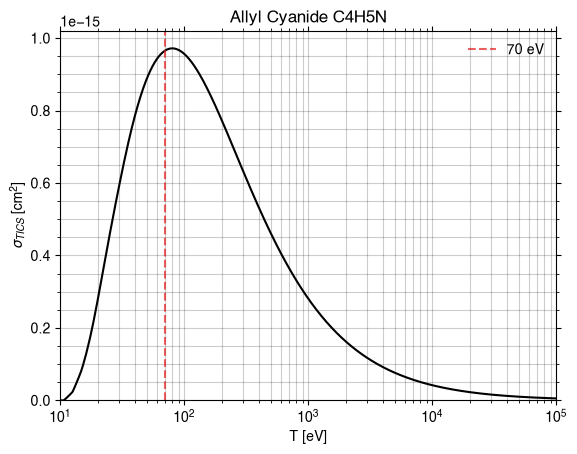

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(6336261)
Recherche : 'Digermane' -> CID 6336261, formule Ge2H6


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [GeH3].[GeH3]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
8
6
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Digermane, formule: Ge2H6, M: 151.31, nom_marche: Digermane
PYSCF CONVERGENCE


24 internal coordinates being used (instead of 24 Cartesians)
Internal coordinate system (atoms numbered from 1):
Distance 1-2
Distance 1-3
Distance 1-4
Distance 1-5
Distance 1-6
Distance 1-7
Distance 1-8
Distance 2-3
Distance 2-4
Distance 2-5
Distance 2-6
Distance 2-7
Distance 2-8
Distance 3-6
Distance 4-7
Distance 5-8
Angle 4-1-6
Angle 5-1-6
Angle 6-1-7
Angle 6-1-8
Angle 4-2-6
Angle 5-2-6
Angle 6-2-7
Angle 6-2-8
Angle 1-4-7
Angle 2-4-7
Angle 1-5-8
Angle 2-5-8
Angle 1-7-4
Angle 2-7-4
Angle 1-8-5
Angle 2-8-5
LinearAngleX 2-1-3
LinearAngleY 2-1-3
LinearAngleX 2-1-6
LinearAngleY 2-1-6
LinearAngleX 3-1-6
LinearAngleY 3-1-6
LinearAngleX 4-1-7
LinearAngleY 4-1-7
LinearAngleX 5-1-8
LinearAngleY 5-1-8
LinearAngleX 1-2-3
LinearAngleY 1-2-3
LinearAngleX 1-2-6
LinearAngleY 1-2-6
LinearAngleX 3-2-6
LinearAngleY 3-2-6
LinearAngleX 4-2-7
LinearAngleY 4-2-7
LinearAngleX 5-2-8
LinearAngleY 5-2-8
LinearAngleX 1-3-2
LinearAngleY 1-3-2
LinearAngleX 1-3-6
LinearAngleY 1-3-6
LinearAngleX 2-3-6
LinearAngle


Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Ge   0.011977  -0.009683   0.412943    0.000000  0.000000  0.000000
  Ge   0.006798   0.002940   0.411247    0.000000  0.000000  0.000000
   H  -0.319212   1.411371  -0.134596    0.000000 -0.000000  0.000000
   H  -1.084993  -0.954761  -0.137023    0.000000  0.000000  0.000000
   H   1.392228  -0.446927  -0.141324    0.000000  0.000000  0.000000
   H  -0.322381   1.425425  -0.137402    0.000000 -0.000000  0.000000
   H  -1.069487  -0.970295  -0.135150    0.000000  0.000000  0.000000
   H   1.385070  -0.458070  -0.138694   -0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr


WARN: Singularity detected in the overlap matrix. SCF may be inaccurate and difficult to converge.


WARN: 24 small eigenvectors of overlap matrix removed because of linear dependency between AOs.


converged SCF energy = 691.681834923277
--------------- RHF_Scan

... (100 outputs left out)

Step   50 : Displace = 1.152e-01/1.848e-01 (rms/max) Trust = 3.000e-01 (+) Grad = 2.208e-03/3.185e-03 (rms/max) E (change) = -10.7854844667 (-3.393e-04) Quality = 1.084
Hessian Eigenvalues: 3.77136e-03 4.90399e-02 4.99981e-02 ... 1.74057e-01 3.02073e-01 4.85698e-01
Maximum iterations reached (50); increase --maxiter for more


Geometry optimization failed to converge in 50 iterations


  frame 120/120xyz/Digermane_Ge2H6.xyzBuilt graph: 8 atoms, 5 bondsLoading output/xyz/Digermane_Ge2H6.xyzBuilt graph: 8 atoms, 5 bondsRendering rotation GIF (120 frames, axis=y)
Wrote output/gif/Digermane_Ge2H6.gifGIF written to output/gif/Digermane_Ge2H6.gif

converged SCF energy = -10.7854844664175
**** MO energy ****
MO #1   energy= -0.738899389204494 occ= 2
MO #2   energy= -0.605925257698579 occ= 2
MO #3   energy= -0.596940379970231 occ= 2
MO #4   energy= -0.585658868426465 occ= 2
MO #5   energy= -0.482801737839874 occ= 2
MO #6   energy= -0.346139435014814 occ= 2
MO #7   energy= -0.261157650123868 occ= 2
MO #8   energy= -0.00797529793443652 occ= 0
MO #9   energy= 0.0288918008202413 occ= 0
MO #10  energy= 0.0342212151897311 occ= 0
MO #11  energy= 0.0454405770059439 occ= 0
MO #12  energy= 0.0486122986760303 occ= 0
MO #13  energy= 0.0522846088892882 occ= 0
MO #14  energy= 0.0586496412811278 occ= 0
MO #15  energy= 0.0711946415637191 occ= 0
MO #16  energy= 0.083160532830998  occ= 0
MO #17  energy= 0.109507879726353  occ= 0
MO #18  energy= 0.122188081055212  occ= 0
MO #19  energy= 0.128697462033768  occ= 0
MO #20  energy= 0.136642244501906  occ= 0
MO #21  energy= 0.144968224544913  occ= 0
MO #22  energy= 0.156601229455171  occ= 0
MO #23  energ

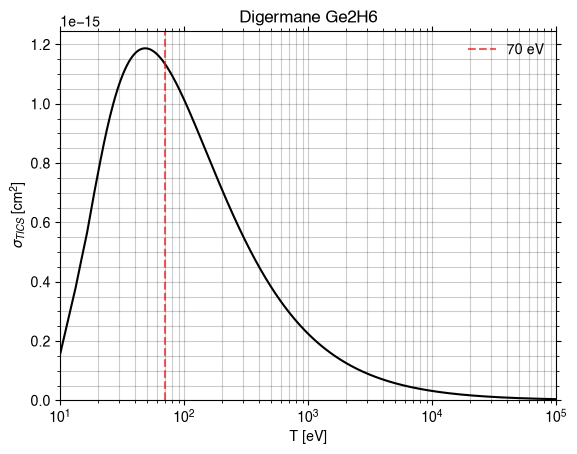

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(8010)
Recherche : 'Malononitrile' -> CID 8010, formule C3H2N2


Loading output/xyz/Malononitrile_C3H2N2.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/Malononitrile_C3H2N2.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/Malononitrile_C3H2N2.gifGIF written to output/gif/Malononitrile_C3H2N2.gif

strucutre 3D
Réussite. Nom: Malononitrile, formule: C3H2N2, M: 66.06, nom_marche: Malononitrile
PYSCF CONVERGENCE
converged SCF energy = -223.722122992486
**** MO energy ****
MO #1   energy= -15.6093552639955  occ= 2
MO #2   energy= -15.609323791275   occ= 2
MO #3   energy= -11.3611355507797  occ= 2
MO #4   energy= -11.3136481936732  occ= 2
MO #5   energy= -11.3136202075071  occ= 2
MO #6   energy= -1.25856408666743  occ= 2
MO #7   energy= -1.24417598764896  occ= 2
MO #8   energy= -1.11274630266963  occ= 2
MO #9   energy= -0.79526088884306  occ= 2
MO #10  energy= -0.734048043164272 occ= 2
MO #11  energy= -0.696247743981544 occ= 2
MO #12  energy= -0.593680657671156 occ= 2
MO #13  energy= -0.588247587204129 occ= 2
MO #14  energy= -0.508057881615397 occ= 2
MO #15  energy= -0.504901941417682 occ= 2
MO #16  energy= -0.492968509222826 occ= 2
MO #17  energy= -0.482979340937258 occ= 2
MO #18  energy= 0.0432708654306992 occ= 0
MO #19  energy= 0.0876570476519867 occ= 0
MO #20  energy= 0.092089359

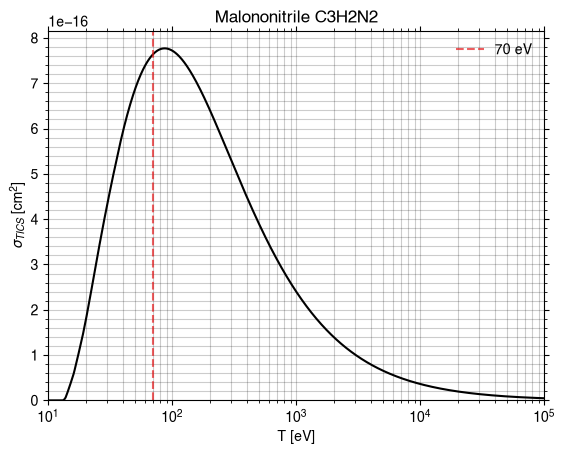

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(12140082)
Recherche : '2-Diazopropanedinitrile' -> CID 12140082, formule C3N4


Loading output/xyz/2-Diazopropanedinitrile_C3N4.xyzBuilt graph: 7 atoms, 6 bondsLoading output/xyz/2-Diazopropanedinitrile_C3N4.xyzBuilt graph: 7 atoms, 6 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/2-Diazopropanedinitrile_C3N4.gifGIF written to output/gif/2-Diazopropanedinitrile_C3N4.gif

strucutre 3D
Réussite. Nom: 2-Diazopropanedinitrile, formule: C3N4, M: 92.06, nom_marche: 2-Diazopropanedinitrile
PYSCF CONVERGENCE
converged SCF energy = -331.413802609717
**** MO energy ****
MO #1   energy= -15.8290730459999  occ= 2
MO #2   energy= -15.7738235142967  occ= 2
MO #3   energy= -15.612540464286   occ= 2
MO #4   energy= -15.612501837921   occ= 2
MO #5   energy= -11.3945049174641  occ= 2
MO #6   energy= -11.3222025012237  occ= 2
MO #7   energy= -11.322154000768   occ= 2
MO #8   energy= -1.54907801403152  occ= 2
MO #9   energy= -1.27511435690404  occ= 2
MO #10  energy= -1.24917864580429  occ= 2
MO #11  energy= -1.21111894794642  occ= 2
MO #12  energy= -0.945640016597181 occ= 2
MO #13  energy= -0.863960294889011 occ= 2
MO #14  energy= -0.755900902539146 occ= 2
MO #15  energy= -0.750921193630729 occ= 2
MO #16  energy= -0.682359952337976 occ= 2
MO #17  energy= -0.598788525973301 occ= 2
MO #18  energy= -0.589702860096724 occ= 2
MO #19  energy= -0.569516228697402 occ= 2
MO #20  e

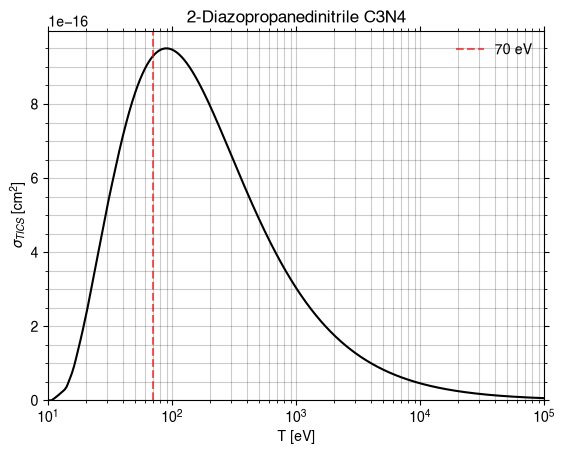

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(174772398)
Recherche : '1,1,2,3,3-Pentacyanoguanidine' -> CID 174772398, formule C6N8


Loading output/xyz/1_1_2_3_3-Pentacyanoguanidine_C6N8.xyzBuilt graph: 14 atoms, 13 bondsLoading output/xyz/1_1_2_3_3-Pentacyanoguanidine_C6N8.xyzBuilt graph: 14 atoms, 13 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/1_1_2_3_3-Pentacyanoguanidine_C6N8.gifGIF written to output/gif/1_1_2_3_3-Pentacyanoguanidine_C6N8.gif

strucutre 3D
Réussite. Nom: 1,1,2,3,3-Pentacyanoguanidine, formule: C6N8, M: 184.12, nom_marche: 1_1_2_3_3-Pentacyanoguanidine
PYSCF CONVERGENCE
converged SCF energy = -662.82696385124
**** MO energy ****
MO #1   energy= -15.7954506531643  occ= 2
MO #2   energy= -15.7892953919577  occ= 2
MO #3   energy= -15.721359023803   occ= 2
MO #4   energy= -15.6620043740343  occ= 2
MO #5   energy= -15.6587645785014  occ= 2
MO #6   energy= -15.6538950709998  occ= 2
MO #7   energy= -15.6538943398868  occ= 2
MO #8   energy= -15.6329140652091  occ= 2
MO #9   energy= -11.5378829201541  occ= 2
MO #10  energy= -11.3931186631059  occ= 2
MO #11  energy= -11.3895482553146  occ= 2
MO #12  energy= -11.3865169276585  occ= 2
MO #13  energy= -11.3854355874763  occ= 2
MO #14  energy= -11.36380335553    occ= 2
MO #15  energy= -1.50536021615425  occ= 2
MO #16  energy= -1.44363480336239  occ= 2
MO #17  energy= -1.37302670853003  occ= 2
MO #18  energy= -1.2952161921377   occ= 2
MO #19  energy= -1.29384659158571  occ=

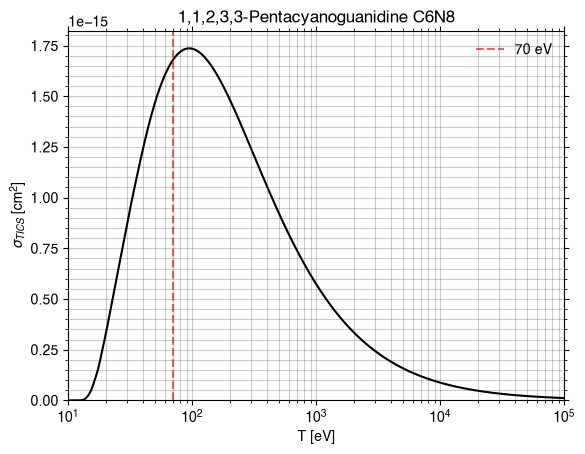

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(139331)
Recherche : 'Cyanoethyne' -> CID 139331, formule C3N
2D
[Level 1] Processing SMILES: [C]#CC#N
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
4
3
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Cyanoethyne, formule: C3N, M: 50.04, nom_marche: Cyanoethyne
PYSCF CONVERGENCE
temp.xyz a échoué : RuntimeError : Electron number 25 and spin 0 are not consistent
Note mol.spin = 2S = Nalpha - Nbeta, not 2S+1
Cyanoethyne a échoué : UnboundLocalError : cannot access local variable 'mf' where it is not associated with a value
Compound(21857)
Recherche : '2,4,6-Triazido-1,3,5-triazine' -> CID 21857, formule C3N12


Loading output/xyz/2_4_6-Triazido-1_3_5-triazine_C3N12.xyzBuilt graph: 15 atoms, 15 bondsLoading output/xyz/2_4_6-Triazido-1_3_5-triazine_C3N12.xyzBuilt graph: 15 atoms, 15 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/2_4_6-Triazido-1_3_5-triazine_C3N12.gifGIF written to output/gif/2_4_6-Triazido-1_3_5-triazine_C3N12.gif

strucutre 3D
Réussite. Nom: 2,4,6-Triazido-1,3,5-triazine, formule: C3N12, M: 204.11, nom_marche: 2_4_6-Triazido-1_3_5-triazine
PYSCF CONVERGENCE
converged SCF energy = -767.004181821741
**** MO energy ****
MO #1   energy= -15.8237959671437  occ= 2
MO #2   energy= -15.8237868139985  occ= 2
MO #3   energy= -15.8237775342906  occ= 2
MO #4   energy= -15.7153273278141  occ= 2
MO #5   energy= -15.7153251808547  occ= 2
MO #6   energy= -15.7153026957867  occ= 2
MO #7   energy= -15.6441701418145  occ= 2
MO #8   energy= -15.6441650164471  occ= 2
MO #9   energy= -15.6441202590202  occ= 2
MO #10  energy= -15.6133143016638  occ= 2
MO #11  energy= -15.6133088064089  occ= 2
MO #12  energy= -15.6132711953402  occ= 2
MO #13  energy= -11.4144594808265  occ= 2
MO #14  energy= -11.4144561525586  occ= 2
MO #15  energy= -11.4144293487847  occ= 2
MO #16  energy= -1.53736216287721  occ= 2
MO #17  energy= -1.53602194675558  occ= 2
MO #18  energy= -1.53594252182627  occ= 2
MO #19  energy= -1.41427025503966  oc

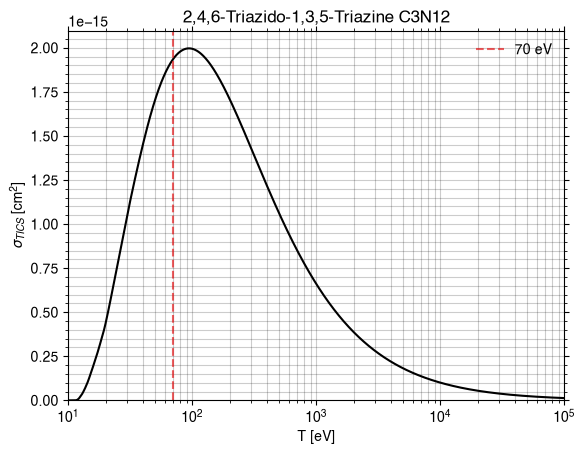

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(9262)
Recherche : '1,3,5-Triazine' -> CID 9262, formule C3H3N3


Loading output/xyz/1_3_5-Triazine_C3H3N3.xyzBuilt graph: 9 atoms, 9 bondsLoading output/xyz/1_3_5-Triazine_C3H3N3.xyzBuilt graph: 9 atoms, 9 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/1_3_5-Triazine_C3H3N3.gifGIF written to output/gif/1_3_5-Triazine_C3H3N3.gif

strucutre 3D
Réussite. Nom: 1,3,5-Triazine, formule: C3H3N3, M: 81.08, nom_marche: 1_3_5-Triazine
PYSCF CONVERGENCE
converged SCF energy = -278.795127359849
**** MO energy ****
MO #1   energy= -15.5908184679214  occ= 2
MO #2   energy= -15.5908073816011  occ= 2
MO #3   energy= -15.5907715203209  occ= 2
MO #4   energy= -11.3444843037844  occ= 2
MO #5   energy= -11.344465021067   occ= 2
MO #6   energy= -11.3444470107634  occ= 2
MO #7   energy= -1.35876449783221  occ= 2
MO #8   energy= -1.21429008113533  occ= 2
MO #9   energy= -1.21426557774554  occ= 2
MO #10  energy= -0.931180956424572 occ= 2
MO #11  energy= -0.9311514602114   occ= 2
MO #12  energy= -0.762119646395854 occ= 2
MO #13  energy= -0.743343329911824 occ= 2
MO #14  energy= -0.613703499955761 occ= 2
MO #15  energy= -0.613657385580344 occ= 2
MO #16  energy= -0.609570433463122 occ= 2
MO #17  energy= -0.581519194306118 occ= 2
MO #18  energy= -0.444482337005087 occ= 2
MO #19  energy= -0.444453364602242 occ= 2
MO #20  energy= -0.439973

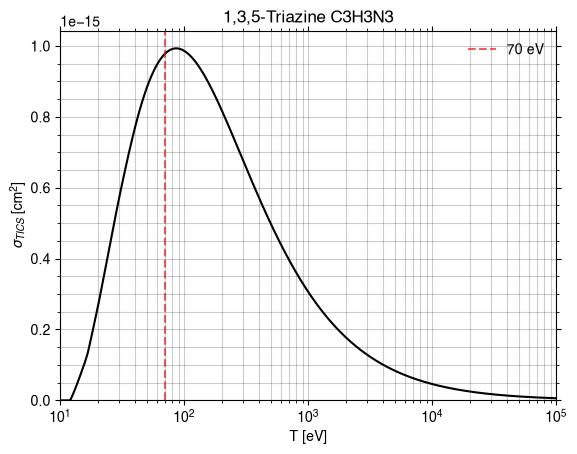

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(24255)
Recherche : '1,3,5-Triazine-2,4,6-tricarbonitrile' -> CID 24255, formule C6N6


Loading output/xyz/1_3_5-Triazine-2_4_6-tricarbonitrile_C6N6.xyzBuilt graph: 12 atoms, 12 bondsLoading output/xyz/1_3_5-Triazine-2_4_6-tricarbonitrile_C6N6.xyzBuilt graph: 12 atoms, 12 bondsRendering rotation GIF (120 frames, axis=y)

3D


  frame 120/120
Wrote output/gif/1_3_5-Triazine-2_4_6-tricarbonitrile_C6N6.gifGIF written to output/gif/1_3_5-Triazine-2_4_6-tricarbonitrile_C6N6.gif

strucutre 3D
Réussite. Nom: 1,3,5-Triazine-2,4,6-tricarbonitrile, formule: C6N6, M: 156.1, nom_marche: 1_3_5-Triazine-2_4_6-tricarbonitrile
PYSCF CONVERGENCE
converged SCF energy = -554.024505983014
**** MO energy ****
MO #1   energy= -15.6769041517043  occ= 2
MO #2   energy= -15.6768926819536  occ= 2
MO #3   energy= -15.6768563829404  occ= 2
MO #4   energy= -15.6471614613839  occ= 2
MO #5   energy= -15.6471450204437  occ= 2
MO #6   energy= -15.6470977054027  occ= 2
MO #7   energy= -11.449912842948   occ= 2
MO #8   energy= -11.4499000777251  occ= 2
MO #9   energy= -11.4498772441572  occ= 2
MO #10  energy= -11.3343476814889  occ= 2
MO #11  energy= -11.3343368033818  occ= 2
MO #12  energy= -11.3342934388271  occ= 2
MO #13  energy= -1.45385521889087  occ= 2
MO #14  energy= -1.31774318562867  occ= 2
MO #15  energy= -1.31770037484756  occ= 2
MO #16  energy= -1.26819542400464  occ= 2
MO #17  energy= -1.2642661287699   occ= 2
MO #18  energy= -1.26423790526911  occ= 2
MO #19  energy= -1.066926

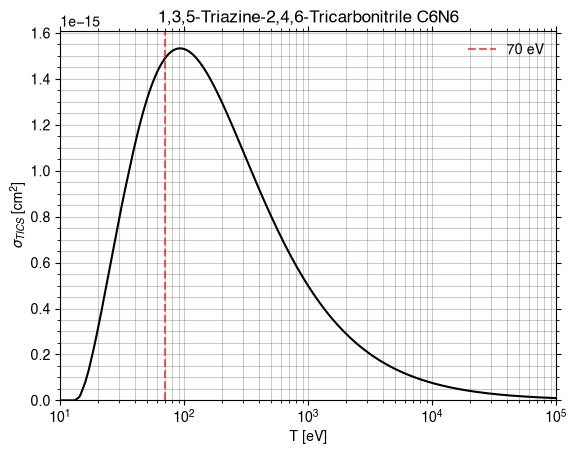

/tmp/ipykernel_31488/2767006862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[f"{nom_marche}_{formula}"] = u


Compound(533)
Recherche : 'Hydrogen selenide' -> CID 533, formule H2Se


geometric-optimize called with the following command line:
/mnt/c/Users/lilian.heydel/.Python-Linux/py-wsl/lib/python3.14/site-packages/ipykernel_launcher.py --f=/home/lilianheydel/.local/share/jupyter/runtime/kernel-v30159350f8af18f9a98d6a147ca45fbb9baca38f5.json

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,))))))).      
                        *%%%%%%,         ***************/.        .)))))))     
                #%%/      (%%%%%%,    /*********************.       )))))))    
              .%%%%%%#      *%%%%%%,  *******/,     **********,      .))))))   
              

2D
[Level 1] Processing SMILES: [SeH2]
[Level 1] Generating 3D conformer...
[Level 1] Checking stereochemistry...
[Level 1] Processing completed. Found 0 bonds needing correction
✓ Stereochemistry matches original SMILES
3
2
ZOUZOZUOZUZOUZOUZOUZOUZOUZOUZOUZOUZOUZUO AOIHOAUHAIOZUGXNU ZZZZZAAAAAAAAAAAA
Réussite. Nom: Hydrogen selenide, formule: H2Se, M: 80.99, nom_marche: Hydrogen_selenide
PYSCF CONVERGENCE

Geometry optimization cycle 1
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Se  -0.001608   0.571098   0.000000    0.000000  0.000000  0.000000
   H   1.275011  -0.285045   0.000000    0.000000  0.000000  0.000000
   H  -1.273403  -0.286053   0.000000    0.000000  0.000000  0.000000

WARN: Mole.unit (angstrom) is changed to Bohr

converged SCF energy = -10.3140187288592
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Se    -0.0008654808     0.0048790191    -0.0000000000
1 H     0

Step    0 : Gradient = 3.290e-02/4.059e-02 (rms/max) Energy = -10.3140187289
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.53304e-01 1.54644e-01 1.60000e-01



Geometry optimization cycle 2
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Se  -0.001060   0.617657  -0.000000    0.000548  0.046559 -0.000000
   H   1.158555  -0.308142   0.000000   -0.116456 -0.023097  0.000000
   H  -1.157494  -0.309515  -0.000000    0.115909 -0.023462 -0.000000
converged SCF energy = -10.3267619998787
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Se    -0.0005049418     0.0036901414     0.0000000000
1 H     0.0204648047    -0.0020325272    -0.0000000000
2 H    -0.0199598629    -0.0016576142    -0.0000000000
----------------------------------------------
cycle 2: E = -10.3267619999  dE = -0.0127433  norm(grad) = 0.0289475


... (6 outputs left out)

Step    4 : Displace = 1.770e-03/2.411e-03 (rms/max) Trust = 2.828e-01 (+) Grad = 1.685e-04/2.348e-04 (rms/max) E (change) = -10.3306536906 (-6.627e-06) Quality = 0.897
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.53926e-01 1.70295e-01 2.45911e-01



Geometry optimization cycle 6
Cartesian coordinates (Angstrom)
 Atom        New coordinates             dX        dY        dZ
  Se  -0.000569   0.662365  -0.000000   -0.000093  0.000611  0.000000
   H   1.050422  -0.330333   0.000000   -0.000632 -0.000336 -0.000000
   H  -1.049853  -0.332032   0.000000    0.000725 -0.000275  0.000000
converged SCF energy = -10.3306538982464
--------------- RHF_Scanner gradients ---------------
         x                y                z
0 Se    -0.0000253121     0.0000038433     0.0000000000
1 H    -0.0000027119    -0.0000138180    -0.0000000000
2 H     0.0000280240     0.0000099746    -0.0000000000
----------------------------------------------
cycle 6: E = -10.3306538982  dE = -2.07604e-07  norm(grad) = 4.16966e-05


Step    5 : Displace = 7.063e-04/7.689e-04 (rms/max) Trust = 3.000e-01 (+) Grad = 2.407e-05/2.975e-05 (rms/max) E (change) = -10.3306538982 (-2.076e-07) Quality = 0.887
Hessian Eigenvalues: 5.00000e-02 5.00000e-02 5.00000e-02 ... 1.53926e-01 1.70295e-01 2.45911e-01
Converged! =D

    #==========================================================================#
    #| If this code has benefited your research, please support us by citing: |#
    #|                                                                        |#
    #| Wang, L.-P.; Song, C.C. (2016) "Geometry optimization made simple with |#
    #| translation and rotation coordinates", J. Chem, Phys. 144, 214108.     |#
    #| http://dx.doi.org/10.1063/1.4952956                                    |#
    #==========================================================================#
    Time elapsed since start of run_optimizer: 19.242 seconds
  frame 120/120xyz/Hydrogen_selenide_H2Se.xyzBuilt graph: 3 atoms, 2 bondsLoading output/x

converged SCF energy = -10.3306538982638
**** MO energy ****
MO #1   energy= -0.947831051668277 occ= 2
MO #2   energy= -0.561990379311746 occ= 2
MO #3   energy= -0.477338074495793 occ= 2
MO #4   energy= -0.359425022103125 occ= 2
MO #5   energy= 0.0601089436756268 occ= 0
MO #6   energy= 0.0660868254598004 occ= 0
MO #7   energy= 0.0719654696897388 occ= 0
MO #8   energy= 0.0729331150973832 occ= 0
MO #9   energy= 0.120914213745722  occ= 0
MO #10  energy= 0.183495820707148  occ= 0
MO #11  energy= 0.20405042865438   occ= 0
MO #12  energy= 0.214628305023915  occ= 0
MO #13  energy= 0.21841855599887   occ= 0
MO #14  energy= 0.227899055710639  occ= 0
MO #15  energy= 0.290255193337551  occ= 0
MO #16  energy= 0.309061401924907  occ= 0
MO #17  energy= 0.323327555710927  occ= 0
MO #18  energy= 0.329914492442448  occ= 0
MO #19  energy= 0.343289953466121  occ= 0
MO #20  energy= 0.348240638927248  occ= 0
MO #21  energy= 0.359538682442939  occ= 0
MO #22  energy= 0.360261732613032  occ= 0
MO #23  energy=

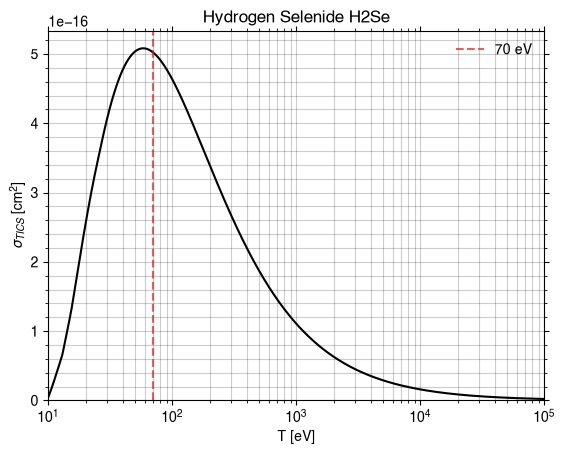

In [7]:
T=np.logspace(1,5,int(1e3), endpoint=True)
dataset = pd.DataFrame({"T" : T})
metadata_list = []


# zezeze = ['digermane', 'disilane'] #, 'Methane', 'Digermane', 'Ethane']
    
for d in ["output/csv", "output/csv/sigma", "output/csv/metadata", "output/xyz",
          "output/gif", "sigma", "metadata", "tmp"]:
    os.makedirs(d, exist_ok=True)
# elements = ["2-methylpentane"]
for pp in elements:
    try:
        t_start = time.perf_counter()
        mol_beb = pd.DataFrame({"T" : T})
        nom_marche, name, formula, smile = download_xyz(pp)

        t0 = time.perf_counter()
        a, b = kernel_mf('temp.xyz', nom_marche, formula)
        y = orbital_car(a, b)
        t_hf = time.perf_counter() - t0

        t0 = time.perf_counter()
        # mol_cube = load("temp.cube") 
        u = BEB(y, T)
        t_beb = time.perf_counter() - t0

        # render(mol_cube, config="flat", esp="temp_esp.cube", cbar = True, cmap_palette='coolwarm' ,transparent=True, hy=True, output=f"output3/svg/{name}_{formula}.svg")
        
        plot_sigma(u, T, name, nom_marche, formula)
        # render_gif('temp.xyz',hy=True, dof=True, atom_stroke_width=.2,orient=False, gif_rot="y", output=f"output/gif/{nom_marche}_{formula}.gif")
        t_total = time.perf_counter() - t_start


        metadata_list.append({
            "name_formula": f"{nom_marche}_{formula}",
            "complete_name": name.title(),  # Correction ici pour la majuscule
            "formula": formula,
            "SMILES": smile,
            "svg_file": f"{nom_marche}_{formula}.svg",
            "pdf_file": f"{nom_marche}_{formula}.pdf",
            "csv_meta_file":f"metadata/{nom_marche}_{formula}.csv",
            "csv_data_file":f"sigma/{nom_marche}_{formula}.csv",
            "converged": bool(a.converged),
            "nao": b.nao,
            "spin": b.spin,
            "pyscf": pyscf.__version__,
            "time_hf_s": round(t_hf, 1),
            "time_beb_s": round(t_beb, 3),
            "time_total_s": round(t_total, 1),
            "is2D_geom": flag_to_optimize
        })
        dataset[f"{nom_marche}_{formula}"] = u
        mol_beb["sigma"] = u
        y.to_csv(f"output/csv/metadata/{nom_marche}_{formula}.csv", index=False, sep = ";")
        mol_beb.to_csv(f"output/csv/sigma/{nom_marche}_{formula}.csv", index=False, sep = ";")
    except Exception as e:
        print(f"{pp} a échoué : {type(e).__name__} : {e}")
        continue
        
# Création du DataFrame global des métadonnées après la boucle
liste_all = pd.DataFrame(metadata_list)
    
dataset.to_csv("output/csv/dataset.csv", index=False, sep = ";")
liste_all.to_csv("output/csv/liste_all.csv", index=False, sep = ";")
